# DataTrust — exploración 

Este notebook **tampoco forma parte de la serie numerada 01-06**. Para cada
columna, se recalculan con código real los números que respaldan la
interpretación (percentiles, conteos); cuando hace falta cruzar dos
columnas, se genera un gráfico nuevo con código, pensado específicamente
para ese cruce.

Se avanza de forma incremental, tabla por tabla, columna por columna —
empezando por `listings`.


## Tabla `listings`

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from graficos_utils import graficar_numerica, graficar_categorica, graficar_fecha

listings = pd.read_csv("../data/airbnb_bcn/listings.csv", low_memory=False)
print(listings.shape)

CARPETA_LISTINGS = "../graficos_exploracion/listings"

(15293, 90)


### `accommodates`

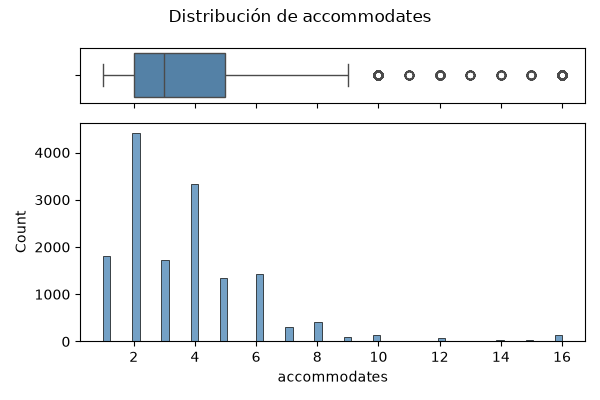

Q1=2.0  mediana=3.0  Q3=5.0  limite superior atipicos=9.5

accommodates
1     1806
2     4413
3     1724
4     3329
5     1343
6     1422
7      299
8      416
9      101
10     131
Name: count, dtype: int64

media=3.69  moda=2


In [2]:
ruta = graficar_numerica(listings["accommodates"], "accommodates", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["accommodates"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print()
print(s.value_counts().sort_index().head(10))
print()
print(f"media={s.mean():.2f}  moda={s.mode().iloc[0]}")

Percentiles: 25% = 2, mediana = 3, 75% = 5. Atípicos (boxplot): a partir de
10 personas (límite = Q3 + 1,5×IQR = 9,5).

Los números pares (2, 4, 6) son más frecuentes que sus vecinos impares — ej.
2 personas (4.413 anuncios) frente a 1 (1.806) y 3 (1.724) — coherente con
combinaciones de camas dobles.

Media (3,69) > mediana (3,0): cola larga hacia valores altos. Moda = 2.

`accommodates` es independiente del tipo de alojamiento: `accommodates = 2`
aparece en los 4 `room_type` (2.228 Entire home/apt, 2.140 Private room, 33
Hotel room, 12 Shared room).

### Cruce: `accommodates` según `room_type`

,Mediana,Media,n,%
room_type,,,,
Entire home/apt,4.0,4.44,10844,70.9
Private room,2.0,1.82,4262,27.9
Shared room,1.0,2.50,119,0.8
Hotel room,2.0,2.72,68,0.4


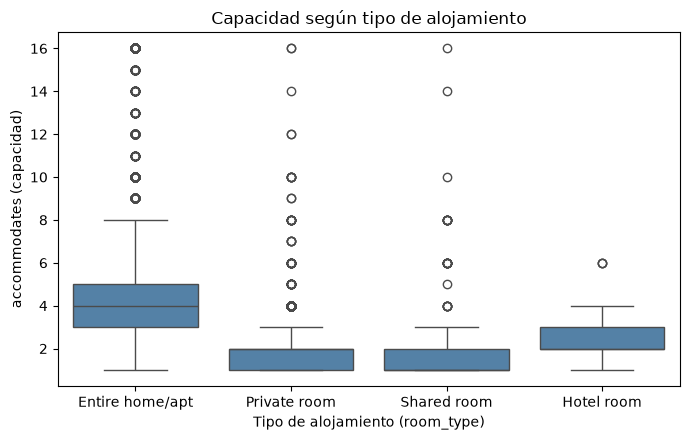

In [3]:
tabla_cruce = listings.groupby("room_type")["accommodates"].agg(
    Mediana="median", Media="mean", n="count"
).sort_values("n", ascending=False)
tabla_cruce["%"] = (tabla_cruce["n"] / tabla_cruce["n"].sum() * 100).round(1)
display(tabla_cruce.round(2))

orden = tabla_cruce.index
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=listings, x="room_type", y="accommodates", order=orden, color="steelblue", ax=ax)
ax.set_xlabel("Tipo de alojamiento (room_type)")
ax.set_ylabel("accommodates (capacidad)")
ax.set_title("Capacidad según tipo de alojamiento")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/accommodates_por_room_type.png")
plt.show()

`Shared room` tiene la mediana más baja de las 4 (1, ni siquiera 2) —
cada anuncio de habitación compartida se pública por plaza individual, no
por el grupo que cabe en la habitación.

### `tipo_anfitrion` (particular vs. profesional)

Antes de los cruces con `accommodates` y distrito: distribución general de `host_profesional` (`calculated_host_listings_count > 50`), la clasificación propia del proyecto, no una columna del dataset.

tipo_anfitrion
Particular     11728
Profesional     3565
Name: count, dtype: int64
tipo_anfitrion
Particular     76.7
Profesional    23.3
Name: proportion, dtype: float64


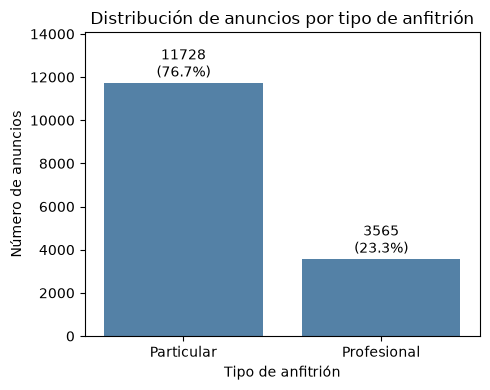

In [4]:
listings["host_profesional"] = listings["calculated_host_listings_count"] > 50
listings["tipo_anfitrion"] = listings["host_profesional"].map({False: "Particular", True: "Profesional"})

conteo = listings["tipo_anfitrion"].value_counts()
pct = listings["tipo_anfitrion"].value_counts(normalize=True) * 100
print(conteo)
print(pct.round(1))

orden = ["Particular", "Profesional"]
conteo_ord = conteo.reindex(orden)
pct_ord = pct.reindex(orden)

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=orden, y=conteo_ord.values, order=orden, color="steelblue", ax=ax)
ax.set_ylim(0, conteo_ord.max() * 1.2)
for i, (v, p) in enumerate(zip(conteo_ord.values, pct_ord.values)):
    ax.text(i, v + 300, f"{v}\n({p:.1f}%)", ha="center")
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("Número de anuncios")
ax.set_title("Distribución de anuncios por tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/tipo_anfitrion_distribucion.png", dpi=100)
plt.show()

11.728 anuncios (76,7%) son de particulares y 3.565 (23,3%) de profesionales, sobre los 15.293 anuncios totales. A nivel de cuenta de anfitrión la diferencia es aún mayor: solo 22 cuentas profesionales gestionan esos 3.565 anuncios, frente a 4.573 cuentas particulares.

### Cruce: `accommodates` según `host_profesional`

`host_profesional` no es una columna del dataset: se construye en el notebook 01 como `calculated_host_listings_count > 50` (más de 50 anuncios en Barcelona). Se recalcula aquí solo para este cruce.

,Mediana,Media,n,%
tipo_anfitrion,,,,
Particular,3.0,3.52,11728,76.7
Profesional,4.0,4.24,3565,23.3


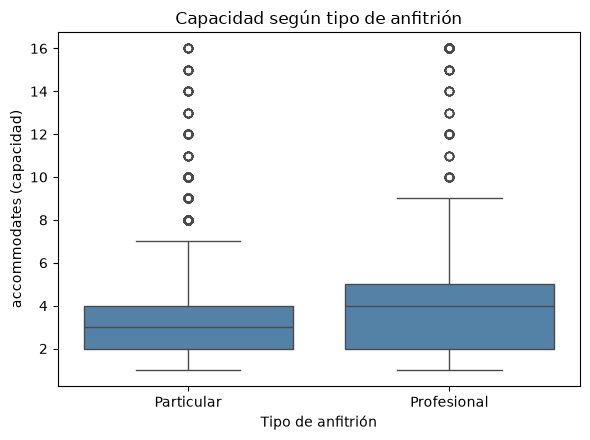

In [5]:
listings["host_profesional"] = listings["calculated_host_listings_count"] > 50
listings["tipo_anfitrion"] = listings["host_profesional"].map({False: "Particular", True: "Profesional"})

tabla_cruce = listings.groupby("tipo_anfitrion")["accommodates"].agg(
    Mediana="median", Media="mean", n="count"
)
tabla_cruce["%"] = (tabla_cruce["n"] / tabla_cruce["n"].sum() * 100).round(1)
display(tabla_cruce.round(2))

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=listings, x="tipo_anfitrion", y="accommodates", order=["Particular", "Profesional"], color="steelblue", ax=ax)
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("accommodates (capacidad)")
ax.set_title("Capacidad según tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/accommodates_host_profesional.png", dpi=100)
plt.show()

Los anfitriones profesionales gestionan anuncios con una capacidad algo mayor: mediana 4 frente a 3 en particulares (media 4,24 frente a 3,52).

En volumen, los grupos no están parejos: 11.728 anuncios son de particulares (76,7%) frente a 3.565 de profesionales (23,3%). La diferencia de capacidad se sostiene pese a que el grupo profesional es mucho más pequeño en número de anuncios — consistente con el patrón ya visto de `host_profesional` en licencias e ingresos: es el mismo tipo de gestión a mayor escala, con alojamientos ligeramente más grandes.

### Cruce: `accommodates` según distrito (`neighbourhood_group_cleansed`)

,Mediana,Media,n,%
neighbourhood_group_cleansed,,,,
Eixample,4.0,4.22,5835,38.2
Sant Martí,4.0,3.61,1436,9.4
Sarrià-Sant Gervasi,3.0,3.36,888,5.8
Gràcia,3.0,3.47,1366,8.9
Les Corts,3.0,3.51,327,2.1
Horta-Guinardó,3.0,3.30,358,2.3
Sants-Montjuïc,3.0,3.63,1448,9.5
Ciutat Vella,2.0,3.15,3247,21.2
Nou Barris,2.0,2.75,163,1.1


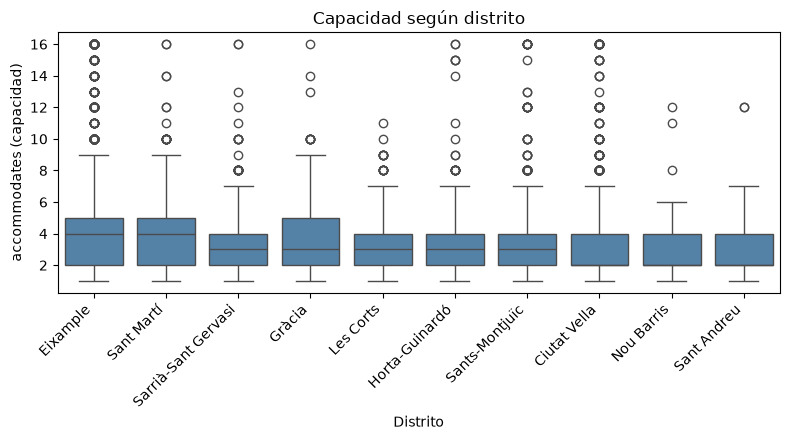

In [6]:
tabla_cruce = listings.groupby("neighbourhood_group_cleansed")["accommodates"].agg(
    Mediana="median", Media="mean", n="count"
).sort_values("Mediana", ascending=False)
tabla_cruce["%"] = (tabla_cruce["n"] / tabla_cruce["n"].sum() * 100).round(1)
display(tabla_cruce.round(2))

orden = tabla_cruce.index
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=listings, x="neighbourhood_group_cleansed", y="accommodates", order=orden, color="steelblue", ax=ax)
ax.set_xlabel("Distrito")
ax.set_ylabel("accommodates (capacidad)")
ax.set_title("Capacidad según distrito")
plt.xticks(rotation=45, ha="right")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/accommodates_distrito.png", dpi=100)
plt.show()

Eixample y Sant Martí tienen la mediana más alta (4), mientras que Ciutat Vella, Nou Barris y Sant Andreu tienen la más baja (2). Ciutat Vella es un caso llamativo: pese a tener la segunda mayor cantidad de anuncios (3.247, 21,2%), su mediana de capacidad es de solo 2 personas — probablemente por el tamaño reducido de los pisos históricos del casco antiguo. Su media (3,15) sí queda por encima de la mediana, señal de que conviven muchos pisos pequeños con algunos anuncios de mayor capacidad.

### Cruce: tipo de anfitrión según distrito

Qué porcentaje de particulares y profesionales hay dentro de cada distrito (`neighbourhood_group_cleansed`). Usa `tipo_anfitrion`, ya creado en el cruce anterior.

tipo_anfitrion,Particular,Profesional,n_total
neighbourhood_group_cleansed,,,
Sarrià-Sant Gervasi,61.3,38.7,888
Nou Barris,64.4,35.6,163
Eixample,71.1,28.9,5835
Gràcia,78.3,21.7,1366
Sants-Montjuïc,80.6,19.4,1448
Horta-Guinardó,81.3,18.7,358
Sant Andreu,82.2,17.8,225
Ciutat Vella,83.1,16.9,3247
Les Corts,83.2,16.8,327


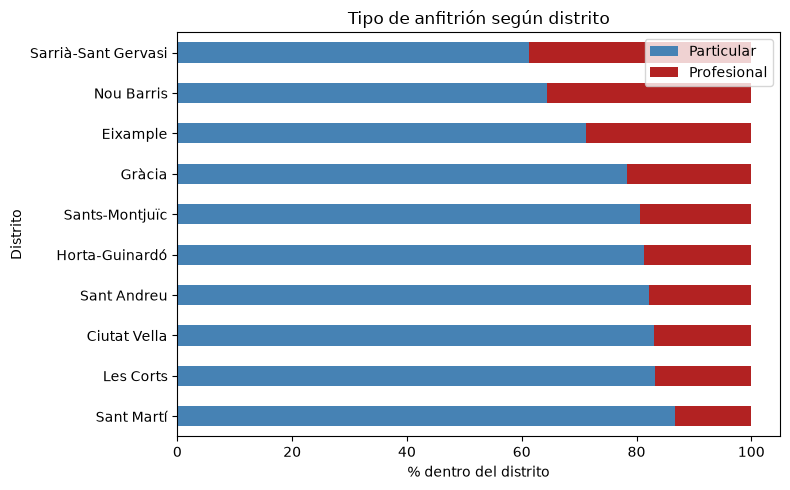

In [7]:
tabla_pct = pd.crosstab(listings["neighbourhood_group_cleansed"], listings["tipo_anfitrion"], normalize="index") * 100
tabla_n = pd.crosstab(listings["neighbourhood_group_cleansed"], listings["tipo_anfitrion"])
tabla_pct["n_total"] = tabla_n.sum(axis=1)
tabla_pct = tabla_pct.sort_values("Profesional", ascending=False)
display(tabla_pct.round(1))

orden = tabla_pct.index
fig, ax = plt.subplots(figsize=(8, 5))
tabla_pct.loc[orden, ["Particular", "Profesional"]].plot(
    kind="barh", stacked=True, ax=ax, color=["steelblue", "firebrick"]
)
ax.set_xlabel("% dentro del distrito")
ax.set_ylabel("Distrito")
ax.set_title("Tipo de anfitrión según distrito")
ax.invert_yaxis()
ax.legend(title="")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/distrito_tipo_anfitrion.png", dpi=100)
plt.show()

En **todos** los distritos predominan los particulares, pero la proporción de profesionales varía bastante: va del 13,2% en Sant Martí al 38,7% en Sarrià-Sant Gervasi.

Eixample, el distrito con más anuncios (5.835, 38,2% del total), tiene un 28,9% de profesionales — por encima de la media general del dataset (23,3%). Sarrià-Sant Gervasi es el distrito con mayor proporción profesional (38,7%), aunque con bastantes menos anuncios (888). Nou Barris aparece segundo (35,6%), pero con una base muy pequeña (163 anuncios), así que ese porcentaje puede ser poco estable — conviene no sacar conclusiones fuertes de él.

Ciutat Vella, pese a ser el centro turístico histórico y el segundo distrito con más anuncios, tiene una de las proporciones de profesionales más bajas (16,9%): mayoritariamente anfitriones particulares.

### `amenities`

No se usa `graficar_categorica` aquí: esta columna tiene listas completas de texto como valores (algunas de más de 300 caracteres), no hay forma de mostrarlo legible como etiqueta de eje. Se numeran las barras y se muestra el texto completo de cada una en una tabla aparte.

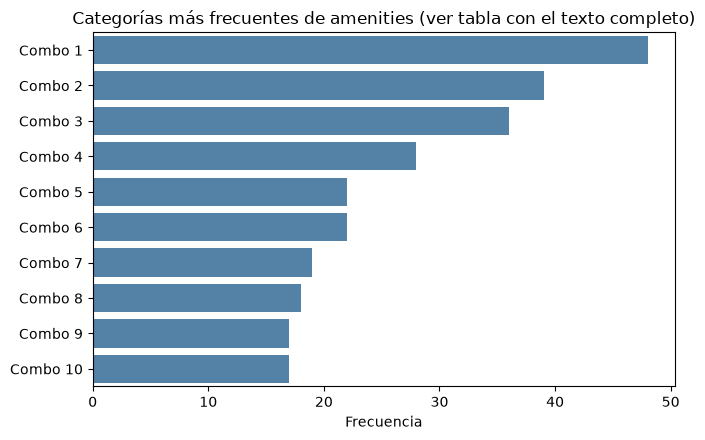

valores distintos: 13161 de 15293



,Combo,Frecuencia,Contenido completo
0,Combo 1,48,"[""Wifi"", ""Air conditioning"", ""Kitchen"", ""TV"", ""Washer""]"
1,Combo 2,39,"[""Wifi"", ""Kitchen"", ""TV"", ""Dedicated workspace"", ""Washer""]"
2,Combo 3,36,"[""Wifi"", ""Air conditioning"", ""Kitchen"", ""TV"", ""Dedicated workspace"", ""Washer""]"
3,Combo 4,28,"[""Kitchen"", ""Wifi""]"
4,Combo 5,22,"[""Hot water kettle"", ""Freezer"", ""Oven"", ""Crib"", ""Dishes and silverware"", ""Paid parking off premises"", ""Heating"", ""Stove"", ""Dining table"", ""Bed linens"", ""Hangers"", ""Dishwasher"", ""Kitchen"", ""Hair dryer"", ""TV"", ""Toaster"", ""Dedicated workspace"", ""Microwave"", ""Elevator"", ""Drying rack for clothing"", ""Clothing storage"", ""Wifi"", ""Pack \u2019n play/Travel crib"", ""Coffee maker"", ""Luggage dropoff allowed"", ""Wine glasses"", ""Cooking basics"", ""Hot water"", ""Washer"", ""Long term stays allowed"", ""Refrigerator"", ""Air conditioning"", ""High chair"", ""Cleaning products"", ""Iron"", ""Safe"", ""Essentials"", ""Extra pillows and blankets""]"
5,Combo 6,22,"[""Kitchen"", ""Wifi"", ""TV"", ""Washer""]"
6,Combo 7,19,"[""Freezer"", ""Oven"", ""Crib"", ""Dishes and silverware"", ""Paid parking off premises"", ""Heating"", ""Stove"", ""Dining table"", ""Bed linens"", ""Hangers"", ""Kitchen"", ""Hair dryer"", ""TV"", ""Toaster"", ""Dedicated workspace"", ""Microwave"", ""Elevator"", ""Drying rack for clothing"", ""Clothing storage"", ""Wifi"", ""Pack \u2019n play/Travel crib"", ""Coffee maker"", ""Luggage dropoff allowed"", ""Wine glasses"", ""Cooking basics"", ""Hot water"", ""Washer"", ""Long term stays allowed"", ""Refrigerator"", ""Air conditioning"", ""High chair"", ""Cleaning products"", ""Iron"", ""Essentials"", ""Extra pillows and blankets""]"
7,Combo 8,18,[]
8,Combo 9,17,"[""Wifi"", ""Air conditioning"", ""Kitchen"", ""TV"", ""Dedicated workspace"", ""Hot water"", ""Washer"", ""Heating""]"
9,Combo 10,17,"[""Stove"", ""Refrigerator"", ""Bed linens"", ""Air conditioning"", ""Wifi"", ""Elevator"", ""Kitchen"", ""TV"", ""Oven"", ""Essentials"", ""Hot water"", ""Washer"", ""Heating""]"


In [8]:
conteo = listings["amenities"].value_counts().head(10)
etiquetas_numeradas = [f"Combo {i+1}" for i in range(len(conteo))]

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=conteo.values, y=etiquetas_numeradas, color="steelblue", ax=ax)
ax.set_xlabel("Frecuencia")
ax.set_ylabel("")
ax.set_title("Categorías más frecuentes de amenities (ver tabla con el texto completo)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/listings/amenities_categorica.png", dpi=100)
plt.show()

print("valores distintos:", listings["amenities"].nunique(), "de", len(listings))
print()

tabla_combos = pd.DataFrame({
    "Combo": etiquetas_numeradas,
    "Frecuencia": conteo.values,
    "Contenido completo": conteo.index,
})
pd.set_option("display.max_colwidth", None)
display(tabla_combos)

El gráfico base no es muy útil por sí solo: 13.161 combinaciones de texto distintas de 15.293 anuncios — casi todas únicas. Cada barra es una lista completa de amenities como texto (no una sola comodidad), así que las barras numeradas ("Combo 1", "Combo 2"...) se explican con la tabla de debajo, que tiene el contenido completo de cada una.

### Extra: amenities individuales más comunes

Se desenrolla cada lista en amenities individuales y se cuenta cada una por separado.

menciones individuales totales:

 436833


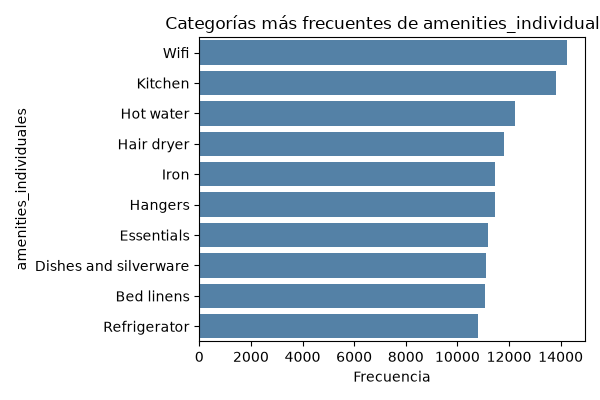

In [9]:
listas = listings["amenities"].apply(lambda v: json.loads(v) if pd.notna(v) else [])
amenities_individuales = pd.Series([item for lista in listas for item in lista])
print("menciones individuales totales:", len(amenities_individuales))

ruta = graficar_categorica(amenities_individuales, "amenities_individuales", "../graficos_exploracion/cruces")
display(Image(ruta))

Top 3: Wifi (14.232 anuncios), Kitchen (13.839), Hot water (12.244) — sobre
15.293 alojamientos totales, así que Wifi está en el 93,1% de los anuncios.

### `availability_30`

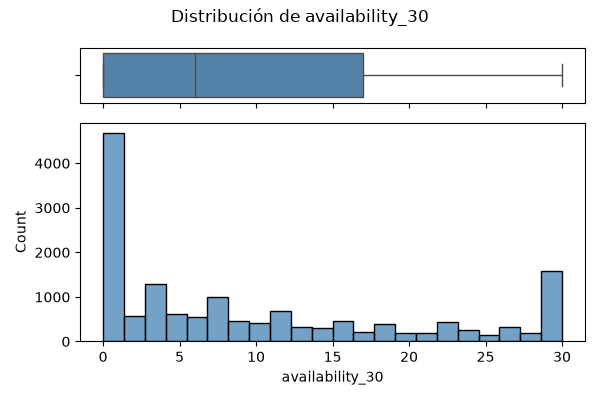

Q1=0.0  mediana=6.0  Q3=17.0  limite superior atipicos=42.5
nulos=0
con 0 dias disponibles=4114 (26.9%)
con 30 dias disponibles=1176 (7.7%)


In [10]:
ruta = graficar_numerica(listings["availability_30"], "availability_30", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["availability_30"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()}")
print(f"con 0 días disponibles={(s==0).sum()} ({(s==0).mean()*100:.1f}%)")
print(f"con 30 días disponibles={(s==30).sum()} ({(s==30).mean()*100:.1f}%)")

Percentiles: 25% = 0, mediana = 6, 75% = 17. Sin atípicos (el valor máximo
posible es 30, por debajo del límite calculado de 42,5).

26,9% de los anuncios tienen 0 días disponibles en el próximo mes (4.114
anuncios); 7,7% tienen los 30 días completos libres (1.176).

Los anuncios con `minimum_nights >= 28` tienen mucha menos disponibilidad
a 30 días: mediana de 2 días libres (vs. 8 en el resto) y 45,6% con 0 días
libres (vs. 15,8%). Es mecánico: una reserva de 28+ noches ocupa casi todo
el mes, no indica más o menos demanda real.

In [11]:
largas = listings[listings["minimum_nights"] >= 28]["availability_30"]
cortas = listings[listings["minimum_nights"] < 28]["availability_30"]

print(f"minimum_nights >= 28 (n={len(largas)}): mediana={largas.median()}, con 0 días libres={(largas==0).mean()*100:.1f}%")
print(f"minimum_nights < 28  (n={len(cortas)}): mediana={cortas.median()}, con 0 días libres={(cortas==0).mean()*100:.1f}%")

minimum_nights >= 28 (n=5702): mediana=2.0, con 0 dias libres=45.6%
minimum_nights < 28  (n=9590): mediana=8.0, con 0 dias libres=15.8%


### `availability_60`

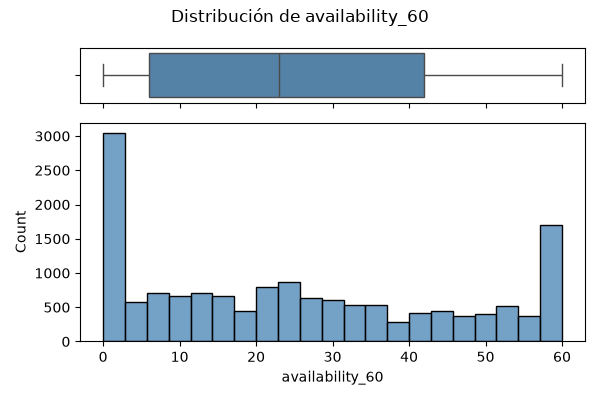

Q1=6.0  mediana=23.0  Q3=42.0  limite superior atipicos=96.0
nulos=0
con 0 dias libres=2673 (17.5%)
con 60 dias libres=1133 (7.4%)
minimum_nights >= 28: mediana=23.0, con 0 dias libres=25.7%
minimum_nights < 28:  mediana=23.0, con 0 dias libres=12.6%


In [12]:
ruta = graficar_numerica(listings["availability_60"], "availability_60", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["availability_60"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()}")
print(f"con 0 días libres={(s==0).sum()} ({(s==0).mean()*100:.1f}%)")
print(f"con 60 días libres={(s==60).sum()} ({(s==60).mean()*100:.1f}%)")

largas = listings[listings["minimum_nights"] >= 28]["availability_60"]
cortas = listings[listings["minimum_nights"] < 28]["availability_60"]
print(f"minimum_nights >= 28: mediana={largas.median()}, con 0 días libres={(largas==0).mean()*100:.1f}%")
print(f"minimum_nights < 28:  mediana={cortas.median()}, con 0 días libres={(cortas==0).mean()*100:.1f}%")

Percentiles: 25% = 6, mediana = 23, 75% = 42. Sin atípicos (máximo posible
60, por debajo del límite calculado de 96). 17,5% con 0 días libres
(2.673); 7,4% con los 60 días completos libres (1.133).

El efecto de `minimum_nights >= 28` que se veía fuerte en `availability_30`
se debilita aquí: la mediana ya es igual (23 en ambos grupos), aunque el
porcentaje con 0 días libres sigue siendo mayor (25,7% vs. 12,6%). Con una
ventana más larga, incluso un alojamiento de estancias largas tiene más
margen para mostrar algo de disponibilidad.

### `availability_90`

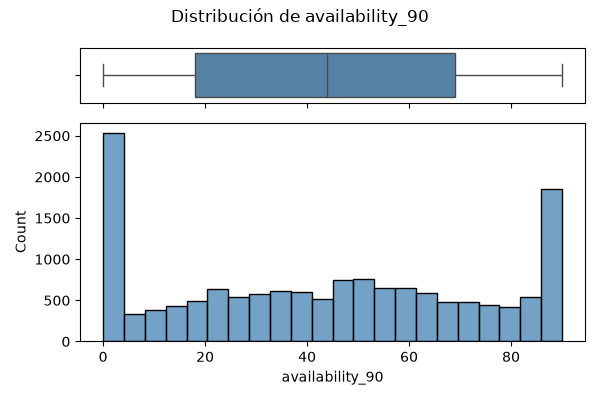

Q1=18.0  mediana=44.0  Q3=69.0  limite superior atipicos=145.5
nulos=0
con 0 dias libres=2241 (14.7%)
con 90 dias libres=1101 (7.2%)
minimum_nights >= 28: mediana=45.0, con 0 dias libres=19.2%
minimum_nights < 28:  mediana=44.0, con 0 dias libres=12.0%


In [13]:
ruta = graficar_numerica(listings["availability_90"], "availability_90", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["availability_90"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()}")
print(f"con 0 días libres={(s==0).sum()} ({(s==0).mean()*100:.1f}%)")
print(f"con 90 días libres={(s==90).sum()} ({(s==90).mean()*100:.1f}%)")

largas = listings[listings["minimum_nights"] >= 28]["availability_90"]
cortas = listings[listings["minimum_nights"] < 28]["availability_90"]
print(f"minimum_nights >= 28: mediana={largas.median()}, con 0 días libres={(largas==0).mean()*100:.1f}%")
print(f"minimum_nights < 28:  mediana={cortas.median()}, con 0 días libres={(cortas==0).mean()*100:.1f}%")

Percentiles: 25% = 18, mediana = 44, 75% = 69. Sin atípicos (máximo posible
90, por debajo del límite calculado de 145,5). 14,7% con 0 días libres
(2.241); 7,2% con los 90 días completos libres (1.101).

El efecto de `minimum_nights >= 28` sigue diluido: medianas casi iguales
(45 vs. 44), aunque el porcentaje con 0 días libres se mantiene más alto
(19,2% vs. 12,0%).

### `availability_365`

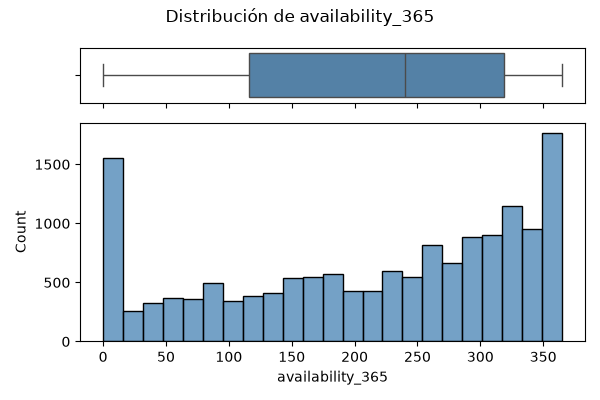

Q1=116.0  mediana=240.0  Q3=319.0  limite superior atipicos=623.5
nulos=0
con 0 dias libres=1389 (9.1%)
con 365 dias libres=841 (5.5%)
minimum_nights >= 28: mediana=246.0, con 0 dias libres=6.4%
minimum_nights < 28:  mediana=236.0, con 0 dias libres=10.7%


In [14]:
ruta = graficar_numerica(listings["availability_365"], "availability_365", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["availability_365"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()}")
print(f"con 0 días libres={(s==0).sum()} ({(s==0).mean()*100:.1f}%)")
print(f"con 365 días libres={(s==365).sum()} ({(s==365).mean()*100:.1f}%)")

largas = listings[listings["minimum_nights"] >= 28]["availability_365"]
cortas = listings[listings["minimum_nights"] < 28]["availability_365"]
print(f"minimum_nights >= 28: mediana={largas.median()}, con 0 días libres={(largas==0).mean()*100:.1f}%")
print(f"minimum_nights < 28:  mediana={cortas.median()}, con 0 días libres={(cortas==0).mean()*100:.1f}%")

Percentiles: 25% = 116, mediana = 240, 75% = 319. Sin atípicos (máximo
posible 365, por debajo del límite calculado de 623,5). 9,1% con 0 días
libres (1.389); 5,5% con los 365 días completos libres (841).

El patrón de `minimum_nights >= 28` se invierte por completo frente a 30
días: aquí tienen mediana más alta (246 vs. 236) y menos 0% (6,4% vs.
10,7%) que el resto. Progresión completa en las 4 ventanas:

| Ventana | minimum_nights >= 28 (mediana) | minimum_nights < 28 (mediana) |
|---|---|---|
| 30 días | 2 | 8 |
| 60 días | 23 | 23 |
| 90 días | 45 | 44 |
| 365 días | 246 | 236 |

A corto plazo, una sola reserva larga ocupa casi todo el calendario de 30
días; a un año vista, ese mismo efecto se diluye y hasta se invierte.

In [15]:
listings.groupby("room_type")["availability_365"].agg(["median","mean","count"])

,median,mean,count
room_type,,,
Entire home/apt,252.0,227.186739,10844
Hotel room,180.0,191.529412,68
Private room,180.0,174.692163,4262
Shared room,277.0,231.873950,119


### Cruce: `availability_365` según tipo de anfitrión

Posible explicación del hallazgo de ingresos: si los profesionales tienen más días sin reservar, eso bajaría su `estimated_revenue_l365d` aunque su precio sea similar o menor.

,Mediana,Media,n
tipo_anfitrion,,,
Particular,202.0,192.36,11728
Profesional,301.0,278.49,3565


Mismo cruce en las otras ventanas de disponibilidad:
availability_30
                Mediana  Media
tipo_anfitrion                
Particular          6.0   9.19
Profesional         8.0  12.31

availability_60
                Mediana  Media
tipo_anfitrion                
Particular         21.0   23.7
Profesional        28.0   30.6

availability_90
                Mediana  Media
tipo_anfitrion                
Particular         40.0  40.88
Profesional        54.0  52.29



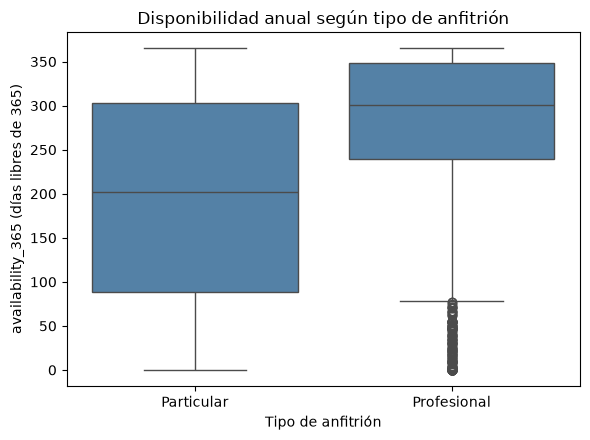

In [16]:
tabla_cruce = listings.groupby("tipo_anfitrion")["availability_365"].agg(
    Mediana="median", Media="mean", n="count"
)
display(tabla_cruce.round(2))

print("Mismo cruce en las otras ventanas de disponibilidad:")
for col in ["availability_30", "availability_60", "availability_90"]:
    print(col)
    print(listings.groupby("tipo_anfitrion")[col].agg(Mediana="median", Media="mean").round(2))
    print()

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=listings, x="tipo_anfitrion", y="availability_365", order=["Particular", "Profesional"], color="steelblue", ax=ax)
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("availability_365 (días libres de 365)")
ax.set_title("Disponibilidad anual según tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/availability_365_tipo_anfitrion.png", dpi=100)
plt.show()

Los profesionales tienen **más días libres (menos ocupación)** en las 4 ventanas, sin excepción: en `availability_365`, mediana de 301 días libres frente a 202 en particulares (de 365 posibles) — casi 100 días más sin reservar al año.

Esto encaja con el patrón ya visto: precio similar o algo más bajo + mucha más disponibilidad libre (menos ocupación) = ingreso anual más bajo. No es que cobren menos por noche, es que venden menos noches. Es consistente con lo visto en `price` (precio parecido) y `estimated_revenue_l365d` (ingreso menor): la pieza que faltaba era la ocupación real, y `availability_365` la confirma directamente.

### Cruce: `host_is_superhost` según tipo de anfitrión

Otra posible pieza para explicar la baja ocupación de los profesionales: el estatus de superhost afecta la visibilidad en el buscador de Airbnb.

host_is_superhost,f,t
tipo_anfitrion,,
Particular,67.0,33.0
Profesional,97.5,2.5


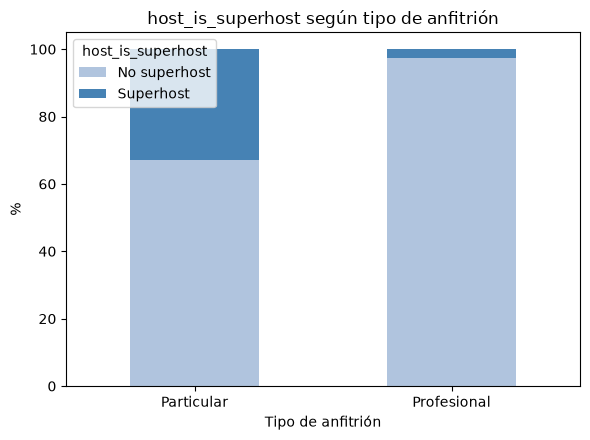

In [17]:
tabla_cruce = pd.crosstab(listings["tipo_anfitrion"], listings["host_is_superhost"], normalize="index") * 100
display(tabla_cruce.round(1))

fig, ax = plt.subplots(figsize=(6, 4.5))
tabla_cruce.rename(columns={"t": "Superhost", "f": "No superhost"}).plot(kind="bar", stacked=True, ax=ax, color=["lightsteelblue", "steelblue"])
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("%")
ax.set_title("host_is_superhost según tipo de anfitrión")
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/superhost_tipo_anfitrion.png", dpi=100)
plt.show()

Brecha grande: 33,0% de los particulares son superhost, frente a solo **2,5%** de los profesionales. El estatus de superhost (que exige buena valoración, respuesta rápida y pocas cancelaciones) le da más visibilidad en el buscador de Airbnb — con una tasa tan baja, los profesionales parten con desventaja estructural en ese aspecto, algo que también encaja con sus peores puntuaciones ya vistas en `review_scores_*`.

### Cruce: `minimum_nights` según tipo de anfitrión, controlando por `room_type`

Antes de concluir nada, se revisa si la diferencia general en `minimum_nights` es solo porque los profesionales tienen más `Entire home/apt` (que ya de por sí pide estancias más largas).

Mediana de minimum_nights por room_type, en general (sin separar por anfitrion):
room_type
Entire home/apt    2.0
Hotel room         1.0
Private room       3.0
Shared room        1.0
Name: minimum_nights, dtype: float64



Mediana  Media     n
room_type       tipo_anfitrion                      
Entire home/apt Particular          2.0  13.21  7992
                Profesional         2.0  14.16  2851
Hotel room      Particular          1.0   1.03    63
                Profesional         1.0   1.00     5
Private room    Particular          2.0  12.91  3559
                Profesional        32.0  32.04   703
Shared room     Particular          1.0   2.93   114
                Profesional        32.0  37.60     5

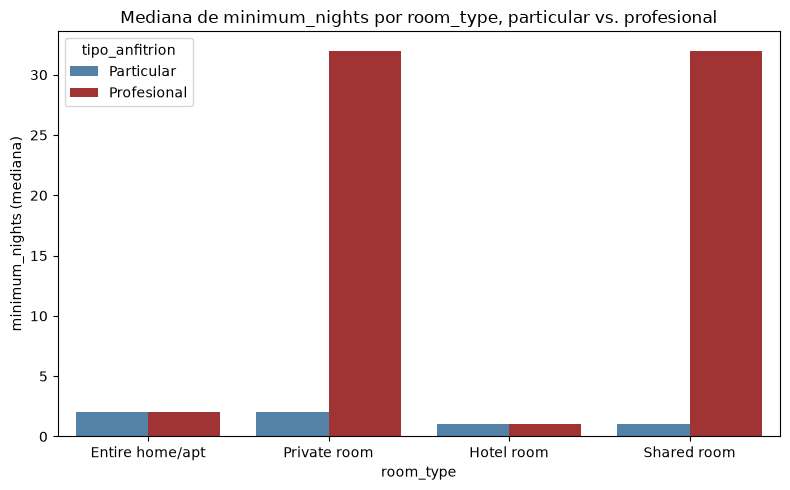

In [18]:
print("Mediana de minimum_nights por room_type, en general (sin separar por anfitrión):")
print(listings.groupby("room_type")["minimum_nights"].median())
print()

tabla = listings.groupby(["room_type", "tipo_anfitrion"])["minimum_nights"].agg(Mediana="median", Media="mean", n="count")
display(tabla.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=listings, x="room_type", y="minimum_nights", hue="tipo_anfitrion",
            hue_order=["Particular", "Profesional"], order=["Entire home/apt", "Private room", "Hotel room", "Shared room"],
            estimator="median", errorbar=None, palette={"Particular": "steelblue", "Profesional": "firebrick"}, ax=ax)
ax.set_xlabel("room_type")
ax.set_ylabel("minimum_nights (mediana)")
ax.set_title("Mediana de minimum_nights por room_type, particular vs. profesional")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/minimum_nights_room_type_tipo_anfitrion.png", dpi=100)
plt.show()

No es un efecto de composición de `room_type` — es más específico de lo que parecía a simple vista:

- **Entire home/apt** (la categoría más grande de ambos grupos): mediana de 2 noches en **los dos**, particular y profesional. Ahí no hay diferencia por tipo de anfitrión.
- **Private room**: mediana de 2 noches en particulares vs. **32 noches** en profesionales — toda la brecha general (25 vs. 2 noches) viene casi por completo de esta categoría.

Interpretación: los profesionales que gestionan habitaciones privadas las convierten en estancias de un mes, un modelo más parecido al alquiler de larga duración que al alojamiento turístico — mientras que los particulares con habitaciones mantienen el patrón turístico normal. Esto reduce drásticamente el grupo de huéspedes potenciales (turistas de pocos días no califican), lo que es coherente con la baja ocupación ya vista en `availability_365` para ese grupo.

### `availability_eoy`

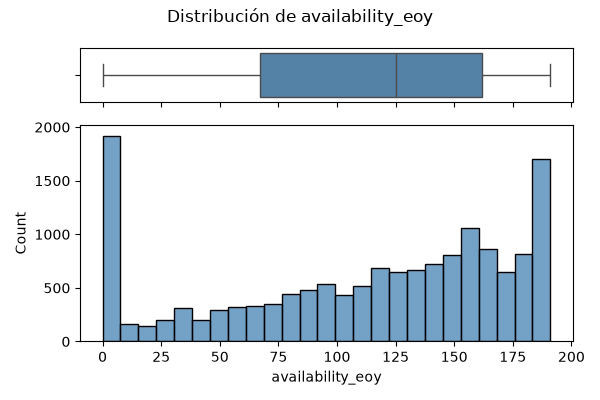

Q1=67.0  mediana=125.0  Q3=162.0  limite superior atipicos=304.5
nulos=0  max real=191
con 0 dias libres=1756 (11.5%)


In [19]:
ruta = graficar_numerica(listings["availability_eoy"], "availability_eoy", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["availability_eoy"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()}  max real={s.max()}")
print(f"con 0 días libres={(s==0).sum()} ({(s==0).mean()*100:.1f}%)")

Percentiles: 25% = 67, mediana = 125, 75% = 162. Sin atípicos (máximo real
191, por debajo del límite calculado de 304,5). 11,5% con 0 días libres
(1.756).

El máximo posible depende de en qué mes del
año se hizo el scraping — aquí 191 porque se hizo entre el 24 de junio y el
3 de julio, dejando ese rango hasta el 31 de diciembre.

### `bathrooms`

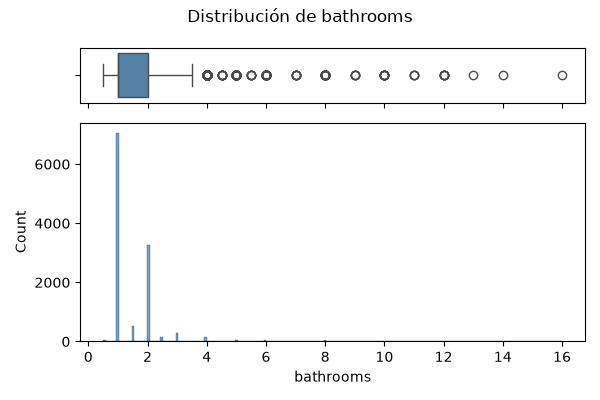

Q1=1.0  mediana=1.0  Q3=2.0  limite superior atipicos=3.5
nulos=3565 (23.3%)
bathrooms
0.5      64
1.0    7053
1.5     540
2.0    3260
2.5     141
3.0     291
Name: count, dtype: int64


In [20]:
ruta = graficar_numerica(listings["bathrooms"], "bathrooms", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["bathrooms"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(s.value_counts().sort_index().head(6))

Percentiles: 25% = 1, mediana = 1, 75% = 2. Atípicos a partir de 3,5 (valores
4 en adelante). 23,3% nulos (3.565) — es una de las columnas que se imputa
en notebook 05.

1 baño es, con diferencia, el valor más común (7.053 anuncios), seguido de 2
(3.260).

### `bathrooms_text`

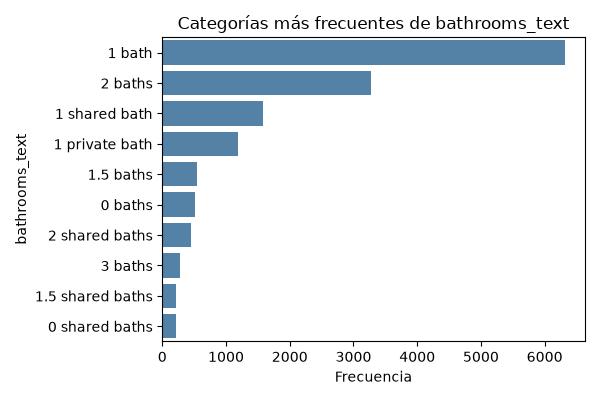

nulos bathrooms_text=13 (0.1%)
nulos bathrooms=3565 (23.3%)
contiene 'shared': 2659


In [21]:
ruta = graficar_categorica(listings["bathrooms_text"], "bathrooms_text", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos bathrooms_text={listings['bathrooms_text'].isna().sum()} ({listings['bathrooms_text'].isna().mean()*100:.1f}%)")
print(f"nulos bathrooms={listings['bathrooms'].isna().sum()} ({listings['bathrooms'].isna().mean()*100:.1f}%)")
print(f"contiene 'shared': {listings['bathrooms_text'].astype(str).str.contains('shared', case=False).sum()}")

`bathrooms_text` tiene solo 0,1% nulos (13), frente al 23,3% de `bathrooms`
(numérica) — mucho más completa. También distingue "shared"/"private", algo
que la columna numérica no captura: 2.659 anuncios mencionan baño
compartido.

### Cruce: `bathrooms` según `room_type` (todos los anuncios)

Qué proporción de cada tipo de alojamiento tiene cada cantidad de baños — no solo el caso del medio baño.

In [22]:
def agrupa_bathrooms(v):
    if pd.isna(v):
        return "Sin dato"
    if v >= 3:
        return "3+"
    return str(v)

listings["bathrooms_bucket"] = listings["bathrooms"].apply(agrupa_bathrooms)
orden_bucket = ["0.5", "1.0", "1.5", "2.0", "2.5", "3+", "Sin dato"]

tabla_pct = pd.crosstab(listings["room_type"], listings["bathrooms_bucket"], normalize="index") * 100
tabla_pct = tabla_pct[orden_bucket]
print("En porcentaje (dentro de cada room_type):")
display(tabla_pct.round(1))

En porcentaje (dentro de cada room_type):


bathrooms_bucket,0.5,1.0,1.5,2.0,2.5,3+,Sin dato
room_type,,,,,,,
Entire home/apt,0.1,48.2,3.4,25.6,0.9,4.9,16.9
Hotel room,0.0,77.9,1.5,1.5,1.5,1.5,16.2
Private room,1.2,40.5,4.0,11.1,1.0,3.0,39.3
Shared room,0.0,36.1,0.0,7.6,0.0,12.6,43.7


In [23]:
tabla_n = pd.crosstab(listings["room_type"], listings["bathrooms_bucket"])
tabla_n = tabla_n[orden_bucket]
print("En cantidad de anuncios (n):")
display(tabla_n)

En cantidad de anuncios (n):


bathrooms_bucket,0.5,1.0,1.5,2.0,2.5,3+,Sin dato
room_type,,,,,,,
Entire home/apt,14,5229,369,2779,99,526,1828
Hotel room,0,53,1,1,1,1,11
Private room,50,1728,170,471,41,128,1674
Shared room,0,43,0,9,0,15,52


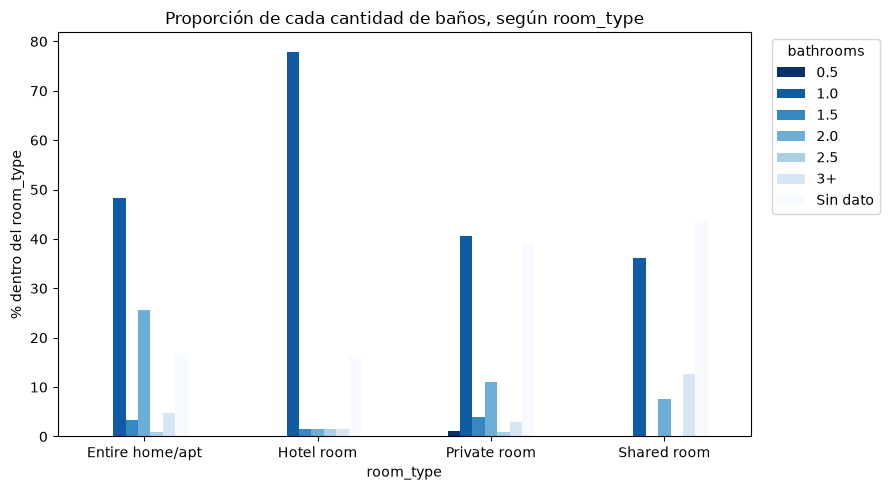

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
tabla_pct.plot(kind="bar", ax=ax, colormap="Blues_r")
ax.set_xlabel("room_type")
ax.set_ylabel("% dentro del room_type")
ax.set_title("Proporción de cada cantidad de baños, según room_type")
plt.xticks(rotation=0)
ax.legend(title="bathrooms", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/bathrooms_room_type.png", dpi=100)
plt.show()

En proporción, "1.0 baño" domina en las 4 categorías, pero con pesos distintos: 77,9% en "Hotel room", 48,2% en "Entire home/apt", 40,5% en "Private room" y 36,1% en "Shared room".

"2.0 baños" es claramente más frecuente en "Entire home/apt" (25,6%) que en el resto (11,1% Private room, 7,6% Shared room, 1,5% Hotel room) — coherente con que los pisos enteros suelen tener más de un baño. "3+" también destaca en "Shared room" (12,6%), aunque con una base pequeña (67 anuncios en total).

El medio baño (0.5) es minoritario en todas, con el máximo en "Private room" (1,2%). "Sin dato" varía mucho entre categorías: 39,3% en Private room y 43,7% en Shared room, frente a 16,9% en Entire home/apt y 16,2% en Hotel room — no depende del tamaño de la categoría (Hotel room también es chica, 57 anuncios, y tiene pocos nulos), es una diferencia específica de Private room y Shared room.

### `bedrooms`

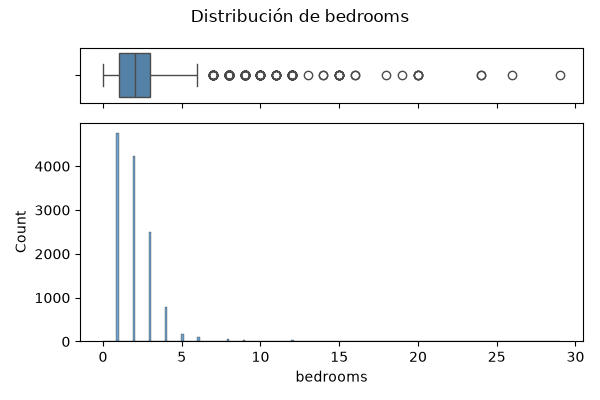

Q1=1.0  mediana=2.0  Q3=3.0  limite superior atipicos=6.0
nulos=2562 (16.8%)  max real=29.0
bedrooms
0.0       4
1.0    4757
2.0    4241
3.0    2502
4.0     786
5.0     167
Name: count, dtype: int64


In [25]:
ruta = graficar_numerica(listings["bedrooms"], "bedrooms", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["bedrooms"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)  max real={s.max()}")
print(s.value_counts().sort_index().head(6))

Percentiles: 25% = 1, mediana = 2, 75% = 3. Atípicos a partir de 6
dormitorios — el máximo real llega a 29. 16,8% nulos (2.562), otra de las
columnas que se imputa en notebook 05.

1 dormitorio es el más común (4.757), seguido de 2 (4.241).

### Cruce: `bedrooms` según `room_type`

,Mediana,Media,n
room_type,,,
Entire home/apt,2.0,2.31,10538
Private room,1.0,1.26,2042
Shared room,1.0,1.09,89
Hotel room,1.0,1.24,62


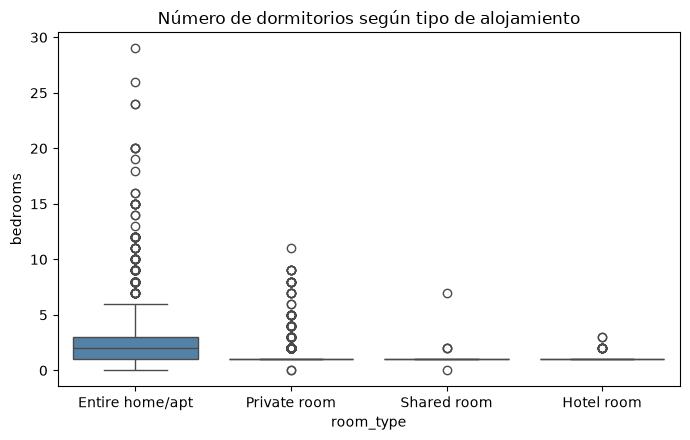

In [26]:
tabla_cruce = listings.groupby("room_type")["bedrooms"].agg(
    Mediana="median", Media="mean", n="count"
).sort_values("n", ascending=False)
display(tabla_cruce.round(2))

orden = tabla_cruce.index
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.boxplot(data=listings, x="room_type", y="bedrooms", order=orden, color="steelblue", ax=ax)
ax.set_xlabel("room_type")
ax.set_ylabel("bedrooms")
ax.set_title("Número de dormitorios según tipo de alojamiento")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/bedrooms_room_type.png", dpi=100)
plt.show()

"Entire home/apt" tiene mediana de 2 dormitorios (media 2,31), claramente por encima de los otros tres, que están todos en mediana 1 (Hotel room, Private room, Shared room) — lógico, un piso entero suele tener más de un dormitorio, mientras que las otras categorías son, por definición, una sola habitación o espacio.

### Cruce: `bedrooms` según `accommodates`

Correlación fuerte (0,81) entre ambas, pero vale la pena ver si hay casos donde la capacidad declarada no encaja con los dormitorios disponibles.

`bedrooms` tiene cola larga hasta 29 y 16,8% de nulos; se agrupan aparte para que el heatmap quede legible y los nulos no se mezclen con "10+".

Correlacion bedrooms-accommodates: 0.806


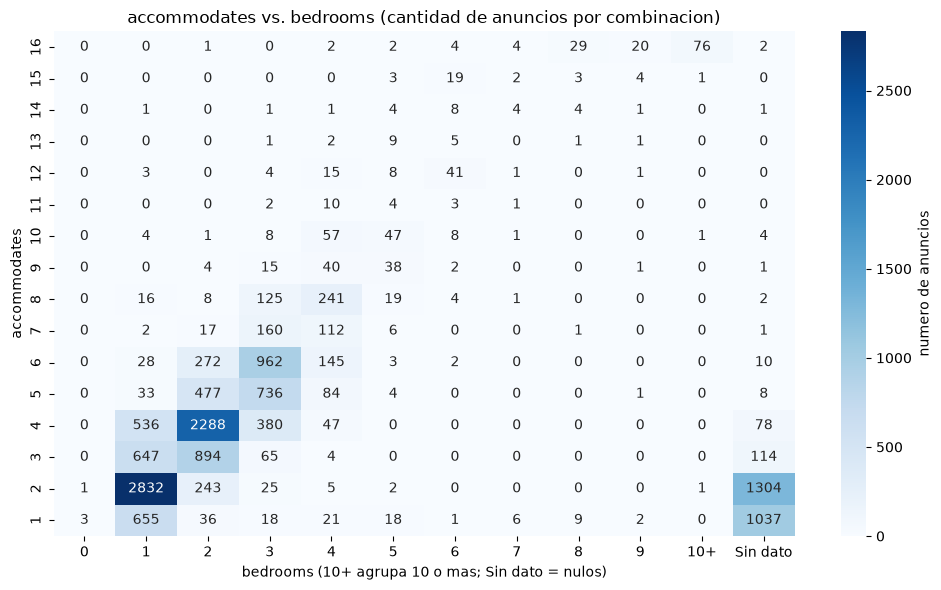


Casos con accommodates >= 8 y bedrooms <= 1: 24
room_type
Private room       13
Shared room         9
Entire home/apt     2
Name: count, dtype: int64


In [27]:
print("Correlación bedrooms-accommodates:", round(listings["bedrooms"].corr(listings["accommodates"]), 3))

def agrupa_bedrooms(v):
    if pd.isna(v):
        return "Sin dato"
    if v >= 10:
        return "10+"
    return str(int(v))

bedrooms_bucket = listings["bedrooms"].apply(agrupa_bedrooms)
tabla_heatmap = pd.crosstab(listings["accommodates"], bedrooms_bucket)
orden_cols = [str(i) for i in range(10)] + ["10+", "Sin dato"]
tabla_heatmap = tabla_heatmap[[c for c in orden_cols if c in tabla_heatmap.columns]]

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(tabla_heatmap.sort_index(ascending=False), cmap="Blues", annot=True, fmt="d", cbar_kws={"label": "número de anuncios"}, ax=ax)
ax.set_xlabel("bedrooms (10+ agrupa 10 o más; Sin dato = nulos)")
ax.set_ylabel("accommodates")
ax.set_title("accommodates vs. bedrooms (cantidad de anuncios por combinacion)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/bedrooms_accommodates.png", dpi=100)
plt.show()

raros = listings[(listings["accommodates"] >= 8) & (listings["bedrooms"] <= 1)]
print(f"\nCasos con accommodates >= 8 y bedrooms <= 1: {len(raros)}")
print(raros["room_type"].value_counts())

La relación es claramente positiva (correlación 0,81), pero no perfecta: hay 24 anuncios con capacidad para 8 o más personas y 1 dormitorio o menos. La mayoría (22 de 24: 13 Private room, 9 Shared room) son habitaciones, no pisos enteros — tiene sentido, una habitación compartida puede dar cabida a varias personas con literas o camas múltiples sin que eso implique varios dormitorios. Los otros 2 casos son "Entire home/apt", más atípicos (un piso entero con 8+ personas y 1 solo dormitorio, probablemente con sofás cama u otro espacio para dormir no contado como dormitorio).

### `beds`

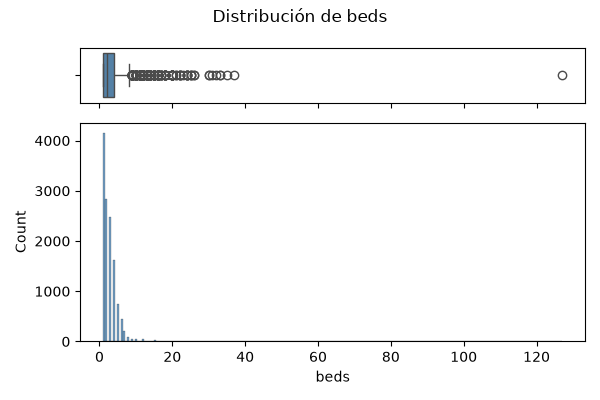

Q1=1.0  mediana=2.0  Q3=4.0  limite superior atipicos=8.5
nulos=2447 (16.0%)  max real=127.0


,id,beds,accommodates,room_type
10049,1142485100279703723,127.0,4,Entire home/apt


In [28]:
ruta = graficar_numerica(listings["beds"], "beds", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["beds"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)  max real={s.max()}")

fila_max = listings[listings["beds"] == s.max()]
display(fila_max[["id", "beds", "accommodates", "room_type"]])

Percentiles: 25% = 1, mediana = 2, 75% = 4. Atípicos a partir de 8,5. 16,0%
nulos (2.447), otra de las columnas que se imputa en notebook 05.

Valor sospechoso: el máximo real es 127 camas, en un anuncio que solo tiene
`accommodates = 4` (caben 4 personas). 127 camas para 4 huéspedes no es
coherente — parece un error de dato, no una cifra real.

### Cruce: `beds` según `accommodates`

¿Hay suficientes camas para la capacidad declarada? Correlación de 0,76.

Correlacion beds-accommodates: 0.764


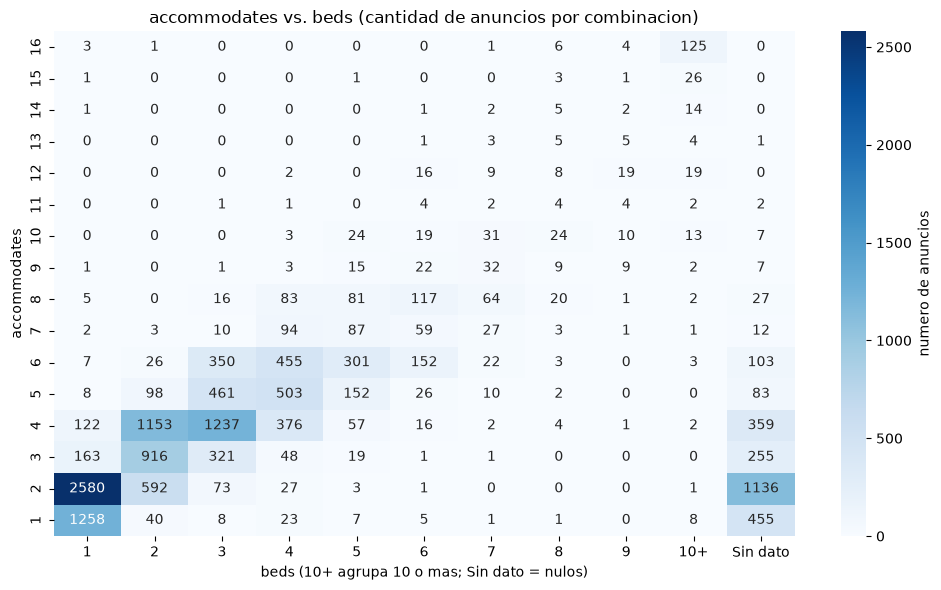


Anuncios con mas camas que personas (beds > accommodates): 479
Anuncios con menos de media cama por persona (beds < accommodates/2): 482


In [29]:
print("Correlación beds-accommodates:", round(listings["beds"].corr(listings["accommodates"]), 3))

def agrupa_beds(v):
    if pd.isna(v):
        return "Sin dato"
    if v >= 10:
        return "10+"
    return str(int(v))

beds_bucket = listings["beds"].apply(agrupa_beds)
tabla_heatmap = pd.crosstab(listings["accommodates"], beds_bucket)
orden_cols = [str(i) for i in range(1, 10)] + ["10+", "Sin dato"]
tabla_heatmap = tabla_heatmap[[c for c in orden_cols if c in tabla_heatmap.columns]]

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(tabla_heatmap.sort_index(ascending=False), cmap="Blues", annot=True, fmt="d", cbar_kws={"label": "número de anuncios"}, ax=ax)
ax.set_xlabel("beds (10+ agrupa 10 o más; Sin dato = nulos)")
ax.set_ylabel("accommodates")
ax.set_title("accommodates vs. beds (cantidad de anuncios por combinacion)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/beds_accommodates.png", dpi=100)
plt.show()

mas_camas = listings[listings["beds"] > listings["accommodates"]]
pocas_camas = listings[listings["beds"] < listings["accommodates"] / 2]
print(f"\nAnuncios con más camas que personas (beds > accommodates): {len(mas_camas)}")
print(f"Anuncios con menos de media cama por persona (beds < accommodates/2): {len(pocas_camas)}")

La relación es positiva pero con bastante ruido (correlación 0,76, algo más débil que `bedrooms`-`accommodates`). 479 anuncios tienen más camas que personas que caben (`beds > accommodates`) — probablemente margen extra o camas individuales en vez de dobles. 482 anuncios tienen menos de media cama por persona (`beds < accommodates/2`) — implica compartir cama entre varias personas, algo común en alojamientos pensados para grupos o familias con niños.

`beds` llega hasta un máximo de 127 (atípico extremo), frente al máximo de `accommodates` de 16 — un valor que convendría revisar aparte, probablemente un error de carga más que un alojamiento real.

### Nota: el caso de `beds = 127`

In [30]:
fila = listings[listings["beds"] == 127]
print(fila[["id", "name", "host_id", "host_name", "accommodates", "bedrooms", "beds",
            "maximum_nights", "minimum_nights", "calculated_host_listings_count"]].T)

ukio = listings[listings["host_id"] == fila["host_id"].iloc[0]]
print(f"\nTotal anuncios del mismo host: {len(ukio)}")
print(ukio["beds"].describe())
print()
print("Anuncios del mismo host con accommodates similar (6-10), para comparar:")
print(ukio[(ukio["accommodates"] >= 6) & (ukio["accommodates"] <= 10)][["accommodates", "beds"]].sort_values("accommodates").head(10))

                                                                          10049
id                                                          1142485100279703723
name                            Tunupa - 2 bedrooms and terrace in Sant Gervasi
host_id                                                               346367515
host_name                                                                  Ukio
accommodates                                                                  4
bedrooms                                                                    2.0
beds                                                                      127.0
maximum_nights                                                            125.0
minimum_nights                                                             31.0
calculated_host_listings_count                                              588

Total anuncios del mismo host: 588
count    534.000000
mean       2.544944
std        5.468041
min        1.000000
25% 

El anuncio pertenece a "Ukio", una gestora profesional con 588 anuncios en Barcelona. Dos pistas de que es un caso aislado, no un patrón real:

1. El resto de anuncios de Ukio con capacidades similares (6-10 personas) tienen 5-6 camas, valores normales — solo este anuncio tiene 127.
2. 127 está sospechosamente cerca de `maximum_nights = 125` de ese mismo anuncio (Ukio usa `maximum_nights=125` y `minimum_nights=31` como política fija en sus 588 anuncios). No se puede confirmar la causa exacta con los datos disponibles, pero es plausible que el valor se haya mezclado con otro campo cercano al cargar los datos.

Conclusión: es un error puntual de un solo registro, no un patrón del anfitrión ni de la columna en general.

### `calculated_host_listings_count_entire_homes`

Cuántos anuncios de tipo "piso entero" tiene el anfitrión de cada fila, en Barcelona.

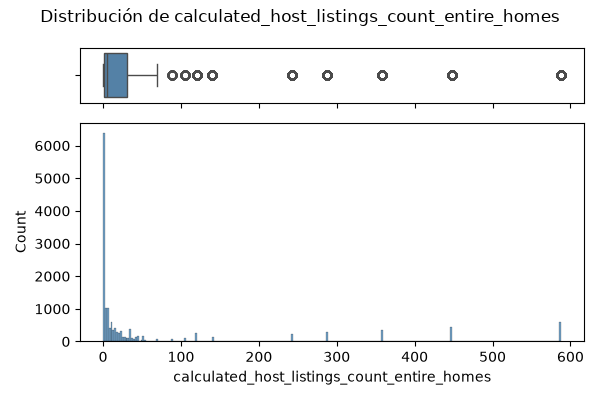

Q1=1.0  mediana=5.0  Q3=31.0  limite superior atipicos=76.0
nulos=0  max real=588
con 0=3561 (23.3%)


In [31]:
col = "calculated_host_listings_count_entire_homes"
ruta = graficar_numerica(listings[col], col, CARPETA_LISTINGS)
display(Image(ruta))

s = listings[col]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()}  max real={s.max()}")
print(f"con 0={(s==0).sum()} ({(s==0).mean()*100:.1f}%)")

Percentiles: 25% = 1, mediana = 5, 75% = 31. Atípicos a partir de 76 — el
máximo real llega a 588. 0 nulos. 23,3% de los anuncios (3.561) tienen 0:
son hosts cuyo portafolio no incluye ningún piso entero (solo habitaciones
u hoteles).

### Cruce: `calculated_host_listings_count_entire_homes` según tipo de anfitrión

El conteo bruto es casi circular (los profesionales ya tienen carteras grandes por definición). Lo más informativo es qué **porcentaje** de la cartera de cada anfitrión son pisos enteros, no solo el número absoluto.

,Mediana,Media,n
tipo_anfitrion,,,
Particular,2.0,7.80,11728
Profesional,243.0,256.32,3565


Composicion de cartera, categorizada:


pct_entire_homes_bucket,0% (nada),Mixto (1-99%),100% (todo)
tipo_anfitrion,,,
Particular,27.8,7.5,64.7
Profesional,8.4,37.2,54.5


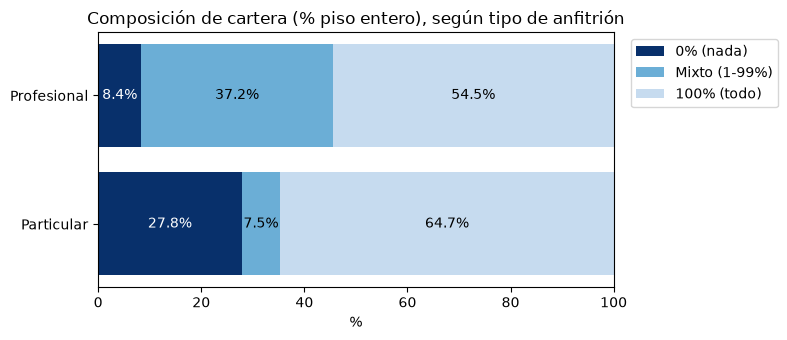

In [32]:
tabla_cruce = listings.groupby("tipo_anfitrion")["calculated_host_listings_count_entire_homes"].agg(
    Mediana="median", Media="mean", n="count"
)
display(tabla_cruce.round(2))

listings["pct_entire_homes"] = listings["calculated_host_listings_count_entire_homes"] / listings["calculated_host_listings_count"].replace(0, pd.NA) * 100

def agrupa_pct(v):
    if v == 0:
        return "0% (nada)"
    if v == 100:
        return "100% (todo)"
    return "Mixto (1-99%)"

listings["pct_entire_homes_bucket"] = listings["pct_entire_homes"].apply(agrupa_pct)
orden_bucket = ["0% (nada)", "Mixto (1-99%)", "100% (todo)"]
tabla_pct = pd.crosstab(listings["tipo_anfitrion"], listings["pct_entire_homes_bucket"], normalize="index") * 100
tabla_pct = tabla_pct[orden_bucket]
print("Composición de cartera, categorizada:")
display(tabla_pct.round(1))

colores = ["#08306b", "#6baed6", "#c6dbef"]
fig, ax = plt.subplots(figsize=(8, 3.5))
izquierda = pd.Series(0.0, index=tabla_pct.index)
for col, color in zip(orden_bucket, colores):
    valores = tabla_pct[col]
    ax.barh(tabla_pct.index, valores, left=izquierda, color=color, label=col)
    for i, (v, izq) in enumerate(zip(valores, izquierda)):
        if v >= 3:
            ax.text(izq + v / 2, i, f"{v:.1f}%", ha="center", va="center",
                    color="white" if color == "#08306b" else "black", fontsize=10)
    izquierda += valores

ax.set_xlabel("%")
ax.set_xlim(0, 100)
ax.set_title("Composición de cartera (% piso entero), según tipo de anfitrión")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/entire_homes_pct_tipo_anfitrion.png", dpi=100)
plt.show()

El conteo bruto es enorme en profesionales (mediana 243 vs. 2 en particulares), pero eso es casi la definición misma de "profesional" (más de 50 anuncios totales).

La composición de cartera cuenta una historia más matizada de lo que parece a simple vista: los particulares son más **bimodales** — 27,8% no tiene ningún piso entero (0%) y 64,7% tiene solo pisos enteros (100%), con muy poco término medio (7,5% mixto). Los profesionales, en cambio, casi nunca están en 0% (solo 8,4%) pero tampoco son tan frecuentemente 100% puros (54,5%) — el 37,2% tiene una cartera mixta, combinando pisos enteros con habitaciones.

El resultado neto: la media es más alta en profesionales (80,0% vs. 68,1%) porque casi ninguno tiene cero pisos enteros, aunque los particulares "puros" (100%) sean proporcionalmente más frecuentes. Confirma el mismo patrón general ya visto con `room_type`: los profesionales concentran más su actividad en pisos enteros, solo que con una cartera más diversificada, no monolítica.

### `calculated_host_listings_count`

Cuántos anuncios tiene en total el anfitrión de cada fila, en Barcelona (todos los tipos juntos).

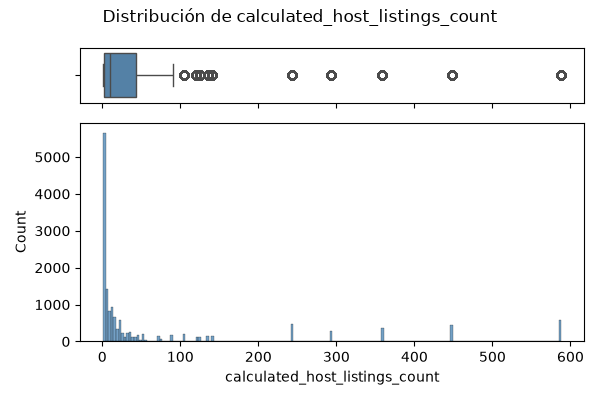

Q1=2.0  mediana=10.0  Q3=43.0  limite superior atipicos=104.5
nulos=0  max real=588
con 1 anuncio=2988 (19.5%)


In [33]:
col = "calculated_host_listings_count"
ruta = graficar_numerica(listings[col], col, CARPETA_LISTINGS)
display(Image(ruta))

s = listings[col]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()}  max real={s.max()}")
print(f"con 1 anuncio={(s==1).sum()} ({(s==1).mean()*100:.1f}%)")

Percentiles: 25% = 2, mediana = 10, 75% = 43. Atípicos a partir de 104,5 —
máximo real 588. 0 nulos.
19,5% de los anuncios (2.988) pertenecen a anfitriones con 1 solo anuncio
en Barcelona.

### Cruce: `calculated_host_listings_count` según distrito

¿Las carteras grandes se concentran en ciertos distritos? Complementa el cruce de distrito x tipo de anfitrión ya visto, con el tamaño real de cartera en vez de la etiqueta binaria.

,Mediana,Media,n
neighbourhood_group_cleansed,,,
Sarrià-Sant Gervasi,19.0,120.3,888
Nou Barris,12.0,120.1,163
Eixample,15.0,97.1,5835
Les Corts,14.0,68.9,327
Gràcia,8.0,66.3,1366
Ciutat Vella,7.0,52.7,3247
Sants-Montjuïc,6.0,52.4,1448
Horta-Guinardó,3.0,45.9,358
Sant Martí,5.0,36.4,1436


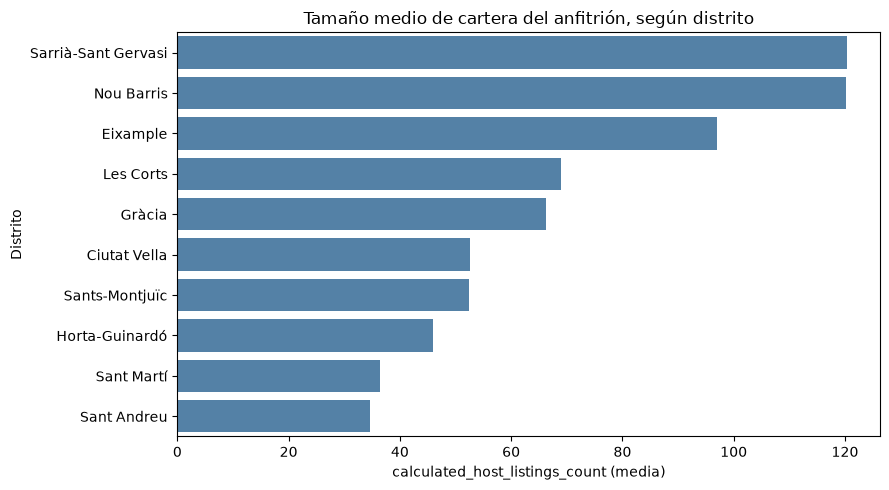

In [34]:
tabla_cruce = listings.groupby("neighbourhood_group_cleansed")["calculated_host_listings_count"].agg(
    Mediana="median", Media="mean", n="count"
).sort_values("Media", ascending=False)
display(tabla_cruce.round(1))

orden = tabla_cruce.index
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=tabla_cruce["Media"], y=orden, color="steelblue", ax=ax)
ax.set_xlabel("calculated_host_listings_count (media)")
ax.set_ylabel("Distrito")
ax.set_title("Tamaño medio de cartera del anfitrión, según distrito")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/calculated_total_distrito.png", dpi=100)
plt.show()

Sarrià-Sant Gervasi y Nou Barris tienen las carteras más grandes en promedio (120 anuncios de media en ambos), muy por encima del resto. Coincide con lo ya visto: esos dos distritos también tenían la mayor proporción de anfitriones profesionales (38,7% y 35,6% respectivamente) en el cruce de distrito x tipo de anfitrión — misma señal, dos variables distintas. Nou Barris sigue teniendo una base pequeña (163 anuncios), así que conviene la misma cautela de antes.

En el otro extremo, Sant Andreu (34,7) y Sant Martí (36,4) tienen las carteras más chicas en promedio.

### Cruce: `calculated_host_listings_count` según `estimated_revenue_l365d`

¿Gestionar más anuncios rinde mejor o peor por unidad? (economías vs. deseconomías de escala)

Correlacion calculated_host_listings_count - estimated_revenue_l365d: -0.181


,Media,Mediana,n
tamano_cartera,,,
1,24592.62,12136.0,2055
2-5,24069.41,9493.5,2736
6-20,22861.01,11264.5,3446
21-50,27419.24,14340.0,1719
51+,14677.54,0.0,3399


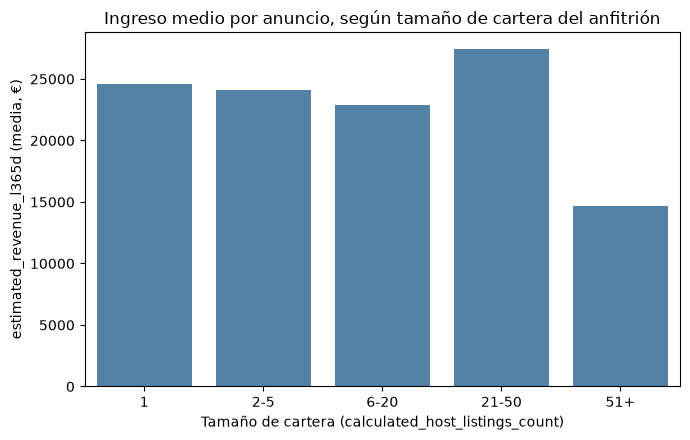

In [35]:
print("Correlación calculated_host_listings_count - estimated_revenue_l365d:",
      round(listings["calculated_host_listings_count"].corr(listings["estimated_revenue_l365d"]), 3))

listings["tamano_cartera"] = pd.cut(
    listings["calculated_host_listings_count"],
    bins=[0, 1, 5, 20, 50, 1000],
    labels=["1", "2-5", "6-20", "21-50", "51+"]
)
tabla_cruce = listings.groupby("tamano_cartera", observed=True)["estimated_revenue_l365d"].agg(Media="mean", Mediana="median", n="count")
display(tabla_cruce.round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=tabla_cruce.index, y=tabla_cruce["Media"], color="steelblue", ax=ax)
ax.set_xlabel("Tamaño de cartera (calculated_host_listings_count)")
ax.set_ylabel("estimated_revenue_l365d (media, €)")
ax.set_title("Ingreso medio por anuncio, según tamaño de cartera del anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/calculated_total_revenue.png", dpi=100)
plt.show()

Correlación negativa y débil-moderada (-0,18), pero la forma real no es una caída gradual — es más bien plana entre 1 y 50 anuncios (24.593€ con 1 anuncio, 24.069€ con 2-5, 22.861€ con 6-20, e incluso sube a 27.419€ en 21-50), y solo se desploma en el último tramo: 14.678€ en carteras de 51+.

Es decir, no hay un efecto gradual de "cuanto más grande la cartera, peor rinde cada anuncio" — hay un salto brusco justo en el umbral de 51 anuncios, que es exactamente el punto de corte usado para definir `host_profesional`. Esto sugiere que lo que empeora el rendimiento no es el tamaño de la cartera en sí, sino algo que cambia específicamente en las operaciones a gran escala (51+), más allá de un simple "a más anuncios, menos ingreso por unidad".

### `calculated_host_listings_count_private_rooms`

Cuántos anuncios de tipo "habitación privada" tiene el anfitrión de cada fila, en Barcelona.

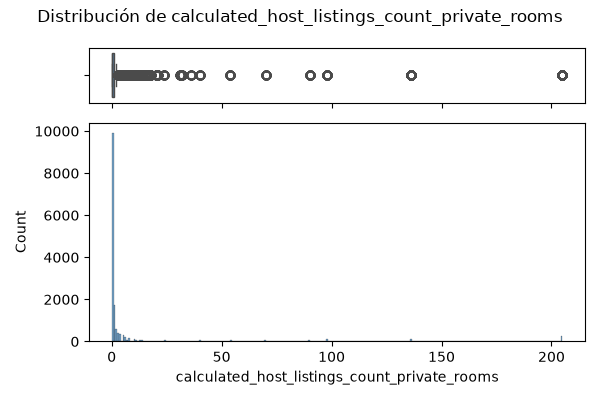

Q1=0.0  mediana=0.0  Q3=1.0  limite superior atipicos=2.5
nulos=0  max real=205
con 0=9909 (64.8%)


In [36]:
col = "calculated_host_listings_count_private_rooms"
ruta = graficar_numerica(listings[col], col, CARPETA_LISTINGS)
display(Image(ruta))

s = listings[col]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()}  max real={s.max()}")
print(f"con 0={(s==0).sum()} ({(s==0).mean()*100:.1f}%)")

Percentiles: 25% = 0, mediana = 0, 75% = 1. Atípicos a partir de 2,5 —
máximo real 205. 0 nulos. 64,8% de los anuncios (9.909) pertenecen a
anfitriones sin ninguna habitación privada en su portafolio. Es decir, del 64,8% sin habitaciones privadas, el 99,3% (9.840) tiene al menos un piso entero en su lugar.

In [37]:
sin_privadas = listings[listings["calculated_host_listings_count_private_rooms"] == 0]
con_pisos = (sin_privadas["calculated_host_listings_count_entire_homes"] > 0).sum()
print(f"sin habitaciones privadas: {len(sin_privadas)}")
print(f"de esos, con al menos 1 piso entero: {con_pisos} ({con_pisos/len(sin_privadas)*100:.1f}%)")

sin habitaciones privadas: 9909
de esos, con al menos 1 piso entero: 9840 (99.3%)


In [38]:
con_pisos_total = (listings["calculated_host_listings_count_entire_homes"] > 0).sum()
con_ambos = ((listings["calculated_host_listings_count_private_rooms"] > 0) & (listings["calculated_host_listings_count_entire_homes"] > 0)).sum()
print(f"con piso entero: {con_pisos_total}  ->  solo piso: {con_pisos} ({con_pisos/con_pisos_total*100:.1f}%)  +  piso y privada: {con_ambos}")

con piso entero: 11732  ->  solo piso: 9840 (83.9%)  +  piso y privada: 1892


### Cruce: `calculated_host_listings_count_private_rooms` según tipo de anfitrión

Mismo análisis que con `entire_homes`, pero para habitaciones privadas.

pct_private_bucket,0% (nada),Mixto (1-99%),100% (todo)
tipo_anfitrion,,,
Particular,65.4,8.6,26.0
Profesional,62.7,31.0,6.3


                Mediana  Media
tipo_anfitrion                
Particular          0.0  30.35
Profesional         0.0  19.72


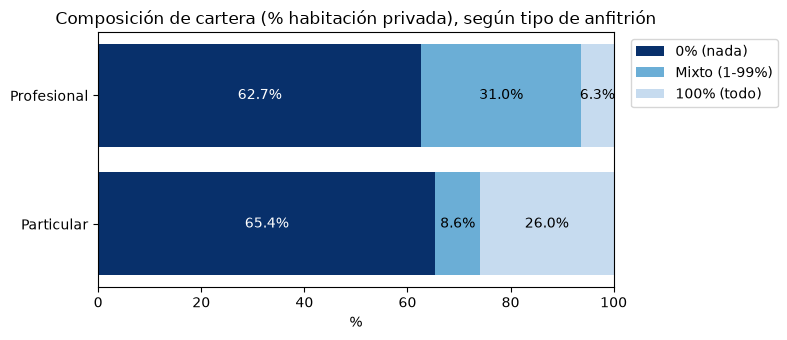

In [39]:
listings["pct_private"] = listings["calculated_host_listings_count_private_rooms"] / listings["calculated_host_listings_count"].replace(0, pd.NA) * 100

def agrupa_pct(v):
    if v == 0:
        return "0% (nada)"
    if v == 100:
        return "100% (todo)"
    return "Mixto (1-99%)"

listings["pct_private_bucket"] = listings["pct_private"].apply(agrupa_pct)
orden_bucket = ["0% (nada)", "Mixto (1-99%)", "100% (todo)"]
tabla_pct = pd.crosstab(listings["tipo_anfitrion"], listings["pct_private_bucket"], normalize="index") * 100
tabla_pct = tabla_pct[orden_bucket]
display(tabla_pct.round(1))
print(listings.groupby("tipo_anfitrion")["pct_private"].agg(Mediana="median", Media="mean").round(2))

colores = ["#08306b", "#6baed6", "#c6dbef"]
fig, ax = plt.subplots(figsize=(8, 3.5))
izquierda = pd.Series(0.0, index=tabla_pct.index)
for col, color in zip(orden_bucket, colores):
    valores = tabla_pct[col]
    ax.barh(tabla_pct.index, valores, left=izquierda, color=color, label=col)
    for i, (v, izq) in enumerate(zip(valores, izquierda)):
        if v >= 3:
            ax.text(izq + v / 2, i, f"{v:.1f}%", ha="center", va="center",
                    color="white" if color == "#08306b" else "black", fontsize=10)
    izquierda += valores

ax.set_xlabel("%")
ax.set_xlim(0, 100)
ax.set_title("Composición de cartera (% habitación privada), según tipo de anfitrión")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/private_rooms_pct_tipo_anfitrion.png", dpi=100)
plt.show()

Es casi la imagen espejo del cruce de `entire_homes`: los particulares tienen más carteras "100% puras" de habitación privada (26,0% vs. 6,3% en profesionales), mientras que los profesionales casi nunca van a cero o a cien — se concentran mucho más en "mixto" (31,0% vs. 8,6%). "0% (nada)" es parecido en ambos grupos (65,4% particular, 62,7% profesional).

En promedio, el % de la cartera que es habitación privada también es más alto en particulares (30,3% vs. 19,7%) — coherente con todo lo visto hasta ahora: los particulares tienden a especializarse (puro piso entero o puro habitación), los profesionales tienden a diversificar su cartera entre varios tipos de alojamiento.

### `calculated_host_listings_count_shared_rooms`

Cuántos anuncios de tipo "habitación compartida" tiene el anfitrión de cada fila, en Barcelona.

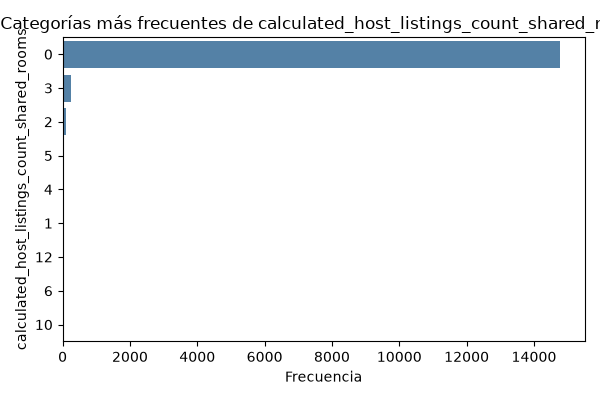

nulos=0  valores distintos=9
calculated_host_listings_count_shared_rooms
0     14777
1        23
2        99
3       255
4        34
5        46
6        21
10       16
12       22
Name: count, dtype: int64


In [40]:
col = "calculated_host_listings_count_shared_rooms"
ruta = graficar_categorica(listings[col], col, CARPETA_LISTINGS)
display(Image(ruta))

s = listings[col]
print(f"nulos={s.isna().sum()}  valores distintos={s.nunique()}")
print(s.value_counts().sort_index())

Solo 9 valores distintos, por eso sale como categórica (tiene ≤10 valores
únicos). 96,6% de los anuncios (14.777) pertenecen a anfitriones con 0
habitaciones compartidas. El resto se reparte en valores bajos (1 a 6),
salvo 3 anfitriones grandes con 10 y 12.

### Cruce: `calculated_host_listings_count_shared_rooms` según tipo de anfitrión

Mismo análisis que con `entire_homes` y `private_rooms`, para completar el grupo.

pct_shared_bucket,0% (nada),Mixto (1-99%),100% (todo)
tipo_anfitrion,,,
Particular,98.3,1.4,0.3
Profesional,91.2,8.8,0.0


                Mediana  Media
tipo_anfitrion                
Particular          0.0  0.972
Profesional         0.0  0.140


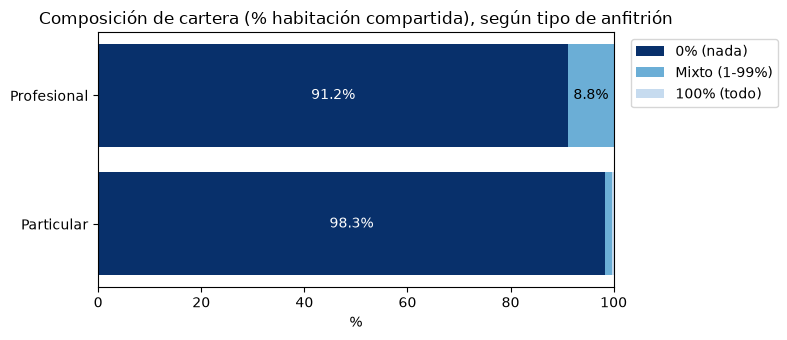

In [41]:
listings["pct_shared"] = listings["calculated_host_listings_count_shared_rooms"] / listings["calculated_host_listings_count"].replace(0, pd.NA) * 100

def agrupa_pct(v):
    if v == 0:
        return "0% (nada)"
    if v == 100:
        return "100% (todo)"
    return "Mixto (1-99%)"

listings["pct_shared_bucket"] = listings["pct_shared"].apply(agrupa_pct)
orden_bucket = ["0% (nada)", "Mixto (1-99%)", "100% (todo)"]
tabla_pct = pd.crosstab(listings["tipo_anfitrion"], listings["pct_shared_bucket"], normalize="index") * 100
tabla_pct = tabla_pct[orden_bucket]
display(tabla_pct.round(1))
print(listings.groupby("tipo_anfitrion")["pct_shared"].agg(Mediana="median", Media="mean").round(3))

colores = ["#08306b", "#6baed6", "#c6dbef"]
fig, ax = plt.subplots(figsize=(8, 3.5))
izquierda = pd.Series(0.0, index=tabla_pct.index)
for col, color in zip(orden_bucket, colores):
    valores = tabla_pct[col]
    ax.barh(tabla_pct.index, valores, left=izquierda, color=color, label=col)
    for i, (v, izq) in enumerate(zip(valores, izquierda)):
        if v >= 3:
            ax.text(izq + v / 2, i, f"{v:.1f}%", ha="center", va="center",
                    color="white" if color == "#08306b" else "black", fontsize=10)
    izquierda += valores

ax.set_xlabel("%")
ax.set_xlim(0, 100)
ax.set_title("Composición de cartera (% habitación compartida), según tipo de anfitrión")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/shared_rooms_pct_tipo_anfitrion.png", dpi=100)
plt.show()

Muy distinto a los otros dos: aquí casi nadie tiene nada de habitación compartida en su cartera, ni particulares (98,3% en 0%) ni profesionales (91,2% en 0%). Ningún profesional tiene una cartera 100% pura de shared room (0,0%), y solo 0,3% de particulares.

El único matiz es que los profesionales tienen algo más de "mixto" (8,8% vs. 1,4%) — consistente con el patrón de diversificación ya visto en los otros dos cruces, pero aquí la categoría es tan minoritaria en general (media 0,97% particular, 0,14% profesional) que no es un hallazgo relevante por sí solo, solo cierra el grupo de las 3 columnas `calculated_host_listings_count_*`.

### `calendar_last_scraped`

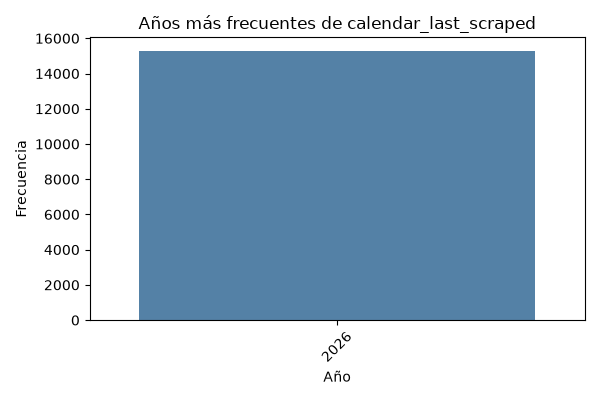

nulos=0
calendar_last_scraped
2026-06-24     2340
2026-06-25    10695
2026-07-02      520
2026-07-03     1738
Name: count, dtype: int64


In [42]:
fecha_calendar = pd.to_datetime(listings["calendar_last_scraped"])
ruta = graficar_fecha(fecha_calendar, "calendar_last_scraped", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={fecha_calendar.isna().sum()}")
print(fecha_calendar.dt.date.value_counts().sort_index())

0 nulos, 4 fechas distintas, todas en 2026: 2026-06-24 (2.340), 2026-06-25
(10.695), 2026-07-02 (520), 2026-07-03 (1.738) — idéntica a `last_scraped`.

### `calendar_updated`

Fecha de la última actualización del calendario de disponibilidad del anuncio.

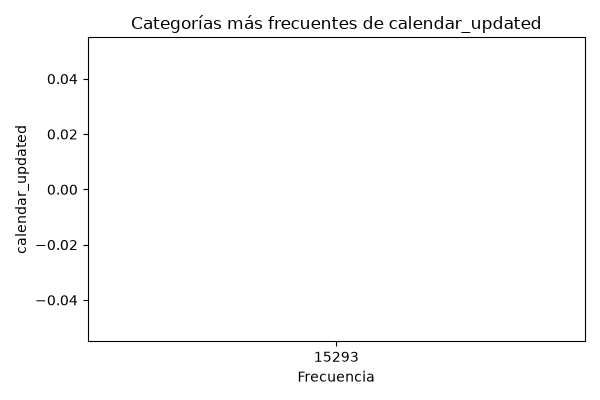

nulos=15293 de 15293


In [43]:
ruta = graficar_categorica(listings["calendar_updated"], "calendar_updated", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['calendar_updated'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05.

### `description`

Descripción larga del alojamiento, escrita por el anfitrión (detalles del espacio, no un título corto).

No se usa `graficar_categorica` aquí: `description` es texto libre largo, no cabe legible como etiqueta de eje. Se numeran las barras y se muestra el texto completo en una tabla.

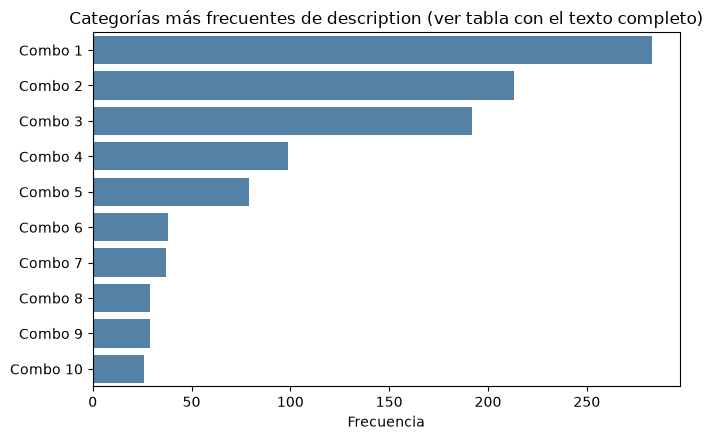

nulos=649 (4.2%)
valores unicos=11815 de 14644



,Combo,Frecuencia,Contenido completo
0,Combo 1,283,Our mission is to empower individuals to immerse themselves in new places by having a home wherever they go. We do this by providing artfully designed fully furnished and serviced apartments for stays of one month or more. We are currently present in some of the most important cities in Europe.
1,Combo 2,213,"IMPORTANT This rental is exclusively temporary (tourist, vacation and leisure) and must be formalized with a rental contract clearly indicating that you are coming for Tourism (it is the only reason why it will be rented). It must be accredited by providing documents that confirm residence in another country of each guest. Please ask about availability before booking<br />If you'd like to pay in cash, let us know and we can arrange it."
2,Combo 3,192,Our mission is to empower individuals to immerse themselves in new places by having a home wherever they go. We do this by providing artfully designed fully furnished and serviced apartments for stays of one month or more. We are currently present in some of the most important cities in Europe
3,Combo 4,99,Our mission is to empower individuals to immerse themselves in new places by having a home wherever they go. We do this by providing artfully designed fully furnished and serviced apartments for stays of one month or more. We are currently present in some of the most important cities in Europe.
4,Combo 5,79,"This special place is close to everything, making it easy to plan your visit."
5,Combo 6,38,The whole group will enjoy easy access to everything from this centrally located place.
6,Combo 7,37,Enjoy the simplicity of this quiet and central accommodation.
7,Combo 8,29,Enjoy the simplicity of this quiet and centrally-located accommodation.
8,Combo 9,29,"At Badi, we believe that finding new accommodation should be an exciting and enjoyable experience. That's why we aim to make the process of finding short-stay accommodation as easy and relaxed as possible. Our company offers a wide variety of options, from private rooms to entire apartments, catering to all types of travelers. Whether you are a student, a professional or just on a long-term vacation, we offer the help you need."
9,Combo 10,26,Enjoy a stylish experience at this centrally-located place.


In [44]:
conteo = listings["description"].value_counts().head(10)
etiquetas_numeradas = [f"Combo {i+1}" for i in range(len(conteo))]

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=conteo.values, y=etiquetas_numeradas, color="steelblue", ax=ax)
ax.set_xlabel("Frecuencia")
ax.set_ylabel("")
ax.set_title("Categorías más frecuentes de description (ver tabla con el texto completo)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/listings/description_categorica.png", dpi=100)
plt.show()

s = listings["description"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(f"valores únicos={s.nunique()} de {s.notna().sum()}")
print()

tabla_combos = pd.DataFrame({
    "Combo": etiquetas_numeradas,
    "Frecuencia": conteo.values,
    "Contenido completo": conteo.index,
})
pd.set_option("display.max_colwidth", None)
display(tabla_combos)

No es útil tal cual: texto libre, 11.815 valores únicos de 14.644 no nulos (80,7% distintos) — mismo problema de etiquetas largas visto en `amenities` y `license`, resuelto igual (barras numeradas + tabla con el texto completo).

### Extra: palabras más frecuentes en `description`

palabras totales (sin vacías): 506624


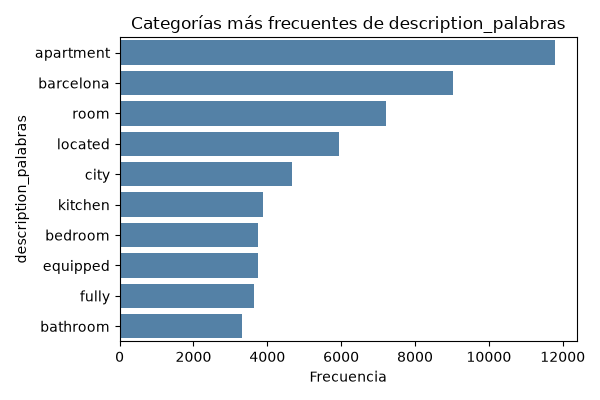

In [45]:
import re

texto = listings["description"].dropna().str.lower()
palabras = texto.str.findall(r"[a-z]{3,}").explode()
stopwords = {"the","and","with","for","you","this","from","has","are","one","very","your","not","but","all","can","will","that","our","its","out","use","per","non"}
palabras_filtradas = palabras[~palabras.isin(stopwords)]
print("palabras totales (sin vacías):", len(palabras_filtradas))

ruta = graficar_categorica(palabras_filtradas, "description_palabras", "../graficos_exploracion/cruces")
display(Image(ruta))

Top palabras tras quitar vacías en inglés (the, and, with...): apartment
(11.798), barcelona (9.025), room (7.217), located (5.932), city (4.661).
La mayoría de descripciones están en inglés.

### `estimated_occupancy_l365d`

Ocupación estimada por Inside Airbnb en los últimos 365 días, calculada como: número de reseñas del último año / tasa de conversión del 50% x duración media de estancia, con tope del 70%.

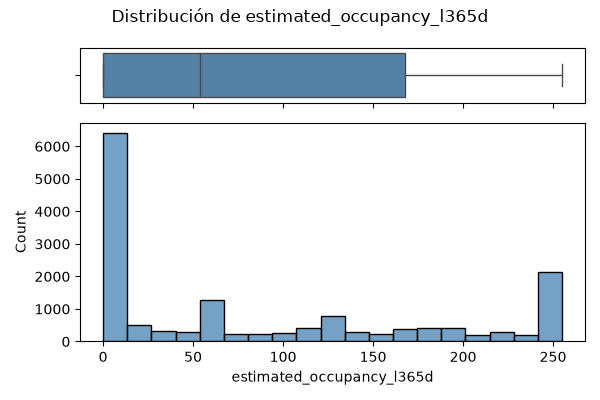

Q1=0.0  mediana=54.0  Q3=168.0  limite superior atipicos=420.0
nulos=0  con 0=5627 (36.8%)
anuncios con 0 reseñas ltm: 5627, de esos con occupancy 0: 5627


In [46]:
col = "estimated_occupancy_l365d"
ruta = graficar_numerica(listings[col], col, CARPETA_LISTINGS)
display(Image(ruta))

s = listings[col]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()}  con 0={(s==0).sum()} ({(s==0).mean()*100:.1f}%)")

con_0_reviews = listings[listings["number_of_reviews_ltm"] == 0]
coincide = (con_0_reviews[col] == 0).sum()
print(f"anuncios con 0 reseñas ltm: {len(con_0_reviews)}, de esos con occupancy 0: {coincide}")

Percentiles: 25% = 0, mediana = 54, 75% = 168. Sin atípicos (límite 420,
máximo posible 255 por el tope de ocupación del 70%). 36,8% con ocupación 0
(5.627).

Confirmado: los 5.627 anuncios con 0 reseñas en el último año tienen,
exactamente los 5.627, ocupación estimada 0 — coincidencia del 100%. Es el
mecanismo exacto que origina `revenue_no_estimable`.

### Cruce: `estimated_occupancy_l365d` según tipo de anfitrión

Esta es la pieza que conecta todo el hilo: `estimated_revenue_l365d = estimated_occupancy_l365d x price`. Si la ocupación estimada ya es mucho más baja en profesionales, explica directamente por qué su ingreso es menor pese a un precio similar.

,Mediana,Media,n
tipo_anfitrion,,,
Particular,64.0,96.23,11728
Profesional,0.0,54.70,3565


% con ocupacion estimada 0:
tipo_anfitrion
Particular     31.2
Profesional    55.2
Name: estimated_occupancy_l365d, dtype: float64


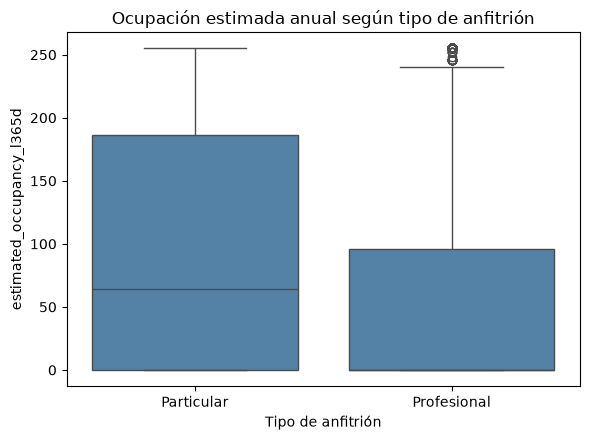

In [47]:
tabla_cruce = listings.groupby("tipo_anfitrion")["estimated_occupancy_l365d"].agg(
    Mediana="median", Media="mean", n="count"
)
display(tabla_cruce.round(2))

print("% con ocupación estimada 0:")
print(listings.groupby("tipo_anfitrion")["estimated_occupancy_l365d"].apply(lambda s: (s == 0).mean() * 100).round(1))

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=listings, x="tipo_anfitrion", y="estimated_occupancy_l365d", order=["Particular", "Profesional"], color="steelblue", ax=ax)
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("estimated_occupancy_l365d")
ax.set_title("Ocupación estimada anual según tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/occupancy_tipo_anfitrion.png", dpi=100)
plt.show()

Diferencia contundente: mediana de 0 en profesionales frente a 64 en particulares. Es decir, **más de la mitad** de los anuncios profesionales tienen ocupación estimada nula, frente a una minoría en particulares.

Esta es la explicación directa, a nivel de fórmula, del hallazgo de ingresos: si `estimated_revenue_l365d = estimated_occupancy_l365d x price`, y la ocupación mediana de los profesionales es 0, su ingreso también tiende a 0 — independientemente de cuánto cobren por noche. Conecta exactamente con `availability_365` (más días libres en profesionales) y con `minimum_nights` (habitaciones privadas con estancias de 32 noches en profesionales): menos reservas reales, menos ocupación, menos ingreso.

### `estimated_revenue_l365d`

Variable objetivo del proyecto. Ingreso anual estimado: `estimated_occupancy_l365d x price`.

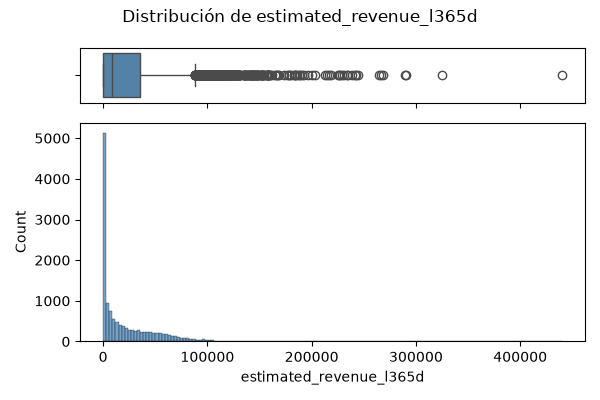

Q1=0.0  mediana=8268.0  Q3=35218.0  limite superior atipicos=88045.0
nulos=1938 (12.7%)  max real=440130.0
con 0=4181 (27.3%)


In [48]:
col = "estimated_revenue_l365d"
ruta = graficar_numerica(listings[col], col, CARPETA_LISTINGS)
display(Image(ruta))

s = listings[col]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)  max real={s.max()}")
print(f"con 0={(s==0).sum()} ({(s==0).mean()*100:.1f}%)")

Percentiles: 25% = 0, mediana = 8.268, 75% = 35.218. Atípicos a partir de
88.045 - máximo real 440.130. 12,7% nulos (1.938, anuncios sin `price`).
27,3% con 0 euros (4.181) — más amplio que los 2.686 de `revenue_no_estimable` (ver nota debajo).

### Nota: `revenue_no_estimable`

No es una columna de `listings.csv` — se crea en notebook 05 (tratamiento y
curación), no existe en los datos crudos que usamos en este notebook.

Qué es: una columna booleana (True/False) que marca los anuncios donde
`estimated_revenue_l365d` probablemente no es un ingreso real, sino un 0
artificial por cómo Inside Airbnb calcula esta métrica.

Cómo se define: True cuando se cumplen a la vez las dos condiciones:
`number_of_reviews_ltm == 0` (0 reseñas en el último año) Y
`minimum_nights >= 28` (estancia mínima de 28 noches o más).

Para qué se usa: para no tratar esos 2.686 casos como ingreso real al
calcular promedios de negocio, y para no entrenar el modelo con ellos como
si fueran ejemplos válidos de "esto gana 0€".

### Cruce: `estimated_revenue_l365d` según tipo de anfitrión

Esta es la variable correcta para comparar rentabilidad entre particulares y profesionales — no `price` (ver cruce anterior, que solo mide tarifa por noche, no ingreso real). Es el caso de negocio central del proyecto.

,Todos los anuncios (€),Excluyendo revenue_no_estimable (€)
tipo_anfitrion,,
Particular,24337.53,28794.35
Profesional,14677.54,22133.52



Diferencia porcentual:


,Todos los anuncios,Excluyendo revenue_no_estimable
Profesional vs. Particular,-39.7%,-23.1%


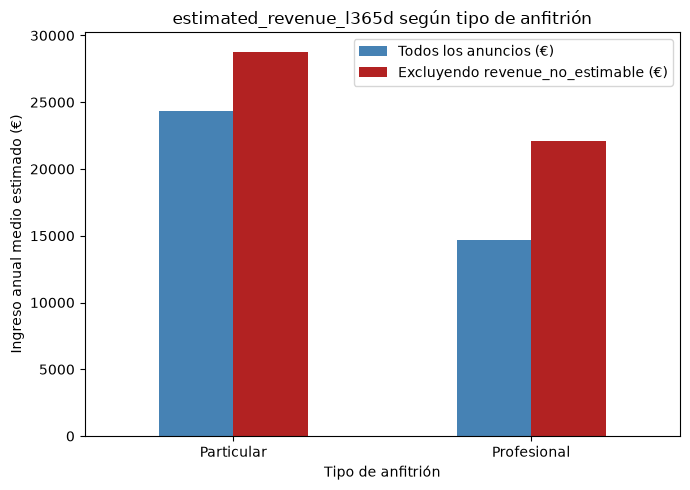

In [49]:
con_precio = listings[listings["price"].notna()].copy()
con_precio["revenue_no_estimable"] = (con_precio["number_of_reviews_ltm"] == 0) & (con_precio["minimum_nights"] >= 28)

media_cruda = con_precio.groupby("tipo_anfitrion")["estimated_revenue_l365d"].mean()
media_sin_no_estimable = con_precio[~con_precio["revenue_no_estimable"]].groupby("tipo_anfitrion")["estimated_revenue_l365d"].mean()

tabla = pd.DataFrame({"Todos los anuncios (€)": media_cruda, "Excluyendo revenue_no_estimable (€)": media_sin_no_estimable})
tabla = tabla.reindex(["Particular", "Profesional"])
display(tabla.round(2))

gap_crudo = (tabla.loc["Profesional", "Todos los anuncios (€)"] / tabla.loc["Particular", "Todos los anuncios (€)"] - 1) * 100
gap_sin = (tabla.loc["Profesional", "Excluyendo revenue_no_estimable (€)"] / tabla.loc["Particular", "Excluyendo revenue_no_estimable (€)"] - 1) * 100

tabla_gap = pd.DataFrame({
    "Todos los anuncios": [f"{gap_crudo:.1f}%"],
    "Excluyendo revenue_no_estimable": [f"{gap_sin:.1f}%"],
}, index=["Profesional vs. Particular"])
print()
print("Diferencia porcentual:")
display(tabla_gap)

fig, ax = plt.subplots(figsize=(7, 5))
tabla.plot(kind="bar", ax=ax, color=["steelblue", "firebrick"])
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("Ingreso anual medio estimado (€)")
ax.set_title("estimated_revenue_l365d según tipo de anfitrión")
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/revenue_tipo_anfitrion.png", dpi=100)
plt.show()

Resultado contraintuitivo: los **particulares rinden más** que los profesionales, no al revés. En crudo, los profesionales ganan un 39,7% menos por anuncio al año (14.677,54€ vs. 24.337,53€ en particulares). Al excluir los anuncios con `revenue_no_estimable = True` (ceros artificiales por el fallo de cálculo ya documentado), el gap se reduce pero sigue siendo grande: 23,1% (22.133,52€ vs. 28.794,35€).

Esto contrasta directamente con el cruce anterior de `price`: los profesionales cobran un precio por noche similar o algo más alto, pero generan menos ingreso anual — señal de que la diferencia no está en la tarifa, sino en la ocupación real (menos reservas, más noches vacías) que `estimated_revenue_l365d` sí captura y `price` no.

**Aclaración importante**: esta comparación es el ingreso medio **por anuncio individual**, no el total facturado por cada anfitrión. Un anfitrión profesional con, por ejemplo, 100 anuncios puede facturar mucho más en total que un particular con 1 anuncio, aunque cada uno de sus anuncios individualmente rinda menos — son preguntas distintas ("¿qué anuncio rinde mejor en promedio?" vs. "¿qué anfitrión factura más en total?"). Este cruce responde solo la primera.

### ¿Y en total (sumando todos los anuncios de cada grupo)?

La aclaración de arriba deja abierta la pregunta: ¿gana más el grupo profesional si se suma todo su negocio, aunque cada anuncio individual rinda menos? Se comprueba sumando `estimated_revenue_l365d` de todos los anuncios de cada grupo.

In [50]:
tabla_total = listings.groupby("tipo_anfitrion")["estimated_revenue_l365d"].agg(Total="sum", n="count")
tabla_total["%_del_total"] = (tabla_total["Total"] / tabla_total["Total"].sum() * 100).round(1)
display(tabla_total)

,Total,n,%_del_total
tipo_anfitrion,,,
Particular,242304462.0,9956,82.9
Profesional,49888950.0,3399,17.1


Los particulares ganan también en total, y por mucho: 242.304.462€ (82,9% del ingreso estimado total) frente a 49.888.950€ (17,1%) de los profesionales.

No es solo que rindan mejor por anuncio — también son muchos más en cantidad (9.956 vs. 3.399 anuncios con precio disponible). Las dos ventajas se suman en vez de compensarse: los profesionales no logran compensar su peor rendimiento individual con el volumen de su cartera.

### Cruce: `room_type` y `property_type` según tipo de anfitrión

¿La brecha de ingresos se explica porque los profesionales gestionan un tipo de alojamiento distinto (con menos potencial de ingresos)? Se comprueba con `room_type` (resumen) y `property_type` (detalle).

Barras agrupadas (no apiladas): así se ven las 4 categorías por separado, incluidas `Hotel room` y `Shared room` aunque sean muy pequeñas (menos del 1%).

room_type,Entire home/apt,Hotel room,Private room,Shared room
tipo_anfitrion,,,,
Particular,68.1,0.5,30.3,1.0
Profesional,80.0,0.1,19.7,0.1


Ingreso medio por room_type (referencia, sin separar por tipo de anfitrion):


room_type
Entire home/apt    27224.90
Hotel room         22760.85
Private room        4762.98
Shared room         7733.29
Name: estimated_revenue_l365d, dtype: float64

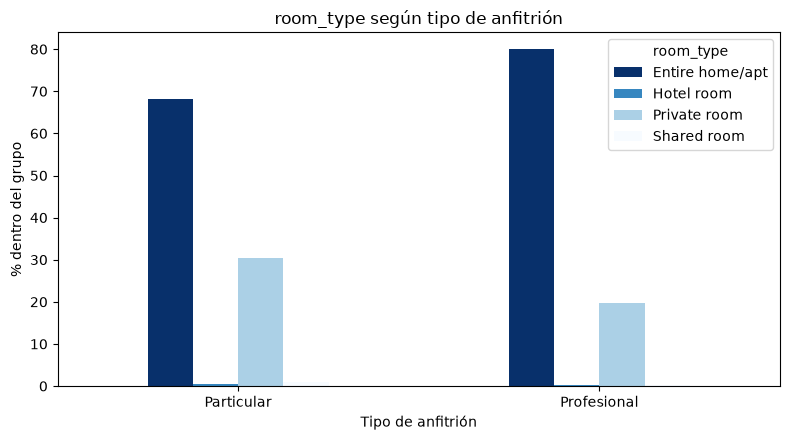


Top 3 property_type por tipo de anfitrion:
Particular
property_type
Entire rental unit             59.5
Private room in rental unit    20.0
Room in hotel                   3.8
Name: proportion, dtype: float64

Profesional
property_type
Entire rental unit             78.3
Private room in rental unit    19.1
Entire condo                    0.9
Name: proportion, dtype: float64



In [51]:
tabla_room = pd.crosstab(listings["tipo_anfitrion"], listings["room_type"], normalize="index") * 100
display(tabla_room.round(1))

print("Ingreso medio por room_type (referencia, sin separar por tipo de anfitrión):")
display(listings.groupby("room_type")["estimated_revenue_l365d"].mean().round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
tabla_room.plot(kind="bar", stacked=False, ax=ax, colormap="Blues_r")
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("% dentro del grupo")
ax.set_title("room_type según tipo de anfitrión")
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/room_type_tipo_anfitrion.png", dpi=100)
plt.show()

print()
print("Top 3 property_type por tipo de anfitrión:")
for t in ["Particular", "Profesional"]:
    print(t)
    print((listings[listings["tipo_anfitrion"] == t]["property_type"].value_counts(normalize=True).head(3) * 100).round(1))
    print()

Los profesionales están **más** concentrados en "Entire home/apt" (80,0% vs. 68,1% en particulares) y **menos** en "Private room" (19,7% vs. 30,3%). "Entire home/apt" es, además, la categoría con más ingreso medio de las cuatro (27.224,90€/año, frente a 4.762,98€ en "Private room").

Esto descarta la hipótesis de que la brecha de ingresos se explica por un peor tipo de alojamiento: los profesionales gestionan, en proporción, **más** del tipo de alojamiento que más factura, no menos. Si solo importara el tipo de propiedad, los profesionales deberían rendir mejor por anuncio, no peor — lo que hace el hallazgo de `estimated_revenue_l365d` más llamativo, no menos: la brecha existe pese a una combinación de tipo de alojamiento favorable para ese grupo. A nivel de `property_type`, el patrón es el mismo: "Entire rental unit" es más frecuente entre profesionales (78,3% vs. 59,5%).

### Cruce: `estimated_revenue_l365d` por tipo de anfitrión, controlando por `room_type`

Comparación más justa que la anterior: en vez de mezclar todos los anuncios, se compara particular vs. profesional **dentro de cada `room_type`** por separado, para que la diferencia no se deba a que un grupo tenga más pisos enteros y el otro más habitaciones.

Media     n
room_type       tipo_anfitrion                
Entire home/apt Particular      30741.63  7357
                Profesional     17840.56  2757
Hotel room      Particular      22214.84    57
                Profesional     28985.40     5
Private room    Particular       5768.43  2449
                Profesional       872.99   633
Shared room     Particular       8012.04    93
                Profesional      1252.25     4

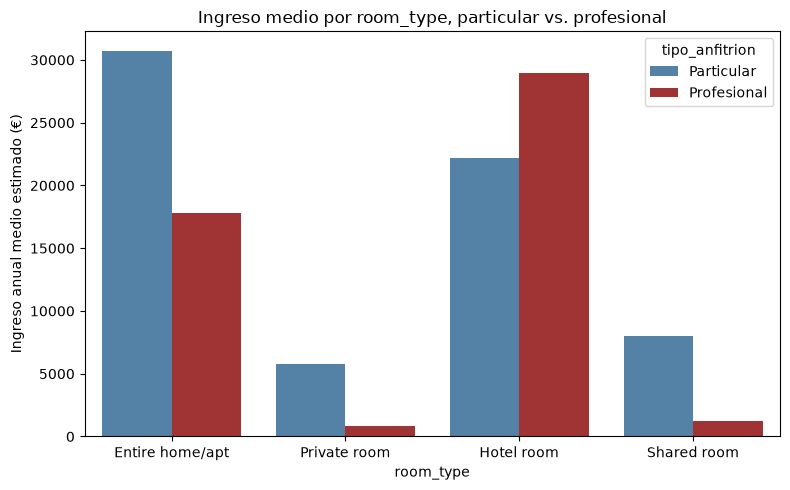

In [52]:
con_precio = listings[listings["price"].notna()].copy()
con_precio["revenue_no_estimable"] = (con_precio["number_of_reviews_ltm"] == 0) & (con_precio["minimum_nights"] >= 28)

tabla = con_precio.groupby(["room_type", "tipo_anfitrion"])["estimated_revenue_l365d"].agg(Media="mean", n="count")
display(tabla.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=con_precio, x="room_type", y="estimated_revenue_l365d", hue="tipo_anfitrion",
            hue_order=["Particular", "Profesional"], order=["Entire home/apt", "Private room", "Hotel room", "Shared room"],
            palette={"Particular": "steelblue", "Profesional": "firebrick"}, ax=ax, errorbar=None)
ax.set_xlabel("room_type")
ax.set_ylabel("Ingreso anual medio estimado (€)")
ax.set_title("Ingreso medio por room_type, particular vs. profesional")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/revenue_room_type_tipo_anfitrion.png", dpi=100)
plt.show()

La brecha **se mantiene** controlando por `room_type` — no es un efecto de mezcla de tipos de alojamiento:

- **Entire home/apt** (la categoría con más anuncios de ambos grupos): particulares 30.741,63€ vs. profesionales 17.840,56€ — los profesionales ganan un 42% menos en la categoría donde más compiten.
- **Private room**: particulares 5.768,43€ vs. profesionales solo 872,99€ — la brecha relativa más grande de las cuatro.
- **Hotel room**: aquí se invierte (profesionales 28.985,40€ vs. particulares 22.214,84€), pero no es un patrón del grupo profesional — los 5 anuncios profesionales de esta categoría pertenecen todos a una sola cuenta (`host_id` 32037490, "Sweett"), un hotel boutique ("La Palacete by Sweett") con 5 habitaciones individuales publicadas. Con n=5 y una sola empresa, no se puede generalizar a "los profesionales" como grupo — es un caso individual, no evidencia estadística.
- **Shared room**: muestra aún más pequeña en profesionales (4 anuncios), tampoco fiable.

Con esto se descarta la hipótesis de que el tipo de alojamiento explica la brecha: incluso comparando "piso entero contra piso entero" y "habitación contra habitación" — las dos categorías con muestras grandes y fiables en ambos grupos — los particulares rinden más por anuncio que los profesionales.

### Resumen combinado: cantidad de anuncios e ingreso total, por `room_type` y tipo de anfitrión

Para no mezclar "cuántos hay" con "cuánto ganan en promedio": dos paneles lado a lado, mismo eje `room_type`, uno con el número de anuncios y otro con el ingreso **total** sumado (no el promedio) de cada combinación.

n  Ingreso_total  Ingreso_medio
room_type       tipo_anfitrion                                    
Entire home/apt Particular      7357    226166205.0       30741.63
                Profesional     2757     49186413.0       17840.56
Hotel room      Particular        57      1266246.0       22214.84
                Profesional        5       144927.0       28985.40
Private room    Particular      2449     14126891.0        5768.43
                Profesional      633       552601.0         872.99
Shared room     Particular        93       745120.0        8012.04
                Profesional        4         5009.0        1252.25

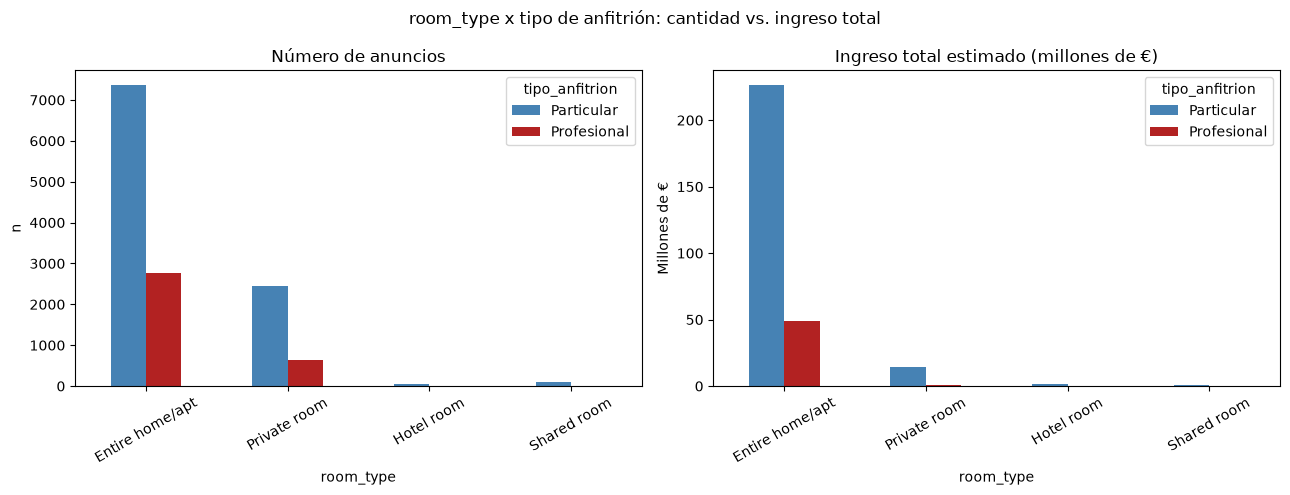

In [53]:
con_precio = listings[listings["price"].notna()].copy()
resumen = con_precio.groupby(["room_type", "tipo_anfitrion"])["estimated_revenue_l365d"].agg(
    n="count", Ingreso_total="sum", Ingreso_medio="mean"
)
display(resumen.round(2))

orden_room = ["Entire home/apt", "Private room", "Hotel room", "Shared room"]
n_tabla = resumen["n"].unstack("tipo_anfitrion").reindex(orden_room)
ingreso_tabla = (resumen["Ingreso_total"].unstack("tipo_anfitrion").reindex(orden_room) / 1_000_000)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

n_tabla.plot(kind="bar", ax=axes[0], color={"Particular": "steelblue", "Profesional": "firebrick"})
axes[0].set_title("Número de anuncios")
axes[0].set_xlabel("room_type")
axes[0].set_ylabel("n")
axes[0].tick_params(axis="x", rotation=30)

ingreso_tabla.plot(kind="bar", ax=axes[1], color={"Particular": "steelblue", "Profesional": "firebrick"})
axes[1].set_title("Ingreso total estimado (millones de €)")
axes[1].set_xlabel("room_type")
axes[1].set_ylabel("Millones de €")
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle("room_type x tipo de anfitrión: cantidad vs. ingreso total")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/resumen_room_type_tipo_anfitrion.png", dpi=100)
plt.show()

En **total** (no promedio), los particulares facturan más que los profesionales en las 4 categorías — incluida "Hotel room", pese a que ahí el *promedio* por anuncio favorecía a los profesionales (ver cruce anterior). La razón es el volumen: 57 anuncios particulares de "Hotel room" (con precio disponible) suman 1.266.246€ en total, frente a 144.927€ de los 5 profesionales — el promedio más alto de esos 5 no compensa tenerlos solo 5.

En "Entire home/apt", la categoría más grande: 7.357 particulares suman 226.166.205€ frente a 49.186.413€ de 2.757 profesionales. Confirma, con la vista de totales, lo mismo que ya se vio con promedios: el grupo particular rinde mejor por anuncio, y además son mayoría, así que también domina en ingreso agregado dentro de cada tipo de alojamiento.

### Tabla completa: `estimated_revenue_l365d` por `property_type` y tipo de anfitrión

Las 47 categorías de `property_type` que tienen al menos un anuncio con `price` disponible, con su ingreso medio estimado por tipo de anfitrión. Solo 3 tienen una muestra fiable (≥30) en ambos grupos a la vez — se marcan en la columna `fiable`; el resto se incluye por completitud, no como evidencia.

In [54]:
con_precio = listings[listings["price"].notna()].copy()

n_tabla = con_precio.groupby(["property_type", "tipo_anfitrion"]).size().unstack("tipo_anfitrion").fillna(0).astype(int)
media_tabla = con_precio.groupby(["property_type", "tipo_anfitrion"])["estimated_revenue_l365d"].mean().unstack("tipo_anfitrion")

tabla = pd.DataFrame({
    "n_Particular": n_tabla.get("Particular", 0),
    "n_Profesional": n_tabla.get("Profesional", 0),
    "Media_Particular (€)": media_tabla.get("Particular"),
    "Media_Profesional (€)": media_tabla.get("Profesional"),
})
tabla["n_total"] = tabla["n_Particular"] + tabla["n_Profesional"]
tabla["fiable (n>=30 en ambos)"] = (tabla["n_Particular"] >= 30) & (tabla["n_Profesional"] >= 30)
tabla = tabla.sort_values("n_total", ascending=False)

pd.set_option("display.max_rows", None)
display(tabla.round(2))
print()
print("Categorias fiables:", tabla["fiable (n>=30 en ambos)"].sum(), "de", len(tabla))

,n_Particular,n_Profesional,Media_Particular (€),Media_Profesional (€),n_total,fiable (n>=30 en ambos)
property_type,,,,,,
Entire rental unit,6427,2701,30351.35,17912.42,9128,True
Private room in rental unit,1495,612,3284.64,727.05,2107,True
Entire serviced apartment,323,18,41676.52,8812.89,341,False
Room in hotel,333,5,9715.83,28985.40,338,False
Entire condo,254,32,35190.70,16488.78,286,True
Private room in hostel,196,0,14764.07,NaN,196,False
Entire loft,172,0,26373.20,NaN,172,False
Private room in home,109,16,5584.40,1229.94,125,False
Room in boutique hotel,114,0,11765.89,NaN,114,False



Categorias fiables: 3 de 47


Las 3 categorías fiables (Entire rental unit, Private room in rental unit, Entire condo) repiten el mismo patrón ya visto: particulares con mayor ingreso medio que profesionales. Entre las 44 restantes no fiables, 35 tienen **0 anuncios profesionales** — categorías donde, en este dataset, solo hay particulares (ej. "Private room in hostel", "Entire loft", "Boat"), así que ni siquiera hay comparación posible ahí.

La fila de "Room in hotel" (no confundir con "Room in boutique hotel", que es el hotelito "Sweett" ya explicado en el cruce de `room_type`) es otro caso de muestra muy chica en profesionales (5), con ingreso medio más alto en ese grupo — mismo tipo de advertencia que ya se hizo antes, no es evidencia generalizable.

### Cruce: `estimated_revenue_l365d` según distrito

El ángulo geográfico: ¿qué distritos de Barcelona generan más ingreso estimado por anuncio?

,Mediana,Media,n
neighbourhood_group_cleansed,,,
Eixample,13354.5,28530.62,5194
Gràcia,11376.0,23869.85,1197
Sant Martí,13245.0,23455.47,1235
Sants-Montjuïc,11886.5,21557.96,1276
Les Corts,7733.5,16236.47,272
Horta-Guinardó,5127.5,15027.86,290
Ciutat Vella,4394.0,13688.80,2788
Sarrià-Sant Gervasi,1914.0,12690.22,779
Sant Andreu,1565.0,8935.07,182


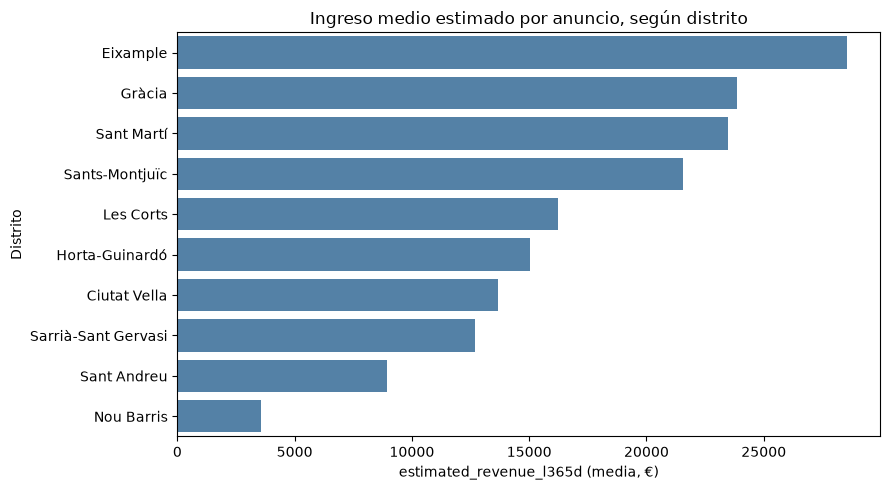

In [55]:
tabla_cruce = listings.groupby("neighbourhood_group_cleansed")["estimated_revenue_l365d"].agg(
    Mediana="median", Media="mean", n="count"
).sort_values("Media", ascending=False)
display(tabla_cruce.round(2))

orden = tabla_cruce.index
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=tabla_cruce["Media"], y=orden, color="steelblue", ax=ax)
ax.set_xlabel("estimated_revenue_l365d (media, €)")
ax.set_ylabel("Distrito")
ax.set_title("Ingreso medio estimado por anuncio, según distrito")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/revenue_distrito.png", dpi=100)
plt.show()

Eixample tiene el ingreso medio más alto (28.530,62€), seguido de Gràcia (23.869,85€) y Sant Martí (23.455,47€). En el otro extremo, Nou Barris tiene el más bajo con diferencia (3.570,86€, mediana 0€ — la mitad de sus anuncios no genera ingreso estimable), seguido de Sant Andreu (8.935,07€).

Dato llamativo: Sarrià-Sant Gervasi, el distrito con mayor proporción de anfitriones profesionales (38,7%, visto en el cruce de distrito x tipo de anfitrión), tiene un ingreso medio relativamente bajo (12.690,22€, el octavo de diez) pese a ser una zona de nivel socioeconómico alto — coherente con el patrón ya establecido de que más concentración profesional no implica mejor rendimiento por anuncio.

### Cruce: `estimated_revenue_l365d` según distrito y tipo de anfitrión (los tres juntos)

Combina los dos cruces anteriores: ¿se mantiene la ventaja de los particulares en cada distrito por separado, o es solo un efecto agregado?

Media     n
neighbourhood_group_cleansed tipo_anfitrion                
Ciutat Vella                 Particular      14868.09  2274
                             Profesional      8471.48   514
Eixample                     Particular      33276.46  3574
                             Profesional     18060.48  1620
Gràcia                       Particular      27247.74   917
                             Profesional     12807.25   280
Horta-Guinardó               Particular      15667.42   226
                             Profesional     12769.42    64
Les Corts                    Particular      17167.43   221
                             Profesional     12202.29    51
Nou Barris                   Particular       5158.99    84
                             Profesional      1270.81    58
Sant Andreu                  Particular      11204.21   144
                             Profesional       336.21    38
Sant Martí                   Particular      23791.25  1049
                             Profesional     21561.78   186
Sants-Montjuïc               Particular      22149.30  1003
                             Profesional     19385.37   273
Sarrià-Sant Gervasi          Particular      17292.71   464
                             Profesional      5910.68   315

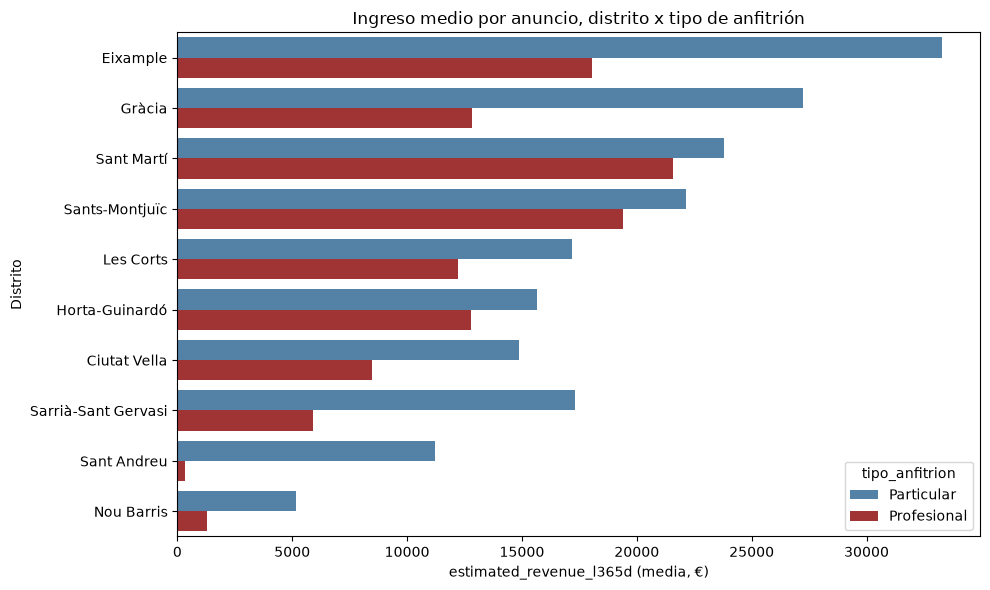

In [56]:
tabla_cruce = listings.groupby(["neighbourhood_group_cleansed", "tipo_anfitrion"])["estimated_revenue_l365d"].agg(
    Media="mean", n="count"
)
display(tabla_cruce.round(2))

orden_distrito = listings.groupby("neighbourhood_group_cleansed")["estimated_revenue_l365d"].mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=listings, y="neighbourhood_group_cleansed", x="estimated_revenue_l365d", hue="tipo_anfitrion",
            order=orden_distrito, hue_order=["Particular", "Profesional"],
            palette={"Particular": "steelblue", "Profesional": "firebrick"}, estimator="mean", errorbar=None, ax=ax)
ax.set_xlabel("estimated_revenue_l365d (media, €)")
ax.set_ylabel("Distrito")
ax.set_title("Ingreso medio por anuncio, distrito x tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/revenue_distrito_tipo_anfitrion.png", dpi=100)
plt.show()

La ventaja de los particulares **no es un efecto agregado** — se mantiene en los 10 distritos, sin una sola excepción. El caso más extremo es Sant Andreu: particulares 11.204,21€ vs. profesionales solo 336,21€ (aunque con una muestra pequeña de 38 profesionales ahí). Eixample, el distrito con más anuncios, también tiene una de las brechas más grandes en términos absolutos (33.276,46€ vs. 18.060,48€).

Esto descarta definitivamente la hipótesis de que la brecha de ingresos se debiera a que los particulares están concentrados en distritos más caros: controlando por distrito, el patrón se repite siempre en la misma dirección.

### `first_review`

Fecha de la primera reseña que recibió el alojamiento.

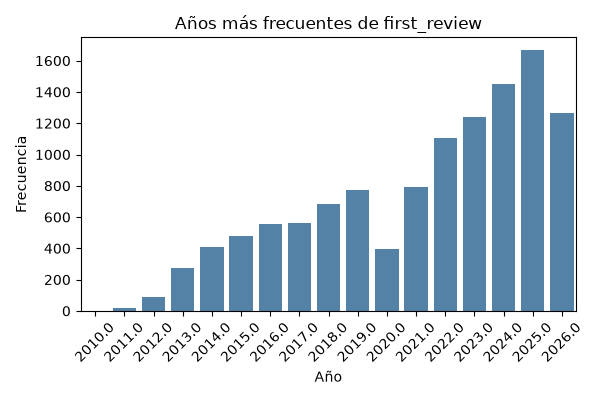

nulos=3548
minima=2010-10-03 00:00:00  maxima=2026-06-24 00:00:00
first_review
2010.0       1
2011.0      19
2012.0      87
2013.0     274
2014.0     409
2015.0     476
2016.0     557
2017.0     559
2018.0     685
2019.0     770
2020.0     393
2021.0     790
2022.0    1103
2023.0    1240
2024.0    1448
2025.0    1666
2026.0    1268
Name: count, dtype: int64


In [57]:
fecha_first = pd.to_datetime(listings["first_review"])
ruta = graficar_fecha(fecha_first, "first_review", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={fecha_first.isna().sum()}")
print(f"mínima={fecha_first.min()}  máxima={fecha_first.max()}")
print(fecha_first.dt.year.value_counts().sort_index())

3.548 nulos — exactamente los alojamientos sin ninguna reseña. Rango real: 2010-10-03 a 2026-06-24.

Caída visible en 2020 (393, frente a 770 en 2019 y 1.103 en 2022) —
coherente con la pandemia de COVID-19 y su impacto en el turismo ese año.

### Cruce: `first_review` según tipo de anfitrión

¿Los anuncios profesionales son más recientes en la plataforma que los particulares?

tipo_anfitrion
Particular    2022-05-01
Profesional   2024-02-18
dtype: datetime64[us]


tipo_anfitrion,Particular,Profesional
first_review,,
2010.0,100.0,0.0
2011.0,94.7,5.3
2012.0,87.4,12.6
2013.0,99.6,0.4
2014.0,96.8,3.2
2015.0,94.5,5.5
2016.0,95.3,4.7
2017.0,93.4,6.6
2018.0,90.7,9.3


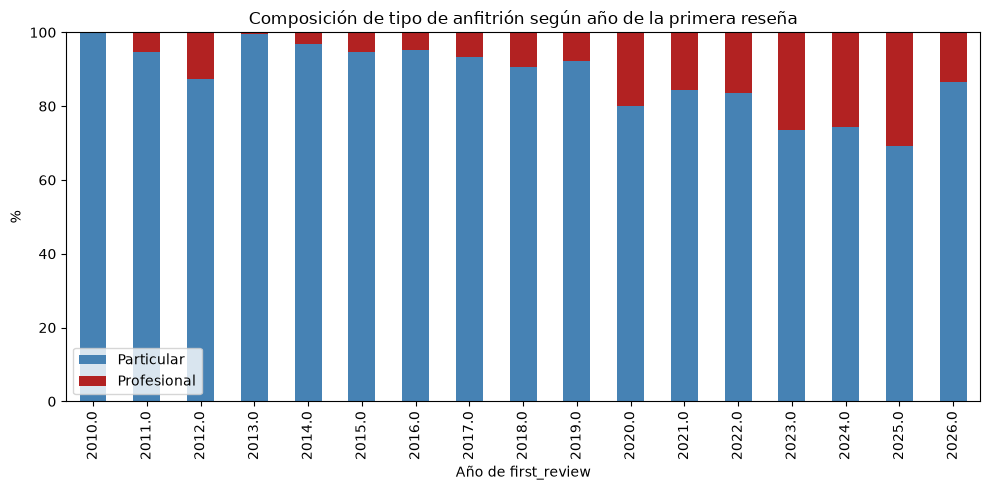

In [58]:
fecha_fr = pd.to_datetime(listings["first_review"])
print(listings.groupby("tipo_anfitrion").apply(lambda g: pd.to_datetime(g["first_review"]).median(), include_groups=False))

año = fecha_fr.dt.year
tabla_pct = pd.crosstab(año, listings["tipo_anfitrion"], normalize="index") * 100
display(tabla_pct.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
tabla_pct.plot(kind="bar", stacked=True, ax=ax, color=["steelblue", "firebrick"])
ax.set_xlabel("Año de first_review")
ax.set_ylabel("%")
ax.set_title("Composición de tipo de anfitrión según año de la primera reseña")
ax.legend(title="")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/first_review_tipo_anfitrion.png", dpi=100)
plt.show()

Sí, con una tendencia clara: la mediana de `first_review` es 2022-05-01 en particulares vs. 2024-02-18 en profesionales, casi 2 años más tarde.

Visto año a año, el peso de los profesionales entre los anuncios que estrenan su primera reseña ese año crece de forma sostenida: 5-7% en 2011-2019, sube a 15-20% en 2020-2022, y llega a 25-31% en 2023-2025. 2026 baja a 13,4%, pero es un año incompleto (datos solo hasta junio) y con pocos casos, no una reversión real de la tendencia.

Esto sugiere que la presencia profesional en el mercado de Barcelona es un fenómeno relativamente reciente y creciente, no algo estable desde siempre — la proporción de anuncios nuevos gestionados por operadores a gran escala se ha más que cuadriplicado en 15 años.

### `has_availability`

Si el calendario del anuncio muestra algún día disponible (t) o está completamente bloqueado (f).

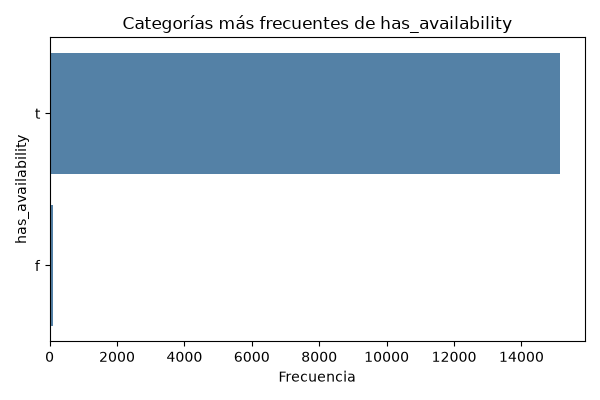

has_availability
t      15129
f         90
NaN       74
Name: count, dtype: int64
has_availability
f      289.5
t      239.0
NaN    269.0
Name: availability_365, dtype: float64


In [59]:
ruta = graficar_categorica(listings["has_availability"], "has_availability", CARPETA_LISTINGS)
display(Image(ruta))

print(listings["has_availability"].value_counts(dropna=False))
print(listings.groupby("has_availability", dropna=False)["availability_365"].median())

t=15.129 (98,9%), f=90 (0,6%), 74 nulos (0,5%).

Inconsistencia detectada: los anuncios con f ("sin disponibilidad") tienen
una mediana de availability_365 de 289,5 días — más alta que los t (239,0).
Es lo contrario de lo esperado. No hay una explicación confirmada para
esto, se deja documentado como inconsistencia, no como hallazgo explicado.

### Nota: posible explicación de la inconsistencia en `has_availability = "f"`

Relación entre los 90 casos marcados como "sin disponibilidad" y su `source`.

In [60]:
f_cases = listings[listings["has_availability"] == "f"]
print("room_type (f):")
print(f_cases["room_type"].value_counts())
print()
print("tipo_anfitrion (f):")
print(f_cases["tipo_anfitrion"].value_counts())
print()
print("minimum_nights (f):", f_cases["minimum_nights"].describe()[["mean", "50%", "min", "max"]].to_dict())
print()
print("source (f):")
print(f_cases["source"].value_counts())

pr = listings[listings["room_type"] == "Private room"]
t_cases_pr = pr[pr["has_availability"] == "t"]
print()
print("source (t, solo Private room, para comparar):")
print(t_cases_pr["source"].value_counts())
print(f"% previous scrape en t: {(t_cases_pr['source'] == 'previous scrape').mean() * 100:.1f}%")

room_type (f):
room_type
Private room    90
Name: count, dtype: int64

tipo_anfitrion (f):
tipo_anfitrion
Particular    90
Name: count, dtype: int64

minimum_nights (f): {'mean': 1.0, '50%': 1.0, 'min': 1.0, 'max': 1.0}

source (f):
source
previous scrape    90
Name: count, dtype: int64

source (t, solo Private room, para comparar):
source
city scrape        2891
previous scrape    1250
Name: count, dtype: int64
% previous scrape en t: 30.2%


El 100% de los 90 casos (todos `room_type = "Private room"`, todos particulares, todos con `minimum_nights = 1`) tienen `source = "previous scrape"` — frente a solo 30,2% entre los anuncios `Private room` con disponibilidad normal (`has_availability = "t"`).

`previous scrape` significa que el anuncio no apareció en la búsqueda normal de la ciudad, pero Inside Airbnb lo mantiene porque sigue activo, verificándolo individualmente en una fecha algo posterior (2-3 de julio, frente a 24-25 de junio del resto). Es plausible que `has_availability = "f"` en estos 90 casos venga de ese proceso de reverificación individual, mientras que su `availability_365` siga reflejando datos de calendario no actualizados junto con esa reverificación — de ahí la inconsistencia (dice "no disponible" pero el calendario muestra muchos días libres, probablemente obsoletos).

No es una explicación confirmada con los datos disponibles (no hay forma de verificar el mecanismo interno de Inside Airbnb), es una asociación fuerte y específica, no una causa probada.

### `host_about`

Texto libre donde el anfitrión se describe a sí mismo.

No se usa `graficar_categorica` aquí: `host_about` es texto libre, no cabe legible como etiqueta de eje. Se numeran las barras y se muestra el texto completo en una tabla.

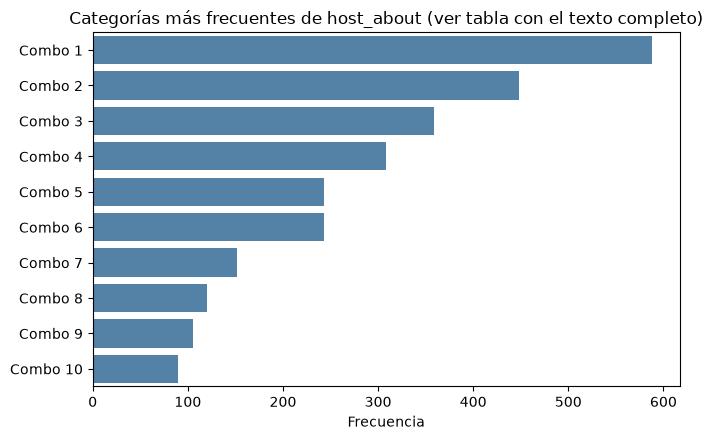

nulos=4859 (31.8%)
valores unicos=2406 de 10434



,Combo,Frecuencia,Contenido completo
0,Combo 1,588,"At Ukio, we've redefined the concept of living and working abroad. We offer fully-furnished, designer apartments for mid-to-long-term stays in Europe's most vibrant cities, combining comfort, flexibility, and premium service."
1,Combo 2,448,"Apartamentos ACOMODIS en Barcelona\n\nSomos un pequeña gran familia que ofrece apartamentos turísticos de calidad con atención personal. Siempre disponibles, garantizamos transparencia, experiencias únicas y recomendaciones locales para disfrutar Barcelona.\n\nNuestros alojamientos combinan comodidad y estilo, enriqueciendo tu experiencia. Nos dedicamos a ofrecer un servicio cercano y profesional para que disfrutes al máximo tu estancia en Barcelona."
2,Combo 3,359,Happy to offer a nice experience in Barcelona hosting you in nice flats !!
3,Combo 4,308,"Sweett (formerly Sweet Inn) invites you to enjoy comfort, convenience, and local charm in our thoughtfully designed apartments. With 10+ years of hosting experience, we ensure a home-like stay with cozy bedding, fast WiFi, and a Nespresso machine. Our 24/7 team assists with early check-ins, transfers, housekeeping, and local tips. Enjoy welcome treats, personalized recommendations, and our smart app. Sweett is your perfect base for urban escapes."
4,Combo 5,243,"Somos AB Apartment Barcelona, agencia local que gestiona más de 300 apartamentos turísticos legales en Barcelona desde 2007, todos con licencia HUTB visible en cada anuncio. Te acompañamos antes, durante y después de tu estancia con un trato cercano y personalizado. Conocemos la ciudad a fondo y te recomendamos restaurantes locales, visitas únicas y planes fuera de la ruta turística. Tendrás a tu disposición check-in online y asistencia 24h para emergencias. ¡Será un placer darte la bienvenida!"
5,Combo 6,243,"At Badi, we believe that finding a new home should be an exciting and enjoyable experience. That's why we've made it our mission to make the process of finding a mid-term rental as easy and stress-free as possible. Our company offers a wide variety of options, from private rooms to entire apartments, that cater to all types of travelers. Whether you're a student, professional, or simply on a long-term vacation, we've got you covered.\n\nWe understand that moving to a new city can be daunting, which is why we've made sure to include all the necessary amenities and services to make your transition as smooth as possible. From fully furnished properties to all-inclusive pricing, we take care of all the details so you can focus on what really matters. Our properties are carefully curated and inspected to ensure they meet our high standards of quality and comfort.\n\nWe pride ourselves on our commitment to trust and transparency. Our platform is designed to make it easy for you to find the perfect accommodation and to book it with confidence. From 24/7 customer support to verified reviews, we've got your back every step of the way."
6,Combo 7,152,"Stay Unique nació en Barcelona hace más de 20 años, recibiendo a los viajeros en persona y compartiendo la ciudad desde dentro. Ese origen marcó nuestra forma de hospedar: cercana, honesta y centrada en las personas.\nHoy gestionamos apartamentos en Barcelona, Málaga y Sevilla con el mismo cuidado, una gestión profesional reconocida con el World Travel Award 2025 como Mejor Marca de Apartamentos Turísticos en España. Ofrecemos asistencia 24 horas en varios idiomas, para que disfrutes al máximo."
7,Combo 8,120,"Habitat Apartments is a professional vacation rental agency with 19 years of experience welcoming guests to the city. We have been awarded, 4 years in a row, ""​​Spain's Leading Serviced Apartment Brand"" at the World Travel Awards.\n\nHow we do it?\n- We work with a professional cleaning & laundry company so you will find the apartment well prepared for your stay. We also work with a professional ​maintenance company available at any time.\n\n-​ ​We are available 24 hours a day, 7 

In [61]:
conteo = listings["host_about"].value_counts().head(10)
etiquetas_numeradas = [f"Combo {i+1}" for i in range(len(conteo))]

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=conteo.values, y=etiquetas_numeradas, color="steelblue", ax=ax)
ax.set_xlabel("Frecuencia")
ax.set_ylabel("")
ax.set_title("Categorías más frecuentes de host_about (ver tabla con el texto completo)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/listings/host_about_categorica.png", dpi=100)
plt.show()

s = listings["host_about"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(f"valores únicos={s.nunique()} de {s.notna().sum()}")
print()

tabla_combos = pd.DataFrame({
    "Combo": etiquetas_numeradas,
    "Frecuencia": conteo.values,
    "Contenido completo": conteo.index,
})
pd.set_option("display.max_colwidth", None)
display(tabla_combos)

No es útil tal cual: texto libre, mismo problema que `description`/`amenities` — resuelto igual (barras numeradas + tabla con el texto completo). 31,8% nulos (4.859) — una de las columnas que se imputa en notebook 05. 2.406 valores únicos de 10.434 no nulos.

### Extra: palabras más frecuentes en `host_about`

palabras totales (sin vacías): 393576


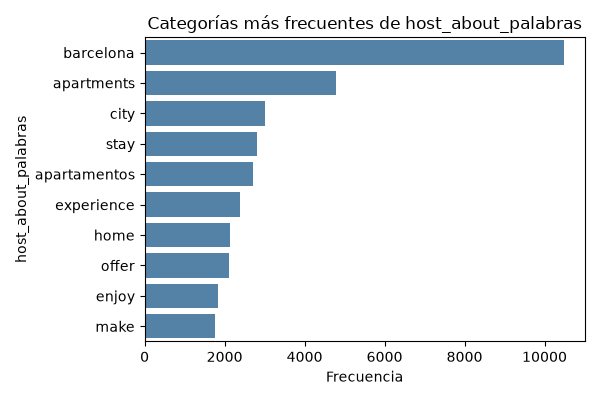

In [62]:
texto = listings["host_about"].dropna().str.lower()
palabras = texto.str.findall(r"[a-záéíóúñ]{3,}").explode()
stopwords = {"the","and","with","for","you","this","from","has","are","one","very","your",
             "not","but","all","can","will","that","our","its","out","use","per","non",
             "have","love","like","also","que","para","con","una","los","nos","las","del",
             "por","más","como","esta","son","soy"}
palabras_filtradas = palabras[~palabras.isin(stopwords)]
print("palabras totales (sin vacías):", len(palabras_filtradas))

ruta = graficar_categorica(palabras_filtradas, "host_about_palabras", "../graficos_exploracion/cruces")
display(Image(ruta))

Top palabras tras filtrar vacías en inglés y español: barcelona (10.487),
apartments (4.780), city (3.021), stay (2.821), apartamentos (2.718) —
mezcla de inglés y español, a diferencia de `description` que salia casi
todo en inglés.

### Extra: nube de palabras de `host_about` (complemento visual)

Complementa el gráfico de barras anterior — no lo reemplaza, porque una nube de palabras no permite leer la frecuencia exacta de cada palabra, solo da una idea visual rápida de cuáles dominan.

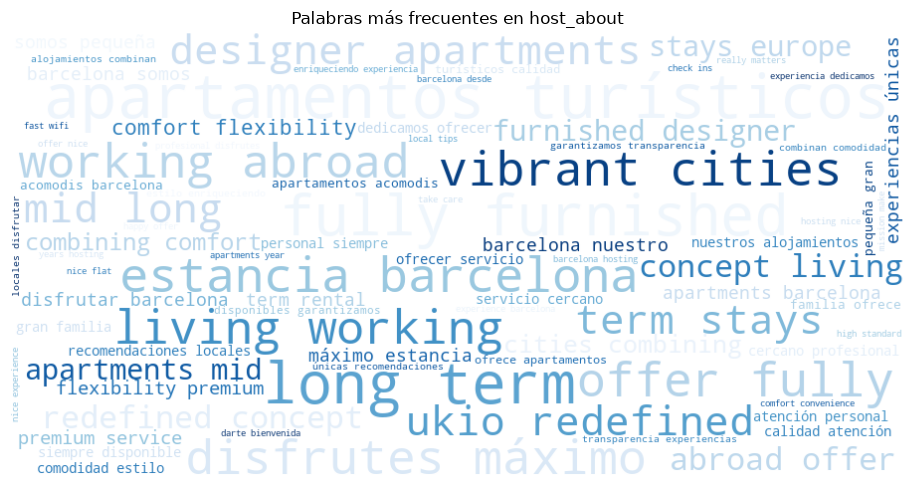

In [63]:
from wordcloud import WordCloud

texto_nube = " ".join(palabras_filtradas.dropna())
nube = WordCloud(width=900, height=450, background_color="white", colormap="Blues", max_words=80).generate(texto_nube)

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(nube, interpolation="bilinear")
ax.axis("off")
ax.set_title("Palabras más frecuentes en host_about")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/host_about_wordcloud.png", dpi=100)
plt.show()

In [64]:
ukio = listings[listings["host_name"] == "Ukio"]
print("Anuncios de Ukio:", len(ukio))
print("Valores únicos de host_about en Ukio:", ukio["host_about"].nunique())
print()

anfitriones_con_about = listings.dropna(subset=["host_about"])
print("Filas con host_about:", len(anfitriones_con_about))
print("Anfitriones únicos con host_about:", anfitriones_con_about["host_id"].nunique())
print("Filas por anfitrión único (promedio):", round(len(anfitriones_con_about) / anfitriones_con_about["host_id"].nunique(), 2))

Anuncios de Ukio: 588
Valores unicos de host_about en Ukio: 1

Filas con host_about: 10434
Anfitriones unicos con host_about: 2481
Filas por anfitrion unico (promedio): 4.21


**Nota metodológica**: tanto el gráfico de barras como la nube de palabras cuentan a nivel de **anuncio**, no de anfitrión. Los 588 anuncios de "Ukio" comparten el mismo texto exacto de `host_about` (1 único valor, 0 nulos), así que cada palabra de esa descripción se cuenta 588 veces, aunque el anfitrión solo la escribió una vez — de ahí que "ukio", "redefined" o "vibrant cities" aparezcan tan grandes en la nube.

En general, las 10.434 filas con `host_about` provienen de solo 2.481 anfitriones únicos (4,21 filas por anfitrión en promedio): los anfitriones con muchos anuncios pesan proporcionalmente más en este conteo que uno con un solo anuncio, aunque ambos hayan escrito su descripción una única vez. No es un error de cálculo, es una limitación propia de contar por fila en vez de por anfitrión único.

### Extra: anfitriones con más anuncios que tienen `host_about`

Quién pesa más en el conteo de palabras — los anfitriones con más filas (anuncios) con `host_about` presente.

host_name
Ukio                      588
Acomodis Apartments       448
Silvia De Lourdes         359
Sweett                    293
AB Apartment Barcelona    243
Badi Plus                 243
Stay Unique               154
Habitat Apartments        120
Alejandro                 105
Loca Bcn                  105
Name: count, dtype: int64

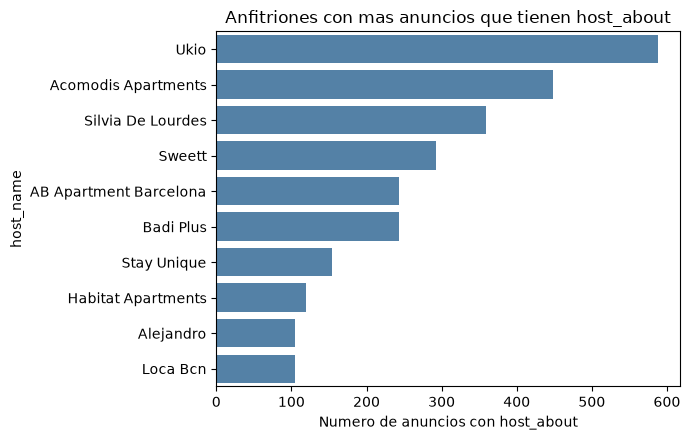

In [65]:
con_about = listings.dropna(subset=["host_about"])
top_hosts = con_about["host_name"].value_counts().head(10)
display(top_hosts)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=top_hosts.values, y=top_hosts.index, color="steelblue", ax=ax)
ax.set_xlabel("Número de anuncios con host_about")
ax.set_ylabel("host_name")
ax.set_title("Anfitriones con más anuncios que tienen host_about")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/top_hosts_host_about.png", dpi=100)
plt.show()

Ukio aparece primero, con diferencia (588 anuncios), seguido de Acomodis Apartments (448), Silvia De Lourdes (359) y Sweett (293, el hotelito ya visto en `room_type`). Los 10 primeros nombres son, sin excepción, anfitriones profesionales (`host_profesional = True`) — confirma que el sesgo del conteo de palabras hacia Ukio no es un caso aislado, es un patrón general de cómo los anfitriones con muchos anuncios dominan este tipo de análisis por fila.

### `host_acceptance_rate`

Porcentaje de solicitudes de reserva que el anfitrión acepta.

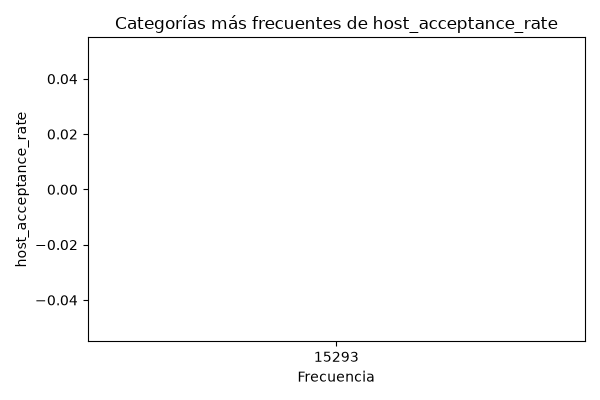

nulos=15293 de 15293


In [66]:
ruta = graficar_categorica(listings["host_acceptance_rate"], "host_acceptance_rate", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['host_acceptance_rate'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05.

### `host_has_profile_pic`

Si el anfitrión tiene foto de perfil puesta (t) o no (f).

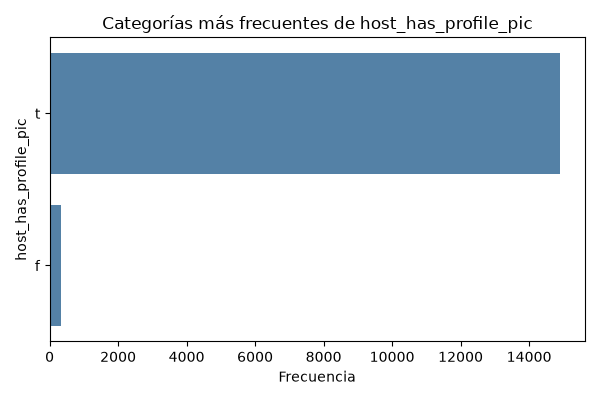

host_has_profile_pic
t      14888
f        318
NaN       87
Name: count, dtype: int64


In [67]:
ruta = graficar_categorica(listings["host_has_profile_pic"], "host_has_profile_pic", CARPETA_LISTINGS)
display(Image(ruta))

print(listings['host_has_profile_pic'].value_counts(dropna=False))

t=14.888 (97,3%), f=318 (2,1%), 87 nulos (0,6%).

### Cruce: `host_has_profile_pic` según reservas/ocupación

Hipótesis: un anfitrión sin foto de perfil genera menos confianza a la hora de reservar, así que sus anuncios deberían tener menos reservas reales. La puntuación (`review_scores_rating`) no sirve para esto porque solo mide a quienes ya tienen alguna reseña; mejor usar variables de volumen de reservas.

Medianas:


,number_of_reviews,estimated_occupancy_l365d,number_of_reviews_ltm
host_has_profile_pic,,,
f,0.0,0.0,0.0
t,10.0,60.0,2.0


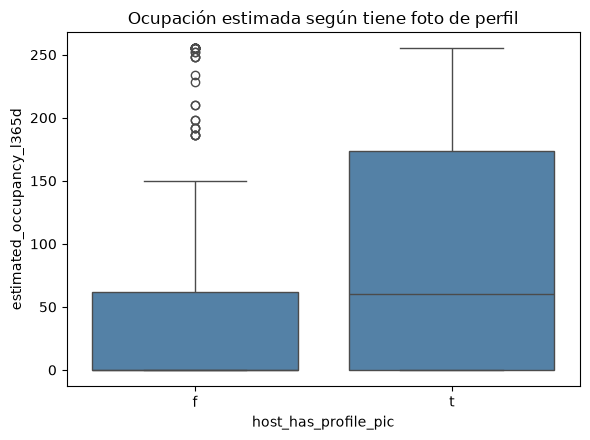

In [68]:
tabla = pd.DataFrame({
    "number_of_reviews": listings.groupby("host_has_profile_pic")["number_of_reviews"].median(),
    "estimated_occupancy_l365d": listings.groupby("host_has_profile_pic")["estimated_occupancy_l365d"].median(),
    "number_of_reviews_ltm": listings.groupby("host_has_profile_pic")["number_of_reviews_ltm"].median(),
})
print("Medianas:")
display(tabla)

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=listings, x="host_has_profile_pic", y="estimated_occupancy_l365d", order=["f", "t"], color="steelblue", ax=ax)
ax.set_xlabel("host_has_profile_pic")
ax.set_ylabel("estimated_occupancy_l365d")
ax.set_title("Ocupación estimada según tiene foto de perfil")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/profile_pic_ocupacion.png", dpi=100)
plt.show()

La hipótesis se confirma con claridad: los 318 anuncios sin foto de perfil tienen mediana de **0** en las 3 variables de volumen de reservas (`number_of_reviews`, `estimated_occupancy_l365d`, `number_of_reviews_ltm`), frente a 10, 60 y 2 respectivamente en los que sí tienen foto.

Esto explica por qué el `review_scores_rating` mostraba el patrón contrario (ligeramente más alto en los sin foto): esa puntuación solo existe para anuncios con al menos una reseña, y la mayoría de los 318 sin foto nunca llegan a tener ninguna — el bajo volumen de reservas, no la calidad percibida, es lo que diferencia a este grupo.

### `host_id`

Identificador del anfitrión. Es un ID, no una magnitud -- el histograma no
representa una distribución con sentido, solo confirma el rango de valores.

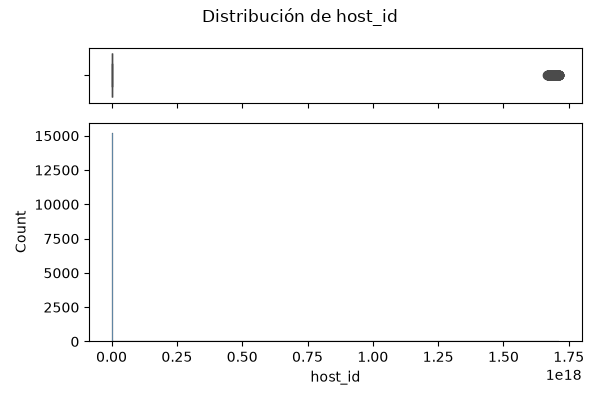

nulos=0  min=10704  max=1713762124075096543


In [69]:
ruta = graficar_numerica(listings["host_id"], "host_id", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["host_id"]
print(f"nulos={s.isna().sum()}  min={s.min()}  max={s.max()}")

0 nulos. Rango real: 10.704 a 1.713.762.124.075.096.543 (1,71x10^18) — mezcla
el formato de ID corto clásico con el formato nuevo, mucho más largo, dentro
de la misma columna. Rango del formato largo: de 1.667.986.058.872.998.191 a 1.713.762.124.075.096.543 (37 IDs distintos, 19 dígitos, empiezan por "16").

### `host_identity_verified`

Si Airbnb verificó la identidad del anfitrión (documento, selfie, etc.), no si tiene foto puesta.

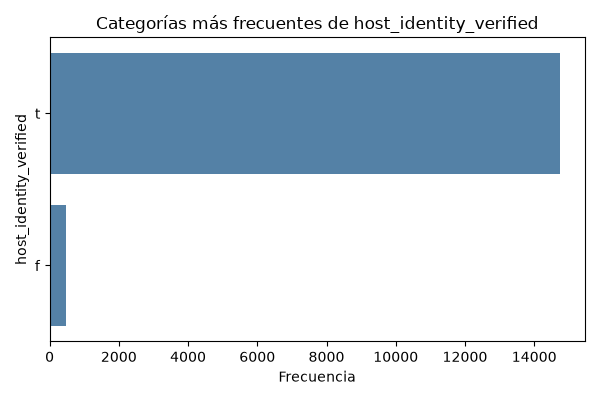

host_identity_verified
t      14731
f        475
NaN       87
Name: count, dtype: int64


In [70]:
ruta = graficar_categorica(listings["host_identity_verified"], "host_identity_verified", CARPETA_LISTINGS)
display(Image(ruta))

print(listings['host_identity_verified'].value_counts(dropna=False))

t=14.731 (96,3%), f=475 (3,1%), 87 nulos (0,6%).

### Cruce: `host_identity_verified` según reservas/ocupación

Mismo mecanismo que `host_has_profile_pic`: menos confianza, menos reservas. Los dos grupos ("sin foto" y "sin verificar") son casi independientes entre sí (solo 1 anuncio se superpone en ambos), así que si el patrón se repite aquí, es una confirmación más sólida, no el mismo caso contado dos veces.

Interseccion entre sin foto y sin verificar: 1


,number_of_reviews,estimated_occupancy_l365d,number_of_reviews_ltm
host_identity_verified,,,
f,0.0,0.0,0.0
t,10.0,62.0,2.0


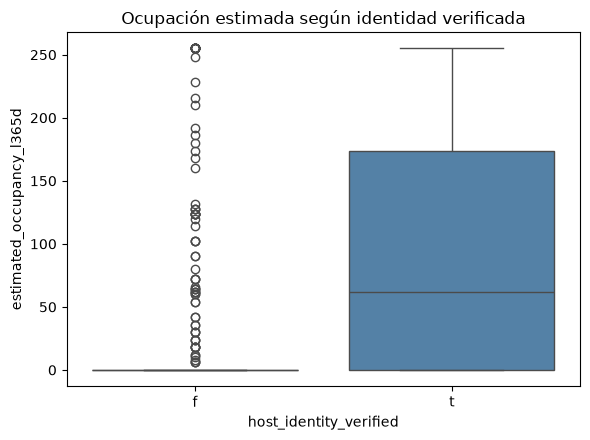

In [71]:
print("Interseccion entre sin foto y sin verificar:",
      ((listings["host_has_profile_pic"] == "f") & (listings["host_identity_verified"] == "f")).sum())

tabla = pd.DataFrame({
    "number_of_reviews": listings.groupby("host_identity_verified")["number_of_reviews"].median(),
    "estimated_occupancy_l365d": listings.groupby("host_identity_verified")["estimated_occupancy_l365d"].median(),
    "number_of_reviews_ltm": listings.groupby("host_identity_verified")["number_of_reviews_ltm"].median(),
})
display(tabla)

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=listings, x="host_identity_verified", y="estimated_occupancy_l365d", order=["f", "t"], color="steelblue", ax=ax)
ax.set_xlabel("host_identity_verified")
ax.set_ylabel("estimated_occupancy_l365d")
ax.set_title("Ocupación estimada según identidad verificada")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/identity_verified_ocupacion.png", dpi=100)
plt.show()

Se confirma el mismo patrón, con una población casi distinta: mediana de 0 en las 3 variables de volumen de reservas entre los 475 anuncios sin identidad verificada, frente a 10, 62 y 2 respectivamente en los verificados. Solo 1 anuncio se superpone con el grupo sin foto de perfil, así que son dos señales de confianza independientes que apuntan a la misma conclusión: sin verificación visible de confianza (foto o identidad), prácticamente no hay reservas.

### `host_is_superhost`

Si el anfitrión tiene el estatus Superhost de Airbnb (buena valoración, respuesta rápida, pocas cancelaciones).

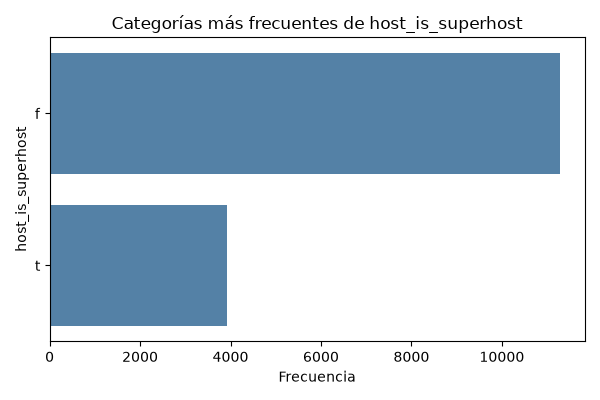

host_is_superhost
f      11274
t       3932
NaN       87
Name: count, dtype: int64


In [72]:
ruta = graficar_categorica(listings["host_is_superhost"], "host_is_superhost", CARPETA_LISTINGS)
display(Image(ruta))

print(listings['host_is_superhost'].value_counts(dropna=False))

f=11.274 (73,7%), t=3.932 (25,7%), 87 nulos (0,6%). Se usa en el modelo (notebook 06), con los nulos rellenados como "f".

### Cruce: `host_is_superhost` según ingresos, precio y ocupación

¿Ser superhost se traduce en una prima de ingresos o de precio? Mismo tipo de pregunta que con `host_has_profile_pic`/`host_identity_verified`, pero aquí el estatus en sí ya exige buena valoración y respuesta rápida, así que se espera una relación fuerte.

estimated_revenue_l365d
                    median      mean
host_is_superhost                   
f                   3840.0  15715.26
t                  29299.0  38160.37

precio_num
                   median    mean
host_is_superhost                
f                   161.0  239.83
t                   220.0  242.98

estimated_occupancy_l365d
                   median    mean
host_is_superhost                
f                    12.0   63.93
t                   180.0  152.42



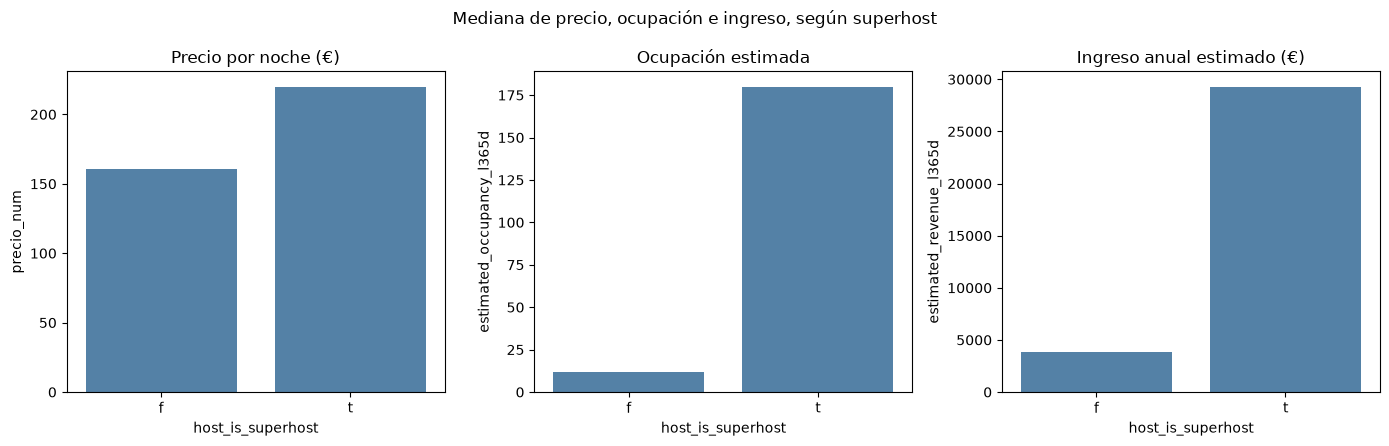

In [73]:
listings["precio_num"] = listings["price"].replace(r"[\$,]", "", regex=True).astype(float)

for col in ["estimated_revenue_l365d", "precio_num", "estimated_occupancy_l365d"]:
    print(col)
    print(listings.groupby("host_is_superhost")[col].agg(["median", "mean"]).round(2))
    print()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, col, título in zip(axes,
                            ["precio_num", "estimated_occupancy_l365d", "estimated_revenue_l365d"],
                            ["Precio por noche (€)", "Ocupación estimada", "Ingreso anual estimado (€)"]):
    sns.barplot(data=listings, x="host_is_superhost", y=col, order=["f", "t"], estimator="median",
                errorbar=None, color="steelblue", ax=ax)
    ax.set_title(título)
    ax.set_xlabel("host_is_superhost")
fig.suptitle("Mediana de precio, ocupación e ingreso, según superhost")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/superhost_revenue.png", dpi=100)
plt.show()

Resultado contundente: los superhosts tienen una mediana de ingreso de 29.299€/año frente a 3.840€ en los no superhosts — 7,6 veces más.

La diferencia no viene sobre todo del precio (220€ vs. 161€ mediana, una diferencia moderada), sino de la **ocupación**: 180 días reservados de mediana frente a solo 12 — 15 veces más. El patrón es consistente con `availability_365` (visto antes para el grupo profesional): lo que determina el ingreso no es tanto la tarifa, es si el anuncio realmente se reserva.

### Extra: cantidad absoluta de superhosts, por tipo de anfitrión

El cruce anterior está en porcentaje dentro de cada grupo. En números absolutos la diferencia es aún más marcada.

tipo_anfitrion
Particular     3843
Profesional      89
Name: count, dtype: int64

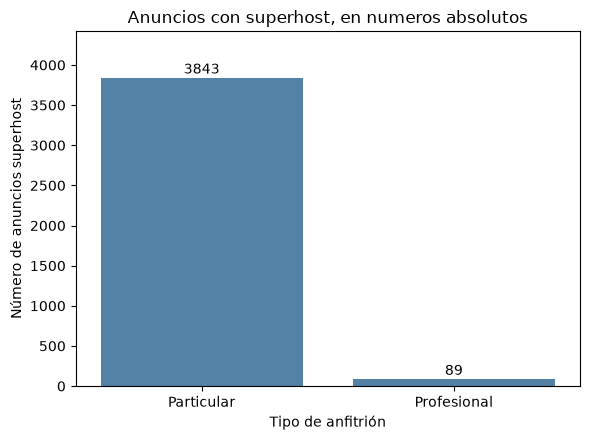

In [74]:
conteo_superhost = listings[listings["host_is_superhost"] == "t"]["tipo_anfitrion"].value_counts()
display(conteo_superhost)

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.barplot(x=conteo_superhost.index, y=conteo_superhost.values, order=["Particular", "Profesional"], color="steelblue", ax=ax)
for i, v in enumerate(conteo_superhost.reindex(["Particular", "Profesional"]).values):
    ax.text(i, v + 50, f"{v}", ha="center")
ax.set_ylim(0, conteo_superhost.max() * 1.15)
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("Número de anuncios superhost")
ax.set_title("Anuncios con superhost, en números absolutos")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/superhost_tipo_anfitrion_absoluto.png", dpi=100)
plt.show()

De los 3.932 anuncios con superhost, 3.843 son particulares y solo 89 profesionales — 43 veces más superhosts particulares que profesionales en términos absolutos, no solo en porcentaje.

## Resumen: particular vs. profesional, en 5 dimensiones

Cierre del hilo de `host_profesional` recorrido en este notebook: una tabla y un panel que reúnen los hallazgos de ingresos, ocupación, reseñas, confianza y cumplimiento normativo ya vistos por separado.

In [75]:
resumen = pd.DataFrame({
    "Dimension": ["Ingresos (media anual, €)", "Ocupación (mediana, días/365)",
                  "Reseñas (media review_scores_rating)", "Confianza (% superhost)",
                  "Cumplimiento normativo (% licencia reconocible)"],
    "Particular": [24337.53, 64.0, 4.658, 33.0, 76.4],
    "Profesional": [14677.54, 0.0, 4.422, 2.5, 87.0],
    "Gana": ["Particular", "Particular", "Particular", "Particular", "Profesional"],
})
display(resumen)

,Dimension,Particular,Profesional,Gana
0,"Ingresos (media anual, €)",24337.530,14677.540,Particular
1,"Ocupacion (mediana, dias/365)",64.000,0.000,Particular
2,Resenas (media review_scores_rating),4.658,4.422,Particular
3,Confianza (% superhost),33.000,2.500,Particular
4,Cumplimiento normativo (% licencia reconocible),76.400,87.000,Profesional


Panel con un gráfico por dimensión, cada uno en su propia escala (no se puede comparar € con puntuación 0-5 o con % en un solo eje sin distorsionar).

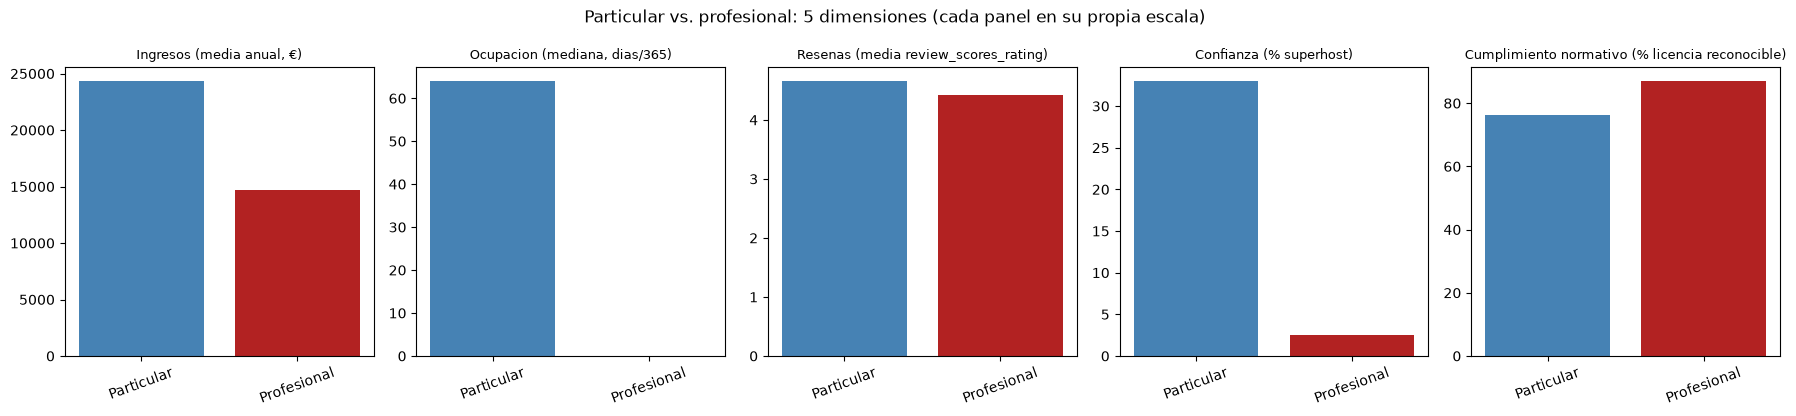

In [76]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4.2))
titulos = resumen["Dimension"].tolist()
colores_barra = ["firebrick" if g == "Profesional" else "steelblue" for g in resumen["Gana"]]

for i, (ax, título) in enumerate(zip(axes, titulos)):
    valores = [resumen.loc[i, "Particular"], resumen.loc[i, "Profesional"]]
    ax.bar(["Particular", "Profesional"], valores, color=["steelblue", "firebrick"])
    ax.set_title(título, fontsize=9)
    ax.tick_params(axis="x", rotation=20)

fig.suptitle("Particular vs. profesional: 5 dimensiones (cada panel en su propia escala)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/resumen_particular_profesional.png", dpi=100)
plt.show()

Los particulares ganan en 4 de las 5 dimensiones — ingresos, ocupación, reseñas y confianza (tasa de superhost). Los profesionales ganan solo en cumplimiento normativo del campo `license` (87,0% vs. 76,4% con licencia reconocible).

Importante no perder de vista el matiz ya señalado antes: estas son comparaciones **por anuncio individual**, no del negocio total de cada anfitrión. Un profesional con muchos anuncios puede facturar más en conjunto aunque cada uno rinda peor — la pregunta que responde esta tabla es "¿qué modelo gestiona mejor cada anuncio?", no "¿quién gana más en total?".

### `host_listings_count`

Conteo global de anuncios del anfitrión (todas las ciudades, según lo autodeclara Airbnb), no solo Barcelona.

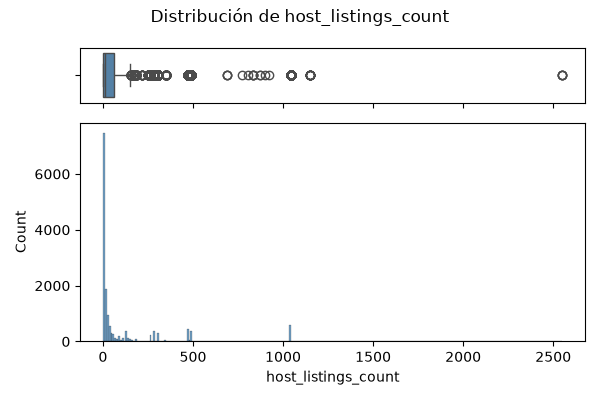

Q1=3.0  mediana=12.0  Q3=62.0  limite superior atipicos=150.5
nulos=87  max real=2549.0


In [77]:
ruta = graficar_numerica(listings["host_listings_count"], "host_listings_count", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["host_listings_count"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  límite superior atípicos={limite_superior}")
print(f"nulos={s.isna().sum()}  max real={s.max()}")

Percentiles: 25% = 3, mediana = 12, 75% = 62. Atípicos a partir de 150,5 —
máximo real 2.549. 87 nulos. Se usa en el modelo (notebook 06), con los
nulos rellenados como 1. Notebook 06 usa las dos columnas a la vez como predictoras (no una en lugar de la otra) — `calculated_host_listings_count` es la que solo cuenta Barcelona (el proyecto completo es solo de Barcelona).

### Cruce: `host_listings_count` vs. `calculated_host_listings_count`

El global declarado (`host_listings_count`) debería ser siempre mayor o igual que el específico de Barcelona (`calculated_host_listings_count`), ya que Barcelona es un subconjunto de "todas las ciudades". Se comprueba si eso se cumple.

Correlacion: 0.928
Casos donde son exactamente iguales (host opera solo en Barcelona): 7601 de 15293

Casos donde Barcelona > global (inconsistente, no deberia pasar): 112
Anfitriones unicos afectados: 15
Diferencia (calculated - global): {'mean': 1.2142857142857142, '50%': 1.0, 'max': 2.0}


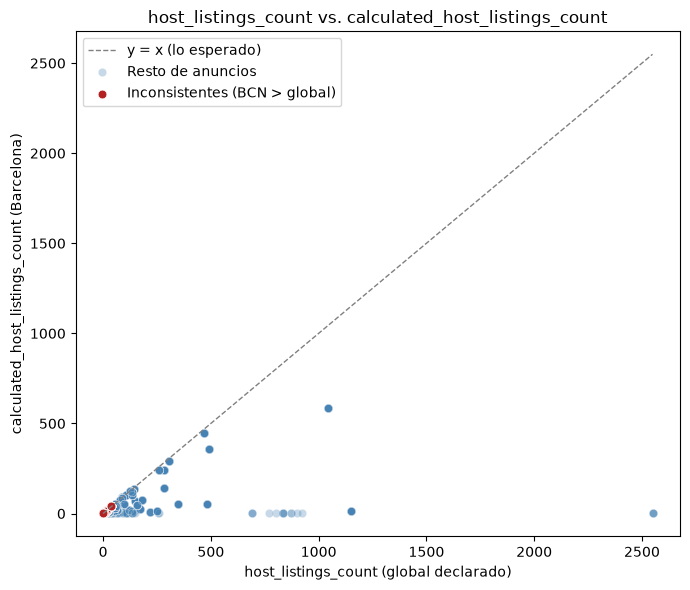

In [78]:
print("Correlación:", round(listings["host_listings_count"].corr(listings["calculated_host_listings_count"]), 3))

iguales = (listings["calculated_host_listings_count"] == listings["host_listings_count"]).sum()
print(f"Casos donde son exactamente iguales (host opera solo en Barcelona): {iguales} de {len(listings)}")

inconsistentes = listings[listings["calculated_host_listings_count"] > listings["host_listings_count"]]
print(f"\nCasos donde Barcelona > global (inconsistente, no deberia pasar): {len(inconsistentes)}")
print(f"Anfitriones únicos afectados: {inconsistentes['host_id'].nunique()}")
print(f"Diferencia (calculated - global): {(inconsistentes['calculated_host_listings_count'] - inconsistentes['host_listings_count']).describe()[['mean','50%','max']].to_dict()}")

fig, ax = plt.subplots(figsize=(7, 6))
límite = max(listings["host_listings_count"].max(), listings["calculated_host_listings_count"].max())
ax.plot([0, límite], [0, límite], color="gray", linestyle="--", linewidth=1, label="y = x (lo esperado)")
sns.scatterplot(data=listings, x="host_listings_count", y="calculated_host_listings_count",
                 alpha=0.3, color="steelblue", label="Resto de anuncios", ax=ax)
sns.scatterplot(data=inconsistentes, x="host_listings_count", y="calculated_host_listings_count",
                 color="firebrick", s=40, label="Inconsistentes (BCN > global)", ax=ax)
ax.set_xlabel("host_listings_count (global declarado)")
ax.set_ylabel("calculated_host_listings_count (Barcelona)")
ax.set_title("host_listings_count vs. calculated_host_listings_count")
ax.legend()
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/host_listings_count_comparacion.png", dpi=100)
plt.show()

Correlación fuerte (0,93), como se esperaba. 7.601 de 15.293 anuncios (49,7%) tienen los dos valores exactamente iguales — la mitad de los anfitriones del dataset operan únicamente en Barcelona, sin presencia declarada en otras ciudades.

Inconsistencia detectada: 112 filas (de solo 15 anfitriones únicos) tienen `calculated_host_listings_count` **mayor** que `host_listings_count` — lógicamente no debería pasar, ya que Barcelona es un subconjunto de "todas las ciudades". La diferencia es siempre pequeña (1 o 2, mediana 1), compatible con que `host_listings_count` (autodeclarado por el anfitrión en su perfil) esté ligeramente desactualizado frente a `calculated_host_listings_count` (calculado por Inside Airbnb sobre el snapshot actual) — por ejemplo, si el anfitrión añadió 1-2 anuncios en Barcelona recientemente y su perfil global todavía no lo refleja. Es un desfase menor de actualización, no un error grande ni un patrón generalizado.

### `host_location`

Ciudad/país donde dice vivir el anfitrión (texto libre que escribe) -- no donde está el alojamiento, que siempre es Barcelona.

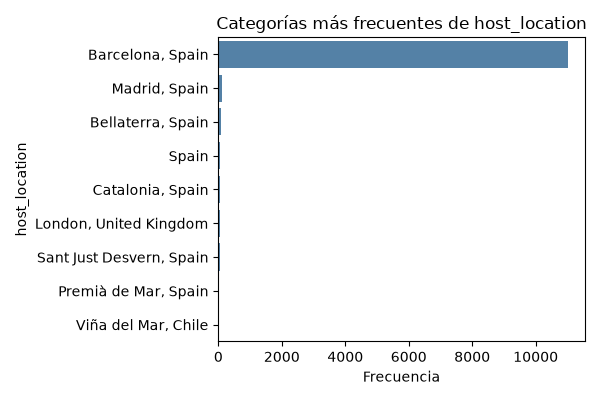

nulos=3098 (20.3%)  valores unicos=321
contiene Barcelona=11004


In [79]:
ruta = graficar_categorica(listings["host_location"], "host_location", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["host_location"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)  valores únicos={s.nunique()}")
print(f"contiene Barcelona={s.astype(str).str.contains('Barcelona', case=False).sum()}")

20,3% nulos (3.098). 321 valores únicos. 11.004 (72%) dicen vivir en
Barcelona — el resto (28%) vive en otras ciudades (Madrid, Londres...) o
incluso otros países (Viña del Mar, Chile), gestionando alojamientos aquí
a distancia.

### Cruce: `host_location` según reservas/ocupación

¿Gestionar desde fuera de Barcelona (sin presencia local) afecta la ocupación real, igual que pasaba con la foto de perfil o la identidad verificada?

ubicacion_anfitrion
Vive en Barcelona    11004
Sin dato              3098
Vive fuera            1191
Name: count, dtype: int64



,estimated_revenue_l365d,estimated_occupancy_l365d,review_scores_rating
ubicacion_anfitrion,,,
Sin dato,5376.0,36.0,4.72
Vive en Barcelona,9638.5,62.0,4.73
Vive fuera,5098.0,0.0,4.81


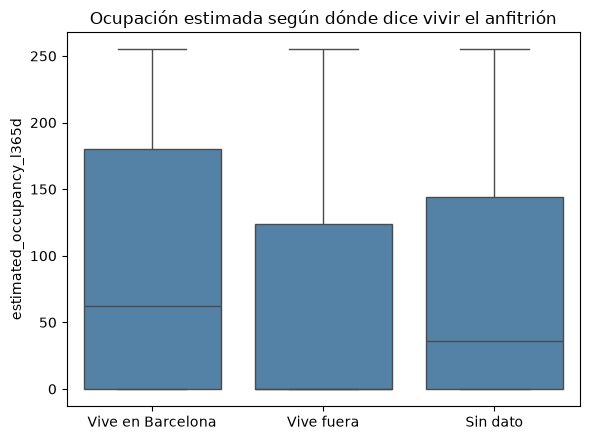

Controlando por tipo_anfitrion, para no confundir el efecto de ubicacion con el de escala:
                                      mean  median  count
ubicacion_anfitrion tipo_anfitrion                       
Sin dato            Particular       82.19    36.0   2942
                    Profesional      28.60     0.0    156
Vive en Barcelona   Particular      104.71    78.0   7718
                    Profesional      57.61     0.0   3286
Vive fuera          Particular       73.61    12.0   1068
                    Profesional      10.18     0.0    123

Porcentaje con ocupacion estimada en 0, por subgrupo:
ubicacion_anfitrion  tipo_anfitrion
Sin dato             Particular        32.9
                     Profesional       65.4
Vive en Barcelona    Particular        28.4
                     Profesional       53.6
Vive fuera           Particular        47.0
                     Profesional       85.4
Name: estimated_occupancy_l365d, dtype: float64


In [80]:
def clasifica_ubicacion(v):
    if pd.isna(v):
        return "Sin dato"
    return "Vive en Barcelona" if "barcelona" in str(v).lower() else "Vive fuera"

listings["ubicacion_anfitrion"] = listings["host_location"].apply(clasifica_ubicacion)
print(listings["ubicacion_anfitrion"].value_counts())
print()

tabla = listings.groupby("ubicacion_anfitrion")[["estimated_revenue_l365d", "estimated_occupancy_l365d", "review_scores_rating"]].median()
display(tabla)

fig, ax = plt.subplots(figsize=(6, 4.5))
orden = ["Vive en Barcelona", "Vive fuera", "Sin dato"]
sns.boxplot(data=listings, x="ubicacion_anfitrion", y="estimated_occupancy_l365d", order=orden, color="steelblue", ax=ax)
ax.set_xlabel("")
ax.set_ylabel("estimated_occupancy_l365d")
ax.set_title("Ocupación estimada según dónde dice vivir el anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/host_location_ocupacion.png", dpi=100)
plt.show()

print("Controlando por tipo_anfitrion, para no confundir el efecto de ubicacion con el de escala:")
print(listings.groupby(["ubicacion_anfitrion", "tipo_anfitrion"])["estimated_occupancy_l365d"].agg(["mean", "median", "count"]).round(2))
print()
print("Porcentaje con ocupación estimada en 0, por subgrupo:")
print((listings.groupby(["ubicacion_anfitrion", "tipo_anfitrion"])["estimated_occupancy_l365d"]
       .apply(lambda s: (s == 0).mean() * 100)).round(1))

Mismo patrón de fondo que `host_has_profile_pic` e `host_identity_verified` (ocupación muy distinta, reseñas casi iguales), con un matiz importante que solo aparece al mirar más que la mediana:

| | Vive en Barcelona | Vive fuera |
|---|---|---|
| Particulares — media | 104,71 | 73,61 |
| Particulares — mediana | 78 | 12 |
| Profesionales — media | 57,61 | 10,18 |
| Profesionales — mediana | 0 | 0 |
| Profesionales — % con ocupación 0 | 53,6% | 85,4% |

En particulares, el efecto es claro incluso en la mediana (78 vs. 12). En profesionales, la mediana se queda en 0 en los dos grupos porque más de la mitad no logra ninguna ocupación en ambos casos — pero mirando la media y el % en cero, sí hay una diferencia real: 53,6% de los profesionales que viven en Barcelona tienen ocupación cero, frente a 85,4% de los que viven fuera. El efecto de ubicación existe en los dos tipos de anfitrión, solo que en profesionales queda oculto si solo se mira la mediana.

Sin controlar por tipo de anfitrión, la comparación general (62 vs. 0) mezclaba dos efectos: el real (vivir cerca ayuda) y el de composición (el grupo "Vive en Barcelona" tiene casi el triple de proporción de profesionales, 29,9% vs. 10,3%, que de por sí ya rinden peor).

### `host_name`

Nombre del anfitrión tal como lo muestra Airbnb.

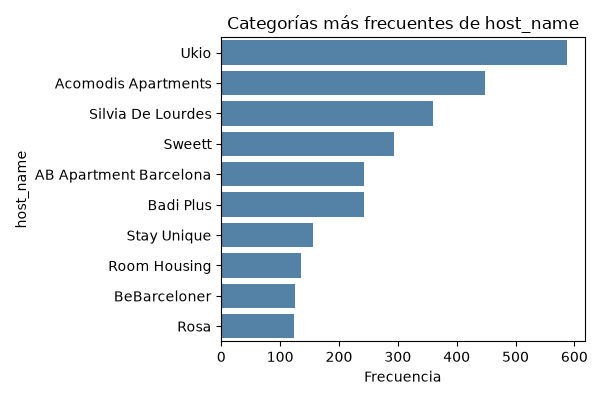

nulos=87  valores unicos=2510
host_name
Ukio                      588
Acomodis Apartments       448
Silvia De Lourdes         359
Sweett                    293
AB Apartment Barcelona    243
Badi Plus                 243
Stay Unique               156
Room Housing              136
BeBarceloner              125
Rosa                      123
Name: count, dtype: int64


In [81]:
ruta = graficar_categorica(listings["host_name"], "host_name", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['host_name'].isna().sum()}  valores únicos={listings['host_name'].nunique()}")
print(listings['host_name'].value_counts().head(10))

87 nulos, 2.510 valores únicos. El más frecuente, "Ukio" (588 anuncios),
coincide exacto con el máximo de `calculated_host_listings_count`
— es el anfitrión mega-grande, y su nombre confirma que es una empresa de
gestión, no una persona. Varios de los más frecuentes (Acomodis Apartments,
AB Apartment Barcelona, Badi Plus) son también claramente empresas.

### `host_neighbourhood`

Barrio donde vive el anfitrión (no el barrio del alojamiento).

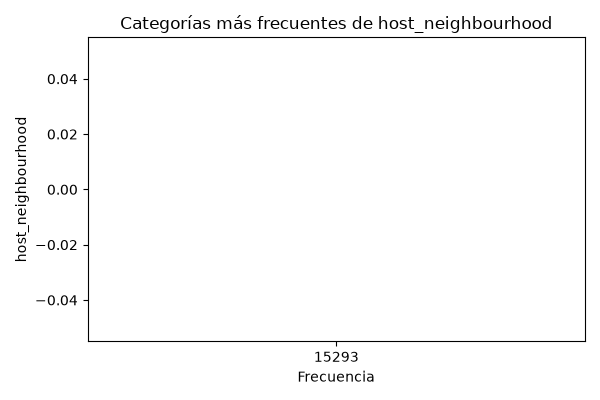

nulos=15293 de 15293


In [82]:
ruta = graficar_categorica(listings["host_neighbourhood"], "host_neighbourhood", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['host_neighbourhood'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05.

### `host_picture_url`

Enlace a la foto de perfil del anfitrión, tamaño normal.

No se usa `graficar_categorica` aquí: son URLs largas, no caben legibles como etiqueta de eje. Se numeran las barras y se muestra la URL completa en una tabla.

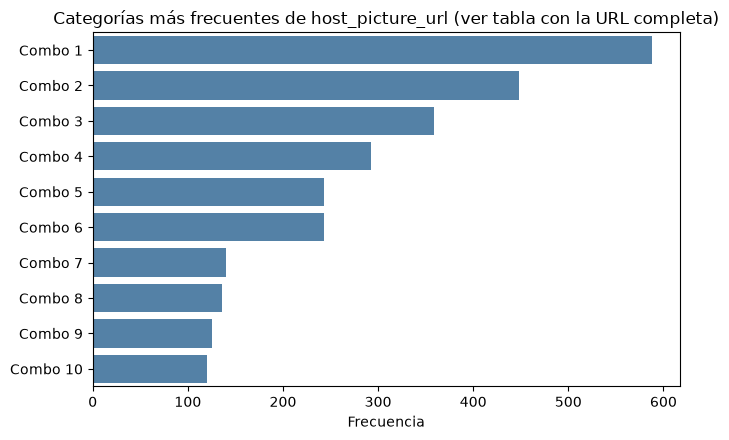

nulos=87  valores unicos=4468 de 15206



,Combo,Frecuencia,URL completa
0,Combo 1,588,https://a0.muscache.com/im/pictures/user/f790e9f4-a54f-4132-83d8-f71b8c9e3760.jpg?aki_policy=profile_x_medium
1,Combo 2,448,https://a0.muscache.com/im/pictures/user/f1ba627d-3c72-4140-8415-f63c7ca17a33.jpg?aki_policy=profile_x_medium
2,Combo 3,359,https://a0.muscache.com/im/pictures/user/User-21726991/original/67f5ca8f-dd10-40ec-9825-95b972245c8b.jpeg?aki_policy=profile_x_medium
3,Combo 4,293,https://a0.muscache.com/im/pictures/user/User-32037490/original/70657aed-2f20-44dc-93a2-5a69cb868b67.png?aki_policy=profile_x_medium
4,Combo 5,243,https://a0.muscache.com/im/pictures/user/User-4459553/original/cc859e10-f60d-422a-b6cf-dba464e0be14.png?aki_policy=profile_x_medium
5,Combo 6,243,https://a0.muscache.com/im/pictures/user/User-221480824/original/7899da72-97d6-44bb-89c9-51911642382b.jpeg?aki_policy=profile_x_medium
6,Combo 7,140,https://a0.muscache.com/im/pictures/user/f84fcece-2518-41f3-9fcc-e6b9b2eec074.jpg?aki_policy=profile_x_medium
7,Combo 8,136,https://a0.muscache.com/im/pictures/user/User-36607755/original/8dc94024-b8b8-4bc0-aa12-250f87ee9ee7.jpeg?aki_policy=profile_x_medium
8,Combo 9,125,https://a0.muscache.com/im/pictures/user/03c34c76-20ff-46f1-ad25-a05d0e392fc4.jpg?aki_policy=profile_x_medium
9,Combo 10,120,https://a0.muscache.com/im/pictures/user/User/original/97388480-4aae-4430-b1a3-789fda416f28.jpeg?aki_policy=profile_x_medium


In [83]:
conteo = listings["host_picture_url"].value_counts().head(10)
etiquetas_numeradas = [f"Combo {i+1}" for i in range(len(conteo))]

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=conteo.values, y=etiquetas_numeradas, color="steelblue", ax=ax)
ax.set_xlabel("Frecuencia")
ax.set_ylabel("")
ax.set_title("Categorías más frecuentes de host_picture_url (ver tabla con la URL completa)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/listings/host_picture_url_categorica.png", dpi=100)
plt.show()

s = listings["host_picture_url"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()} de {s.notna().sum()}")
print()

tabla_combos = pd.DataFrame({
    "Combo": etiquetas_numeradas,
    "Frecuencia": conteo.values,
    "URL completa": conteo.index,
})
pd.set_option("display.max_colwidth", None)
display(tabla_combos)

87 nulos. 4.468 valores únicos de 15.206 — las barras altas no son categorías informativas, son el mismo anfitrión repitiendo su foto en cada uno de sus anuncios (la más frecuente, 588, es "Ukio"), mismo problema de etiquetas largas visto en `amenities`/`license`/`description`/`host_about`, resuelto igual.

### `host_profile_id`

ID del anfitrión en el formato nuevo (más largo), usado en la URL del perfil moderna.

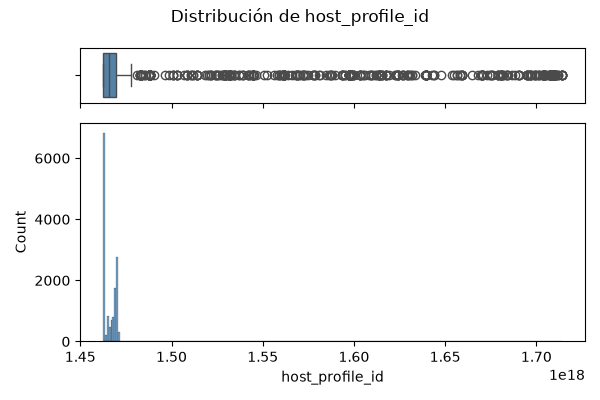

nulos=87  min=1.4625066536557875e+18  max=1.7140776112277243e+18


In [84]:
ruta = graficar_numerica(listings["host_profile_id"], "host_profile_id", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["host_profile_id"]
print(f"nulos={s.isna().sum()}  min={s.min()}  max={s.max()}")

87 nulos. Todos los valores reales tienen 19 dígitos (del orden de 1,46 a 1,71 x 10^18) — a diferencia de `host_id`, aquí no hay mezcla de formatos, siempre es el formato largo.

### `host_profile_url`

Enlace al perfil del anfitrión, formato nuevo (construido a partir de host_profile_id).

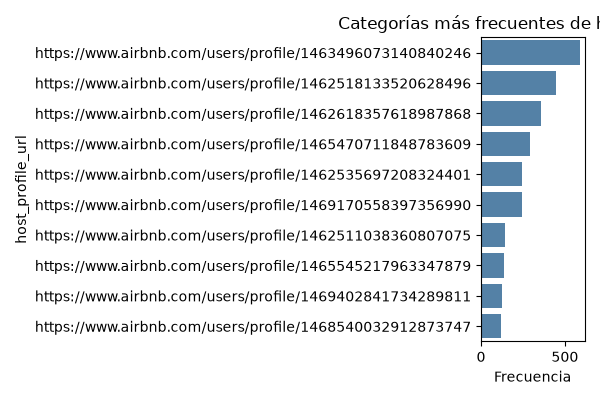

nulos=81  valores unicos=4555


In [85]:
ruta = graficar_categorica(listings["host_profile_url"], "host_profile_url", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['host_profile_url'].isna().sum()}  valores únicos={listings['host_profile_url'].nunique()}")

81 nulos — no exactamente los mismos 87 de `host_profile_id`, una pequeña diferencia sin explicación confirmada. 4.555 valores unicos.

### `host_response_rate`

Porcentaje de mensajes que responde el anfitrión.

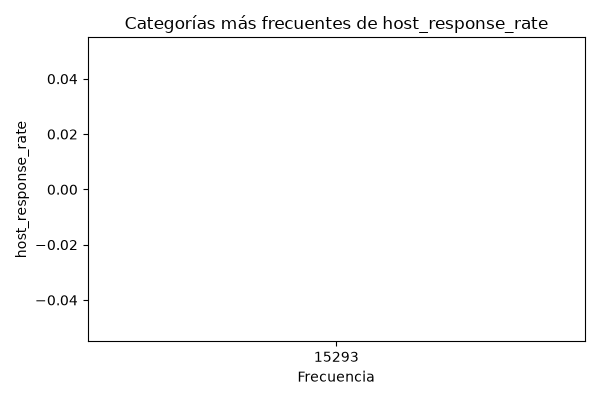

nulos=15293 de 15293


In [86]:
ruta = graficar_categorica(listings["host_response_rate"], "host_response_rate", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['host_response_rate'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05.

### `host_response_time`

Qué tan rápido responde normalmente el anfitrión (ej. "en una hora").

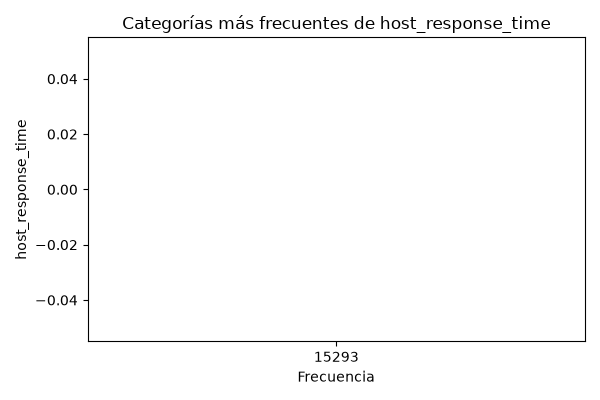

nulos=15293 de 15293


In [87]:
ruta = graficar_categorica(listings["host_response_time"], "host_response_time", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['host_response_time'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05.

### `host_since`

Fecha de registro del anfitrión en Airbnb.

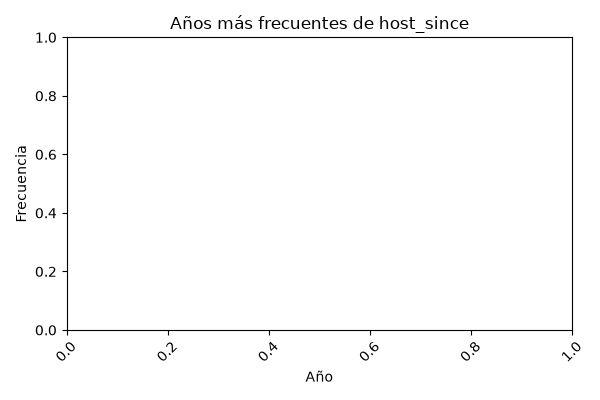

nulos=15293 de 15293


In [88]:
fecha_since = pd.to_datetime(listings["host_since"])
ruta = graficar_fecha(fecha_since, "host_since", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={fecha_since.isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05. Sustituida por las columnas `hosts_time_as_user_years`/`_months` y `hosts_time_as_host_years`/`_months`, que sí tienen datos.

### `host_thumbnail_url`

Enlace a la foto de perfil en miniatura del anfitrión.

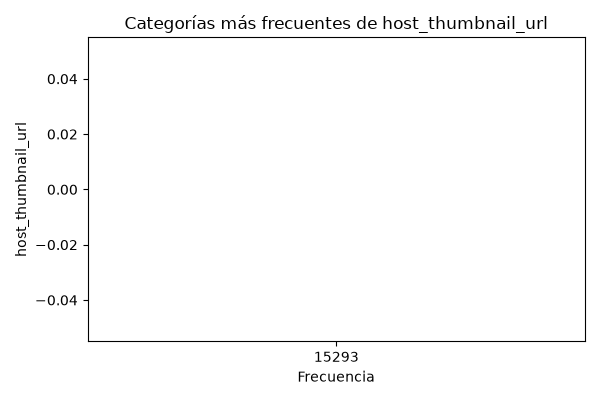

nulos=15293 de 15293


In [89]:
ruta = graficar_categorica(listings["host_thumbnail_url"], "host_thumbnail_url", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['host_thumbnail_url'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — a diferencia de `host_picture_url` (versión grande), que sí tiene datos.

### `host_total_listings_count`

Otra variante del conteo total de anuncios del anfitrión.

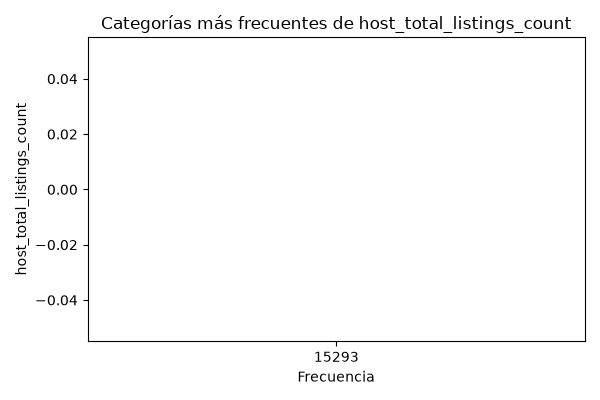

nulos=15293 de 15293


In [90]:
ruta = graficar_categorica(listings["host_total_listings_count"], "host_total_listings_count", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['host_total_listings_count'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05. No se puede confirmar en qué se diferenciaba de `host_listings_count`, porque no tiene ningún valor real para comparar.

### `host_url`

Enlace al perfil del anfitrión, formato clásico (construido a partir de host_id).

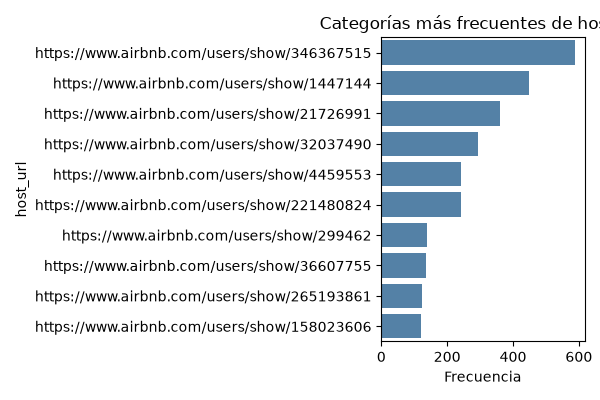

nulos=0  valores unicos=4595


In [91]:
ruta = graficar_categorica(listings["host_url"], "host_url", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['host_url'].isna().sum()}  valores únicos={listings['host_url'].nunique()}")

0 nulos. 4.595 valores únicos — el más frecuente, con 588, es de nuevo "Ukio".

### `host_verifications`

Qué métodos de verificación de identidad usó el anfitrión (email, teléfono, etc.).

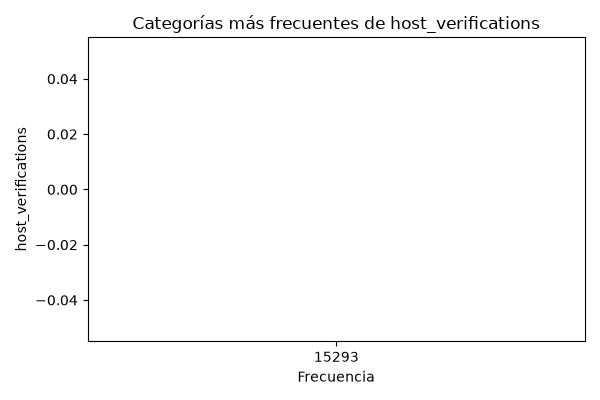

nulos=15293 de 15293


In [92]:
ruta = graficar_categorica(listings["host_verifications"], "host_verifications", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['host_verifications'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05.

### `hosts_time_as_host_months`

Meses (complemento de los años) de antigüedad del anfitrión como anfitrión (desde su primer anuncio publicado).

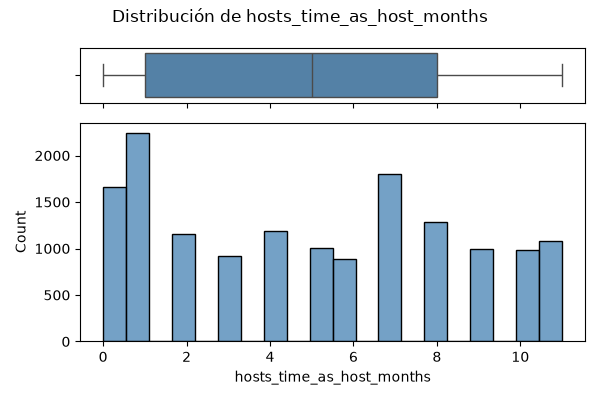

Q1=1.0  mediana=5.0  Q3=8.0
nulos=87


In [93]:
ruta = graficar_numerica(listings["hosts_time_as_host_months"], "hosts_time_as_host_months", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["hosts_time_as_host_months"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}")
print(f"nulos={s.isna().sum()}")

Percentiles: 25% = 1, mediana = 5, 75% = 8 (rango lógico de 0 a 11, porque
son meses dentro de un año). 87 nulos (mismas filas que las demas columnas
del grupo `hosts_time_as_*`).

### Cruce: `hosts_time_as_host_years` según tipo de anfitrión

A primera vista podría parecer que contradice el hallazgo de `first_review` (donde los profesionales eran más recientes) — hay que distinguir dos cosas: la antigüedad de la **cuenta** de anfitrión frente a la antigüedad de **este anuncio concreto** en Barcelona.

hosts_time_as_host_years (antiguedad de la cuenta de anfitrion):


,mean,median
tipo_anfitrion,,
Particular,7.39,8.0
Profesional,9.36,11.0



Para comparar, first_review (antiguedad de ESTE anuncio en Barcelona):
tipo_anfitrion
Particular    2022-05-01
Profesional   2024-02-18
dtype: datetime64[us]


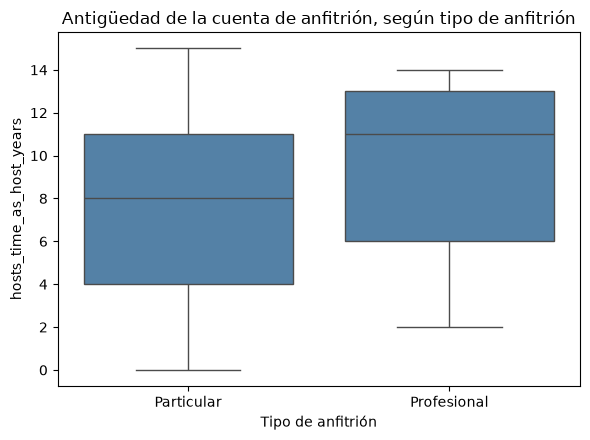

In [94]:
tabla = listings.groupby("tipo_anfitrion")["hosts_time_as_host_years"].agg(["mean", "median"])
print("hosts_time_as_host_years (antigüedad de la cuenta de anfitrión):")
display(tabla.round(2))

print()
print("Para comparar, first_review (antigüedad de ESTE anuncio en Barcelona):")
fecha_fr = pd.to_datetime(listings["first_review"])
print(listings.groupby("tipo_anfitrion").apply(lambda g: pd.to_datetime(g["first_review"]).median(), include_groups=False))

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=listings, x="tipo_anfitrion", y="hosts_time_as_host_years", order=["Particular", "Profesional"], color="steelblue", ax=ax)
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("hosts_time_as_host_years")
ax.set_title("Antigüedad de la cuenta de anfitrión, según tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/time_as_host_tipo_anfitrion.png", dpi=100)
plt.show()

No es una contradicción, son dos cosas distintas: la **cuenta** de anfitrión de los profesionales es más antigua (mediana 11 años vs. 8 en particulares) — llevan más tiempo en Airbnb como gestores. Pero el anuncio concreto que están gestionando en Barcelona es más reciente (`first_review` con mediana en 2024 vs. 2022) — es una expansión reciente de un negocio ya establecido, no una cuenta nueva.

Interpretación: las gestoras profesionales no son necesariamente nuevas en la plataforma, pero sí están añadiendo anuncios nuevos a Barcelona de forma más reciente que el anfitrión particular promedio — consistente con el crecimiento de la presencia profesional documentado en `first_review`.

### `hosts_time_as_host_years`

Años de antigüedad del anfitrión como anfitrión (desde su primer anuncio publicado).

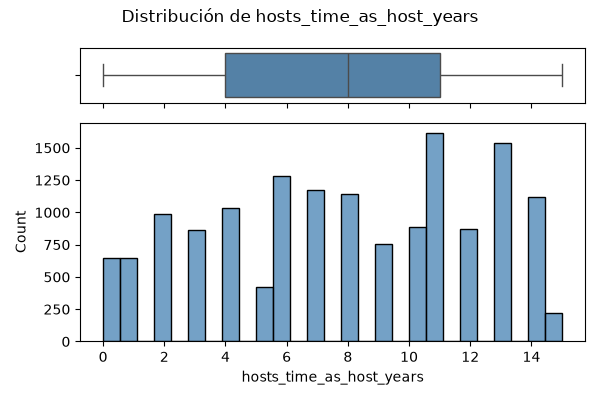

Q1=4.0  mediana=8.0  Q3=11.0  max=15.0
nulos=87


In [95]:
ruta = graficar_numerica(listings["hosts_time_as_host_years"], "hosts_time_as_host_years", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["hosts_time_as_host_years"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")

Percentiles: 25% = 4, mediana = 8, 75% = 11. Máximo 15 años. 87 nulos
(mismas filas que las demas columnas del grupo `hosts_time_as_*`).

### `hosts_time_as_user_months`

Meses (complemento de los años) de antigüedad del anfitrión como usuario de Airbnb — antes de ser anfitrión, desde que se registró en la plataforma.

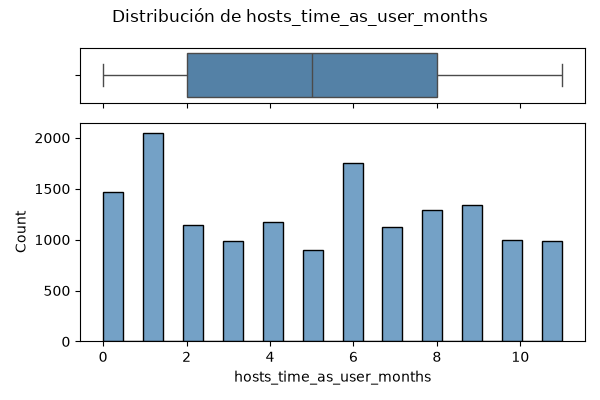

Q1=2.0  mediana=5.0  Q3=8.0
nulos=87


In [96]:
ruta = graficar_numerica(listings["hosts_time_as_user_months"], "hosts_time_as_user_months", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["hosts_time_as_user_months"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}")
print(f"nulos={s.isna().sum()}")

Percentiles: 25% = 2, mediana = 5, 75% = 8. 87 nulos (mismas filas que las
demás columnas del grupo `hosts_time_as_*`).

### `hosts_time_as_user_years`

Años de antigüedad del anfitrión como usuario de Airbnb — antes de ser anfitrión, desde que se registró en la plataforma (aunque fuera solo para reservar).

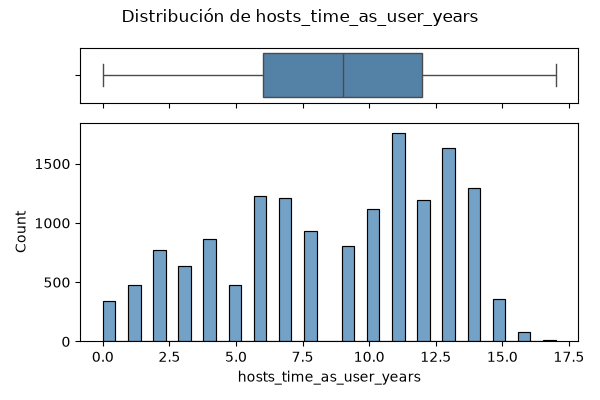

Q1=6.0  mediana=9.0  Q3=12.0  max=17.0
nulos=87


In [97]:
ruta = graficar_numerica(listings["hosts_time_as_user_years"], "hosts_time_as_user_years", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["hosts_time_as_user_years"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")

Percentiles: 25% = 6, mediana = 9, 75% = 12. Máximo 17 años. 87 nulos
(mismas filas que las demás columnas del grupo `hosts_time_as_*`). Con
esta se completan las 4 columnas del grupo.

### Cruce: `hosts_time_as_user_years` según tipo de anfitrión

Mismo tipo de comparación que con `hosts_time_as_host_years`, pero midiendo desde el registro como usuario (antes de ser anfitrión), no desde el primer anuncio publicado.

,mean,median
tipo_anfitrion,,
Particular,8.31,9.0
Profesional,9.73,11.0


Coinciden time_as_user y time_as_host en el mismo valor: 73.2% de las filas


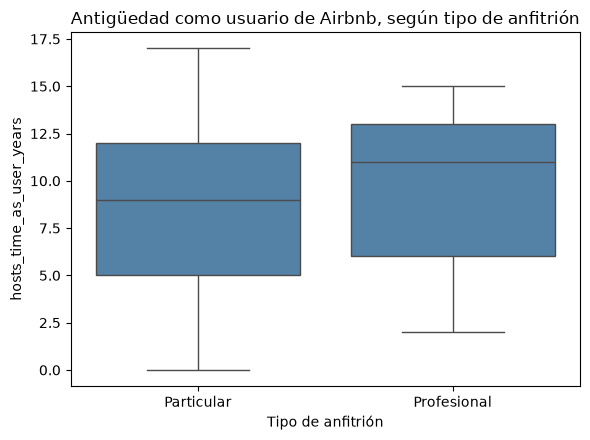

In [98]:
tabla = listings.groupby("tipo_anfitrion")["hosts_time_as_user_years"].agg(["mean", "median"])
display(tabla.round(2))

print("Coinciden time_as_user y time_as_host en el mismo valor:",
      f"{(listings['hosts_time_as_user_years'] == listings['hosts_time_as_host_years']).mean()*100:.1f}%",
      "de las filas")

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=listings, x="tipo_anfitrion", y="hosts_time_as_user_years", order=["Particular", "Profesional"], color="steelblue", ax=ax)
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("hosts_time_as_user_years")
ax.set_title("Antigüedad como usuario de Airbnb, según tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/time_as_user_tipo_anfitrion.png", dpi=100)
plt.show()

Mismo patrón que `hosts_time_as_host_years`: los profesionales llevan más tiempo como usuarios de Airbnb (mediana 11 años vs. 9 en particulares). Las dos columnas coinciden en el 73,2% de las filas — en el resto, el usuario se registró antes de convertirse en anfitrión (usó la plataforma como huésped primero).

No aporta una historia distinta a la ya vista con `hosts_time_as_host_years`: confirma que los profesionales son, en conjunto, usuarios más veteranos de la plataforma, aunque su expansión concreta en Barcelona sea más reciente (`first_review`).

### `id`

Identificador único del alojamiento (no del anfitrión).

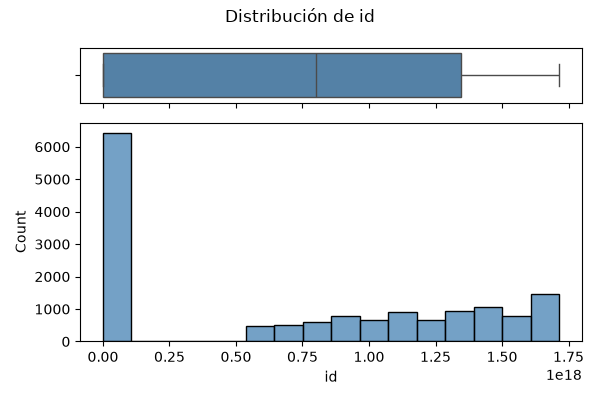

nulos=0  valores unicos=15293 de 15293
min=18674  max=1714531569719409706


In [99]:
ruta = graficar_numerica(listings["id"], "id", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["id"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()} de {len(s)}")
print(f"min={s.min()}  max={s.max()}")

0 nulos, 15.293 valores únicos de 15.293 — clave primaria limpia, sin
duplicados. Igual que `host_id`, mezcla formato corto (min 18.674) y
formato largo (max 1,71x10^18).

### Cruce: `id` según `first_review`

Aunque `id` es un identificador, no necesariamente es arbitrario — se comprueba si su magnitud guarda relación con la antigüedad del anuncio.

Correlacion id vs first_review (orden cronologico): 0.816

id_formato
Corto   2018-08-23
Largo   2024-11-20
dtype: datetime64[us]
id_formato
Largo    8869
Corto    6424
Name: count, dtype: int64


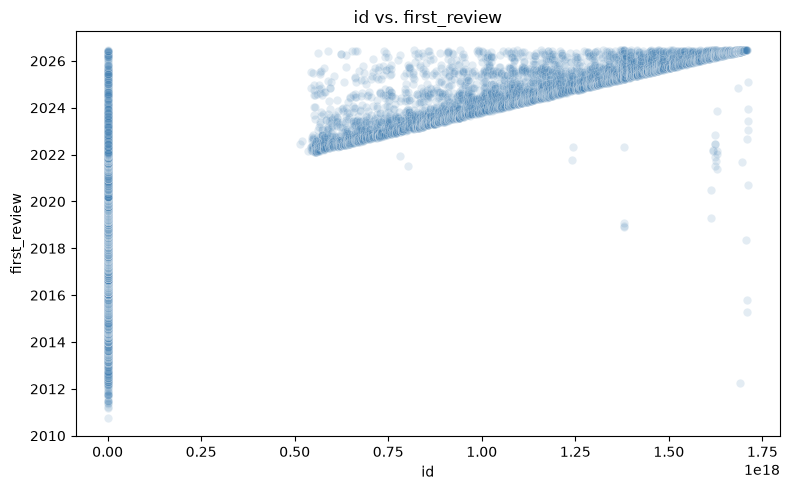

In [100]:
fecha_fr = pd.to_datetime(listings["first_review"])
con_fecha = listings[fecha_fr.notna()].copy()
con_fecha["first_review_dt"] = fecha_fr[fecha_fr.notna()]

print("Correlación id vs first_review (orden cronológico):",
      round(con_fecha["id"].corr(con_fecha["first_review_dt"].map(lambda d: d.toordinal())), 3))

listings["id_formato"] = listings["id"].apply(lambda v: "Corto" if v < 1e12 else "Largo")
print()
print(listings.groupby("id_formato").apply(lambda g: pd.to_datetime(g["first_review"]).median(), include_groups=False))
print(listings["id_formato"].value_counts())

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=con_fecha, x="id", y="first_review_dt", alpha=0.15, color="steelblue", ax=ax)
ax.set_xlabel("id")
ax.set_ylabel("first_review")
ax.set_title("id vs. first_review")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/id_first_review.png", dpi=100)
plt.show()

`id` no es un identificador puramente arbitrario, pero la relación no es una correlación gradual suave — es más bien un corte binario. El scatter lo muestra con claridad: los ids cortos (formato antiguo) aparecen repartidos en **todo** el rango de `first_review` (2010 a 2026), mientras que los ids largos (formato nuevo) están siempre acotados entre 2022 y 2026, sin ninguna excepción por debajo de eso.

Esto tiene sentido si Airbnb empezó a asignar ids en formato largo a partir de cierta fecha (~2022) y nunca les cambió el id a los anuncios más antiguos que ya tenían formato corto: un anuncio viejo que sigue activo conserva su id corto de siempre, sin importar cuándo llegó su primera reseña. Por eso la correlación (0,82) es engañosa como medida de "cuanto más alto el id, más nuevo" — lo que realmente separa es el formato (corto/largo) como un límite, no el valor exacto dentro de cada formato. Dentro del grupo de ids cortos, el valor del id no predice la fecha de first_review.

### `instant_bookable`

Si el alojamiento se puede reservar al instante, sin aprobación del anfitrión.

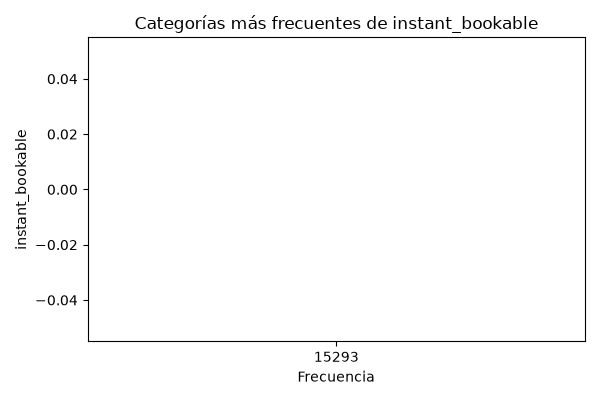

nulos=15293 de 15293


In [101]:
ruta = graficar_categorica(listings["instant_bookable"], "instant_bookable", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['instant_bookable'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05.

### `last_review`

Fecha de la reseña más reciente que recibió el alojamiento.

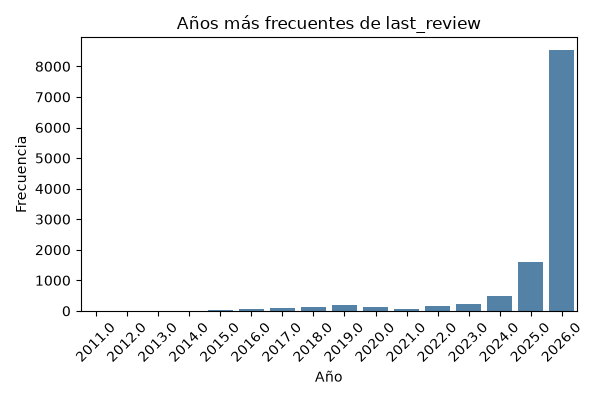

nulos=3548
min=2011-06-23 00:00:00  max=2026-07-02 00:00:00


In [102]:
fecha_last = pd.to_datetime(listings["last_review"])
ruta = graficar_fecha(fecha_last, "last_review", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={fecha_last.isna().sum()}")
print(f"min={fecha_last.min()}  max={fecha_last.max()}")

3.548 nulos — mismas filas sin ninguna reseña. Rango real: 2011-06-23 a 2026-07-02. Fuerte concentración en 2026 (8.524, el 55,7% del total): no significa que se dejaran más reseñas ese año, sino que `last_review` es el máximo de fechas por alojamiento — un alojamiento activo siempre muestra su reseña más reciente cerca de hoy, sin importar cuántos años lleve. Los años antiguos (2011-2024) son sobre todo alojamientos que dejaron de recibir reseñas hace tiempo.

### Cruce: `last_review` según tipo de anfitrión

¿Qué tan reciente es la última reseña, entre los anuncios que sí tienen al menos una? Se mide como días entre `last_review` y `last_scraped` (fecha del scraping).

Dias desde la ultima resena (solo anuncios con al menos una):
                 mean  median
tipo_anfitrion               
Particular      322.4    28.0
Profesional     245.7    40.0

Porcentaje sin ninguna resena, por tipo de anfitrion:
tipo_anfitrion
Particular     16.9
Profesional    43.9
Name: last_review, dtype: float64


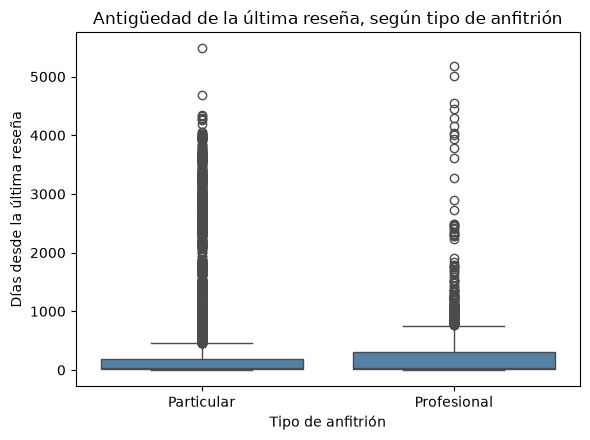

In [103]:
fecha_last = pd.to_datetime(listings["last_review"])
fecha_scraped = pd.to_datetime(listings["last_scraped"])
listings["dias_desde_ultima_resena"] = (fecha_scraped - fecha_last).dt.days

con_resenas = listings[fecha_last.notna()]
print("Días desde la última reseña (solo anuncios con al menos una):")
print(con_resenas.groupby("tipo_anfitrion")["dias_desde_ultima_resena"].agg(["mean", "median"]).round(1))
print()
print("Porcentaje sin ninguna reseña, por tipo de anfitrión:")
print(listings.groupby("tipo_anfitrion")["last_review"].apply(lambda s: s.isna().mean() * 100).round(1))

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=con_resenas, x="tipo_anfitrion", y="dias_desde_ultima_resena", order=["Particular", "Profesional"], color="steelblue", ax=ax)
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("Días desde la última reseña")
ax.set_title("Antigüedad de la última reseña, según tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/last_review_tipo_anfitrion.png", dpi=100)
plt.show()

Dos efectos distintos del mismo problema ya documentado. Primero, 43,9% de los profesionales no tiene ninguna reseña, frente a 16,9% de particulares.

Segundo, entre los que sí tienen al menos una: la última reseña de los profesionales es algo más antigua (mediana 40 días desde el scraping vs. 28 en particulares) — una diferencia menor que el hallazgo del "sin reseñas", pero en la misma dirección: actividad reciente más débil.

### `last_scraped`

Fecha en que se recogió la información de ese anuncio en concreto, dentro del barrido general de scraping.

`graficar_fecha` agrupa por año, y las 4 fechas caen todas en 2026, así que se usa un gráfico propio por fecha exacta para ver la distribución real.

nulos=0
last_scraped
2026-06-25    10695
2026-06-24     2340
2026-07-03     1738
2026-07-02      520
Name: count, dtype: int64


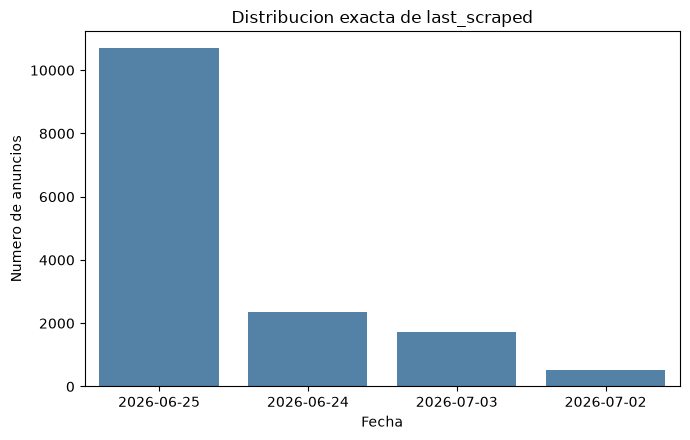

In [104]:
fecha_scraped = pd.to_datetime(listings["last_scraped"])
conteo_fechas = fecha_scraped.dt.date.value_counts()
print(f"nulos={fecha_scraped.isna().sum()}")
print(conteo_fechas)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=[str(f) for f in conteo_fechas.index], y=conteo_fechas.values, color="steelblue", ax=ax)
ax.set_xlabel("Fecha")
ax.set_ylabel("Número de anuncios")
ax.set_title("Distribución exacta de last_scraped")
fig.tight_layout()
fig.savefig("../graficos_exploracion/listings/last_scraped_fechas.png", dpi=100)
plt.show()

0 nulos, 4 fechas distintas, todas en 2026: 2026-06-24 (2.340), 2026-06-25
(10.695), 2026-07-02 (520), 2026-07-03 (1.738) — idéntica a
`calendar_last_scraped`.

### `latitude`

Coordenada de latitud exacta del alojamiento.

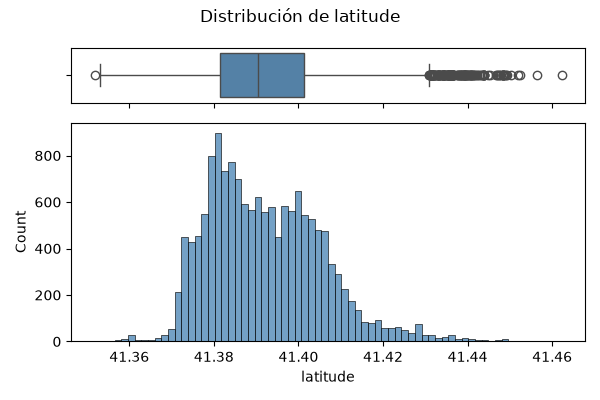

Q1=41.3815  mediana=41.3905  Q3=41.4012  min=41.3518  max=41.4622
nulos=0


In [105]:
ruta = graficar_numerica(listings["latitude"], "latitude", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["latitude"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1:.4f}  mediana={mediana:.4f}  Q3={q3:.4f}  min={s.min():.4f}  max={s.max():.4f}")
print(f"nulos={s.isna().sum()}")

0 nulos. Rango: 41,3518 a 41,4622 — coherente con que todo el dataset
está dentro de Barcelona (la ciudad está alrededor de 41,38 grados).

### Extra: `latitude` + `longitude` como mapa de dispersión

Juntas forman coordenadas reales — un scatter de `longitude` (x) vs `latitude` (y) reproduce la forma de Barcelona sin necesitar un mapa de verdad.

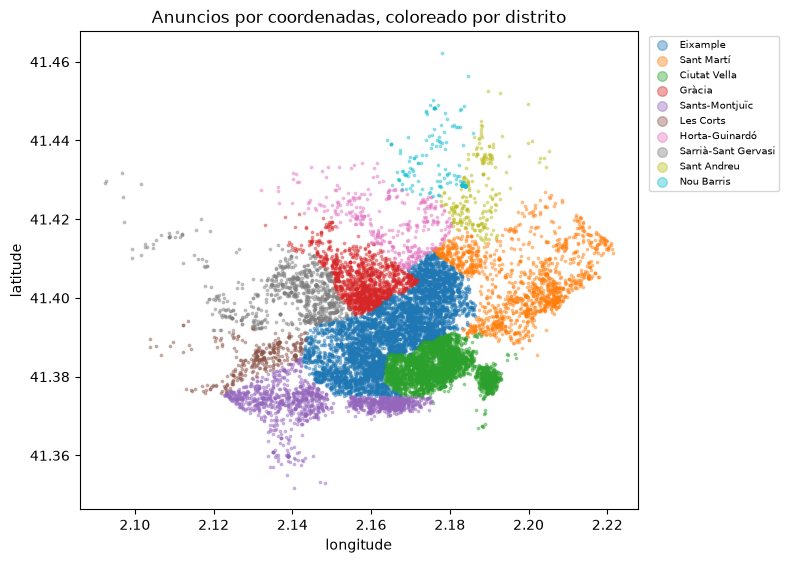

In [106]:
fig, ax = plt.subplots(figsize=(8, 7))
for distrito in listings["neighbourhood_group_cleansed"].unique():
    sub = listings[listings["neighbourhood_group_cleansed"] == distrito]
    ax.scatter(sub["longitude"], sub["latitude"], s=3, alpha=0.4, label=distrito)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Anuncios por coordenadas, coloreado por distrito")
ax.legend(markerscale=4, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/mapa_distrito.png", dpi=100)
plt.show()

### Extra: mapa de dispersión coloreado por ingreso estimado

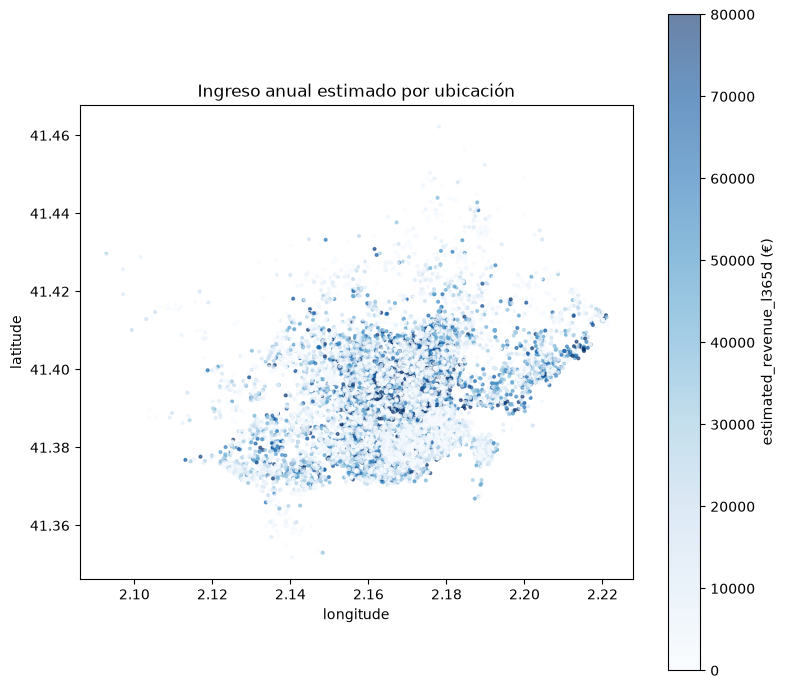

In [107]:
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(listings["longitude"], listings["latitude"], c=listings["estimated_revenue_l365d"],
                 s=4, alpha=0.6, cmap="Blues", vmax=listings["estimated_revenue_l365d"].quantile(0.95))
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Ingreso anual estimado por ubicación")
ax.set_aspect("equal")
fig.colorbar(sc, ax=ax, label="estimated_revenue_l365d (€)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/mapa_revenue.png", dpi=100)
plt.show()

El mapa por distrito confirma visualmente que `neighbourhood_group_cleansed` es consistente con la geografía real (sin anuncios mal asignados a un distrito equivocado, al menos a simple vista).

El mapa de ingresos muestra concentración de tonos más oscuros (mayor ingreso) hacia el centro-este de la ciudad, coherente con que Eixample ya era el distrito de mayor ingreso medio en el cruce anterior — el patrón geográfico no está solo en la agregación por distrito, se ve también a nivel de anuncio individual.

### `license`

Texto con el número de licencia turística del alojamiento. Caso estrella de gobernanza del notebook 01.

No se usa `graficar_categorica` aquí: los valores de `license` son textos largos con HTML sin limpiar (`<br />`), no caben legibles como etiqueta de eje. Se numeran las barras y se muestra el texto completo en una tabla.

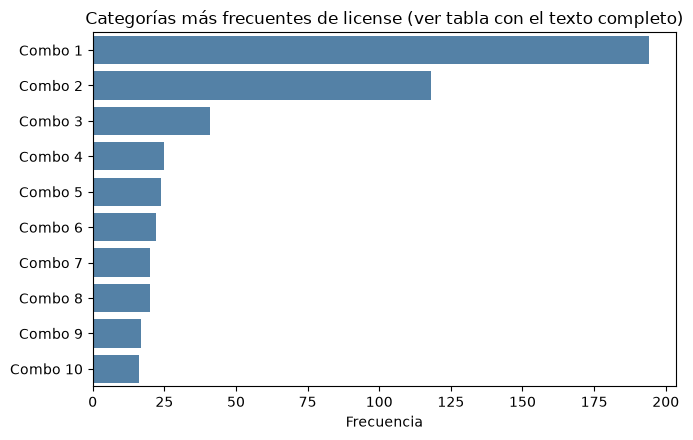

nulos=3043 (19.9%)  valores unicos=10371
contiene HUTB=7416



,Combo,Frecuencia,Contenido completo
0,Combo 1,194,Barcelona - Regional registration number<br />Exempt - seasonal rental
1,Combo 2,118,Spain - National registration number<br />Exempt - tourist apartment<br /><br />Barcelona - Regional registration number<br />Exempt - seasonal rental
2,Combo 3,41,Spain - National registration number<br />ESFCNT00000805900063465600000000000000000000000000001<br /><br />Barcelona - Regional registration number<br />Exempt - seasonal rental
3,Combo 4,25,Barcelona - Regional registration number<br />Exempt - seasonal rental<br /><br />Spain - National registration number<br />Exempt - tourist apartment
4,Combo 5,24,Barcelona - Regional registration number<br />HUTB012407
5,Combo 6,22,Barcelona - Regional registration number<br />AJ000593<br /><br />Spain - National registration number<br />Exempt - hostel
6,Combo 7,20,Barcelona - Regional registration number<br />HUTB-012457<br /><br />Spain - National registration number<br />ESFCTU00000812000014847100000000000000000HUTB-0124575
7,Combo 8,20,Spain - National registration number<br />ESFCTU00000807200005651800000000000000000000000071101<br /><br />Barcelona - Regional registration number<br />HUTB-007110
8,Combo 9,17,Barcelona - Regional registration number<br />HB-004525
9,Combo 10,16,Barcelona - Regional registration number<br />AJ000517<br /><br />Spain - National registration number<br />Exempt - hostel


In [108]:
conteo = listings["license"].value_counts().head(10)
etiquetas_numeradas = [f"Combo {i+1}" for i in range(len(conteo))]

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=conteo.values, y=etiquetas_numeradas, color="steelblue", ax=ax)
ax.set_xlabel("Frecuencia")
ax.set_ylabel("")
ax.set_title("Categorías más frecuentes de license (ver tabla con el texto completo)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/listings/license_categorica.png", dpi=100)
plt.show()

s = listings["license"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)  valores únicos={s.nunique()}")
print(f"contiene HUTB={s.astype(str).str.contains('HUTB').sum()}")
print()

tabla_combos = pd.DataFrame({
    "Combo": etiquetas_numeradas,
    "Frecuencia": conteo.values,
    "Contenido completo": conteo.index,
})
pd.set_option("display.max_colwidth", None)
display(tabla_combos)

Este campo debería contener el número de licencia turística del alojamiento. Hay dos tipos posibles, según la normativa:

- **HUTB**: el registro catalán ("Habitatge d'Ús Turístic"), el tradicional.
- **NRUA**: el nuevo registro estatal español, obligatorio desde julio de 2025. Puede convivir con el HUTB, no lo sustituye.

El problema del gráfico automático: el campo es texto libre, con HTML sin limpiar y a veces con los dos números de registro (HUTB y NRUA) concatenados en la misma celda. Cada barra del gráfico es el texto completo de una fila entera, no una categoría real, por eso sale cortado e ilegible.

Lo que se encontró al investigarlo a fondo (ya documentado en notebook 01 y notebook 04):

- El 21,1% de los anuncios no tiene una licencia que se pueda verificar.
- 5.470 anuncios tienen dos códigos HUTB concatenados en el mismo campo, además de HTML sin limpiar.
- Los anfitriones profesionales están sobrerrepresentados en el nuevo registro NRUA (65,7% frente al resto) — probablemente porque tramitan el registro nuevo más rápido, no porque oculten algo.
- El problema de licencia no verificable varía mucho según el barrio: del 16,1% en Eixample al 33,1% en Nou Barris.

Ejemplo real de una fila del dataset: "Barcelona - Regional registration number (HUTB) / Exempt - seasonal rental" — muestra que un mismo anuncio puede declarar su registro catalán y, aparte, decir que está exento del registro estatal, los dos datos juntos en el mismo texto.

### Cruce: `license` según tipo de anfitrión

¿Quién reporta mejor la licencia en Airbnb, particulares o profesionales? Usa la misma clasificación de 5 categorías ya definida y validada en el notebook 01 (`clasifica_licencia`), recreada aquí para no depender de ese notebook.

license_categoria,Con numero HUTB (registro catalan),"Con numero NRUA (registro estatal, desde jul. 2025)",Exento (declarado),Otro / no clasificable,Sin dato
tipo_anfitrion,,,,,
Particular,46.3,2.8,27.4,1.6,22.0
Profesional,49.6,17.5,19.9,0.0,13.0


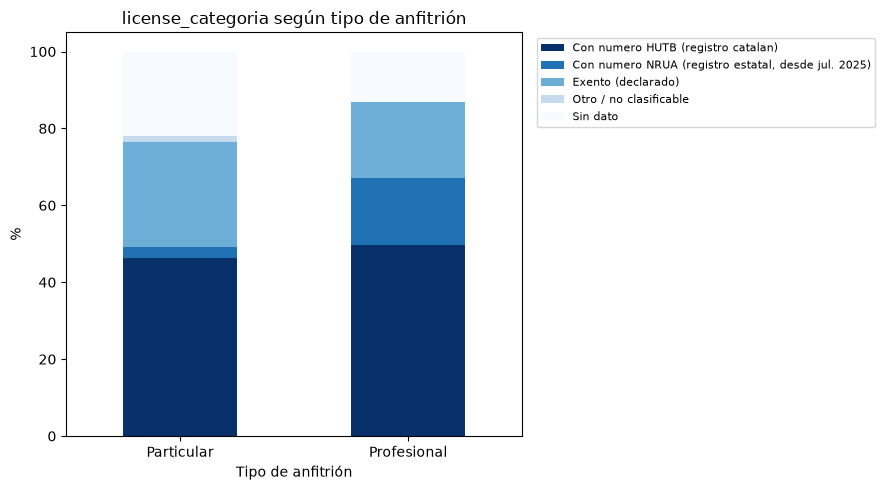

In [109]:
import re

def clasifica_licencia(valor):
    if pd.isna(valor):
        return "Sin dato"
    valor = str(valor)
    if "Exempt" in valor:
        return "Exento (declarado)"
    if re.search(r"HUTB[-]?\d{4,}", valor, flags=re.IGNORECASE):
        return "Con número HUTB (registro catalan)"
    if re.search(r"National registration number", valor, flags=re.IGNORECASE):
        return "Con número NRUA (registro estatal, desde jul. 2025)"
    return "Otro / no clasificable"

listings["license_categoria"] = listings["license"].apply(clasifica_licencia)

orden_cat = ["Con número HUTB (registro catalan)", "Con número NRUA (registro estatal, desde jul. 2025)",
             "Exento (declarado)", "Otro / no clasificable", "Sin dato"]
tabla_cruce = pd.crosstab(listings["tipo_anfitrion"], listings["license_categoria"], normalize="index") * 100
tabla_cruce = tabla_cruce[orden_cat]
display(tabla_cruce.round(1))

fig, ax = plt.subplots(figsize=(9, 5))
tabla_cruce.plot(kind="bar", stacked=True, ax=ax, colormap="Blues_r")
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("%")
ax.set_title("license_categoria según tipo de anfitrión")
plt.xticks(rotation=0)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/license_tipo_anfitrion.png", dpi=100)
plt.show()

Los profesionales reportan la licencia algo mejor: menos "Sin dato" (13,0% vs. 22,0% en particulares) y 0% de "Otro / no clasificable" (vs. 1,6%). También adoptan mucho más rápido el nuevo registro NRUA (17,5% vs. 2,8%, unas 6,3 veces más) — tiene sentido, una gestora con muchos anuncios tiene más que perder si no se pone al día con la normativa vigente desde julio de 2025. Los particulares declaran "exento" con más frecuencia (27,4% vs. 19,9%), razonable si es más probable que un particular que alquila su propia vivienda ocasionalmente cumpla los requisitos de exención.

Importante: "Sin dato" no prueba que el anuncio no tenga licencia real, solo que el campo `license` de Airbnb está vacío — puede ser un anuncio con licencia pero sin reportarla a la plataforma. Lo que dicen estos datos es "los profesionales reportan más y mejor la licencia en Airbnb", no necesariamente "los profesionales tienen más licencias reales" — son preguntas distintas, y solo la primera está respaldada aquí.

### Cruce: tener licencia reconocible según ingresos y ocupación

Mismo tipo de pregunta que con `host_has_profile_pic`/`host_identity_verified`: ¿tener un número de licencia reconocible (HUTB o NRUA) se traduce en más reservas reales?

,estimated_revenue_l365d,estimated_occupancy_l365d,review_scores_rating
tiene_licencia_reconocible,,,
False,0.0,0.0,4.775
True,12408.0,66.0,4.720


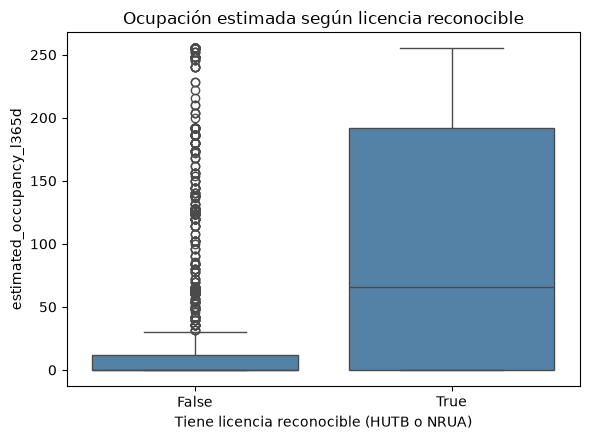

In [110]:
listings["tiene_licencia_reconocible"] = ~listings["license_categoria"].isin(["Sin dato", "Otro / no clasificable"])

tabla = listings.groupby("tiene_licencia_reconocible")[["estimated_revenue_l365d", "estimated_occupancy_l365d", "review_scores_rating"]].median()
display(tabla)

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=listings, x="tiene_licencia_reconocible", y="estimated_occupancy_l365d", order=[False, True], color="steelblue", ax=ax)
ax.set_xlabel("Tiene licencia reconocible (HUTB o NRUA)")
ax.set_ylabel("estimated_occupancy_l365d")
ax.set_title("Ocupación estimada según licencia reconocible")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/licencia_ocupacion.png", dpi=100)
plt.show()

Resultado contundente, en la misma línea que `host_has_profile_pic` e `host_identity_verified`: los anuncios sin licencia reconocible tienen mediana de ingreso y ocupación de **0**, frente a 12.408€ y 66 días respectivamente en los que sí tienen una. La puntuación de reseñas casi no cambia (4,78 vs. 4,72) — otra vez, lo que cambia es si se consigue reservar, no la calidad percibida de quien ya reservó.

No se puede confirmar con certeza la dirección de la causalidad (¿la falta de licencia visible reduce la confianza y por tanto las reservas, o son anuncios que de por sí no se reservan y por eso nadie se molesta en declarar una licencia?), pero el patrón es consistente con el resto de señales de confianza/legitimidad ya vistas en este notebook.

### Cruce: problema de `license` según distrito

¿El porcentaje de anuncios sin licencia reconocible (`license_categoria` en "Sin dato" u "Otro / no clasificable") es igual en toda Barcelona, o varía según el distrito? Este mismo hallazgo ya se documentó como L7 en el notebook 01 (gobernanza); aquí se recalcula con código propio y se añade el gráfico, que no estaba ahí.

,sum,count,pct
neighbourhood_group_cleansed,,,
Nou Barris,54,163,33.1
Horta-Guinardó,108,358,30.2
Sant Andreu,67,225,29.8
Ciutat Vella,844,3247,26.0
Sant Martí,371,1436,25.8
Gràcia,326,1366,23.9
Sants-Montjuïc,307,1448,21.2
Sarrià-Sant Gervasi,156,888,17.6
Les Corts,56,327,17.1


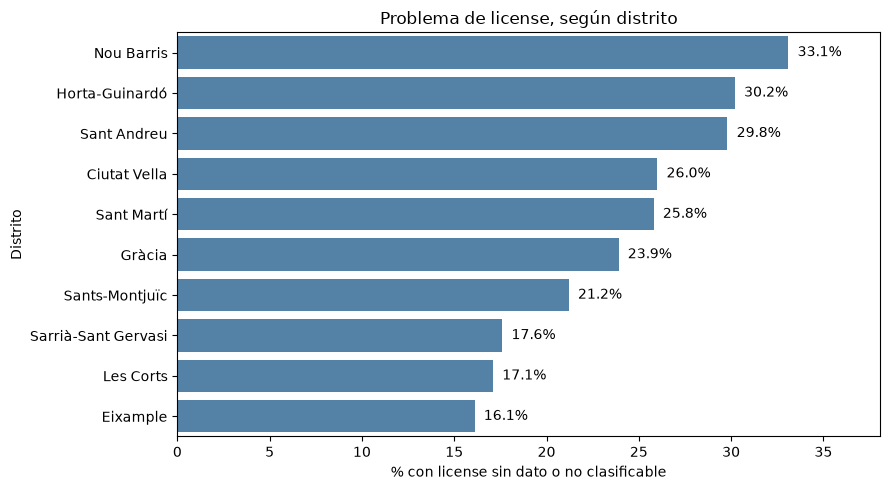

In [111]:
listings["license_problema"] = listings["license_categoria"].isin(["Sin dato", "Otro / no clasificable"])

por_distrito = listings.groupby("neighbourhood_group_cleansed")["license_problema"].agg(["sum", "count", "mean"])
por_distrito = por_distrito.sort_values("mean", ascending=False)
por_distrito["pct"] = (por_distrito["mean"] * 100).round(1)
display(por_distrito[["sum", "count", "pct"]])

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=por_distrito["pct"], y=por_distrito.index, color="steelblue", ax=ax)
for i, v in enumerate(por_distrito["pct"]):
    ax.text(v + 0.5, i, f"{v}%", va="center")
ax.set_xlim(0, por_distrito["pct"].max() * 1.15)
ax.set_xlabel("% con license sin dato o no clasificable")
ax.set_ylabel("Distrito")
ax.set_title("Problema de license, según distrito")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/licencia_distrito.png", dpi=100)
plt.show()

Varía bastante según distrito: de 16,1% en Eixample (938 de 5.835) a 33,1% en Nou Barris (54 de 163, más del doble). Los distritos más periféricos (Nou Barris, Horta-Guinardó, Sant Andreu) tienen peor tasa de licencia reconocible que los más céntricos (Eixample, Les Corts, Sarrià-Sant Gervasi) — mismo tipo de patrón ya visto en otras variables de este notebook, aunque aquí sin una explicación confirmada de la causa.

### Cruce: problema de `license` según distrito y tipo de anfitrión

¿La peor tasa de licencia reconocible en los distritos periféricos es un problema de particulares, de profesionales, o de ambos por igual?

pct  count
neighbourhood_group_cleansed tipo_anfitrion             
Ciutat Vella                 Particular      27.5   2698
                             Profesional     18.4    549
Eixample                     Particular      18.1   4151
                             Profesional     11.0   1684
Gràcia                       Particular      23.7   1069
                             Profesional     24.6    297
Horta-Guinardó               Particular      33.0    291
                             Profesional     17.9     67
Les Corts                    Particular      18.8    272
                             Profesional      9.1     55
Nou Barris                   Particular      50.5    105
                             Profesional      1.7     58
Sant Andreu                  Particular      36.2    185
                             Profesional      0.0     40
Sant Martí                   Particular      27.3   1246
                             Profesional     16.3    190
Sants-Montjuïc               Particular      25.1   1167
                             Profesional      5.0    281
Sarrià-Sant Gervasi          Particular      20.8    544
                             Profesional     12.5    344

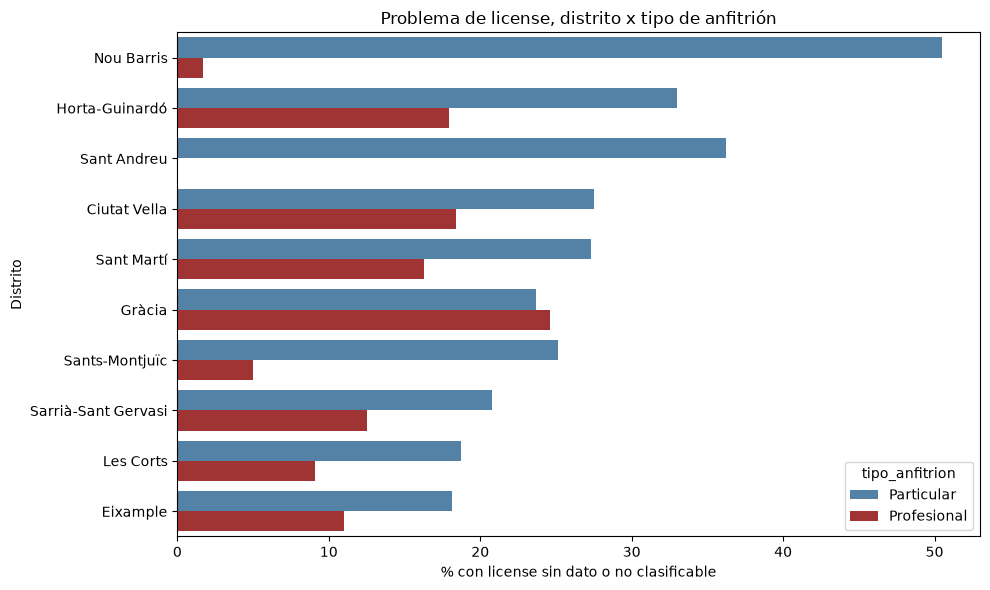

In [112]:
tabla = listings.groupby(["neighbourhood_group_cleansed", "tipo_anfitrion"])["license_problema"].agg(["mean", "count"])
tabla["pct"] = (tabla["mean"] * 100).round(1)
display(tabla[["pct", "count"]])

orden_distrito = listings.groupby("neighbourhood_group_cleansed")["license_problema"].mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=listings, y="neighbourhood_group_cleansed", x=listings["license_problema"].astype(int) * 100,
            hue="tipo_anfitrion", order=orden_distrito, hue_order=["Particular", "Profesional"],
            palette={"Particular": "steelblue", "Profesional": "firebrick"}, estimator="mean", errorbar=None, ax=ax)
ax.set_xlabel("% con license sin dato o no clasificable")
ax.set_ylabel("Distrito")
ax.set_title("Problema de license, distrito x tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/licencia_distrito_tipo_anfitrion.png", dpi=100)
plt.show()

Los particulares tienen peor tasa en **9 de los 10 distritos** — la única excepción es Gràcia, donde los profesionales están ligeramente peor (24,6% vs. 23,9% particular). Los casos más extremos están en los distritos periféricos pequeños: en Nou Barris, 50,5% de los particulares tiene problema de licencia frente a solo 1,7% de los profesionales; en Sant Andreu, 36,2% de los particulares frente a 0% de los profesionales (los 40 anuncios profesionales de ese distrito tienen todos licencia reconocible).

Esto es coherente con el patrón ya visto en el cruce general (los profesionales reportan mejor la licencia), pero muestra que el problema real de completitud está concentrado sobre todo en los particulares de los distritos más alejados del centro.

### Cruce: problema de `license` según `room_type`

¿El tipo de alojamiento (piso entero vs. habitación) influye en si tiene licencia reconocible?

,pct,count
room_type,,
Private room,47.9,4262
Hotel room,27.9,68
Shared room,20.2,119
Entire home/apt,10.5,10844


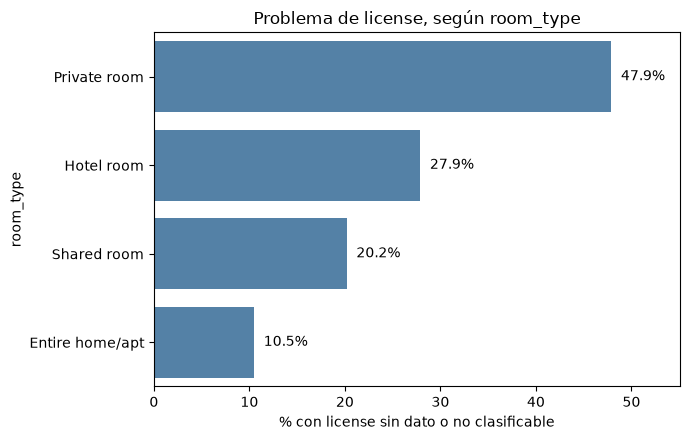


Dentro de 'Private room' especificamente, por tipo de anfitrion:
                    mean  count
tipo_anfitrion                 
Particular      0.500140   3559
Profesional     0.371266    703

Composicion de 'Private room' por tipo de anfitrion:
tipo_anfitrion
Particular     3559
Profesional     703
Name: count, dtype: int64
tipo_anfitrion
Particular     83.5
Profesional    16.5
Name: proportion, dtype: float64


In [113]:
tabla = listings.groupby("room_type")["license_problema"].agg(["mean", "count"])
tabla["pct"] = (tabla["mean"] * 100).round(1)
tabla = tabla.sort_values("pct", ascending=False)
display(tabla[["pct", "count"]])

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=tabla["pct"], y=tabla.index, color="steelblue", ax=ax)
for i, v in enumerate(tabla["pct"]):
    ax.text(v + 1, i, f"{v}%", va="center")
ax.set_xlim(0, tabla["pct"].max() * 1.15)
ax.set_xlabel("% con license sin dato o no clasificable")
ax.set_ylabel("room_type")
ax.set_title("Problema de license, según room_type")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/licencia_room_type.png", dpi=100)
plt.show()

print()
print("Dentro de 'Private room' especificamente, por tipo de anfitrión:")
pr = listings[listings["room_type"] == "Private room"]
print(pr.groupby("tipo_anfitrion")["license_problema"].agg(["mean", "count"]))
print()
print("Composición de 'Private room' por tipo de anfitrión:")
print(pr["tipo_anfitrion"].value_counts())
print((pr["tipo_anfitrion"].value_counts(normalize=True) * 100).round(1))

El hallazgo más fuerte de toda la exploración de `license`: 47,9% de las habitaciones privadas (2.041 de 4.262) no tiene licencia reconocible, frente a solo 10,5% de los pisos enteros — casi 5 veces más. "Shared room" (20,2%) y "Hotel room" (27,9%) quedan en un punto intermedio, aunque con muestras mucho más chicas.

Tiene más peso explicativo que `tipo_anfitrion` o el distrito por separado: la normativa de licencia turística en Barcelona está pensada sobre todo para el alquiler de la vivienda completa, así que tiene sentido que los anfitriones que alquilan solo una habitación de su propia casa declaren con menos frecuencia (o no necesiten) un número de licencia del mismo tipo.

Dentro de "Private room" específicamente, el problema de licencia también es peor en particulares que en profesionales (50,0% vs. 37,1%) — consistente con el patrón general ya visto. Pero "Private room" es mayoritariamente de particulares (83,5%, 3.559 de 4.262), así que el mal resultado agregado de la categoría (47,9%) refleja sobre todo el peso de ese grupo mayoritario, no una excepción al patrón de que los profesionales reportan mejor la licencia.

### `listing_url`

Enlace al anuncio en Airbnb, construido a partir de `id`.

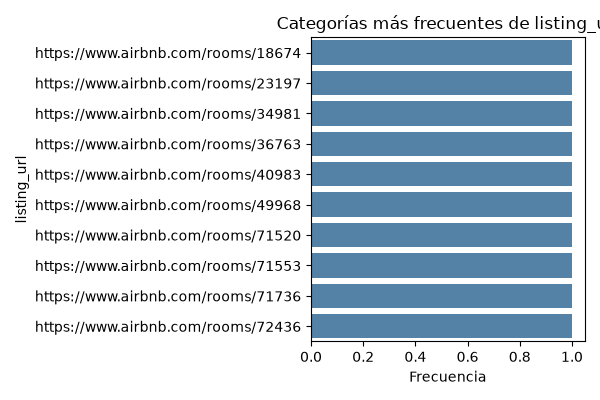

nulos=0  valores unicos=15293 de 15293


In [114]:
ruta = graficar_categorica(listings["listing_url"], "listing_url", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["listing_url"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()} de {len(s)}")

0 nulos, 15.293 valores únicos de 15.293 — cada anuncio tiene su propio enlace, sin repetir ninguno.

### Extra: mapa de dispersión coloreado por tipo de anfitrión

¿Los profesionales se concentran en alguna zona concreta, o están repartidos igual que los particulares?

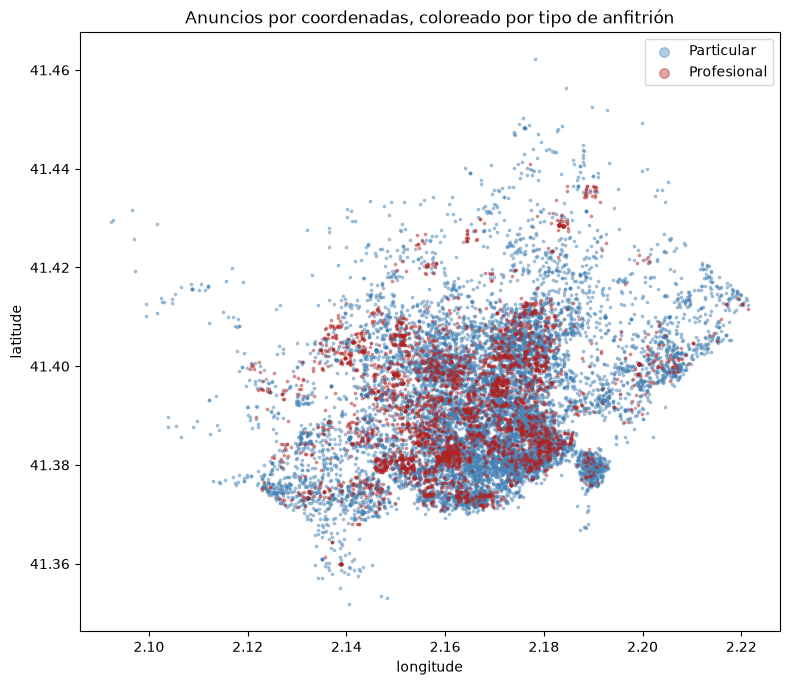

In [115]:
fig, ax = plt.subplots(figsize=(8, 7))
for tipo, color in [("Particular", "steelblue"), ("Profesional", "firebrick")]:
    sub = listings[listings["tipo_anfitrion"] == tipo]
    ax.scatter(sub["longitude"], sub["latitude"], s=3, alpha=0.4, color=color, label=tipo)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Anuncios por coordenadas, coloreado por tipo de anfitrión")
ax.legend(markerscale=4)
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/mapa_tipo_anfitrion.png", dpi=100)
plt.show()

Los profesionales (rojo) están presentes en toda la ciudad, pero con una concentración visible en el núcleo central (zona de Eixample), donde se solapan densamente con los particulares — no es exclusivo, pero sí más denso que en la periferia. Consistente con los distritos de mayor proporción profesional ya vistos (Sarrià-Sant Gervasi, Eixample): el mapa muestra que esa concentración no es solo una cifra agregada por distrito, se ve también a nivel de anuncio individual.

### `longitude`

Coordenada de longitud exacta del alojamiento.

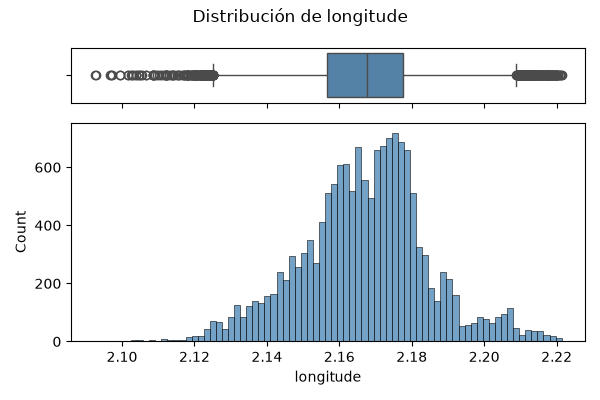

Q1=2.1565  mediana=2.1676  Q3=2.1775  min=2.0924  max=2.2214
nulos=0


In [116]:
ruta = graficar_numerica(listings["longitude"], "longitude", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["longitude"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1:.4f}  mediana={mediana:.4f}  Q3={q3:.4f}  min={s.min():.4f}  max={s.max():.4f}")
print(f"nulos={s.isna().sum()}")

0 nulos. Rango: 2,0924 a 2,2214 — coherente con que todo el dataset está dentro de Barcelona (la ciudad está alrededor de 2,17 grados). Hay un segundo pico más pequeño hacia 2,20-2,21: verificado, 469 anuncios en ese rango, el 98,7% (463) en el distrito Sant Martí — confirma lo que ya se ve en el mapa de coordenadas de la sección de `latitude`.

### `maximum_maximum_nights`

El número máximo de noches más alto que llega a aceptar el anfitrión a lo largo del año (el mayor valor que toma `maximum_nights` en todo el calendario del anuncio, que puede variar por temporada).

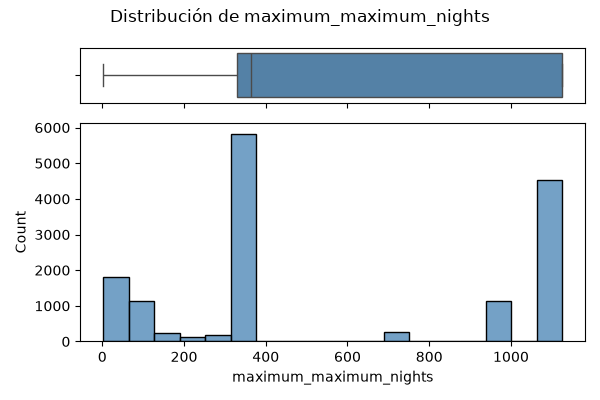

nulos=1
maximum_maximum_nights
1125.0    4479
365.0     4385
999.0     1128
330.0      799
125.0      589
Name: count, dtype: int64


In [117]:
ruta = graficar_numerica(listings["maximum_maximum_nights"], "maximum_maximum_nights", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["maximum_maximum_nights"]
print(f"nulos={s.isna().sum()}")
print(s.value_counts().head(5))

1 nulo. Los valores más frecuentes son 1.125 (4.479), 365 (4.385) y 999 (1.128) — los mismos "valores de relleno" que `maximum_nights`: números redondos y enormes que no parecen decisiones reales de cada anfitrión, sino un valor por defecto del sistema cuando no se configura un límite real.

### Redundancia con `maximum_nights`, y variación estacional real según `room_type`

Cruzar `maximum_maximum_nights` directamente no aportaría nada nuevo: coincide con `maximum_nights` en el 99,99% de las filas. En su lugar, se compara contra `minimum_maximum_nights` (el límite más bajo del año) para ver qué anuncios sí tienen variación estacional real en su política de estancia máxima.

maximum_maximum_nights == maximum_nights en el 99.99% de las filas

Anuncios con variacion estacional real: 1534 de 15293


,pct,count
room_type,,
Shared room,34.5,119
Hotel room,32.4,68
Entire home/apt,10.7,10844
Private room,7.3,4262


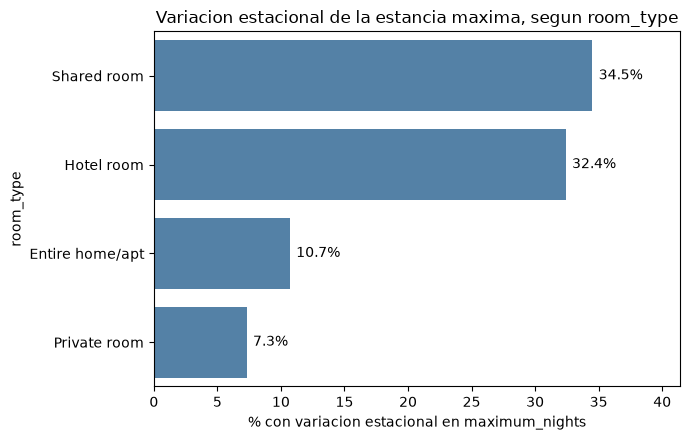

In [118]:
coincide = (listings["maximum_maximum_nights"] == listings["maximum_nights"]).mean() * 100
print(f"maximum_maximum_nights == maximum_nights en el {coincide:.2f}% de las filas")

listings["con_variacion_estacional"] = (listings["maximum_maximum_nights"] - listings["minimum_maximum_nights"]) > 0
print(f"\nAnuncios con variación estacional real: {listings['con_variacion_estacional'].sum()} de {len(listings)}")

tabla = listings.groupby("room_type")["con_variacion_estacional"].agg(["mean", "count"])
tabla["pct"] = (tabla["mean"] * 100).round(1)
tabla = tabla.sort_values("pct", ascending=False)
display(tabla[["pct", "count"]])

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=tabla["pct"], y=tabla.index, color="steelblue", ax=ax)
for i, v in enumerate(tabla["pct"]):
    ax.text(v + 0.5, i, f"{v}%", va="center")
ax.set_xlim(0, tabla["pct"].max() * 1.2)
ax.set_xlabel("% con variación estacional en maximum_nights")
ax.set_ylabel("room_type")
ax.set_title("Variación estacional de la estancia máxima, según room_type")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/variacion_estacional_room_type.png", dpi=100)
plt.show()

Solo el 10,0% de los anuncios (1.534 de 15.293) tiene una política de estancia máxima que varía a lo largo del año — el 90% restante tiene el mismo límite todo el tiempo, consistente con lo ya visto (valores de relleno fijos como 1.125 o 365).

Entre los que sí varían, el patrón por `room_type` es interesante: "Shared room" (34,5%) y "Hotel room" (32,4%) tienen mucha más variación estacional que "Private room" (7,3%) o "Entire home/apt" (10,7%) — aunque son categorías con pocos anuncios en total, así que esta diferencia debe tomarse con cautela.

### `maximum_minimum_nights`

El anfitrión puede exigir más noches en temporada alta que en temporada baja. Esta columna es la más exigente de esas condiciones: cuántas noches pide como mínimo cuando más lo exige en todo el año.

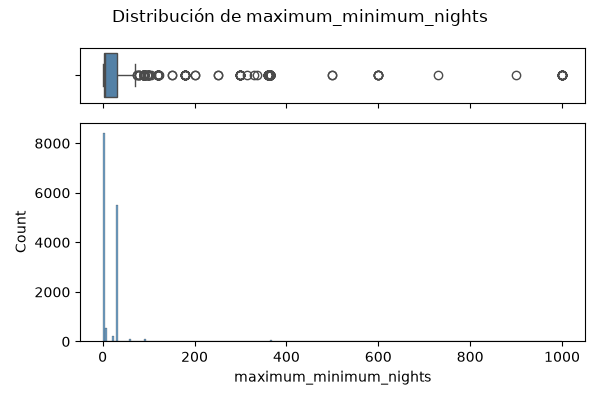

Q1=3.0  mediana=5.0  Q3=31.0  max=1000.0
nulos=1


In [119]:
ruta = graficar_numerica(listings["maximum_minimum_nights"], "maximum_minimum_nights", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["maximum_minimum_nights"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")

Percentiles: 25% = 3, mediana = 5, 75% = 31. Máximo 1.000 noches. 1 nulo. Esta columna sí varía mucho más que `maximum_maximum_nights` — confirma que el mínimo de noches se ajusta más por temporada que el máximo.

### Cruce: `maximum_minimum_nights` según `room_type` y tipo de anfitrión

A diferencia de `maximum_maximum_nights`, esta columna no es redundante con su equivalente estático: solo coincide con `minimum_nights` en el 57,3% de las filas. Se comprueba si el pico de exigencia (no solo el valor base) también es más alto en los profesionales.

maximum_minimum_nights == minimum_nights en el 57.3% de las filas



median   mean  count
room_type       tipo_anfitrion                      
Entire home/apt Particular         5.0  17.51   7992
                Profesional        5.0  24.59   2851
Hotel room      Particular         3.0   2.87     63
                Profesional        5.0   5.00      5
Private room    Particular         3.0  15.37   3559
                Profesional       32.0  36.19    703
Shared room     Particular         1.0   3.30    114
                Profesional       32.0  37.60      5

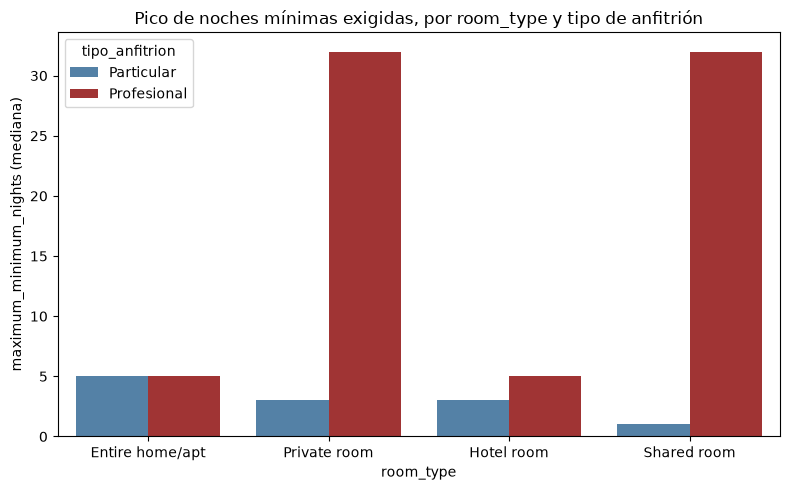

In [120]:
coincide = (listings["maximum_minimum_nights"] == listings["minimum_nights"]).mean() * 100
print(f"maximum_minimum_nights == minimum_nights en el {coincide:.1f}% de las filas")
print()

tabla = listings.groupby(["room_type", "tipo_anfitrion"])["maximum_minimum_nights"].agg(["median", "mean", "count"])
display(tabla.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=listings, x="room_type", y="maximum_minimum_nights", hue="tipo_anfitrion",
            order=["Entire home/apt", "Private room", "Hotel room", "Shared room"], hue_order=["Particular", "Profesional"],
            estimator="median", errorbar=None, palette={"Particular": "steelblue", "Profesional": "firebrick"}, ax=ax)
ax.set_xlabel("room_type")
ax.set_ylabel("maximum_minimum_nights (mediana)")
ax.set_title("Pico de noches mínimas exigidas, por room_type y tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/maximum_minimum_nights_room_type_tipo.png", dpi=100)
plt.show()

El patrón se mantiene y se acentúa: en "Private room", el pico de exigencia de los profesionales llega a mediana 32 noches (media 36,19), un poco más alto incluso que la media de `minimum_nights` (32,04) — en temporada de mayor exigencia, piden aún más noches que su mínimo habitual. En "Entire home/apt" la mediana es igual en ambos grupos (5 noches), pero la media de los profesionales (24,59) es bastante más alta que la de particulares (17,51), señal de que algunos anuncios profesionales de piso entero sí exigen picos de estancia larga, aunque la mayoría no.

### `maximum_nights_avg_ntm`

El promedio de noches máximo que permite el anfitrión, calculado sobre los próximos 365 días ("ntm" = *next twelve months*).

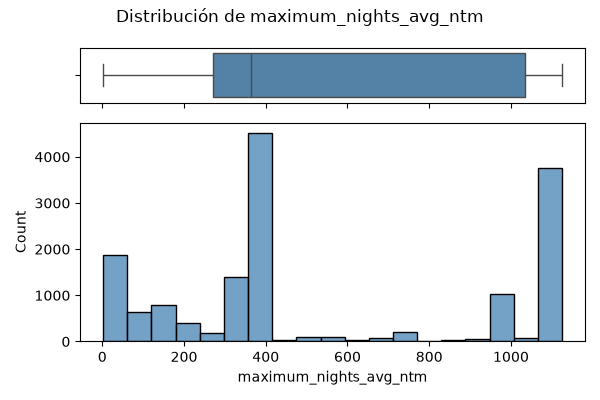

Q1=270.0  mediana=365.0  Q3=1033.8  max=1125.0
nulos=0


In [121]:
ruta = graficar_numerica(listings["maximum_nights_avg_ntm"], "maximum_nights_avg_ntm", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["maximum_nights_avg_ntm"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")

Percentiles: 25% = 270, mediana = 365, 75% = 1.033,8. Máximo 1.125. 0 nulos. Reaparecen los mismos valores de relleno (365, 1.125) también presentes en `maximum_nights` y `maximum_maximum_nights`. 1.125 noches son más de 3 años seguidos (1.125 / 365 ≈ 3,08 años) — poco creíble como decisión real de un anfitrión, refuerza que sea un valor técnico del sistema, no una elección consciente.

### Chequeo de consistencia: `maximum_nights_avg_ntm` entre `minimum_maximum_nights` y `maximum_maximum_nights`

Al ser un promedio, `maximum_nights_avg_ntm` debería estar siempre entre el mínimo y el máximo del año (`minimum_maximum_nights` y `maximum_maximum_nights`) — se comprueba si eso se cumple.

In [122]:
dentro_rango = (listings["maximum_nights_avg_ntm"] >= listings["minimum_maximum_nights"]) & (listings["maximum_nights_avg_ntm"] <= listings["maximum_maximum_nights"])
print(f"Dentro del rango esperado: {dentro_rango.sum()} de {len(listings)}")

fuera = listings[~dentro_rango]
print(f"Fuera del rango: {len(fuera)}")
display(fuera[["minimum_maximum_nights", "maximum_maximum_nights", "maximum_nights_avg_ntm"]])

Dentro del rango esperado: 15292 de 15293
Fuera del rango: 1


,minimum_maximum_nights,maximum_maximum_nights,maximum_nights_avg_ntm
3520,NaN,NaN,333.0


Se cumple en el 99,99% de los casos (15.292 de 15.293) — la única excepción es la fila que ya se conocía con `minimum_maximum_nights`/`maximum_maximum_nights` nulos (el único nulo del grupo `maximum_nights`), no un problema nuevo. Confirma que estas tres columnas son matemáticamente consistentes entre sí en todo el dataset.

### `maximum_nights`

Número máximo de noches que el anfitrión permite reservar de una vez, valor actual del anuncio (no todo el calendario).

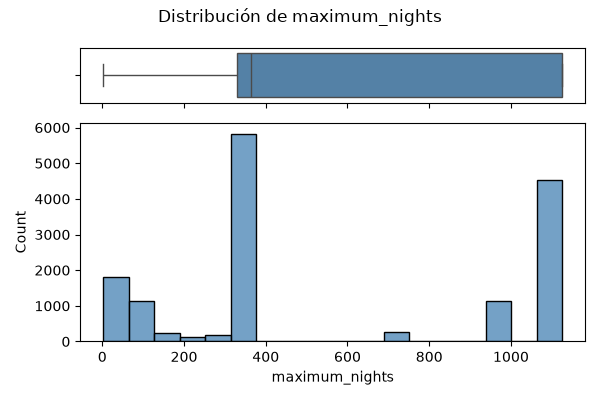

nulos=1
maximum_nights
1125.0    4479
365.0     4385
999.0     1128
330.0      799
125.0      589
Name: count, dtype: int64
con >= 365: 10351 (67.7%)


In [123]:
ruta = graficar_numerica(listings["maximum_nights"], "maximum_nights", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["maximum_nights"]
print(f"nulos={s.isna().sum()}")
print(s.value_counts().head(5))
print(f"con >= 365: {(s>=365).sum()} ({(s>=365).mean()*100:.1f}%)")

1 nulo. Valores más frecuentes: 1.125 (4.479, 29,3%), 365 (4.385, 28,7%), 999 (1.128, 7,4%) — los mismos valores de relleno del resto del grupo. El 67,7% de los anuncios (10.351) tiene `maximum_nights >= 365` (un año o más), reforzando que no son límites reales configurados individualmente.

### `minimum_maximum_nights`

El límite de noches más bajo (más restrictivo) que llega a poner el anfitrión en alguna fecha del año, de todos los que varían por temporada.

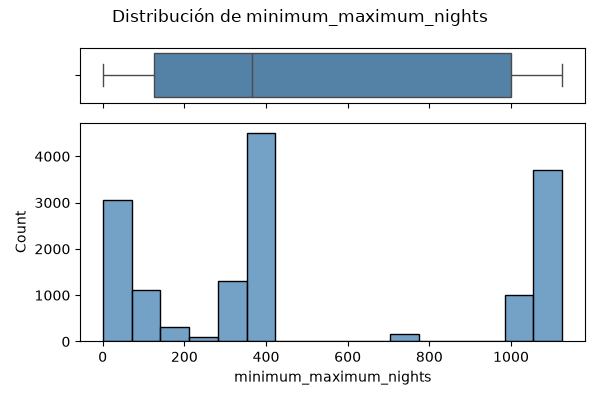

Q1=125.0  mediana=365.0  Q3=999.0
nulos=1


In [124]:
ruta = graficar_numerica(listings["minimum_maximum_nights"], "minimum_maximum_nights", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["minimum_maximum_nights"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}")
print(f"nulos={s.isna().sum()}")

Percentiles: 25% = 125, mediana = 365, 75% = 999. 1 nulo. Mismo patrón que el resto del grupo: los valores de relleno (365, 999, 1.125) dominan la distribución.

### `minimum_minimum_nights`

El mínimo de noches más bajo (menos exigente) que llega a pedir el anfitrión en alguna fecha del año, de todos los que varían por temporada.

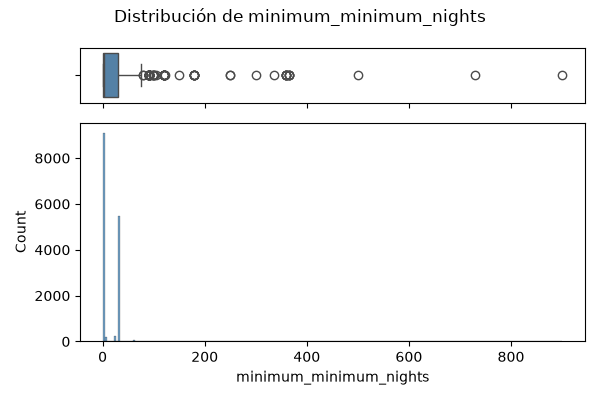

Q1=1.0  mediana=2.0  Q3=31.0  max=900.0
nulos=1
filas distintas de minimum_nights: 1


In [125]:
ruta = graficar_numerica(listings["minimum_minimum_nights"], "minimum_minimum_nights", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["minimum_minimum_nights"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")
dif = (listings["minimum_minimum_nights"] != listings["minimum_nights"]).sum()
print(f"filas distintas de minimum_nights: {dif}")

Percentiles: 25% = 1, mediana = 2, 75% = 31. Máximo 900. 1 nulo. Coincide con `minimum_nights` en todas las filas menos 1 (prácticamente idéntica).

### Cruce: variación estacional real de `minimum_nights`, según `room_type`

Igual que se hizo para `maximum_nights` (comparando `minimum_maximum_nights` vs. `maximum_maximum_nights`), aquí se compara `minimum_minimum_nights` vs. `maximum_minimum_nights` para ver qué anuncios suben su estancia mínima en algún momento del año.

Anuncios con variacion estacional en minimum_nights: 6524 de 15293



,pct,count
room_type,,
Hotel room,79.4,68
Entire home/apt,50.7,10844
Private room,22.3,4262
Shared room,21.0,119


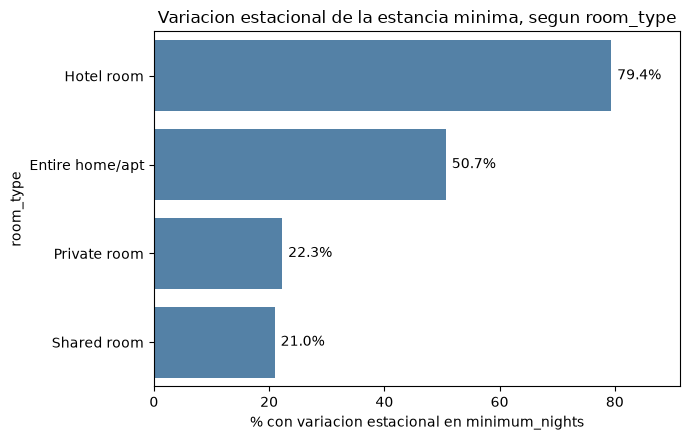

In [126]:
listings["con_variacion_min_nights"] = (listings["maximum_minimum_nights"] - listings["minimum_minimum_nights"]) > 0
print(f"Anuncios con variación estacional en minimum_nights: {listings['con_variacion_min_nights'].sum()} de {len(listings)}")
print()

tabla = listings.groupby("room_type")["con_variacion_min_nights"].agg(["mean", "count"])
tabla["pct"] = (tabla["mean"] * 100).round(1)
tabla = tabla.sort_values("pct", ascending=False)
display(tabla[["pct", "count"]])

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=tabla["pct"], y=tabla.index, color="steelblue", ax=ax)
for i, v in enumerate(tabla["pct"]):
    ax.text(v + 1, i, f"{v}%", va="center")
ax.set_xlim(0, tabla["pct"].max() * 1.15)
ax.set_xlabel("% con variación estacional en minimum_nights")
ax.set_ylabel("room_type")
ax.set_title("Variación estacional de la estancia mínima, según room_type")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/variacion_estacional_minimum_room_type.png", dpi=100)
plt.show()

Patrón opuesto al visto con `maximum_nights`: aquí la variación estacional es mucho más común en general (42,7% de todos los anuncios, frente al 10,0% de `maximum_nights`), y por `room_type` se invierte — "Hotel room" (79,4%) y "Entire home/apt" (50,7%) varían bastante más que "Private room" (22,3%) y "Shared room" (21,0%).

Tiene sentido de negocio: es mucho más común subir la estancia mínima en temporada alta (para asegurar reservas más largas y rentables cuando hay demanda) que cambiar el tope máximo de noches, que suele ser una política más fija. Los pisos enteros, al competir más directamente por temporada turística, son los que más ajustan esta condición.

### `minimum_nights_avg_ntm`

El promedio del mínimo de noches exigido, calculado sobre los próximos 365 días ("ntm" = *next twelve months*).

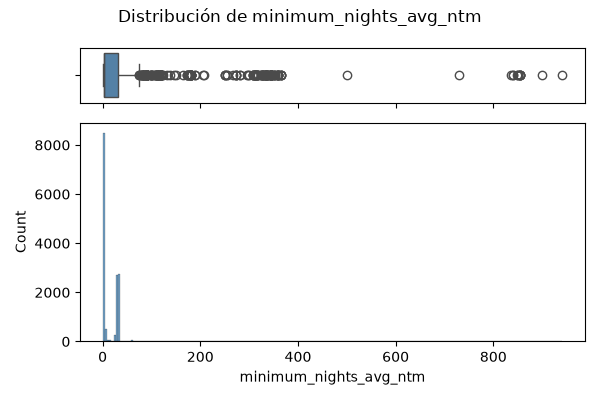

Q1=2.0  mediana=3.8  Q3=31.0  max=940.7
nulos=0


In [127]:
ruta = graficar_numerica(listings["minimum_nights_avg_ntm"], "minimum_nights_avg_ntm", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["minimum_nights_avg_ntm"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")

Percentiles: 25% = 2, mediana = 3,8, 75% = 31. Máximo 940,7. 0 nulos. Con esta se completan las 8 columnas del grupo `*_nights`.

### Chequeo de consistencia: `minimum_nights_avg_ntm` entre `minimum_minimum_nights` y `maximum_minimum_nights`

Mismo tipo de verificación que con `maximum_nights_avg_ntm`: al ser un promedio, debería estar siempre entre el mínimo y el máximo del año.

In [128]:
dentro_rango = (listings["minimum_nights_avg_ntm"] >= listings["minimum_minimum_nights"]) & (listings["minimum_nights_avg_ntm"] <= listings["maximum_minimum_nights"])
print(f"Dentro del rango esperado: {dentro_rango.sum()} de {len(listings)}")

fuera = listings[~dentro_rango]
display(fuera[["minimum_minimum_nights", "maximum_minimum_nights", "minimum_nights_avg_ntm"]])

Dentro del rango esperado: 15292 de 15293


,minimum_minimum_nights,maximum_minimum_nights,minimum_nights_avg_ntm
3520,NaN,NaN,2.9


Mismo resultado que con `maximum_nights_avg_ntm`: se cumple en el 99,99% de los casos (15.292 de 15.293), con la única excepción la fila ya documentada (id 29047395, "Habitat Apartments" — ver nota de gobernanza en el notebook 05). Confirma otra vez la consistencia interna del grupo `*_nights`, salvo ese único hueco puntual de carga.

### Cruce: `minimum_nights_avg_ntm` según ingresos y ocupación

¿Exigir una estancia mínima más larga perjudica siempre el rendimiento, o hay un punto intermedio óptimo? Se agrupa en 4 rangos y se compara con `estimated_revenue_l365d` y `estimated_occupancy_l365d`.

estimated_revenue_l365d
                 median      mean  count
bucket_min_ntm                          
1-2 noches       7548.0  23179.58   3457
3-7 noches      37350.0  41230.40   4373
8-27 noches         0.0   7898.16    402
28+ noches          0.0   5579.93   5123

estimated_occupancy_l365d
                median    mean  count
bucket_min_ntm                       
1-2 noches        18.0   75.33   4273
3-7 noches       132.0  129.85   4726
8-27 noches        0.0   33.97    434
28+ noches         0.0   63.70   5860



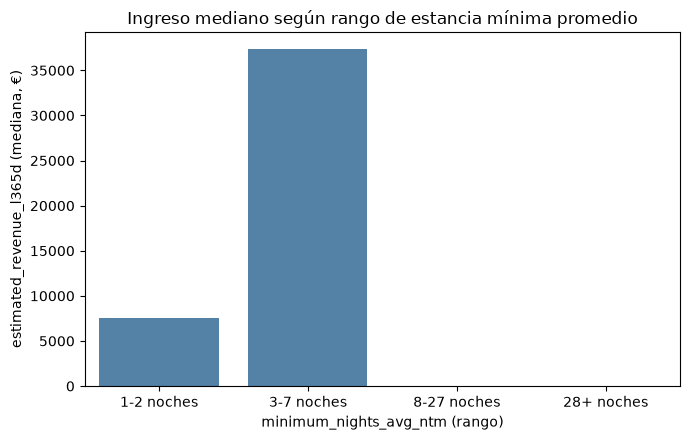

In [129]:
bins = [0, 2, 7, 28, 1000]
labels = ["1-2 noches", "3-7 noches", "8-27 noches", "28+ noches"]
listings["bucket_min_ntm"] = pd.cut(listings["minimum_nights_avg_ntm"], bins=bins, labels=labels)

for col in ["estimated_revenue_l365d", "estimated_occupancy_l365d"]:
    print(col)
    print(listings.groupby("bucket_min_ntm", observed=True)[col].agg(["median", "mean", "count"]).round(2))
    print()

fig, ax = plt.subplots(figsize=(7, 4.5))
tabla_rev = listings.groupby("bucket_min_ntm", observed=True)["estimated_revenue_l365d"].median().reindex(labels)
sns.barplot(x=tabla_rev.index, y=tabla_rev.values, color="steelblue", ax=ax)
ax.set_xlabel("minimum_nights_avg_ntm (rango)")
ax.set_ylabel("estimated_revenue_l365d (mediana, €)")
ax.set_title("Ingreso mediano según rango de estancia mínima promedio")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/minimum_nights_ntm_revenue.png", dpi=100)
plt.show()

No es una relación lineal — hay un punto óptimo claro en "3-7 noches" (mediana 37.350€, 132 días de ocupación), bastante por encima incluso de "1-2 noches" (7.548€, 18 días). A partir de "8-27 noches" el ingreso se desploma a mediana 0€, igual que en "28+ noches".

Tiene sentido de negocio: exigir solo 1-2 noches puede filtrar poco (reservas sueltas, más rotación y costes de limpieza sin necesariamente más ingreso), mientras que pedir una semana (3-7 noches) parece capturar bien la demanda turística típica de estancias vacacionales. A partir de 8 noches ya empieza a filtrar fuera a la mayoría de turistas (viajes cortos), aunque el corte duro de `revenue_no_estimable` esté definido en 28 — el deterioro real ya empieza bastante antes, desde las 8 noches.

### `minimum_nights`

Número mínimo de noches que exige el anfitrión para reservar, valor actual del anuncio. Es la variable central del hallazgo principal del proyecto.

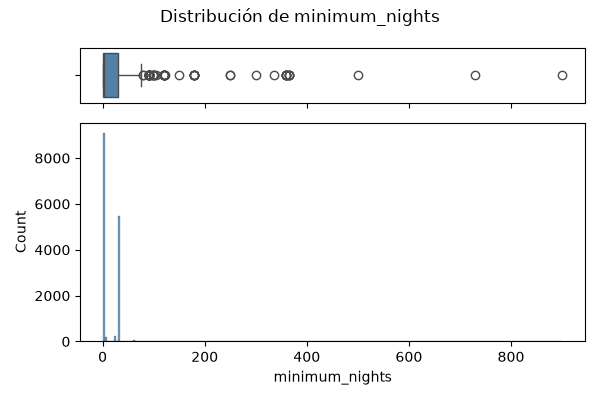

Q1=1.0  mediana=2.0  Q3=31.0  max=900.0
nulos=1
con >= 28: 5702 (37.3%)


In [130]:
ruta = graficar_numerica(listings["minimum_nights"], "minimum_nights", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["minimum_nights"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")
print(f"con >= 28: {(s>=28).sum()} ({(s>=28).mean()*100:.1f}%)")

Percentiles: 25% = 1, mediana = 2, 75% = 31. Máximo 900. 1 nulo.

5.702 anuncios (37,3%) tienen `minimum_nights >= 28` — uno de los dos requisitos de la condición de doble evidencia que define `revenue_no_estimable`: exigir estancias largas reduce la rotación de huéspedes nuevos, lo que produce pocas reseñas y, por la fórmula de Inside Airbnb, un ingreso estimado artificialmente bajo o en 0€.

### `name`

Título corto del anuncio, el que aparece como encabezado en la búsqueda de Airbnb.

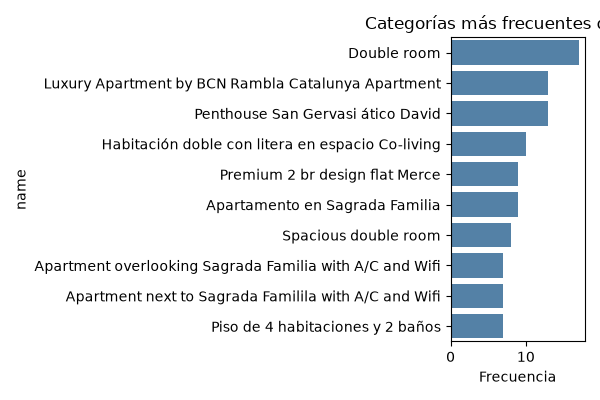

nulos=0  valores unicos=14694 de 15293


In [131]:
ruta = graficar_categorica(listings["name"], "name", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["name"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()} de {len(s)}")

0 nulos. 14.694 valores únicos de 15.293 — algunos títulos se repiten de verdad entre anuncios distintos (ej. "Double room", 17 veces).

### Extra: palabras más frecuentes en `name`

Antes de esto se probó la correlación entre longitud del título o si menciona el barrio y el rendimiento del anuncio (`estimated_revenue_l365d`, `number_of_reviews`) — en ambos casos la correlación fue casi nula (menor a 0,06), así que no se reporta como hallazgo. El análisis de palabras sí da algo genuino.

name
apartment     3021
room          2372
barcelona     1748
bedroom       1153
sagrada       1144
terrace       1129
familia       1016
habitación    1000
eixample       892
flat           858
private        783
balcony        770
double         715
gracia         713
bedrooms       709
Name: count, dtype: int64

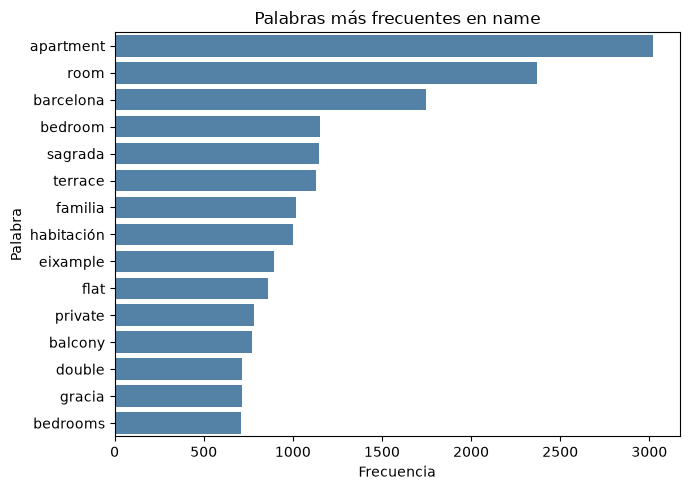

In [132]:
texto = listings["name"].dropna().str.lower()
palabras_nombre = texto.str.findall(r"[a-z\u00e1\u00e9\u00ed\u00f3\u00fa\u00f1]{3,}").explode()
stopwords_name = {"the", "and", "with", "for", "you", "this", "from", "has", "are", "one", "very", "your",
                   "not", "but", "all", "can", "will", "that", "our", "its", "out", "use", "per", "non",
                   "have", "love", "like", "also", "que", "para", "con", "una", "los", "nos", "las", "del",
                   "por", "más", "como", "esta", "son", "soy", "near"}
pf_nombre = palabras_nombre[~palabras_nombre.isin(stopwords_name)]
top_palabras = pf_nombre.value_counts().head(15)
display(top_palabras)

fig, ax = plt.subplots(figsize=(7, 5))
sns.barplot(x=top_palabras.values, y=top_palabras.index, color="steelblue", ax=ax)
ax.set_xlabel("Frecuencia")
ax.set_ylabel("Palabra")
ax.set_title("Palabras más frecuentes en name")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/name_palabras_frecuentes.png", dpi=100)
plt.show()

"Apartment"/"room" dominan (son casi palabras estructurales del título, no marketing). Lo más interesante: **"sagrada"** (1.144) y **"familia"** (1.016) — en referencia a la Sagrada Família, un punto de referencia turístico muy usado para anunciar la ubicación, incluso cuando el anuncio no está en el distrito que lleva ese nombre administrativo. También aparecen nombres de distrito/barrio reales como "eixample" (892) y "gracia" (713), y palabras de marketing típico ("cozy", "central", "terrace", "balcony", "beach") que destacan comodidades o cercanía a puntos de interés, más que datos objetivos del alojamiento.

### Extra: nube de palabras de `name`

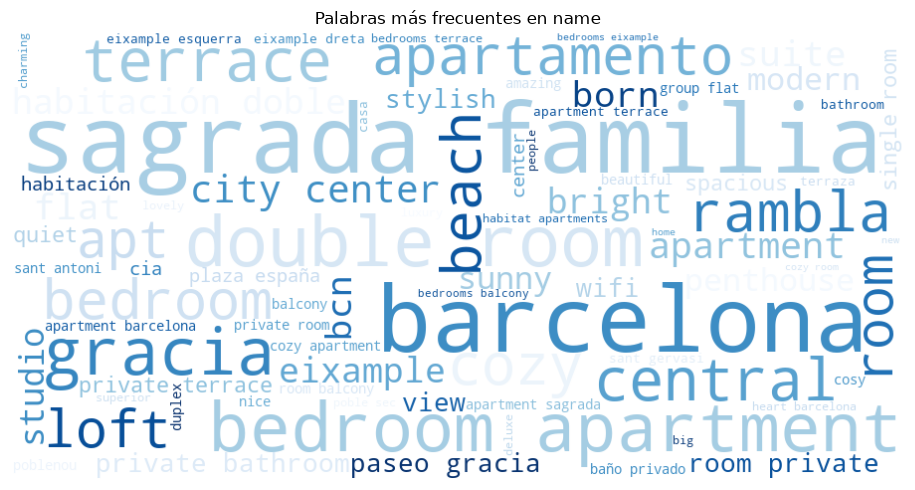

In [133]:
from wordcloud import WordCloud

texto_nube_nombre = " ".join(pf_nombre.dropna())
nube_nombre = WordCloud(width=900, height=450, background_color="white", colormap="Blues", max_words=80).generate(texto_nube_nombre)

fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(nube_nombre, interpolation="bilinear")
ax.axis("off")
ax.set_title("Palabras más frecuentes en name")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/name_wordcloud.png", dpi=100)
plt.show()

### `neighborhood_overview`

Texto donde el anfitrión describiría el barrio del alojamiento.

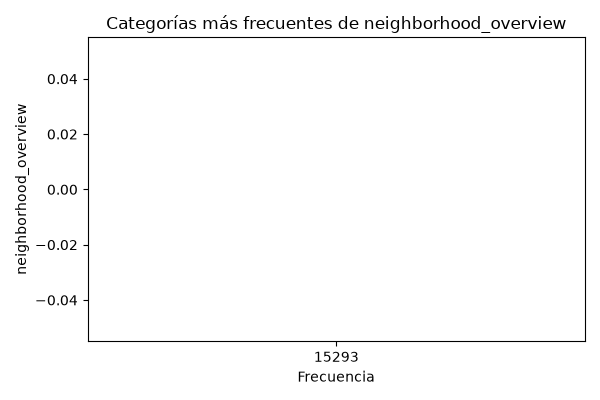

nulos=15293 de 15293


In [134]:
ruta = graficar_categorica(listings["neighborhood_overview"], "neighborhood_overview", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['neighborhood_overview'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05.

### `neighbourhood`

Nombre del barrio en formato libre (texto sin estandarizar).

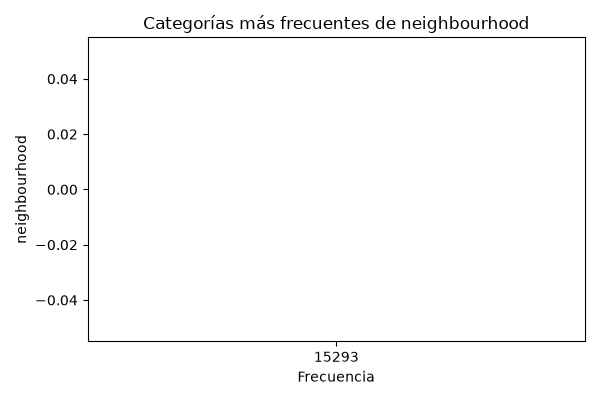

nulos=15293 de 15293


In [135]:
ruta = graficar_categorica(listings["neighbourhood"], "neighbourhood", CARPETA_LISTINGS)
display(Image(ruta))

print(f"nulos={listings['neighbourhood'].isna().sum()} de {len(listings)}")

100% nulos (15.293 de 15.293) — una de las 12 columnas vacías eliminadas en notebook 05. Sustituida por `neighbourhood_cleansed`, que sí tiene datos y es la que usa el proyecto.

### `neighbourhood_cleansed`

Barrio del alojamiento, ya estandarizado contra la lista oficial de barrios de Barcelona (no es texto libre escrito por el anfitrión).

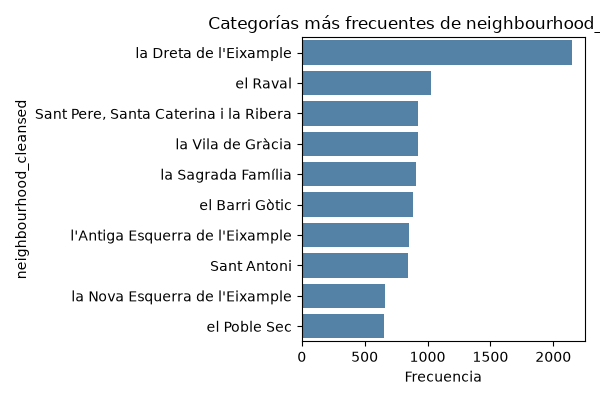

nulos=0  valores unicos=69


In [136]:
ruta = graficar_categorica(listings["neighbourhood_cleansed"], "neighbourhood_cleansed", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["neighbourhood_cleansed"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()}")

0 nulos. 69 barrios distintos. El más frecuente es "la Dreta de l'Eixample" (2.145, 14,0%), seguido de "el Raval" (1.031).

### Cruce: `estimated_revenue_l365d` según barrio (nivel más fino que distrito)

Los cruces anteriores de ingresos fueron por distrito (10 categorías). Aquí se baja al nivel de barrio (69 posibles) para ver si hay variación relevante que el distrito esconde. Se limita a barrios con al menos 30 anuncios, para no comparar con muestras minúsculas.

Barrios con al menos 30 anuncios: 45 de 69


,median,mean,count
neighbourhood_cleansed,,,
Diagonal Mar i el Front Marítim del Poblenou,32009.5,40926.58,104
la Sagrada Família,21364.0,32207.12,805
el Fort Pienc,18893.0,31335.80,373
la Dreta de l'Eixample,13095.0,31172.77,1943
el Parc i la Llacuna del Poblenou,26000.0,28635.47,137
el Congrés i els Indians,2363.0,9395.09,34
Sarrià,3031.5,8218.54,54
Sant Andreu,0.0,6215.30,64
la Marina de Port,0.0,4021.02,53


C:\Users\Massiel\AppData\Local\Temp\ipykernel_18020\4144290478.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=combinado["mean"], y=combinado.index, palette=colores, ax=ax)


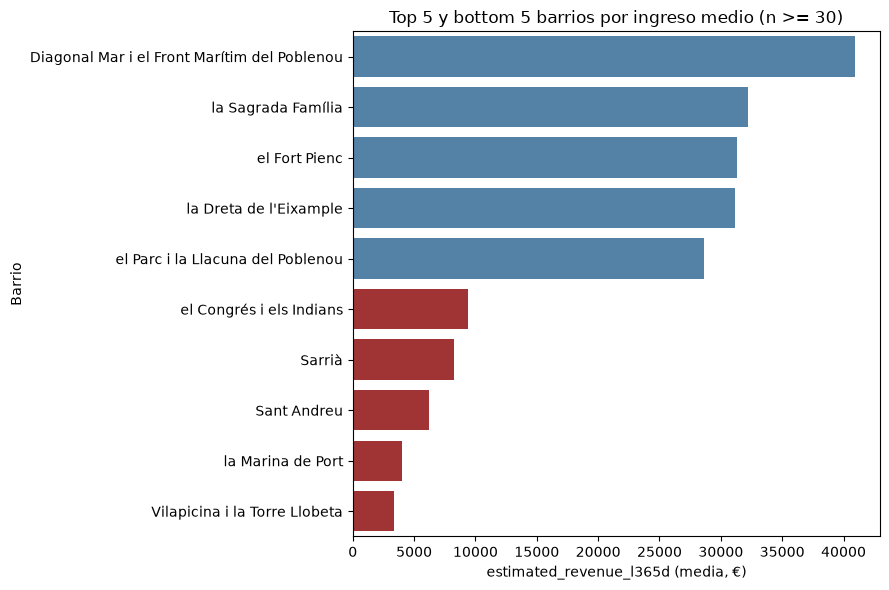

In [137]:
tabla = listings.groupby("neighbourhood_cleansed")["estimated_revenue_l365d"].agg(["median", "mean", "count"])
tabla = tabla[tabla["count"] >= 30].sort_values("mean", ascending=False)
print(f"Barrios con al menos 30 anuncios: {len(tabla)} de {listings['neighbourhood_cleansed'].nunique()}")

top5 = tabla.head(5)
bottom5 = tabla.tail(5)
combinado = pd.concat([top5, bottom5])
display(combinado.round(2))

fig, ax = plt.subplots(figsize=(9, 6))
colores = ["steelblue"] * 5 + ["firebrick"] * 5
sns.barplot(x=combinado["mean"], y=combinado.index, palette=colores, ax=ax)
ax.set_xlabel("estimated_revenue_l365d (media, €)")
ax.set_ylabel("Barrio")
ax.set_title("Top 5 y bottom 5 barrios por ingreso medio (n >= 30)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/revenue_barrio_top_bottom.png", dpi=100)
plt.show()

La diferencia dentro de un mismo distrito puede ser enorme. "Diagonal Mar i el Front Marítim del Poblenou" (en Sant Martí) tiene el ingreso medio más alto de todo Barcelona (40.927€, 104 anuncios), muy por encima de la media de su propio distrito. En el otro extremo, "Vilapicina i la Torre Llobeta" (en Nou Barris) tiene media de solo 3.350€ y **mediana de 0€** — más de la mitad de sus 74 anuncios no genera ingreso estimable.

Esto confirma que el distrito, aunque útil, esconde variación real a nivel de barrio — de los 69 barrios, solo 45 tienen una muestra de al menos 30 anuncios para comparar con algo de fiabilidad.

### `number_of_reviews_l30d`

Reseñas recibidas en el último mes.

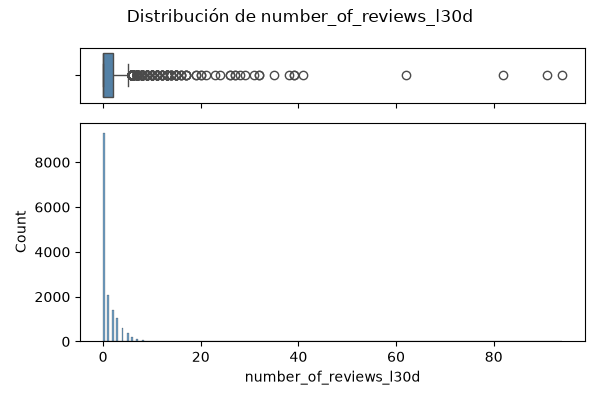

Q1=0.0  mediana=0.0  Q3=2.0  max=94
nulos=0
con 0: 9305 (60.8%)


In [138]:
ruta = graficar_numerica(listings["number_of_reviews_l30d"], "number_of_reviews_l30d", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["number_of_reviews_l30d"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")
print(f"con 0: {(s==0).sum()} ({(s==0).mean()*100:.1f}%)")

Percentiles: 25% = 0, mediana = 0, 75% = 2. Máximo 94. 0 nulos. 60,8% de los anuncios (9.305) no recibieron ninguna reseña en el último mes — ventana muy estrecha, mucha más concentración en 0 que `number_of_reviews_ltm` (que mide el último año).

### Cruce: `number_of_reviews_l30d` según `minimum_nights`

¿Una estancia mínima larga reduce la probabilidad de tener actividad reciente (reseña en el último mes)? Es una ventana muy corta, así que el efecto de `minimum_nights` debería notarse con fuerza.

% con al menos 1 resena en el ultimo mes, segun minimum_nights:
bucket_min_nights
1       57.6
2       65.9
3-7     53.9
8-27     4.5
28+      8.2
Name: number_of_reviews_l30d, dtype: float64


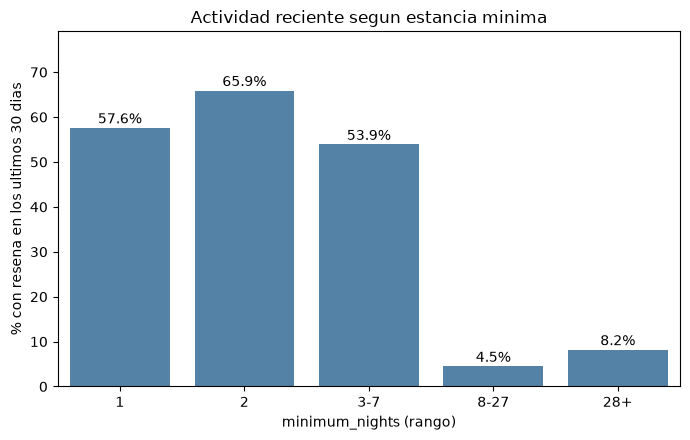

In [139]:
bins = [0, 1, 2, 7, 28, 10000]
labels = ["1", "2", "3-7", "8-27", "28+"]
listings["bucket_min_nights"] = pd.cut(listings["minimum_nights"], bins=bins, labels=labels, include_lowest=True)

pct_con_resena = listings.groupby("bucket_min_nights", observed=True)["number_of_reviews_l30d"].apply(lambda s: (s > 0).mean() * 100).round(1)
print("% con al menos 1 reseña en el último mes, según minimum_nights:")
print(pct_con_resena)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=pct_con_resena.index, y=pct_con_resena.values, color="steelblue", ax=ax)
for i, v in enumerate(pct_con_resena.values):
    ax.text(i, v + 1, f"{v}%", ha="center")
ax.set_ylim(0, pct_con_resena.max() * 1.2)
ax.set_xlabel("minimum_nights (rango)")
ax.set_ylabel("% con reseña en los ultimos 30 días")
ax.set_title("Actividad reciente según estancia mínima")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/l30d_minimum_nights.png", dpi=100)
plt.show()

Caída muy marcada: 53,9%-65,9% de los anuncios con estancia mínima de 1 a 7 noches recibieron al menos una reseña el último mes, frente a solo 4,5%-8,2% de los que exigen 8 o más noches.

Tiene sentido matemático directo: con una ventana de solo 30 días, un anuncio que exige 28+ noches mínimas prácticamente no puede generar una estancia *completa* (y por tanto una reseña) dentro de ese plazo tan corto. Esta columna visualiza de forma muy directa el mismo mecanismo que ya explica `revenue_no_estimable` y la baja ocupación de los anuncios con estancias mínimas largas, pero a una escala temporal mucho más fina (mes a mes en vez de año completo).

### `number_of_reviews_ltm`

Reseñas recibidas en el último año ("ltm" = *last twelve months*). Es la variable que origina el hallazgo central del proyecto.

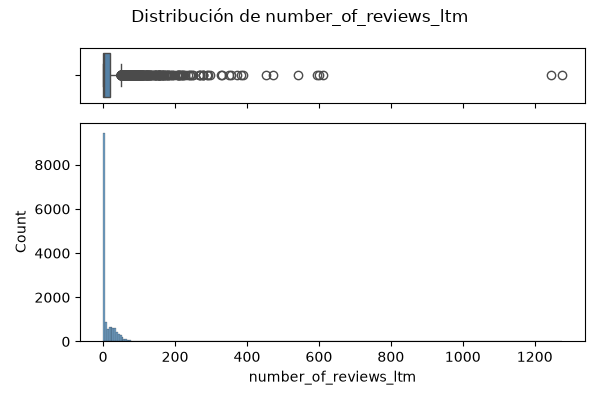

Q1=0.0  mediana=2.0  Q3=20.0  max=1276
nulos=0
con 0: 5627 (36.8%)


In [140]:
ruta = graficar_numerica(listings["number_of_reviews_ltm"], "number_of_reviews_ltm", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["number_of_reviews_ltm"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")
print(f"con 0: {(s==0).sum()} ({(s==0).mean()*100:.1f}%)")

Percentiles: 25% = 0, mediana = 2, 75% = 20. Máximo 1.276. 0 nulos.

5.627 anuncios (36,8%) tienen 0 reseñas en el último año — y son exactamente los mismos 5.627 que tienen `estimated_occupancy_l365d = 0`, por la fórmula de Inside Airbnb (ocupación = reseñas ÷ tasa de conversión del 50% × duración media de estancia). Esta columna, junto con `minimum_nights`, define la condición de `revenue_no_estimable`.

Por qué importa: esta columna es la causa raíz del hallazgo central del proyecto. Si se calcula un ingreso promedio por alojamiento sin tener en cuenta que miles de anuncios tienen `number_of_reviews_ltm = 0` (y por tanto `estimated_revenue_l365d = 0` artificial, no real), la conclusión de negocio sale mal: anuncios que en realidad están ocupados con estancias largas se cuentan como si no generaran ningún ingreso, lo que infla artificialmente la diferencia entre anfitriones particulares y profesionales. Lo mismo pasa si se entrena un modelo predictivo sin corregir esto: el modelo aprende de miles de ejemplos "0 euros" que son errores de cálculo, no ingresos reales, y sus métricas (MAE, R²) quedan distorsionadas. Cualquier análisis de ingresos en este dataset que no considere esta columna junto con `minimum_nights` corre el riesgo real de concluir algo incorrecto.

### Cruce: `number_of_reviews_ltm` según tamaño de cartera (no solo particular/profesional)

Hasta ahora el tamaño de cartera se miró como binario (`host_profesional`, umbral en 51). Aquí se usan 5 tramos continuos de `calculated_host_listings_count`, para ver si el patrón es realmente un "acantilado" único en 51 o algo más gradual.

,median,mean,count
tamano_cartera_5,,,
1,1.0,11.69,2988
2-5,3.0,16.22,3162
6-20,4.0,15.88,3695
21-50,6.0,15.25,1883
51+,0.0,7.96,3565


% con 0 resenas en el ultimo anio:
tamano_cartera_5
1        48.4
2-5      28.7
6-20     24.8
21-50    20.7
51+      55.2
Name: number_of_reviews_ltm, dtype: float64


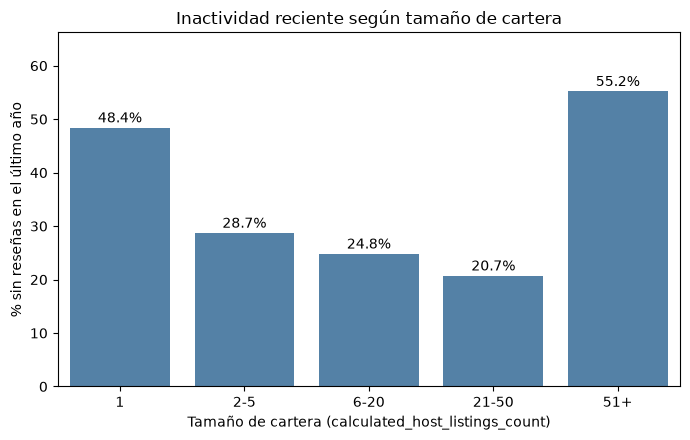

In [141]:
bins = [0, 1, 5, 20, 50, 1000]
labels = ["1", "2-5", "6-20", "21-50", "51+"]
listings["tamano_cartera_5"] = pd.cut(listings["calculated_host_listings_count"], bins=bins, labels=labels)

tabla = listings.groupby("tamano_cartera_5", observed=True)["number_of_reviews_ltm"].agg(["median", "mean", "count"])
display(tabla.round(2))

pct_cero = listings.groupby("tamano_cartera_5", observed=True)["number_of_reviews_ltm"].apply(lambda s: (s == 0).mean() * 100).round(1)
print("% con 0 reseñas en el último año:")
print(pct_cero)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=pct_cero.index, y=pct_cero.values, color="steelblue", ax=ax)
for i, v in enumerate(pct_cero.values):
    ax.text(i, v + 1, f"{v}%", ha="center")
ax.set_ylim(0, pct_cero.max() * 1.2)
ax.set_xlabel("Tamaño de cartera (calculated_host_listings_count)")
ax.set_ylabel("% sin reseñas en el último año")
ax.set_title("Inactividad reciente según tamaño de cartera")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/ltm_tamano_cartera.png", dpi=100)
plt.show()

No es un simple acantilado en 51 — es una forma de **U**. El % de anuncios sin ninguna reseña reciente baja de 48,4% (anfitriones con 1 solo anuncio) a 20,7% (carteras de 21-50, el punto más bajo), y luego se dispara a 55,2% en carteras de 51+ — el peor resultado de los cinco tramos.

Interpretación: tanto los anfitriones muy pequeños (1 anuncio, posiblemente menos dedicación o anuncios abandonados) como las operaciones muy grandes (51+, el umbral "profesional") tienen más anuncios inactivos recientemente. El punto óptimo está en el medio — carteras de tamaño moderado (6-50 anuncios), que combinan dedicación con cierta escala. Esto matiza el hallazgo de `host_profesional`: el problema no es "tener más anuncios" en sí, es específicamente cruzar el umbral de operación a gran escala.

### `number_of_reviews_ly`

Reseñas del año natural anterior completo ("ly" = *last year*) — a diferencia de `number_of_reviews_ltm`, que es una ventana móvil de 365 días desde hoy, no un año de calendario fijo.

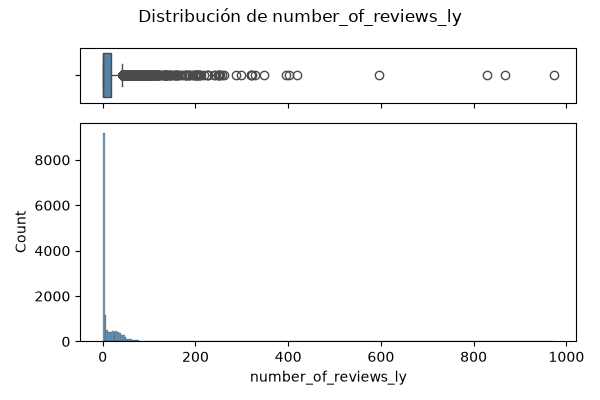

Q1=0.0  mediana=1.0  Q3=17.0  max=973
nulos=0
con 0: 6699 (43.8%)


In [142]:
ruta = graficar_numerica(listings["number_of_reviews_ly"], "number_of_reviews_ly", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["number_of_reviews_ly"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")
print(f"con 0: {(s==0).sum()} ({(s==0).mean()*100:.1f}%)")

Percentiles: 25% = 0, mediana = 1, 75% = 17. Máximo 973. 0 nulos. 43,8% con 0 reseñas (6.699) — más que el 36,8% de `number_of_reviews_ltm`, porque esta columna (`number_of_reviews_ly`) mide un año natural fijo, mientras que `number_of_reviews_ltm` es una ventana móvil de 365 días desde hoy. No se usa en el proyecto; la variable elegida es `number_of_reviews_ltm`, alineada con la ventana de 365 días del propio target.

### Cruce: tendencia `number_of_reviews_ltm` vs. `number_of_reviews_ly` según ingresos

Comparando las dos ventanas de tiempo se puede ver si un anuncio está recibiendo más o menos reseñas que el año anterior — una señal de tendencia, no solo una foto fija.

Correlacion ltm vs ly: 0.948
tendencia_resenas
Igual         6487
Acelerando    5028
Frenando      3778
Name: count, dtype: int64



,estimated_revenue_l365d,review_scores_rating
tendencia_resenas,,
Frenando,28080.0,4.72
Igual,0.0,4.76
Acelerando,20581.5,4.72


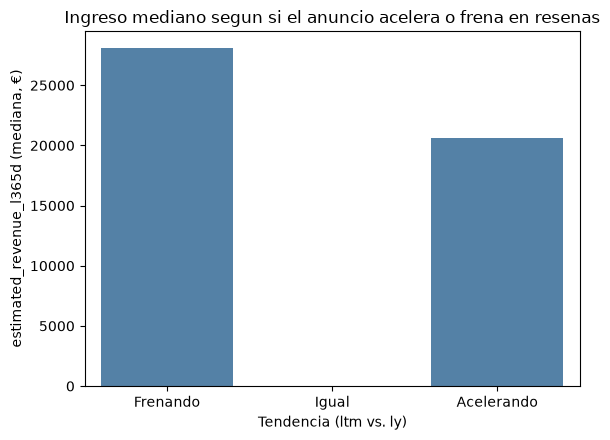

In [143]:
print("Correlación ltm vs ly:", round(listings["number_of_reviews_ltm"].corr(listings["number_of_reviews_ly"]), 3))

diferencia = listings["number_of_reviews_ltm"] - listings["number_of_reviews_ly"]
listings["tendencia_resenas"] = pd.cut(diferencia, bins=[-10000, -1, 0, 10000], labels=["Frenando", "Igual", "Acelerando"])
print(listings["tendencia_resenas"].value_counts())
print()

tabla = listings.groupby("tendencia_resenas", observed=True)[["estimated_revenue_l365d", "review_scores_rating"]].median()
display(tabla)

fig, ax = plt.subplots(figsize=(6, 4.5))
orden = ["Frenando", "Igual", "Acelerando"]
sns.barplot(x=orden, y=listings.groupby("tendencia_resenas", observed=True)["estimated_revenue_l365d"].median().reindex(orden), color="steelblue", ax=ax)
ax.set_xlabel("Tendencia (ltm vs. ly)")
ax.set_ylabel("estimated_revenue_l365d (mediana, €)")
ax.set_title("Ingreso mediano según si el anuncio acelera o frena en reseñas")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/tendencia_resenas_revenue.png", dpi=100)
plt.show()

Correlación muy alta entre `ltm` y `ly` (0,95), como se espera de dos ventanas de tiempo parecidas. Pero hay un matiz contraintuitivo: los anuncios que están "frenando" (menos reseñas este año que el pasado) tienen un ingreso mediano **más alto** (28.080€) que los que están "acelerando" (20.581,50€). El grupo "Igual" tiene mediana 0€, dominado por los anuncios con 0 reseñas en ambas ventanas (los ya conocidos como inactivos).

No hay forma de confirmar la causa con los datos disponibles — una hipótesis razonable es que los anuncios "frenando" incluyen muchos ya establecidos con un año anterior muy fuerte, y aunque bajen algo siguen por encima de los que recién están creciendo desde una base más baja. Se queda como hallazgo descriptivo, no como explicación causal confirmada.

### `number_of_reviews`

Total histórico de reseñas del alojamiento, desde que existe el anuncio (no una ventana de tiempo concreta).

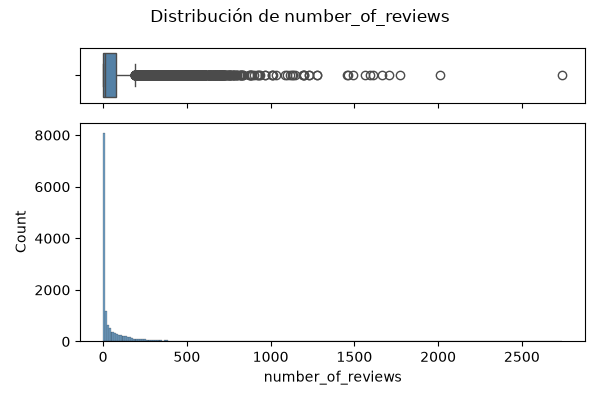

Q1=1.0  mediana=9.0  Q3=77.0  max=2740
nulos=0
con 0: 3548 (23.2%)


In [144]:
ruta = graficar_numerica(listings["number_of_reviews"], "number_of_reviews", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["number_of_reviews"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")
print(f"con 0: {(s==0).sum()} ({(s==0).mean()*100:.1f}%)")

Percentiles: 25% = 1, mediana = 9, 75% = 77. Máximo 2.740. 0 nulos. 23,2% de los anuncios (3.548) no tienen ninguna reseña en toda su historia — un subconjunto de los 5.627 sin reseñas en el último año (`number_of_reviews_ltm = 0`): todo anuncio sin ninguna reseña histórica tiene, por fuerza, 0 reseñas también en el último año, pero el grupo del último año es más amplio porque incluye además anuncios que sí tuvieron reseñas antes, pero no recientemente.

### Cruce: `number_of_reviews` según `price`

¿Un anuncio con más reseñas acumuladas (más "reputación") cobra más? Correlación directa muy débil (0,05), pero vale la pena ver si hay un patrón no lineal agrupando por rango de reseñas.

,median,mean,count
bucket_reviews,,,
0,113.16,253.56,4015
1-10,109.00,161.96,2588
11-50,193.00,216.41,2344
51-200,266.00,292.36,2853
200+,253.50,279.66,1555


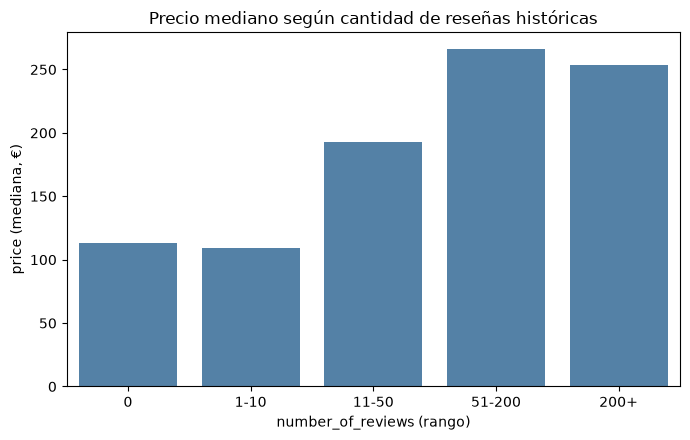

In [145]:
listings["precio_num"] = listings["price"].replace(r"[\$,]", "", regex=True).astype(float)

bins = [0, 1, 10, 50, 200, 10000]
labels = ["0", "1-10", "11-50", "51-200", "200+"]
listings["bucket_reviews"] = pd.cut(listings["number_of_reviews"], bins=bins, labels=labels, include_lowest=True)

tabla = listings.groupby("bucket_reviews", observed=True)["precio_num"].agg(["median", "mean", "count"])
display(tabla.round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=tabla.index, y=tabla["median"], color="steelblue", ax=ax)
ax.set_xlabel("number_of_reviews (rango)")
ax.set_ylabel("price (mediana, €)")
ax.set_title("Precio mediano según cantidad de reseñas históricas")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/numreviews_precio.png", dpi=100)
plt.show()

No es una relación lineal limpia, pero sí hay una tendencia real en la mayor parte del rango: el precio mediano sube de 109€ (1-10 reseñas) a 193€ (11-50) y 266€ (51-200), bajando levemente en 200+ (253,50€). El grupo de 0 reseñas rompe el patrón (113,16€, parecido al de 1-10, no el más bajo de todos).

Interpretación con cautela: podría reflejar que los anuncios con historial acumulan cierta "prima de reputación" (más reseñas, más confianza, precio algo más alto), con un techo a partir de cierto volumen — pero la correlación directa es débil (0,05), así que esto es más una tendencia visible al agrupar que una relación fuerte y consistente.

### `picture_url`

Enlace a la foto principal del alojamiento (no del anfitrión).

C:\Users\Massiel\Desktop\Analisis de Datos - Barcelona Activa -Cibernarium\Especializacion-Data\Proyecto_Final\notebooks\graficos_utils.py:80: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


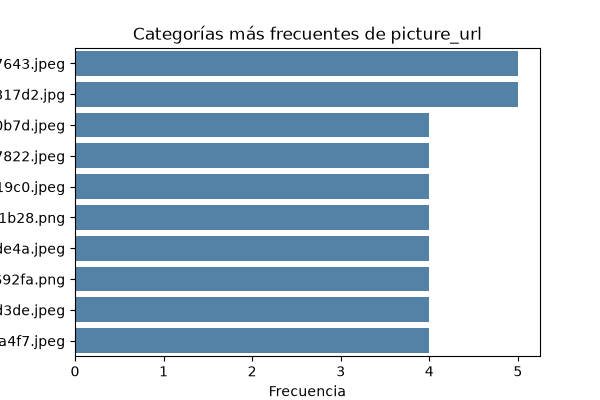

nulos=0  valores unicos=15145 de 15293


In [146]:
ruta = graficar_categorica(listings["picture_url"], "picture_url", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["picture_url"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()} de {len(s)}")

0 nulos. 15.145 valores únicos de 15.293 — casi todos distintos, no hay un anuncio mega grande como con las fotos del anfitrión, porque cada alojamiento tiene su propia foto principal, no se repite entre varios anuncios del mismo dueño.

### `price`

Precio por noche del alojamiento, tal como lo pone el anfitrión en el anuncio.

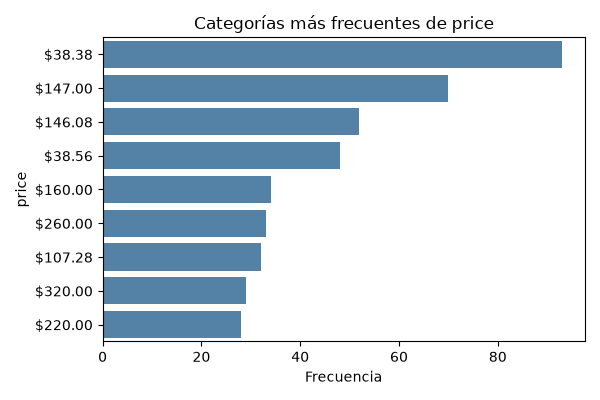

nulos=1938 (12.7%)  valores unicos=6365


In [147]:
ruta = graficar_categorica(listings["price"], "price", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["price"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)  valores únicos={s.nunique()}")

No es útil tal cual: pandas lee `price` como texto (por el símbolo "$"), así que el gráfico muestra precios exactos repetidos, no una distribución real. 12,7% nulos (1.938) — anuncios sin precio, que por eso tampoco tienen `estimated_revenue_l365d` calculable.

### Extra: `price` convertido a número

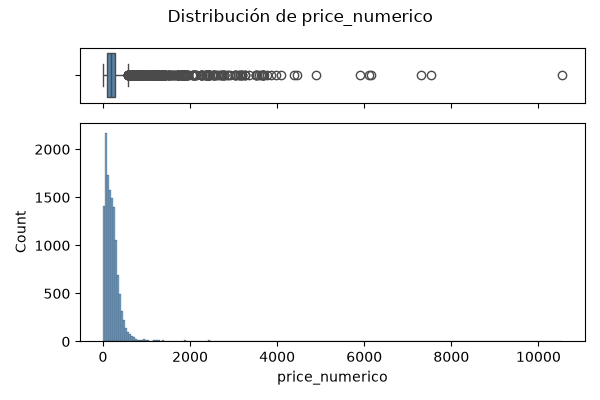

Q1=89.28999999999999  mediana=177.67  Q3=285.5  max=10542.22


In [148]:
precio_num = listings["price"].replace(r"[\$,]", "", regex=True).astype(float)
ruta = graficar_numerica(precio_num, "price_numerico", "../graficos_exploracion/cruces")
display(Image(ruta))

q1, mediana, q3 = precio_num.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={precio_num.max()}")

Percentiles: 25% = 89,29€, mediana = 177,67€, 75% = 285,50€. Máximo 10.542,22€ — un precio por noche muy alto, probablemente un alojamiento de lujo o un valor atípico real, no revisado a fondo aquí.

### Cruce: `price` según tipo de anfitrión

`price` es la tarifa por noche publicada, no es lo mismo que rentabilidad real (eso lo mide `estimated_revenue_l365d`, ya usado en el caso de negocio del proyecto). Este cruce solo mira el precio por noche.

,Mediana,Media,n
tipo_anfitrion,,,
Particular,180.0,213.20,9956
Profesional,173.0,320.92,3399


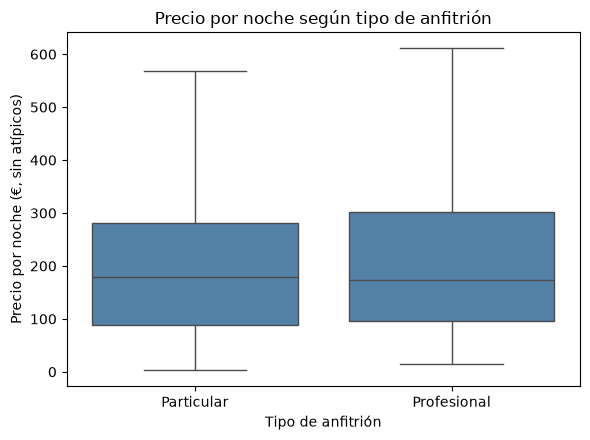

In [149]:
listings["precio_num"] = listings["price"].replace(r"[\$,]", "", regex=True).astype(float)

tabla_cruce = listings.groupby("tipo_anfitrion")["precio_num"].agg(
    Mediana="median", Media="mean", n="count"
)
display(tabla_cruce.round(2))

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=listings, x="tipo_anfitrion", y="precio_num", order=["Particular", "Profesional"], color="steelblue", ax=ax, showfliers=False)
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("Precio por noche (€, sin atípicos)")
ax.set_title("Precio por noche según tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/price_tipo_anfitrion.png", dpi=100)
plt.show()

La mediana es parecida entre grupos (180€ particular vs. 173€ profesional, incluso algo más baja en profesionales), pero la media es muy distinta (213,20€ vs. 320,92€): los profesionales tienen más anuncios de precio muy alto que estiran la media hacia arriba, sin que eso cambie el precio "típico".

Esto significa que `price` por sí solo **no responde** la pregunta de qué modelo es más rentable — ese precio es por noche, no mide ocupación ni ingresos reales. La pregunta de rentabilidad ya está respondida en el proyecto con `estimated_revenue_l365d`: los profesionales rinden un 39,7% peor por anuncio que los particulares en crudo (24.338€ vs. 14.678€/año), gap que baja a 23,1% al excluir los anuncios con `revenue_no_estimable = True`. `price` más alto en promedio para profesionales no se traduce en más ingresos — es justo lo contrario de lo que uno esperaría a primera vista.

### `price_quote_checkin_date`

Fecha de entrada usada en una cotización de reserva de prueba que Inside Airbnb solicitó, para obtener el precio real de una estancia simulada. No indica antigüedad del anuncio, siempre es una fecha cercana al scraping.

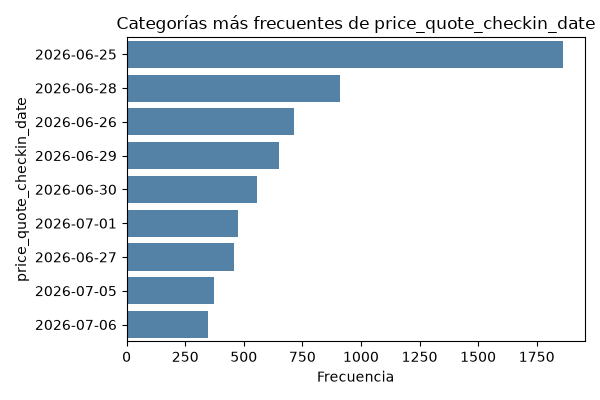

nulos=1631  valores unicos=293


In [150]:
ruta = graficar_categorica(listings["price_quote_checkin_date"], "price_quote_checkin_date", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["price_quote_checkin_date"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()}")

1.631 nulos, 293 fechas distintas, todas cercanas al scraping (24 junio - 3 julio de 2026).

### `price_quote_checkout_date`

Fecha de salida de esa misma cotización de reserva de prueba. Junto con `price_quote_checkin_date` define el rango de noches que se simuló.

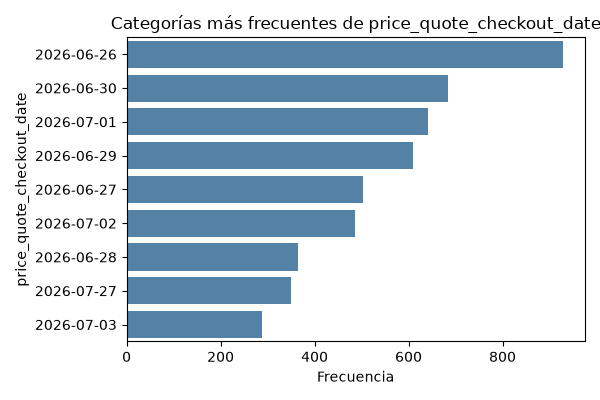

nulos=1631  valores unicos=332


In [151]:
ruta = graficar_categorica(listings["price_quote_checkout_date"], "price_quote_checkout_date", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["price_quote_checkout_date"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()}")

1.631 nulos (mismas filas que `price_quote_checkin_date`), 332 fechas distintas.

### `price_quote_price_per_night`

Precio por noche que salió de la cotización de reserva de prueba (ver `price_quote_*`).

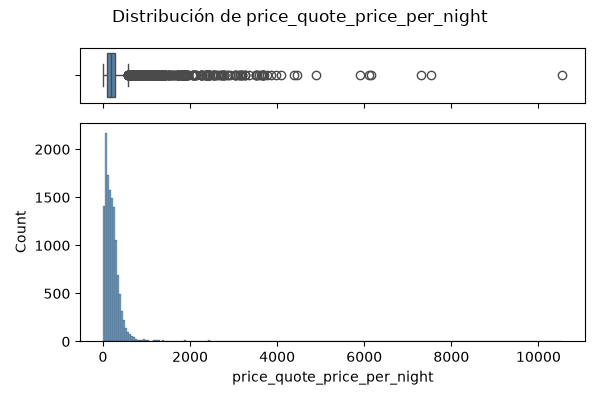

Q1=89.28999999999999  mediana=177.67  Q3=285.5  max=10542.22
nulos=1938
coinciden con price (numerico): 13355 de 15293


In [152]:
ruta = graficar_numerica(listings["price_quote_price_per_night"], "price_quote_price_per_night", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["price_quote_price_per_night"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")

precio_num = listings["price"].replace(r"[\$,]", "", regex=True).astype(float)
coinciden = (precio_num == s).sum()
print(f"coinciden con price (numerico): {coinciden} de {len(listings)}")

Percentiles: 25% = 89,29, mediana = 177,67, 75% = 285,50. Máximo 10.542,22. 1.938 nulos (mismas filas que `price`).

Coincide exactamente con `price` convertida a número en las 13.355 filas donde ambas tienen dato — es decir, la totalidad de los no nulos. No se puede confirmar con los datos disponibles cuál de las dos columnas es el dato original y cuál se deriva de la otra.

### `price_quote_raw`

Respuesta completa en formato JSON de la cotización de reserva de prueba. De aquí salen las demás columnas `price_quote_*` (fechas y precio por noche).

C:\Users\Massiel\Desktop\Analisis de Datos - Barcelona Activa -Cibernarium\Especializacion-Data\Proyecto_Final\notebooks\graficos_utils.py:80: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


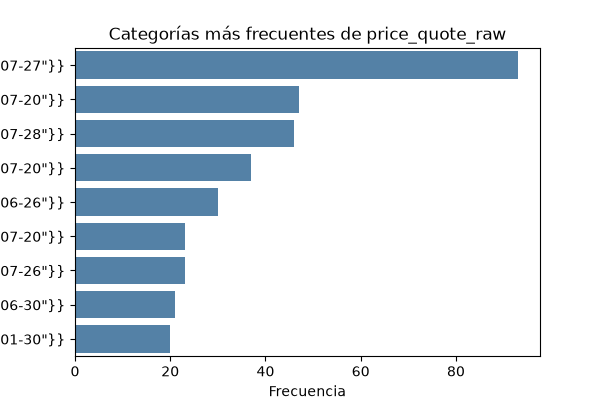

nulos=1631  valores unicos=12192
raw con dato pero price_quote_price_per_night nulo: 307


In [153]:
ruta = graficar_categorica(listings["price_quote_raw"], "price_quote_raw", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["price_quote_raw"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()}")

raw_no_nulo = s.notna()
ppn_nulo = listings["price_quote_price_per_night"].isna()
print(f"raw con dato pero price_quote_price_per_night nulo: {(raw_no_nulo & ppn_nulo).sum()}")

El gráfico no es útil: cada valor es un bloque de texto JSON casi único, así que no hay categorías que comparar.

1.631 nulos, 12.192 valores distintos (prácticamente uno por fila con dato). Hay 307 filas adicionales donde `price_quote_raw` sí tiene el JSON, pero `price_quote_price_per_night` no tiene dato: son casos donde se intentó la cotización y el alojamiento no estaba disponible para esas fechas (`"is_available": false`), así que el JSON no trae ningún precio que extraer.

### Nota de gobernanza: los nulos de `price_quote_*` no necesitan tratamiento propio

Las 5 columnas `price_quote_*` (`price_quote_raw`, `price_quote_checkin_date`, `price_quote_checkout_date`, `price_quote_price_per_night`, `price_quote_total_price`) tienen nulos parciales (10,7%-12,7%) que no están cubiertos por ninguna decisión de tratamiento en el notebook 05 — a diferencia de `price`, `bedrooms`, `bathrooms`, `beds`, `host_about`, `host_location` y `license`, que sí la tienen.

In [154]:
sin_quote = listings[listings["price_quote_raw"].isna()]
print("Total sin price_quote_raw:", len(sin_quote))
print("De esos, con price también nulo:", sin_quote["price"].isna().sum())

mask_307 = listings["price_quote_raw"].notna() & listings["price_quote_price_per_night"].isna()
print()
print("Total con price_quote_raw pero sin price_quote_price_per_night:", mask_307.sum())
print("De esos, con price también nulo:", listings.loc[mask_307, "price"].isna().sum())

print()
print("Resumen: nulos de price:", listings["price"].isna().sum(),
      "| nulos de price_quote_price_per_night:", listings["price_quote_price_per_night"].isna().sum())

Total sin price_quote_raw: 1631
De esos, con price tambien nulo: 1631

Total con price_quote_raw pero sin price_quote_price_per_night: 307
De esos, con price tambien nulo: 307

Resumen: nulos de price: 1938 | nulos de price_quote_price_per_night: 1938


Causa raíz confirmada, y es limpia: los nulos de `price_quote_*` **no son un problema independiente**, son 100% consecuencia de `price`.

Los 1.938 nulos de `price` coinciden exactamente con los 1.938 nulos de `price_quote_price_per_night`. De esos, 1.631 nunca llegaron a intentar la cotización (`price_quote_raw` también nulo — sin precio base, Inside Airbnb no puede simular una reserva), y los otros 307 sí tienen el JSON de la cotización pero volvió sin precio porque el alojamiento no estaba disponible para esas fechas de prueba (y también tienen `price` nulo).

**Decisión de gobernanza**: no se trata por separado — es un nulo estructural derivado al 100% de `price` (L2, ya con decisión de imputación en el notebook 05). Imputar un valor de cotización inventado para estas filas no tendría sentido, ya que `price_quote_*` representa una simulación real que Inside Airbnb no pudo ejecutar, no se puede recrear después del hecho.

### Cruce: noches implicitas del `price_quote` (`checkin`-`checkout`) según `minimum_nights`

`price_quote_price_per_night` resulta ser identico a `price` en el 100% de los casos no nulos (misma columna, solo que recalculada por Airbnb al momento del scraping). Lo que si varia es cuantas noches cubre cada presupuesto (`price_quote_checkout_date` menos `price_quote_checkin_date`). La hipotesis: Airbnb genera el presupuesto usando la estancia mínima que exige cada anuncio, no una fecha fija para todos.

Correlacion noches_quote vs minimum_nights: 0.978
% de filas donde coinciden exactamente: 83.4 %


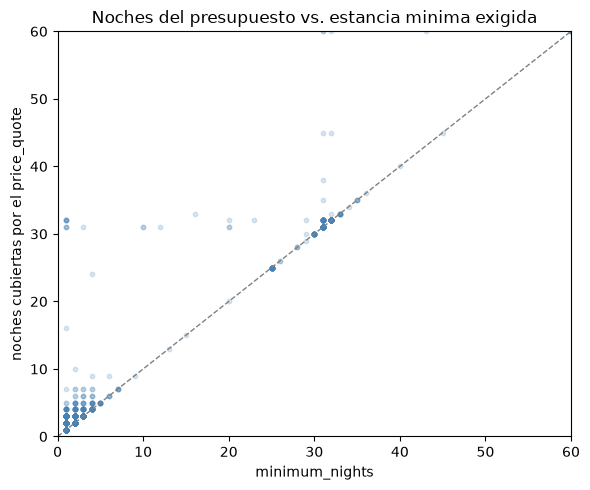

In [155]:
checkin = pd.to_datetime(listings["price_quote_checkin_date"], errors="coerce")
checkout = pd.to_datetime(listings["price_quote_checkout_date"], errors="coerce")
noches_quote = (checkout - checkin).dt.days

comparacion = pd.DataFrame({"noches_quote": noches_quote, "minimum_nights": listings["minimum_nights"]}).dropna()
print("Correlación noches_quote vs minimum_nights:", round(comparacion["noches_quote"].corr(comparacion["minimum_nights"]), 3))
print("% de filas donde coinciden exactamente:", round((comparacion["noches_quote"] == comparacion["minimum_nights"]).mean() * 100, 1), "%")

fig, ax = plt.subplots(figsize=(6, 5))
muestra = comparacion.sample(min(3000, len(comparacion)), random_state=42)
ax.scatter(muestra["minimum_nights"], muestra["noches_quote"], alpha=0.2, s=10, color="steelblue")
ax.plot([0, 300], [0, 300], color="gray", linestyle="--", linewidth=1)
ax.set_xlim(0, 60)
ax.set_ylim(0, 60)
ax.set_xlabel("minimum_nights")
ax.set_ylabel("noches cubiertas por el price_quote")
ax.set_title("Noches del presupuesto vs. estancia mínima exigida")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/pricequote_noches_minimum_nights.png", dpi=100)
plt.show()

Confirmado: correlación de 0,978 y coincidencia exacta en el 83,4% de los casos. El presupuesto que genera Airbnb simula una reserva de exactamente `minimum_nights` noches (con la diagonal gris como referencia de coincidencia perfecta en el gráfico). Esto explica por que `price_quote_total_price` no es un número comparable entre anuncios: no representa "el precio de una estancia típica", sino el precio de *la estancia mínima que cada anuncio exige*, que varia de 1 a 32 noches según el caso.

Tambien se verifico que `price_quote_total_price` es simplemente `price_quote_price_per_night x noches_quote` (diferencia media 0,0002%, sin descuento visible por estancias largas) — es decir, es un calculo derivado sin información nueva propia, una vez que se conocen `price` y `minimum_nights`.

### `price_quote_total_price`

Precio total de esa misma cotización de reserva de prueba, para el rango de noches entre `price_quote_checkin_date` y `price_quote_checkout_date`.

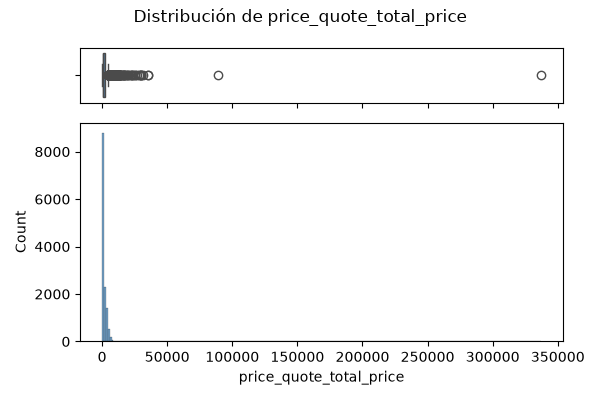

Q1=388.0  mediana=848.0  Q3=2193.0550000000003  max=337351.0
nulos=1938
coincide con price_per_night x noches (margen de redondeo <1): 13354 de 13355


In [156]:
ruta = graficar_numerica(listings["price_quote_total_price"], "price_quote_total_price", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["price_quote_total_price"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")

checkin = pd.to_datetime(listings["price_quote_checkin_date"])
checkout = pd.to_datetime(listings["price_quote_checkout_date"])
noches = (checkout - checkin).dt.days
esperado = listings["price_quote_price_per_night"] * noches
diff = (s - esperado).abs()
print(f"coincide con price_per_night x noches (margen de redondeo <1): {(diff < 1).sum()} de {s.notna().sum()}")

Percentiles: 25% = 388, mediana = 848, 75% = 2.193,06. Máximo 337.351. 1.938 nulos (mismas filas que `price_quote_price_per_night`).

Coincide con `price_quote_price_per_night × número de noches` en 13.354 de 13.355 filas (la única excepción difiere en 1 unidad por redondeo): no aporta información nueva, es el mismo precio por noche multiplicado por la duración de la estancia. El máximo (337.351) es el mismo caso extremo de `price_quote_price_per_night` (10.542,22€), por 32 noches.

### `property_type`

Tipo de propiedad del anuncio, con más detalle que `room_type` (por ejemplo "Entire rental unit", "Private room in hostel").

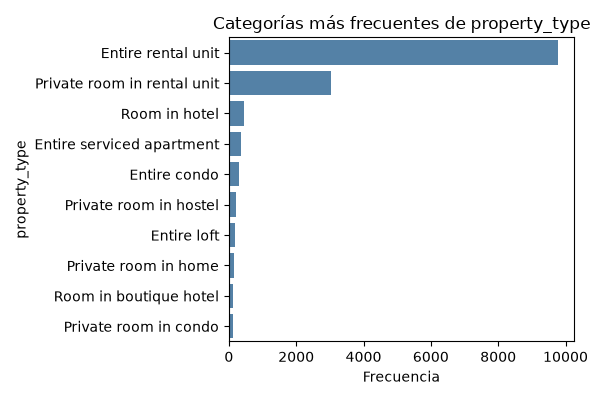

nulos=0  valores unicos=50
property_type
Entire rental unit             9772
Private room in rental unit    3021
Room in hotel                   449
Entire serviced apartment       364
Entire condo                    312
Name: count, dtype: int64


In [157]:
ruta = graficar_categorica(listings["property_type"], "property_type", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["property_type"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()}")
print(s.value_counts().head(5))

Sin nulos, 50 categorías. La más frecuente es "Entire rental unit" (9.772, el 65% de los anuncios), seguida de "Private room in rental unit" (3.021). El resto de categorías son minoritarias.

Es más granular que `room_type` (que solo tiene 4 categorías: Entire home/apt, Private room, Shared room, Hotel room): una misma categoría de `room_type` puede agrupar varios `property_type` distintos. Por ejemplo, "Room in hotel" se reparte entre "Private room" (440) y "Hotel room" (9) en `room_type`.

### `review_scores_accuracy`

Puntuación promedio (0 a 5) de qué tan bien se ajustó el anuncio a la realidad de la estancia, según las reseñas de los huéspedes.

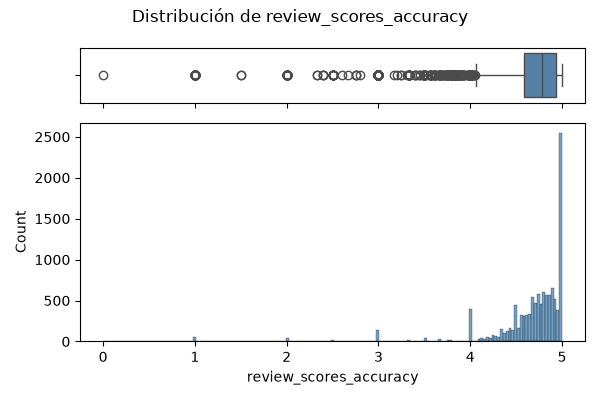

nulos=3549 (23.2%)
count    11744.000000
mean         4.666483
std          0.468210
min          0.000000
25%          4.580000
50%          4.780000
75%          4.930000
max          5.000000
Name: review_scores_accuracy, dtype: float64
nulos que coinciden con 0 reviews: 3548 de 3549


In [158]:
ruta = graficar_numerica(listings["review_scores_accuracy"], "review_scores_accuracy", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["review_scores_accuracy"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(s.describe())

sin_reviews = listings["number_of_reviews"] == 0
print(f"nulos que coinciden con 0 reviews: {(s.isna() & sin_reviews).sum()} de {s.isna().sum()}")

23,2% nulos (3.549) — casi todos (3.548) son anuncios sin ninguna reseña (`number_of_reviews == 0`), que por eso no tienen puntuación. Queda solo 1 caso con 1 reseña pero sin este dato.

Entre los que sí tienen dato, la mediana es 4,78 y el 75% está en 4,93 o más: las puntuaciones están muy concentradas cerca del máximo (5), con pocos valores bajos que aparecen como puntos sueltos en el boxplot.

### `review_scores_checkin`

Puntuación promedio (0 a 5) de la experiencia de check-in, según las reseñas de los huéspedes.

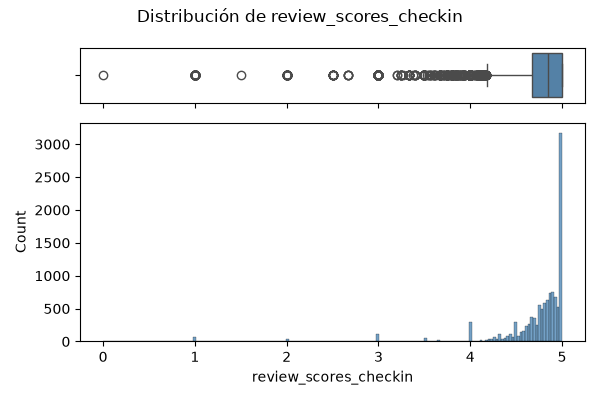

nulos=3549 (23.2%)
count    11744.000000
mean         4.726335
std          0.463476
min          0.000000
25%          4.670000
50%          4.850000
75%          5.000000
max          5.000000
Name: review_scores_checkin, dtype: float64
nulos que coinciden con 0 reviews: 3548 de 3549


In [159]:
ruta = graficar_numerica(listings["review_scores_checkin"], "review_scores_checkin", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["review_scores_checkin"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(s.describe())

sin_reviews = listings["number_of_reviews"] == 0
print(f"nulos que coinciden con 0 reviews: {(s.isna() & sin_reviews).sum()} de {s.isna().sum()}")

Mismo patrón que `review_scores_accuracy`: 23,2% nulos (3.549), casi todos (3.548) por no tener ninguna reseña.

Entre los que sí tienen dato, la mediana es 4,85 y el 75% llega al máximo (5): aún más concentrado cerca de 5 que `review_scores_accuracy`.

### `review_scores_cleanliness`

Puntuación promedio (0 a 5) de la limpieza del alojamiento, según las reseñas de los huéspedes.

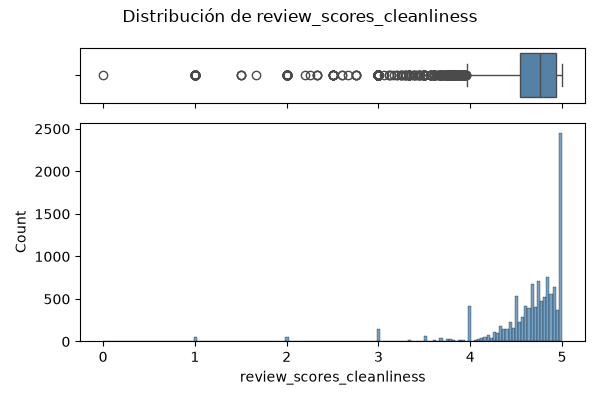

nulos=3549 (23.2%)
count    11744.000000
mean         4.641838
std          0.479856
min          0.000000
25%          4.540000
50%          4.760000
75%          4.930000
max          5.000000
Name: review_scores_cleanliness, dtype: float64
nulos que coinciden con 0 reviews: 3548 de 3549


In [160]:
ruta = graficar_numerica(listings["review_scores_cleanliness"], "review_scores_cleanliness", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["review_scores_cleanliness"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(s.describe())

sin_reviews = listings["number_of_reviews"] == 0
print(f"nulos que coinciden con 0 reviews: {(s.isna() & sin_reviews).sum()} de {s.isna().sum()}")

Mismo patrón que los demás `review_scores_*`: 23,2% nulos (3.549), casi todos (3.548) por no tener ninguna reseña.

Entre los que sí tienen dato, la mediana es 4,76 y el 75% está en 4,93 o más, concentrado cerca de 5 igual que `review_scores_accuracy` y `review_scores_checkin`.

### `review_scores_communication`

Puntuación promedio (0 a 5) de la comunicación con el anfitrión, según las reseñas de los huéspedes.

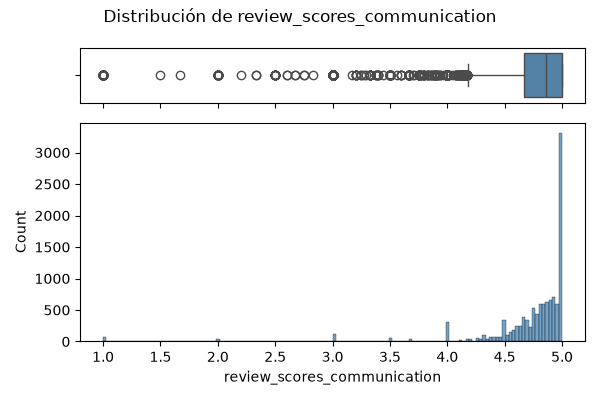

nulos=3549 (23.2%)
count    11744.000000
mean         4.722973
std          0.478455
min          1.000000
25%          4.670000
50%          4.860000
75%          5.000000
max          5.000000
Name: review_scores_communication, dtype: float64
nulos que coinciden con 0 reviews: 3548 de 3549


In [161]:
ruta = graficar_numerica(listings["review_scores_communication"], "review_scores_communication", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["review_scores_communication"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(s.describe())

sin_reviews = listings["number_of_reviews"] == 0
print(f"nulos que coinciden con 0 reviews: {(s.isna() & sin_reviews).sum()} de {s.isna().sum()}")

Mismo patrón que los demás `review_scores_*`: 23,2% nulos (3.549), casi todos (3.548) por no tener ninguna reseña.

Entre los que sí tienen dato, la mediana es 4,86 y el 75% llega al máximo (5). A diferencia de las anteriores, el mínimo registrado es 1 (no 0).

### `review_scores_location`

Puntuación promedio (0 a 5) de la ubicación del alojamiento, según las reseñas de los huéspedes.

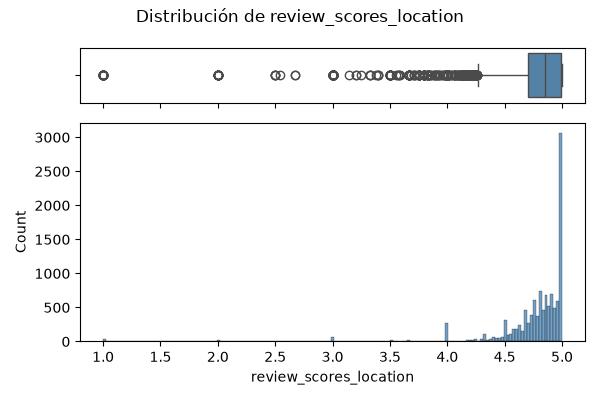

nulos=3549 (23.2%)
count    11744.000000
mean         4.766025
std          0.362881
min          1.000000
25%          4.700000
50%          4.850000
75%          4.990000
max          5.000000
Name: review_scores_location, dtype: float64
nulos que coinciden con 0 reviews: 3548 de 3549


In [162]:
ruta = graficar_numerica(listings["review_scores_location"], "review_scores_location", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["review_scores_location"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(s.describe())

sin_reviews = listings["number_of_reviews"] == 0
print(f"nulos que coinciden con 0 reviews: {(s.isna() & sin_reviews).sum()} de {s.isna().sum()}")

Mismo patrón que los demás `review_scores_*`: 23,2% nulos (3.549), casi todos (3.548) por no tener ninguna reseña.

Entre los que sí tienen dato, la mediana es 4,85 y el 75% está en 4,99: es la más concentrada cerca del máximo de todas las vistas hasta ahora. Mínimo registrado de 1.

### `review_scores_rating`

Puntuación general promedio (0 a 5) del alojamiento, según las reseñas de los huéspedes. Es la puntuación global, distinta de las sub-puntuaciones (`accuracy`, `checkin`, `cleanliness`, `communication`, `location`).

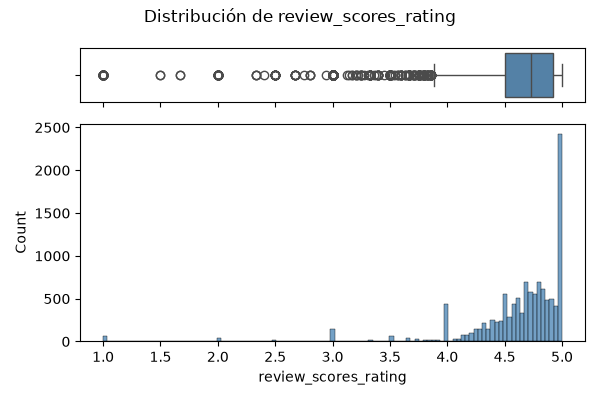

nulos=3548 (23.2%)
count    11745.000000
mean         4.617601
std          0.490382
min          1.000000
25%          4.500000
50%          4.730000
75%          4.920000
max          5.000000
Name: review_scores_rating, dtype: float64
nulos que coinciden con 0 reviews: 3548 de 3548


In [163]:
ruta = graficar_numerica(listings["review_scores_rating"], "review_scores_rating", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["review_scores_rating"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(s.describe())

sin_reviews = listings["number_of_reviews"] == 0
print(f"nulos que coinciden con 0 reviews: {(s.isna() & sin_reviews).sum()} de {s.isna().sum()}")

23,2% nulos (3.548), y aquí sí coincide exactamente con los anuncios sin ninguna reseña (`number_of_reviews == 0`), sin la excepción de 1 caso que aparecía en las sub-puntuaciones.

Entre los que sí tienen dato, la mediana es 4,73 y el 75% está en 4,92. Es algo menos concentrada cerca de 5 que las sub-puntuaciones individuales (desviación estándar 0,49, la más alta de todo el grupo `review_scores_*`).

### Cruce: `review_scores_rating` según tipo de anfitrión

`review_scores_rating` es un promedio por anuncio (agregando todas sus reseñas), no una puntuación por comentario individual — eso no existe en `reviews.csv`. Aun así, es la forma correcta de responder qué grupo tiene mejores reseñas en promedio.

,Mediana,Media,n
tipo_anfitrion,,,
Particular,4.75,4.658,9746
Profesional,4.59,4.422,1999


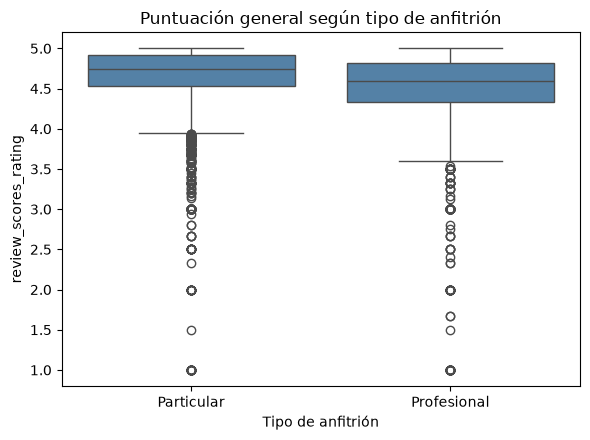


Las 6 sub-puntuaciones, mismo cruce (solo medias):


tipo_anfitrion,Particular,Profesional,diferencia
review_scores_rating,4.658,4.422,0.236
review_scores_accuracy,4.698,4.511,0.187
review_scores_checkin,4.771,4.508,0.263
review_scores_cleanliness,4.666,4.524,0.141
review_scores_communication,4.770,4.494,0.275
review_scores_location,4.779,4.705,0.074
review_scores_value,4.513,4.235,0.278


In [164]:
tabla_cruce = listings.groupby("tipo_anfitrion")["review_scores_rating"].agg(
    Mediana="median", Media="mean", n="count"
)
display(tabla_cruce.round(3))

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=listings, x="tipo_anfitrion", y="review_scores_rating", order=["Particular", "Profesional"], color="steelblue", ax=ax)
ax.set_xlabel("Tipo de anfitrión")
ax.set_ylabel("review_scores_rating")
ax.set_title("Puntuación general según tipo de anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/review_scores_rating_tipo_anfitrion.png", dpi=100)
plt.show()

print()
print("Las 6 sub-puntuaciones, mismo cruce (solo medias):")
cols_scores = ["review_scores_rating", "review_scores_accuracy", "review_scores_checkin",
               "review_scores_cleanliness", "review_scores_communication", "review_scores_location", "review_scores_value"]
resumen = listings.groupby("tipo_anfitrion")[cols_scores].mean().T
resumen["diferencia"] = resumen["Particular"] - resumen["Profesional"]
display(resumen.round(3))

Los particulares tienen mejor puntuación en **las 7 dimensiones**, sin excepción: media general 4,658 vs. 4,422 en profesionales (mediana 4,75 vs. 4,59).

La brecha más grande está en `communication` (4,770 vs. 4,494, diferencia de 0,276) y `checkin` (4,771 vs. 4,508); la más pequeña en `location` (4,779 vs. 4,705, diferencia de solo 0,074) — tiene sentido, la ubicación no depende de cómo gestiona el anfitrión, es fija.

Este hallazgo refuerza el mismo patrón ya visto con `price` y `estimated_revenue_l365d`: los profesionales no solo generan menos ingresos por anuncio, también reciben peores valoraciones — especialmente en las dimensiones ligadas al trato directo con el huésped (comunicación, check-in), más que en las fijas del alojamiento (ubicación).

### `review_scores_value`

Puntuación promedio (0 a 5) de la relación calidad-precio del alojamiento, según las reseñas de los huéspedes.

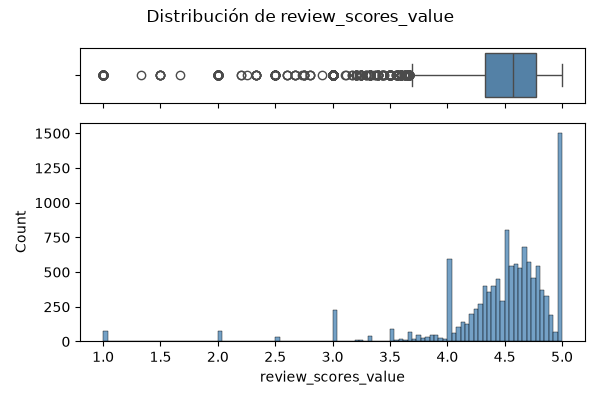

nulos=3549 (23.2%)
count    11744.000000
mean         4.465703
std          0.542243
min          1.000000
25%          4.330000
50%          4.570000
75%          4.770000
max          5.000000
Name: review_scores_value, dtype: float64
nulos que coinciden con 0 reviews: 3548 de 3549


In [165]:
ruta = graficar_numerica(listings["review_scores_value"], "review_scores_value", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["review_scores_value"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(s.describe())

sin_reviews = listings["number_of_reviews"] == 0
print(f"nulos que coinciden con 0 reviews: {(s.isna() & sin_reviews).sum()} de {s.isna().sum()}")

Mismo patrón que las demás `review_scores_*`: 23,2% nulos (3.549), casi todos (3.548) por no tener ninguna reseña.

Entre los que sí tienen dato, la mediana es 4,57 — la más baja de las seis columnas `review_scores_*` vistas, y también la de mayor dispersión (desviación estándar 0,54). Es la dimensión peor valorada en comparación con accuracy, checkin, cleanliness, communication y location.

### `reviews_per_month`

Promedio de reseñas por mes, calculado por Inside Airbnb desde la fecha de la primera reseña hasta el scraping.

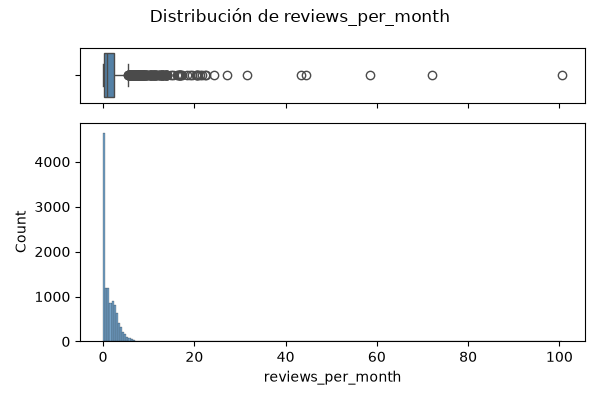

nulos=3548 (23.2%)
count    11745.000000
mean         1.555447
std          2.318884
min          0.010000
25%          0.220000
50%          0.950000
75%          2.350000
max        100.580000
Name: reviews_per_month, dtype: float64
nulos que coinciden con 0 reviews: 3548 de 3548
maximo: 100.58 -> number_of_reviews=1455, first_review=2025-04-17, last_review=2026-06-17


In [166]:
ruta = graficar_numerica(listings["reviews_per_month"], "reviews_per_month", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["reviews_per_month"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.1f}%)")
print(s.describe())

sin_reviews = listings["number_of_reviews"] == 0
print(f"nulos que coinciden con 0 reviews: {(s.isna() & sin_reviews).sum()} de {s.isna().sum()}")

fila_max = listings.loc[s.idxmax()]
print(f"máximo: {s.max()} -> number_of_reviews={fila_max['number_of_reviews']}, first_review={fila_max['first_review']}, last_review={fila_max['last_review']}")

23,2% nulos (3.548), coincide exactamente con los anuncios sin ninguna reseña.

Entre los que sí tienen dato, la mediana es 0,95 reseñas al mes, 75% por debajo de 2,35. El máximo (100,58) corresponde a un anuncio con 1.455 reseñas entre abril de 2025 y junio de 2026 (unos 14 meses), consistente con el cálculo — no es un error, es un anuncio con un volumen de reservas muy por encima del resto.

### Cruce: `reviews_per_month` según antigüedad como anfitrión (`hosts_time_as_host_years`)

`hosts_time_as_host_years` ya se cruzo con `tipo_anfitrion` (los profesionales llevan más tiempo). Aqui la pregunta es distinta: ¿un anfitrión con más años de experiencia recibe reseñas a un ritmo más alto o más bajo que uno nuevo? `reviews_per_month` ya normaliza por el tiempo que lleva publicado el anuncio, así que no es solo "acumular más tiempo = más reseñas".

Correlacion: -0.038


,median,mean,count
tramo_antiguedad_host,,,
0-1,1.14,1.97,758
1-3,0.83,1.90,1309
3-6,0.38,1.41,2010
6-10,0.50,1.28,3371
10+,1.39,1.66,4233


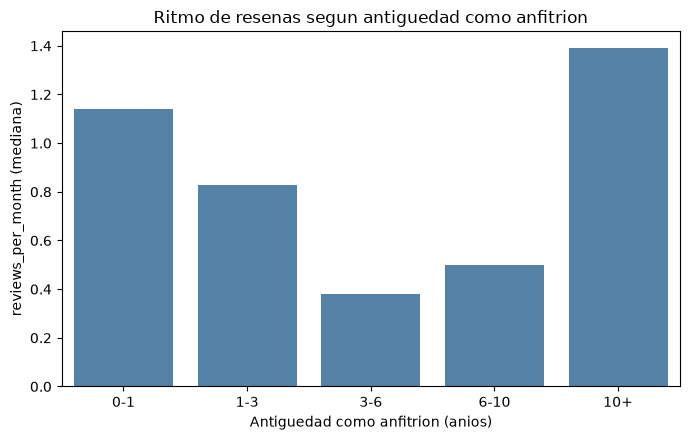

In [167]:
print("Correlación:", round(listings["hosts_time_as_host_years"].corr(listings["reviews_per_month"]), 3))

bins = [0, 1, 3, 6, 10, 100]
labels = ["0-1", "1-3", "3-6", "6-10", "10+"]
listings["tramo_antiguedad_host"] = pd.cut(listings["hosts_time_as_host_years"], bins=bins, labels=labels, include_lowest=True)

tabla = listings.groupby("tramo_antiguedad_host", observed=True)["reviews_per_month"].agg(["median", "mean", "count"]).round(2)
display(tabla)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=tabla.index, y=tabla["median"], color="steelblue", ax=ax)
ax.set_xlabel("Antigüedad como anfitrión (años)")
ax.set_ylabel("reviews_per_month (mediana)")
ax.set_title("Ritmo de reseñas según antigüedad como anfitrión")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/reviewspermonth_antiguedad.png", dpi=100)
plt.show()

Correlación prácticamente nula (-0,038) y un patrón en forma de **U**, no una tendencia simple: la mediana de `reviews_per_month` es más alta en los extremos — anfitriones muy nuevos (0-1 año, mediana 1,14) y los más veteranos (10+ años, mediana 1,39) — y cae en el tramo intermedio (3-6 años, mediana 0,38; 6-10 años, mediana 0,50).

Interpretación: los anfitriones nuevos suelen arrancar con un "impulso" inicial (entusiasmo, precios de lanzamiento más bajos, o anuncios muy activos desde el principio), que se diluye en la etapa intermedia, y los veteranos que siguen activos despues de 10 años son probablemente los que mejor gestionan su cartera — los que no funcionaban ya habrán abandonado. No es evidencia de que "más experiencia" cause más reseñas de forma directa; es más bien un efecto de selección y de ciclo de vida del anuncio.

### `room_type`

Tipo de habitación del anuncio, con 4 categorías posibles. Es una versión simplificada de `property_type`.

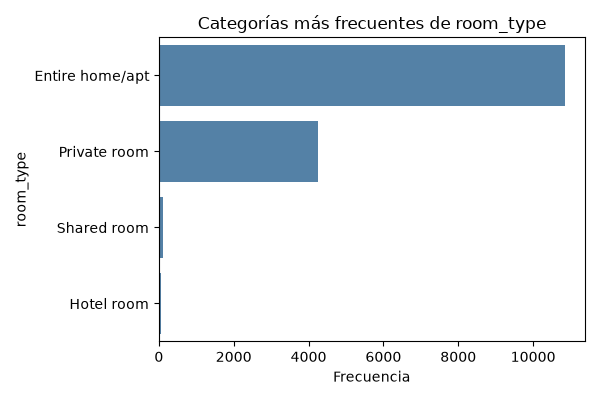

nulos=0  valores unicos=4
room_type
Entire home/apt    10844
Private room        4262
Shared room          119
Hotel room            68
Name: count, dtype: int64
room_type
Entire home/apt    70.9
Private room       27.9
Shared room         0.8
Hotel room          0.4
Name: proportion, dtype: float64


In [168]:
ruta = graficar_categorica(listings["room_type"], "room_type", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["room_type"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()}")
print(s.value_counts())
print((s.value_counts(normalize=True)*100).round(1))

Sin nulos, 4 categorías. "Entire home/apt" es la ampliamente mayoritaria (10.844, 70,9%), seguida de "Private room" (4.262, 27,9%). "Shared room" (0,8%) y "Hotel room" (0,4%) son marginales.

### Cruce: `availability_365` según `room_type`

`room_type` ya se cruzo muchas veces junto a `tipo_anfitrion` (ingresos, licencia, estancia mínima, composición). Aqui el ángulo es distinto: dentro de las 4 categorías de `room_type`, ¿cual tiene el calendario más "lleno" (menos días libres, más señal de demanda real)? `availability_365` ya se usó antes como proxy de ocupación para comparar particular vs. profesional; ahora se aplica directamente a `room_type`.

,median,mean,count
room_type,,,
Entire home/apt,252.0,227.2,10844
Hotel room,180.0,191.5,68
Private room,180.0,174.7,4262
Shared room,277.0,231.9,119


% con calendario completamente lleno (0 dias libres):
room_type
Entire home/apt     3.1
Hotel room          8.8
Private room       24.3
Shared room        14.3
Name: availability_365, dtype: float64

% con calendario completamente libre (365 dias, sin reservas/inactivo):
room_type
Entire home/apt    5.7
Hotel room         0.0
Private room       5.2
Shared room        0.8
Name: availability_365, dtype: float64


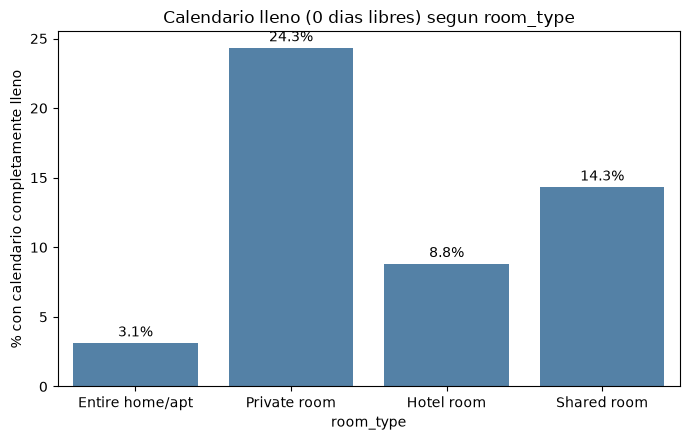

In [169]:
tabla = listings.groupby("room_type")["availability_365"].agg(["median", "mean", "count"]).round(1)
display(tabla)

pct_lleno = listings.groupby("room_type")["availability_365"].apply(lambda s: (s == 0).mean() * 100).round(1)
pct_vacio = listings.groupby("room_type")["availability_365"].apply(lambda s: (s == 365).mean() * 100).round(1)
print("% con calendario completamente lleno (0 días libres):")
print(pct_lleno)
print()
print("% con calendario completamente libre (365 días, sin reservas/inactivo):")
print(pct_vacio)

fig, ax = plt.subplots(figsize=(7, 4.5))
orden = ["Entire home/apt", "Private room", "Hotel room", "Shared room"]
sns.barplot(x=orden, y=pct_lleno.reindex(orden), color="steelblue", ax=ax)
for i, v in enumerate(pct_lleno.reindex(orden)):
    ax.text(i, v + 0.5, f"{v}%", ha="center")
ax.set_xlabel("room_type")
ax.set_ylabel("% con calendario completamente lleno")
ax.set_title("Calendario lleno (0 días libres) según room_type")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/roomtype_availability.png", dpi=100)
plt.show()

Resultado con matiz interesante: por mediana de días libres, "Private room" (180) y "Hotel room" (180) parecen más ocupados que "Entire home/apt" (252) y "Shared room" (277). Pero al mirar el extremo de calendario completamente lleno, la diferencia es mucho más marcada: 24,3% de los `Private room` tienen 0 días libres en todo el año, frente a solo 3,1% de los `Entire home/apt`.

Es decir, "Private room" no solo tiene mediana más baja — tiene una cola gruesa de anuncios con demanda muy alta (calendario agotado), algo que la mediana sola no mostraba con esa claridad. Con los datos disponibles no se puede distinguir si esto refleja más demanda real o un bloqueo manual del calendario por parte del anfitrión (p. ej. para uso propio), pero el contraste frente a "Entire home/apt" es consistente con lo visto en licencia (cruceLI5): "Private room" es la categoría con comportamiento más distinto al resto.

### `scrape_id`

Identificador numérico de la ejecución del scraping. Es un código técnico interno de Inside Airbnb, igual para todas las filas de este dataset.

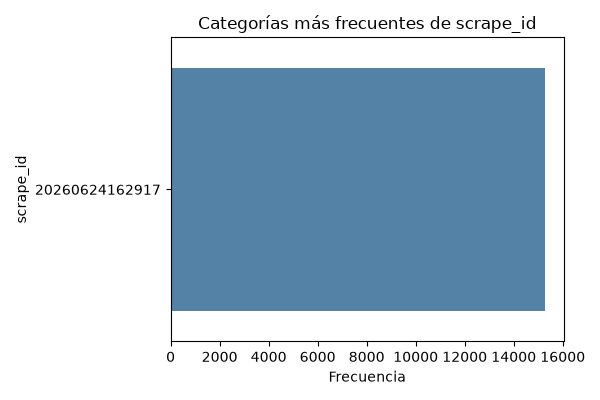

nulos=0  valores unicos=1
[20260624162917]


In [170]:
ruta = graficar_categorica(listings["scrape_id"], "scrape_id", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["scrape_id"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()}")
print(s.unique())

Sin nulos, un único valor para las 15.293 filas (20260624162917), que codifica la fecha y hora del scraping (24 de junio de 2026, 16:29:17). No aporta información para el análisis, ya que no varía entre filas.

### `source`

Indica cómo se detectó el anuncio en este scraping: "city scrape" (encontrado buscando directamente en la ciudad) o "previous scrape" (ya existía en el scraping anterior y se verificó que sigue activo).

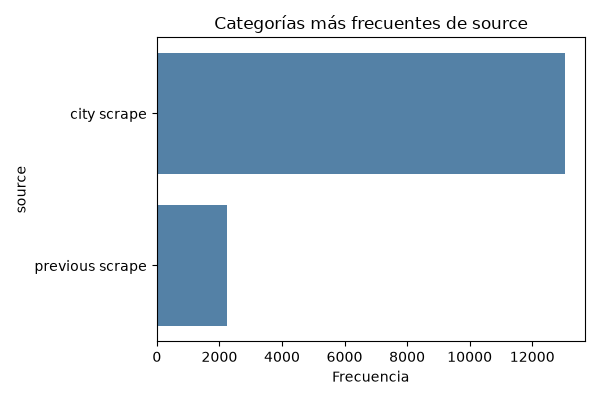

nulos=0  valores unicos=2
source
city scrape        13035
previous scrape     2258
Name: count, dtype: int64
source
city scrape        85.2
previous scrape    14.8
Name: proportion, dtype: float64
                        min         max
source                                 
city scrape      2026-06-24  2026-06-25
previous scrape  2026-07-02  2026-07-03


In [171]:
ruta = graficar_categorica(listings["source"], "source", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["source"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()}")
print(s.value_counts())
print((s.value_counts(normalize=True)*100).round(1))

fechas = pd.to_datetime(listings["last_scraped"])
print(listings.groupby("source")["last_scraped"].agg(["min", "max"]))

Sin nulos, 2 categorías: "city scrape" (13.035, 85,2%) y "previous scrape" (2.258, 14,8%).

Los anuncios "previous scrape" tienen `last_scraped` más tardío (2-3 de julio de 2026) que los "city scrape" (24-25 de junio de 2026): consistente con que estos anuncios no aparecieron en la búsqueda principal de la ciudad y se verificaron individualmente después, en una fecha posterior.

### Cruce: `source` según `availability_*` (las 5 ventanas)

`source` ya se usó una vez para explicar un caso puntual de `has_availability="f"`. Aqui se revisa algo más amplio: ¿los anuncios encontrados en el "previous scrape" (reverificados individualmente el 2-3 de julio, en vez de encontrados en la búsqueda por ciudad del 24-25 de junio) tienen un patrón de disponibilidad distinto?

,availability_30,availability_60,availability_90,availability_365,availability_eoy
source,,,,,
city scrape,8.0,25.0,50.0,261.0,136.0
previous scrape,0.0,0.0,0.0,0.0,0.0


% de anuncios con 0 dias libres (calendario lleno), por ventana:


,availability_30,availability_60,availability_90,availability_365,availability_eoy
source,,,,,
city scrape,18.7,8.5,5.5,0.0,2.2
previous scrape,74.4,69.5,67.5,61.4,65.3


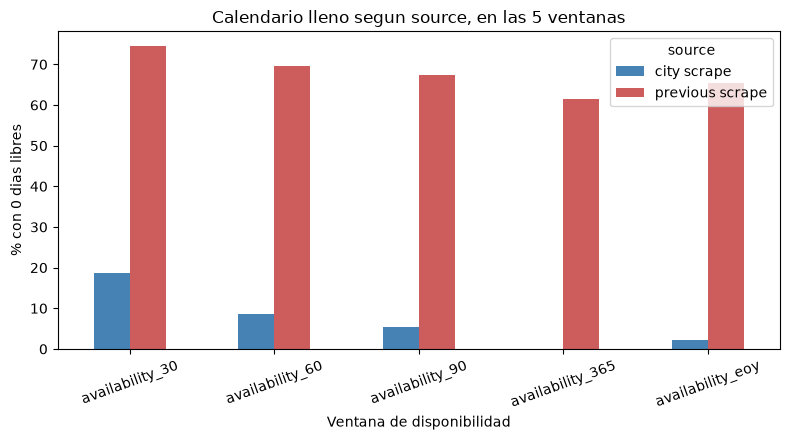

In [172]:
cols_disp = ["availability_30", "availability_60", "availability_90", "availability_365", "availability_eoy"]

tabla = listings.groupby("source")[cols_disp].median()
display(tabla)

pct_cero = pd.DataFrame({col: listings.groupby("source")[col].apply(lambda s: (s == 0).mean() * 100) for col in cols_disp}).round(1)
print("% de anuncios con 0 días libres (calendario lleno), por ventana:")
display(pct_cero)

fig, ax = plt.subplots(figsize=(8, 4.5))
pct_cero.T.plot(kind="bar", ax=ax, color=["steelblue", "indianred"])
ax.set_xlabel("Ventana de disponibilidad")
ax.set_ylabel("% con 0 días libres")
ax.set_title("Calendario lleno según source, en las 5 ventanas")
ax.legend(title="source")
plt.xticks(rotation=20)
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/source_availability.png", dpi=100)
plt.show()

Patron sistematico y muy marcado en las 5 ventanas: los anuncios de `"previous scrape"` tienen entre 65% y 74% con el calendario completamente lleno (0 días libres), frente a solo 2%-19% en `"city scrape"`. La mediana de `availability_365` es 0 para `previous scrape` y 261 para `city scrape`.

Es poco probable que sea ocupación real tan extrema y uniforme en más de 2.000 anuncios distintos. La explicación más plausible, coherente con el mecanismo ya visto en `invHA1` (el caso de `has_availability="f"`), es un **artefacto del método de scraping**: los anuncios de `previous scrape` no se encontraron en la búsqueda por ciudad del 24-25 de junio, sino que se reverificaron individualmente unos días despues (2-3 de julio) porque ya estaban en una base anterior — y es posible que ese proceso de reverificacion no vuelva a consultar el calendario completo, dejando `availability_*` en 0 por defecto en vez de reflejar disponibilidad real.

**Implicacion para el resto del análisis**: cualquier cruce que use `availability_*` (ya se usó varias veces como proxy de ocupación, por ejemplo en `cruceAV1` y en `cruceRTAV1`) podría estar distorsionado si no se filtra por `source`. Se verifica a continuacion si esto cambia la conclusión ya obtenida en `cruceAV1` (profesionales con más días libres que particulares).

In [173]:
print("Composición de source por tipo_anfitrion:")
display((pd.crosstab(listings["tipo_anfitrion"], listings["source"], normalize="index") * 100).round(1))

print()
print("availability_365 por tipo_anfitrion, TODOS los datos (cruceAV1 original):")
display(listings.groupby("tipo_anfitrion")["availability_365"].agg(["median", "mean", "count"]).round(2))

print()
print("availability_365 por tipo_anfitrion, SOLO city scrape (sin el posible artefacto):")
solo_city = listings[listings["source"] == "city scrape"]
display(solo_city.groupby("tipo_anfitrion")["availability_365"].agg(["median", "mean", "count"]).round(2))

Composicion de source por tipo_anfitrion:


source,city scrape,previous scrape
tipo_anfitrion,,
Particular,82.8,17.2
Profesional,93.4,6.6



availability_365 por tipo_anfitrion, TODOS los datos (cruceAV1 original):


,median,mean,count
tipo_anfitrion,,,
Particular,202.0,192.36,11728
Profesional,301.0,278.49,3565



availability_365 por tipo_anfitrion, SOLO city scrape (sin el posible artefacto):


,median,mean,count
tipo_anfitrion,,,
Particular,236.0,220.24,9706
Profesional,305.0,288.22,3329


**Verificado, la conclusión de `cruceAV1` se mantiene**: filtrando solo `"city scrape"` (quitando el posible artefacto), los profesionales siguen con mediana más alta de días libres (305 vs. 236 en particulares) — una brecha de 69 días, del mismo orden que la brecha de 99 días vista con todos los datos (301 vs. 202).

De hecho el sesgo iba en la dirección contraria a lo que podría preocupar: los particulares tienen más representación en `previous scrape` (17,2% vs. 6,6% de los profesionales), así que el posible artefacto hacia ver a los particulares **más ocupados** de lo que en realidad están (mediana 202 con todos los datos vs. 236 sin el artefacto). El hallazgo de `cruceAV1` no solo no se invalida — queda confirmado con un margen similar incluso despues de quitar el ruido.

### `neighbourhood_group_cleansed`

Distrito de Barcelona, el nivel administrativo por encima del barrio (`neighbourhood_cleansed`).

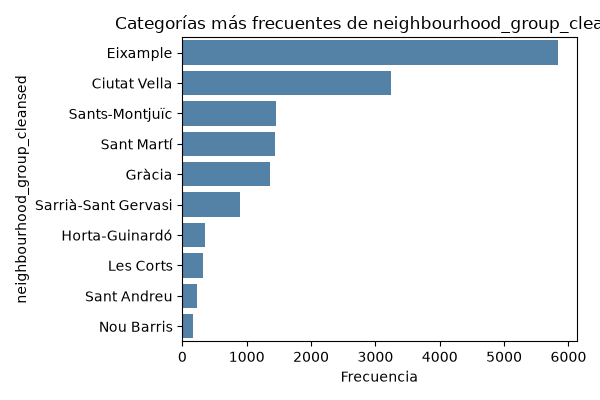

nulos=0  valores unicos=10
neighbourhood_group_cleansed
Eixample               5835
Ciutat Vella           3247
Sants-Montjuïc         1448
Sant Martí             1436
Gràcia                 1366
Sarrià-Sant Gervasi     888
Horta-Guinardó          358
Les Corts               327
Sant Andreu             225
Nou Barris              163
Name: count, dtype: int64


In [174]:
ruta = graficar_categorica(listings["neighbourhood_group_cleansed"], "neighbourhood_group_cleansed", CARPETA_LISTINGS)
display(Image(ruta))

s = listings["neighbourhood_group_cleansed"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()}")
print(s.value_counts())

Sin nulos, 10 categorías (los 10 distritos de Barcelona). "Eixample" es el distrito con más anuncios (5.835, 38,2%), seguido de "Ciutat Vella" (3.247, 21,2%); "Nou Barris" es el de menos (163).

Cada distrito agrupa varios barrios de `neighbourhood_cleansed` — por ejemplo, Eixample incluye 6 barrios distintos.

### Cruce: `host_is_superhost` (%) según distrito, comparado con `review_scores_rating`

`neighbourhood_group_cleansed` ya se cruzo con `accommodates`, `tipo_anfitrion`, `calculated_host_listings_count`, `estimated_revenue_l365d` y `license`. Angulo nuevo: ¿los distritos con más superhosts tienen también mejor puntuación de los huéspedes, o son cosas independientes?

,% superhost,review_scores_rating (mediana),n
neighbourhood_group_cleansed,,,
Les Corts,37.61,4.75,327
Sant Martí,28.48,4.73,1436
Eixample,27.46,4.72,5835
Ciutat Vella,24.30,4.75,3247
Sants-Montjuïc,24.10,4.71,1448
Horta-Guinardó,24.02,4.72,358
Gràcia,23.50,4.75,1366
Sarrià-Sant Gervasi,22.07,4.75,888
Sant Andreu,17.33,4.69,225


Correlacion a nivel distrito (n=10 distritos): -0.116


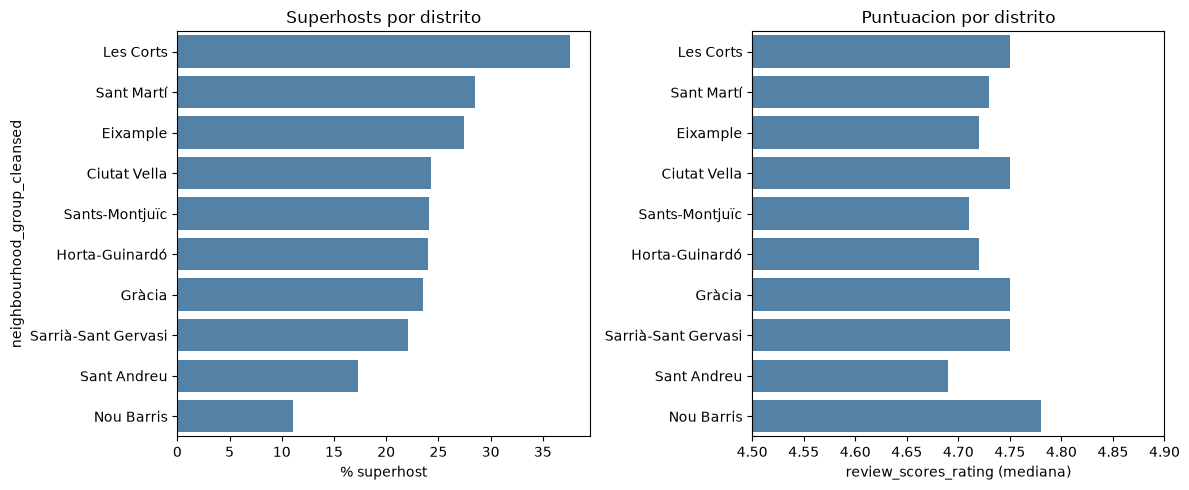

In [175]:
pct_superhost = listings.groupby("neighbourhood_group_cleansed")["host_is_superhost"].apply(lambda s: (s == "t").mean() * 100)
rating_mediana = listings.groupby("neighbourhood_group_cleansed")["review_scores_rating"].median()
n_anuncios = listings["neighbourhood_group_cleansed"].value_counts()

tabla = pd.DataFrame({"% superhost": pct_superhost, "review_scores_rating (mediana)": rating_mediana, "n": n_anuncios}).round(2)
tabla = tabla.sort_values("% superhost", ascending=False)
display(tabla)

print("Correlación a nivel distrito (n=10 distritos):", round(pct_superhost.corr(rating_mediana), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
orden = tabla.index
sns.barplot(x=tabla["% superhost"], y=orden, color="steelblue", ax=axes[0])
axes[0].set_xlabel("% superhost")
axes[0].set_title("Superhosts por distrito")

sns.barplot(x=tabla["review_scores_rating (mediana)"], y=orden, color="steelblue", ax=axes[1])
axes[1].set_xlim(4.5, 4.9)
axes[1].set_xlabel("review_scores_rating (mediana)")
axes[1].set_title("Puntuación por distrito")
axes[1].set_ylabel("")

fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/distrito_superhost_vs_rating.png", dpi=100)
plt.show()

A nivel de **distrito** (10 puntos, uno por distrito), la correlación es casi nula (-0,116) entre el % de superhosts y la puntuación mediana. El caso más llamativo es "Nou Barris": el % de superhost más bajo de los 10 (11,0%) pero la puntuación mediana más alta (4,78).

Nota de cautela: "Nou Barris" (163 anuncios), "Les Corts" (327) y "Sant Andreu" (225) son los distritos con menos anuncios, así que sus valores son más sensibles a casos puntuales que "Eixample" (5.835) o "Ciutat Vella" (3.247).

In [176]:
print("A nivel de cada anuncio individual (no por distrito):")
display(listings.groupby("host_is_superhost")["review_scores_rating"].agg(["median", "mean", "count"]).round(3))

A nivel de cada anuncio individual (no por distrito):


,median,mean,count
host_is_superhost,,,
f,4.63,4.524,7966
t,4.86,4.819,3715


**Importante: esto no significa que superhost y puntuación sean independientes de verdad.** A nivel de cada anuncio individual la relación es fuerte y en la dirección esperada: mediana de 4,86 en superhosts frente a 4,63 en no-superhosts — una brecha de 0,23 puntos, mucho mayor que *todo* el rango entre distritos (4,69 a 4,78).

Lo que paso es un efecto de agregacion: la puntuación mediana de un distrito mezcla a **todos** los anuncios, y los superhosts son siempre minoría (24,3% del total de la ciudad). Como la mayoría no-superhost domina la mediana en todos los distritos por igual, el valor agregado por distrito queda relativamente plano sin importar cuanto varie el % de superhosts — la relación real (que existe a nivel de anuncio) queda diluida al subir de nivel. Es un recordatorio util: una correlación a nivel agregado (distrito) no tiene por que coincidir con la relación a nivel más fino (anuncio individual).

## Tabla `calendar`

Una fila por cada combinación anuncio-día: disponibilidad y condiciones de reserva para cada fecha futura de cada anuncio.

In [177]:
calendar = pd.read_csv("../data/airbnb_bcn/calendar.csv", low_memory=False)
CARPETA_CALENDAR = "../graficos_exploracion/calendar"
print(calendar.shape)
calendar.head()

(5623190, 5)


,listing_id,date,available,minimum_nights,maximum_nights
0,18674,2026-06-25,f,1,999
1,18674,2026-06-26,f,2,999
2,18674,2026-06-27,f,2,999
3,18674,2026-06-28,t,1,999
4,18674,2026-06-29,f,3,999


### `available`

Indica si el anuncio estaba disponible para reservar en esa fecha concreta ("t" = disponible, "f" = no disponible).

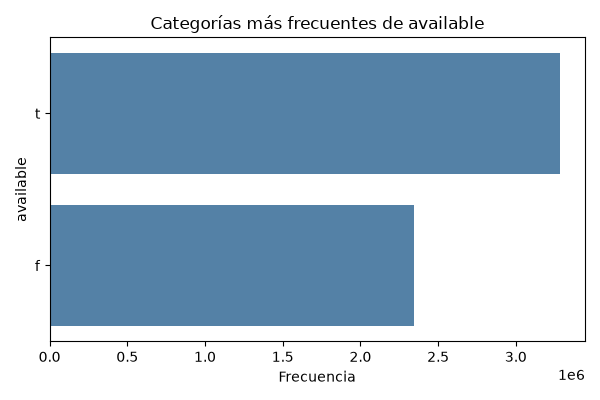

nulos=0  valores unicos=<ArrowStringArray>
['f', 't']
Length: 2, dtype: str
available
t    3281038
f    2342152
Name: count, dtype: int64
available
t    58.3
f    41.7
Name: proportion, dtype: float64


In [178]:
ruta = graficar_categorica(calendar["available"], "available", CARPETA_CALENDAR)
display(Image(ruta))

s = calendar["available"]
print(f"nulos={s.isna().sum()}  valores únicos={s.unique()}")
print(s.value_counts())
print((s.value_counts(normalize=True)*100).round(1))

Sin nulos, solo 2 valores posibles. 58,3% de las filas (3.281.038) son "t" (disponible) y 41,7% (2.342.152) son "f" (no disponible). Esto es a nivel día-anuncio, no a nivel anuncio: un mismo anuncio puede tener días disponibles y días no disponibles dentro del mismo período.

### Cruce: `available` según días de anticipacion (`date` vs. fecha del scraping)

Cada fila de `calendar` es un día concreto para un anuncio. La pregunta natural: ¿la disponibilidad es igual de probable manana que dentro de 6 meses? Se calcula cuantos días de anticipacion tiene cada fecha respecto al primer día del calendario (el día del scraping) y se mide el % de días disponibles según esa distancia.

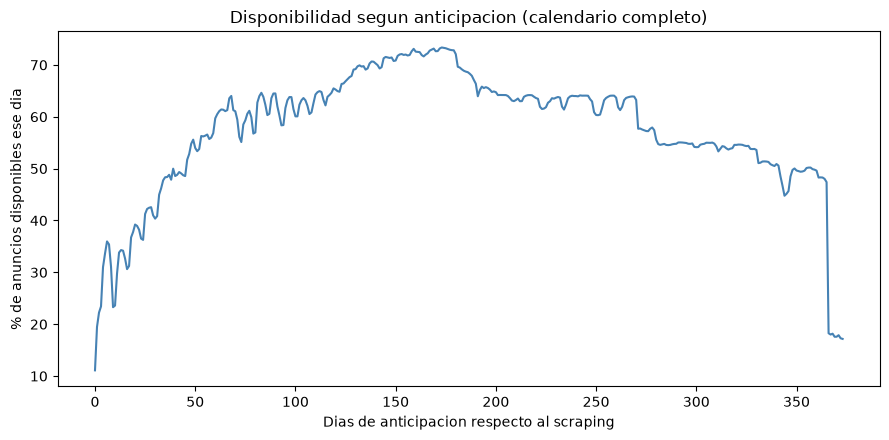

Dia 0 (hoy, el dia del scraping): 11.1 % disponible
Pico de disponibilidad: dia 173 con 73.4 %



tramo_anticipacion
0-7        28.3
8-30       35.6
31-90      56.3
91-180     68.1
181-365    58.3
366+       17.8
Name: available, dtype: float64


In [179]:
calendar["date"] = pd.to_datetime(calendar["date"])
fecha_scrape = calendar["date"].min()
calendar["dias_adelante"] = (calendar["date"] - fecha_scrape).dt.days

pct_diario = calendar.groupby("dias_adelante")["available"].apply(lambda s: (s == "t").mean() * 100)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(pct_diario.index, pct_diario.values, color="steelblue")
ax.set_xlabel("Días de anticipación respecto al scraping")
ax.set_ylabel("% de anuncios disponibles ese día")
ax.set_title("Disponibilidad según anticipacion (calendario completo)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/cruces/available_horizonte.png", dpi=100)
plt.show()

print("Día 0 (hoy, el día del scraping):", round(pct_diario.iloc[0], 1), "% disponible")
print("Pico de disponibilidad: día", pct_diario.idxmax(), "con", round(pct_diario.max(), 1), "%")
print()
bins = [-1, 7, 30, 90, 180, 365, 1000]
labels = ["0-7", "8-30", "31-90", "91-180", "181-365", "366+"]
calendar["tramo_anticipacion"] = pd.cut(calendar["dias_adelante"], bins=bins, labels=labels)
print(calendar.groupby("tramo_anticipacion", observed=True)["available"].apply(lambda s: (s == "t").mean() * 100).round(1))

Patron muy claro, en forma de "rampa y caída": el día del scraping mismo tiene solo 11,1% de disponibilidad (la gran mayoría de anuncios ya tiene reservas confirmadas para "hoy"), sube de forma bastante constante hasta un pico de 73,4% alrededor del día 173 (~5-6 meses de anticipacion), y despues cae en picado justo despues del día 365 (de ~48% a ~18%).

Interpretación en dos partes:
- **La subida (día 0 a ~180)** tiene sentido de reserva real: entre más lejos esta una fecha, menos probable es que ya este reservada, así que la disponibilidad sube con la anticipacion — igual que pasaria con cualquier calendario de reservas.
- **La caída brusca despues del día 365** no es un patrón de demanda, es casi seguro un límite técnico: muchos anuncios simplemente no tienen su calendario abierto más allá de un año hacia adelante (de ahí también el nombre de la columna `availability_eoy`, "end of year"), así que las fechas más lejanas del dataset de `calendar` (días 366-373) solo incluyen a los pocos anuncios que sí abrieron calendario más allá de un año — un grupo más chico y distinto, no una caída real de disponibilidad.

### `date`

Fecha calendario a la que corresponde cada fila (una por cada anuncio y día de un rango de aproximadamente un año hacia adelante).

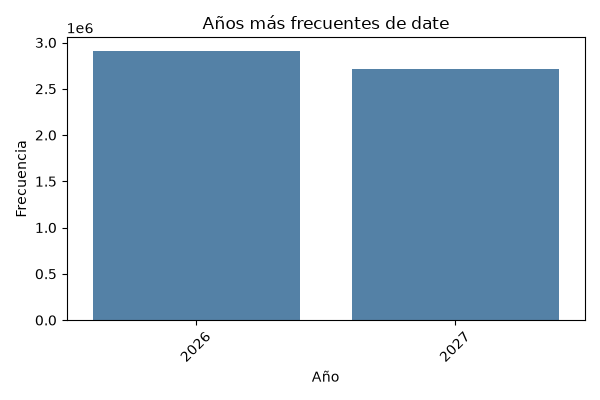

nulos=0
min=2026-06-24 00:00:00  max=2027-07-02 00:00:00  dias unicos=374


count    15406.0
mean       365.0
std          0.0
min        365.0
25%        365.0
50%        365.0
75%        365.0
max        365.0
Name: date, dtype: float64


In [180]:
fechas = pd.to_datetime(calendar["date"])
ruta = graficar_fecha(fechas, "date", CARPETA_CALENDAR)
display(Image(ruta))

print(f"nulos={fechas.isna().sum()}")
print(f"min={fechas.min()}  max={fechas.max()}  días únicos={fechas.nunique()}")
print(calendar.groupby("listing_id")["date"].nunique().describe())

Sin nulos. Va del 24 de junio de 2026 al 2 de julio de 2027 (374 días distintos en total), aunque cada anuncio individual tiene exactamente 365 filas — un año hacia adelante desde la fecha de scraping de ese anuncio, por eso el rango global es un poco más amplio que 365 días.

### `listing_id`

Identificador del anuncio al que pertenece esa fila. Es la clave para cruzar `calendar` con `listings` (`id`).

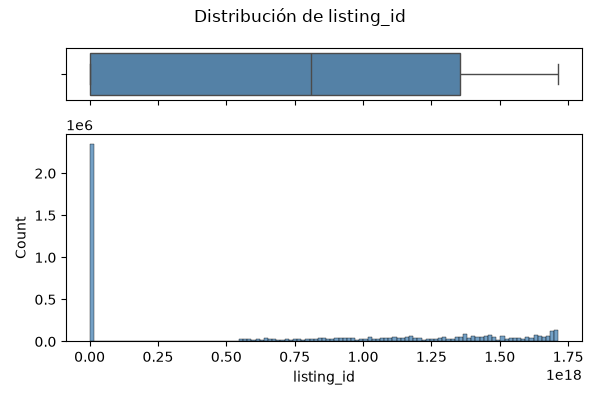

nulos=0
listing_id unicos en calendar: 15406
filas por listing_id: [365]


en calendar pero no en listings: 113
en listings pero no en calendar: 0


In [181]:
ruta = graficar_numerica(calendar["listing_id"], "listing_id", CARPETA_CALENDAR)
display(Image(ruta))

print(f"nulos={calendar['listing_id'].isna().sum()}")
print(f"listing_id únicos en calendar: {calendar['listing_id'].nunique()}")
print(f"filas por listing_id: {calendar.groupby('listing_id').size().unique()}")

cal_ids = set(calendar["listing_id"].unique())
lst_ids = set(listings["id"].unique())
print(f"en calendar pero no en listings: {len(cal_ids - lst_ids)}")
print(f"en listings pero no en calendar: {len(lst_ids - cal_ids)}")

Sin nulos. 15.406 anuncios distintos, cada uno con exactamente 365 filas (un año de calendario), lo que da las 5.623.190 filas totales.

113 de esos 15.406 `listing_id` no aparecen en `listings.csv` — son anuncios presentes solo en `calendar`, no se puede cruzar su información con el resto del dataset. En la dirección contraria no hay problema: los 15.293 anuncios de `listings` sí tienen todos su calendario completo.

### `minimum_nights` (en `calendar`)

Noches mínimas exigidas para reservar, específicas de esa fecha — no es la misma columna que `minimum_nights` de `listings`, que es un único valor por anuncio. Aquí puede variar día a día dentro del mismo anuncio.

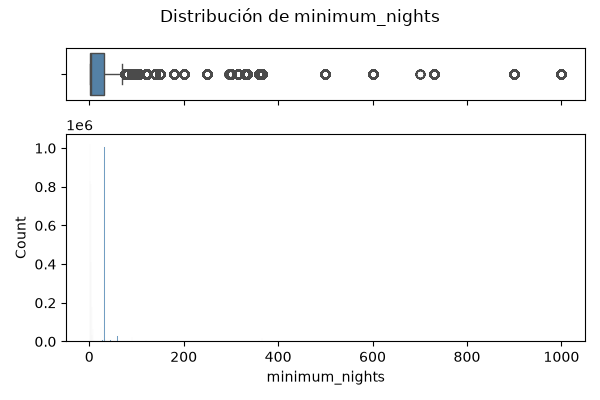

Q1=2.0  mediana=4.0  Q3=31.0  max=1000
nulos=0
minimum_nights
1     1020006
32    1003108
31     942050
2      832302
3      815407
4      412922
5      179529
25      75660
7       63177
30      58511
Name: count, dtype: int64


In [182]:
ruta = graficar_numerica(calendar["minimum_nights"], "minimum_nights", CARPETA_CALENDAR)
display(Image(ruta))

s = calendar["minimum_nights"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")
print(s.value_counts().head(10))

Sin nulos. Q1=2, mediana=4, Q3=31, máximo 1.000 (un tope redondo, probablemente un valor por defecto del sistema más que una condición real del anfitrión).

Los valores más frecuentes son 1 (1.020.006 filas), 32 (1.003.108) y 31 (942.050): hay una concentración fuerte en el entorno de "una noche" y de "un mes", coherente con el patrón de anuncios con alquiler de larga estancia visto en `minimum_nights` de `listings`.

### `maximum_nights` (en `calendar`)

Noches máximas permitidas para reservar, específicas de esa fecha — igual que `minimum_nights` de `calendar`, puede variar día a día dentro del mismo anuncio.

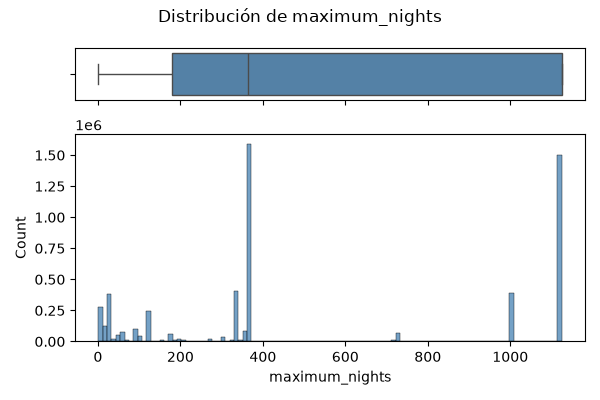

Q1=180.0  mediana=365.0  Q3=1125.0  max=1125
nulos=0
maximum_nights
365     1562582
1125    1478636
999      385452
330      296388
125      214718
7        133085
30       115156
28        98984
90        82493
360       80037
Name: count, dtype: int64


In [183]:
ruta = graficar_numerica(calendar["maximum_nights"], "maximum_nights", CARPETA_CALENDAR)
display(Image(ruta))

s = calendar["maximum_nights"]
q1, mediana, q3 = s.quantile([0.25, 0.5, 0.75])
print(f"Q1={q1}  mediana={mediana}  Q3={q3}  max={s.max()}")
print(f"nulos={s.isna().sum()}")
print(s.value_counts().head(10))

Sin nulos. Q1=180, mediana=365, Q3=1.125, y el máximo coincide con Q3 (1.125): el 25% superior de las filas está pegado al mismo valor tope.

Los valores más frecuentes son 365 (1.562.582 filas, un año) y 1.125 (1.478.636): este último es un valor que ya se vio como tope por defecto de "sin límite real" en `maximum_nights` de `listings`, no una restricción puesta deliberadamente por cada anfitrión.

## Tabla `reviews`

Una fila por cada reseña individual dejada por un huésped.

In [184]:
reviews = pd.read_csv("../data/airbnb_bcn/reviews.csv", low_memory=False)
CARPETA_REVIEWS = "../graficos_exploracion/reviews"
print(reviews.shape)
reviews.head()

(1033523, 6)


,listing_id,id,date,reviewer_id,reviewer_name,comments
0,6088098,37494155,2015-07-07,306060,Barton,Marta met me at the door and was very welcoming. The flat was very comfortable and clean. The location was great and I really enjoyed myself at this place. I can recommend it.
1,18956901,162018938,2017-06-19,72281018,Rainer,We spent our exiting trip in bcn with a chilling welcoming host javier. The Appartment was well equipped and very clean. We got good tips and the location is central placed. Everytime again when we are in bcn. Recommend
2,18956901,169085884,2017-07-11,15265416,Estrella,"Javier es un excelente anfitrión. En todo momento me encontré como en casa, incluso llegó antes para no hacerme esperar a la entrada.<br/>La casa está recién reformada con todo lo necesario para pasar la mejor estancia en Barcelona. Gracias Javier!!!!"
3,18956901,172187716,2017-07-20,98362661,Wojciech,"Javier is a great host, easy-going person, knows english very well and he is prepared for his guests!!! Clean and comfortable flat, great localisation - close to metro station. So far, my best Airbnb experience :)"
4,18956901,174791715,2017-07-27,137372016,Eugenia,"Javier è stato molto disponibile e gentile,ci ha consigliato i migliori posti da visitare a Barcellona. La sua casa non è molto grande ma è nuova,accogliente e pulita,c'è tutto quello di cui si può avere bisogno. È situata in una zona da cui si può raggiungere qualsiasi luogo con la metro e spesso anche a piedi e la stazione è molto vicina."


### `id` (en `reviews`)

Identificador único de cada reseña individual.

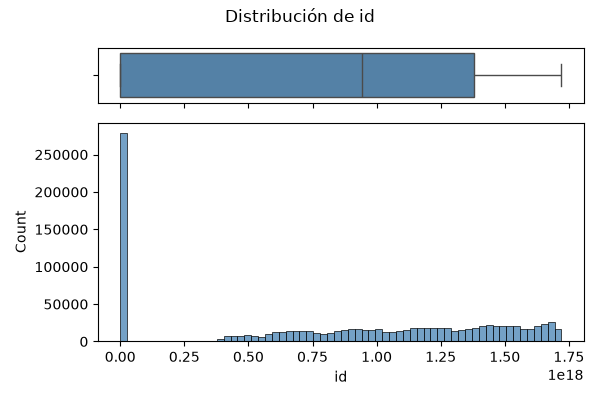

nulos=0  valores unicos=1033523 de 1033523
count    1.033523e+06
mean     8.412075e+17
std      5.991772e+17
min      1.105350e+05
25%      6.086071e+08
50%      9.426453e+17
75%      1.378251e+18
max      1.721058e+18
Name: id, dtype: float64


In [185]:
ruta = graficar_numerica(reviews["id"], "id", CARPETA_REVIEWS)
display(Image(ruta))

s = reviews["id"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()} de {len(s)}")
print(s.describe())

Sin nulos, 100% único (1.033.523 de 1.033.523): es la clave primaria de la tabla, una fila por reseña.

El rango muy amplio de valores (de 110.535 a 1,72×10¹⁸) refleja el mismo cambio de formato de identificadores de Airbnb visto en `host_id` e `id` de `listings`: reseñas antiguas con ids numéricos cortos y reseñas recientes con ids largos.

### `listing_id` (en `reviews`)

Identificador del anuncio al que pertenece esa reseña. Es la clave para cruzar `reviews` con `listings` (`id`).

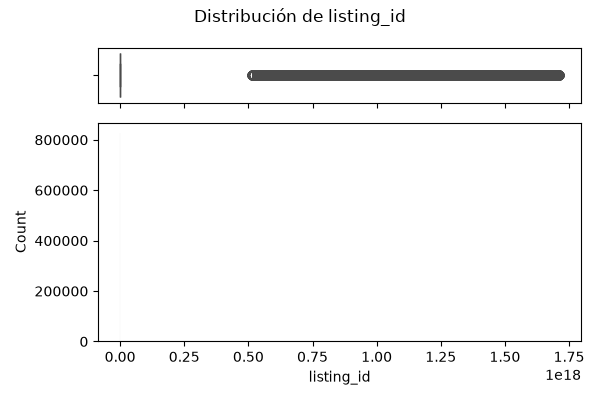

nulos=0
anuncios unicos en reviews: 11822
count    11822.000000
mean        87.423702
std        145.859383
min          1.000000
25%          4.000000
50%         25.000000
75%        111.000000
max       2740.000000
Name: count, dtype: float64
en reviews pero no en listings: 77
en listings pero no en reviews: 3548


In [186]:
ruta = graficar_numerica(reviews["listing_id"], "listing_id", CARPETA_REVIEWS)
display(Image(ruta))

s = reviews["listing_id"]
print(f"nulos={s.isna().sum()}")
print(f"anuncios únicos en reviews: {s.nunique()}")
print(s.value_counts().describe())

rev_ids = set(s.unique())
lst_ids = set(listings["id"].unique())
print(f"en reviews pero no en listings: {len(rev_ids - lst_ids)}")
print(f"en listings pero no en reviews: {len(lst_ids - rev_ids)}")

Sin nulos. 11.822 anuncios distintos tienen al menos una reseña, con una media de 87 reseñas por anuncio (mediana 25, máximo 2.740).

77 `listing_id` de `reviews` no aparecen en `listings.csv` — y son exactamente un subconjunto de los 113 ids huérfanos ya vistos en `calendar`, los mismos anuncios ausentes de `listings.csv` en ambas tablas. En la otra dirección, 3.548 anuncios de `listings` no tienen ninguna reseña, lo que coincide exactamente con el número de `number_of_reviews == 0` visto en esa columna.

### `date` (en `reviews`)

Fecha en la que se publicó la reseña.

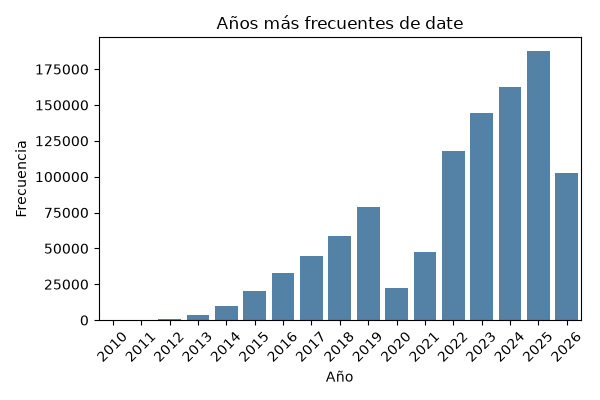

nulos=0
min=2010-10-03 00:00:00  max=2026-07-02 00:00:00
date
2010         2
2011        70
2012       557
2013      3314
2014     10063
2015     20007
2016     32863
2017     44840
2018     58364
2019     78579
2020     22389
2021     47338
2022    117857
2023    144309
2024    162519
2025    187810
2026    102642
Name: count, dtype: int64


In [187]:
fechas = pd.to_datetime(reviews["date"])
ruta = graficar_fecha(fechas, "date", CARPETA_REVIEWS)
display(Image(ruta))

print(f"nulos={fechas.isna().sum()}")
print(f"min={fechas.min()}  max={fechas.max()}")
print(fechas.dt.year.value_counts().sort_index())

Sin nulos. Va del 3 de octubre de 2010 al 2 de julio de 2026.

El número de reseñas por año crece de forma sostenida desde 2010 hasta 2019, cae bruscamente en 2020 (de 78.579 a 22.389, la pandemia), y se recupera de forma progresiva hasta superar el nivel pre-pandemia en 2022. 2026 muestra menos reseñas que 2025 porque el año está incompleto (datos solo hasta julio), no porque haya una caída real.

### `reviewer_id`

Identificador del huésped que dejó la reseña.

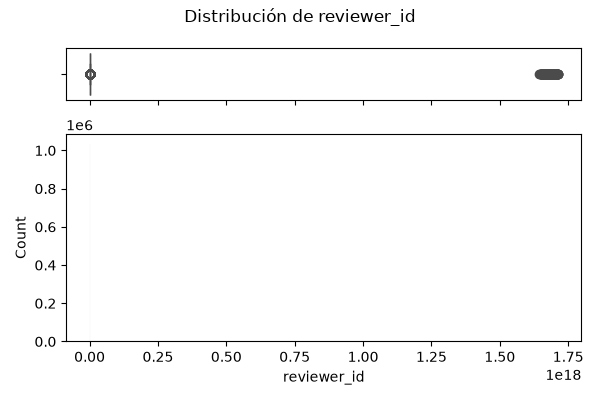

nulos=0  valores unicos=977151 de 1033523
count    977151.000000
mean          1.057690
std           0.316879
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max          32.000000
Name: count, dtype: float64


reviewer_id
655892833    32
2570702      25
41612345     23
107961904    23
205736       22
Name: count, dtype: int64


In [188]:
ruta = graficar_numerica(reviews["reviewer_id"], "reviewer_id", CARPETA_REVIEWS)
display(Image(ruta))

s = reviews["reviewer_id"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()} de {len(s)}")
print(s.value_counts().describe())
print(s.value_counts().head(5))

Sin nulos. 977.151 huéspedes distintos para 1.033.523 reseñas: la gran mayoría (mediana = 1) dejó una sola reseña en todo el dataset. El máximo es 32 reseñas de un mismo `reviewer_id`, un huésped que se ha alojado muchas veces en Barcelona a lo largo de los años cubiertos.

### `reviewer_name`

Nombre de pila del huésped que dejó la reseña (solo nombre, sin apellido).

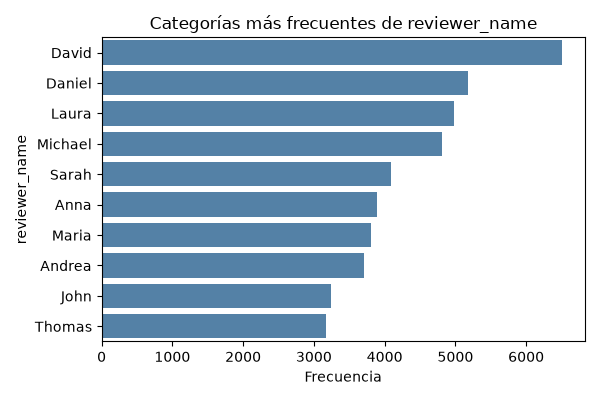

nulos=2  valores unicos=126356
reviewer_name
David      6506
Daniel     5172
Laura      4978
Michael    4810
Sarah      4088
Name: count, dtype: int64


In [189]:
ruta = graficar_categorica(reviews["reviewer_name"], "reviewer_name", CARPETA_REVIEWS)
display(Image(ruta))

s = reviews["reviewer_name"]
print(f"nulos={s.isna().sum()}  valores únicos={s.nunique()}")
print(s.value_counts().head(5))

2 nulos, 126.356 nombres distintos para 977.151 `reviewer_id` únicos: al ser solo el nombre de pila, muchas personas distintas comparten el mismo valor (David, Daniel, Laura son los más frecuentes). No sirve para identificar a un huésped individual, para eso está `reviewer_id`.

### `comments`

Texto completo de la reseña escrita por el huésped.

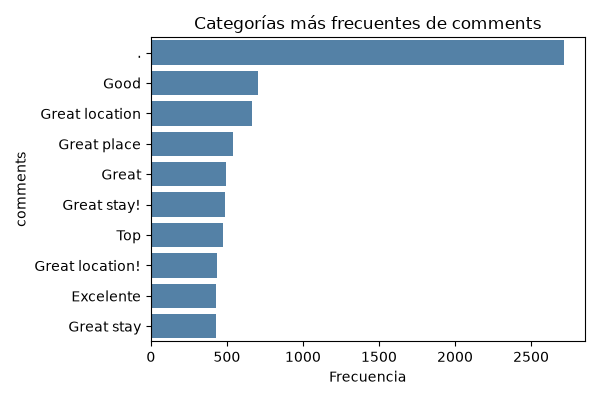

nulos=114 (0.01%)  valores unicos=985107


count    1.033409e+06
mean     2.432498e+02
std      2.424422e+02
min      1.000000e+00
25%      7.800000e+01
50%      1.720000e+02
75%      3.270000e+02
max      5.828000e+03
Name: comments, dtype: float64


In [190]:
ruta = graficar_categorica(reviews["comments"], "comments", CARPETA_REVIEWS)
display(Image(ruta))

s = reviews["comments"]
print(f"nulos={s.isna().sum()} ({s.isna().mean()*100:.2f}%)  valores únicos={s.nunique()}")

longitudes = s.dropna().str.len()
print(longitudes.describe())

El gráfico no es útil: cada comentario es un bloque de texto casi único, no hay categorías que comparar.

0,01% nulos (114). 985.107 de 1.033.409 comentarios no nulos son únicos (95,3%) — pocos duplicados exactos. La longitud media es 243 caracteres, mediana 172, con comentarios de hasta 5.828 caracteres. Los comentarios están en varios idiomas (inglés, español, catalán, alemán y otros), según lo visto en los ejemplos revisados.

### Cruce: longitud de `comments` según el año de la reseña (`date`)

`comments` esta en varios idiomas, así que un análisis de palabras mezclaria idiomas sin mucho sentido. Pero la **longitud** del texto no depende del idioma y es fácil de medir con rigor. ¿Los huéspedes escriben reseñas más largas o más cortas con el paso de los años?

,median,mean,count
anio,,,
2010,201.0,201.0,2
2011,340.5,391.9,70
2012,402.0,487.6,557
2013,374.0,456.7,3314
2014,356.0,439.8,10063
2015,334.0,410.5,20007
2016,289.0,359.1,32863
2017,221.0,292.5,44838
2018,198.0,269.1,58362


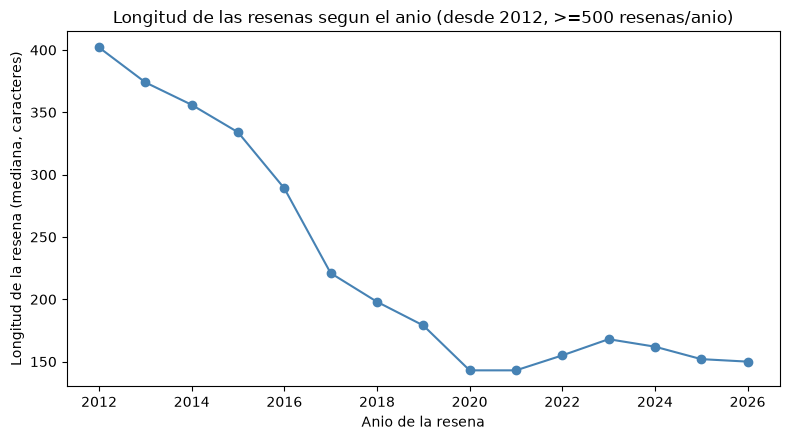

In [191]:
reviews["longitud"] = reviews["comments"].str.len()
reviews["año"] = pd.to_datetime(reviews["date"]).dt.year

tabla = reviews.groupby("año")["longitud"].agg(["median", "mean", "count"]).round(1)
display(tabla)

fig, ax = plt.subplots(figsize=(8, 4.5))
anios_con_volumen = tabla[tabla["count"] >= 500]
ax.plot(anios_con_volumen.index, anios_con_volumen["median"], marker="o", color="steelblue")
ax.set_xlabel("Año de la reseña")
ax.set_ylabel("Longitud de la reseña (mediana, caracteres)")
ax.set_title("Longitud de las reseñas según el año (desde 2012, >=500 reseñas/año)")
fig.tight_layout()
fig.savefig("../graficos_exploracion/reviews/comments_longitud_anio.png", dpi=100)
plt.show()

Tendencia clara y sostenida a la baja: la mediana cae de 402 caracteres en 2012 a 179 en 2019 (ya antes de la pandemia), toca un mínimo de 143 en 2020-2021, y se estabiliza alrededor de 150-170 desde 2022 — sin volver a los niveles de antes de 2017. En total, una caída de más de 2,5 veces entre el pico (2012) y el nivel actual.

No es un efecto puntual de la pandemia (aunque 2020-2021 son los años más bajos): la caída ya era fuerte y constante desde 2012, año tras año, bastante antes del 2020. Es más coherente con un cambio de habito general de los huéspedes de Airbnb a medida que la plataforma maduró y se volvió más masiva — las reseñas de los primeros usuarios (más entusiastas, escribiendo párrafos detallados) dieron paso a reseñas más rapidas y cortas, un patrón típico de plataformas que pasan de early adopters a uso masivo.

### Cruce: `reviewer_id` repetido según `listing_id` (¿vuelven al mismo anuncio o prueban otros?)

Ya se sabe que el máximo de reseñas de un mismo `reviewer_id` es 32. La pregunta nueva: cuando un huésped deja más de una reseña en el dataset, ¿es porque volvió al **mismo** alojamiento varias veces (fidelidad a un anuncio/anfitrión), o porque usó Airbnb en Barcelona en estancias distintas, en anuncios distintos?

% de reviewer_id con mas de 1 resena en todo el dataset: 4.59 %


De los repetidores, listings distintos visitados:


count    44889.000000
mean         2.152510
std          0.764568
min          1.000000
25%          2.000000
50%          2.000000
75%          2.000000
max         27.000000
Name: listing_id, dtype: float64

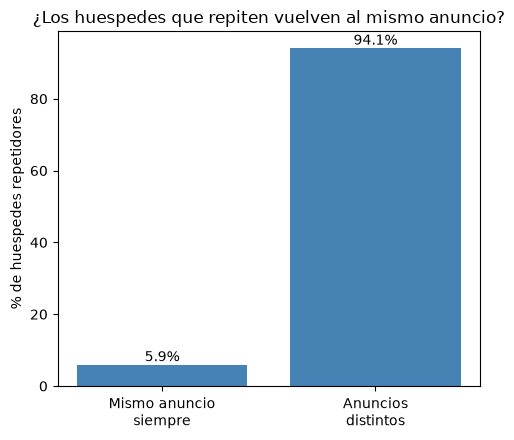

In [192]:
conteo = reviews.groupby("reviewer_id").size()
print("% de reviewer_id con más de 1 reseña en todo el dataset:", round((conteo > 1).mean() * 100, 2), "%")

repetidores = conteo[conteo > 1].index
sub = reviews[reviews["reviewer_id"].isin(repetidores)]
distintos_listings = sub.groupby("reviewer_id")["listing_id"].nunique()

print("De los repetidores, listings distintos visitados:")
display(distintos_listings.describe())

pct_fiel = (distintos_listings == 1).mean() * 100
pct_explorador = (distintos_listings > 1).mean() * 100

fig, ax = plt.subplots(figsize=(5, 4.5))
ax.bar(["Mismo anuncio\nsiempre", "Anuncios\ndistintos"], [pct_fiel, pct_explorador], color="steelblue")
for i, v in enumerate([pct_fiel, pct_explorador]):
    ax.text(i, v + 1, f"{v:.1f}%", ha="center")
ax.set_ylabel("% de huéspedes repetidores")
ax.set_title("¿Los huéspedes que repiten vuelven al mismo anuncio?")
fig.tight_layout()
fig.savefig("../graficos_exploracion/reviews/reviewerid_fidelidad.png", dpi=100)
plt.show()

Solo el 4,59% de los huéspedes (44.889 de 977.151) dejó más de una reseña en todo el dataset — la inmensa mayoría usó Airbnb en Barcelona una sola vez. Y de ese grupo minoritario de "repetidores", solo el 5,9% volvió siempre al **mismo** anuncio; el 94,1% restante visitó alojamientos distintos entre una reseña y otra (mediana de 2 anuncios distintos, hasta 27 en el caso más extremo).

Conclusión: la fidelidad a un anuncio o anfitrión específico es rarísima (prácticamente anecdótica) en estos datos. Cuando un huésped repite en Airbnb-Barcelona, lo normal es que explore alojamientos distintos en estancias distintas, no que regrese al mismo piso — consistente con el perfil de turista que visita la ciudad varias veces a lo largo de los años, no con un patrón de cliente leal a un anfitrión.